In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
TRAIN_PATH = "data/train.csv"
TEST_PATH = "data/test.csv"
SAMPLE_PATH = "data/sample_submission.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Train shape: (800, 12)
Test shape: (400, 11)
Sample submission shape: (400, 2)


In [3]:
pd.set_option("display.max_columns", None)

train.head()

,wedding_id,event,city,guests,aloo_count,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage,went_back_for_seconds
0,W0001,Gaye Holud,Barishal,604,1327.0,138.1,529,478,no,6,8,0
1,W0002,Bou-bhat,Dhaka,166,104.0,35.0,172,445,yes,3,3,0
2,W0003,Biye,Mymensingh,67,59.0,16.7,72,116,yes,2,3,0
3,W0004,Biye,Dhaka,466,1206.0,122.3,668,1586,no,1,4,0
4,W0005,Biye,Khulna,287,209.0,81.9,278,646,yes,0,9,0


In [4]:
test.head()

,wedding_id,event,city,guests,aloo_count,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage
0,W0801,Biye,Chattogram,1235,3010,228.3,1766,980,yes,3,3
1,W0802,Biye,Dhaka,426,868,125.2,525,852,no,3,9
2,W0803,Bou-bhat,Dhaka,656,1319,140.2,855,922,no,1,5
3,W0804,Biye,Dhaka,852,1009,247.6,705,1232,yes,7,5
4,W0805,Gaye Holud,Khulna,532,1315,156.6,520,1415,no,0,9


In [5]:
sample_submission.head()

,wedding_id,went_back_for_seconds
0,W0801,0
1,W0802,0
2,W0803,0
3,W0804,0
4,W0805,0


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   wedding_id                    800 non-null    object 
 1   event                         800 non-null    object 
 2   city                          800 non-null    object 
 3   guests                        800 non-null    int64  
 4   aloo_count                    776 non-null    float64
 5   mutton_kg                     800 non-null    float64
 6   borhani_glasses               800 non-null    int64  
 7   fairy_lights                  800 non-null    object 
 8   drone_photographer            800 non-null    object 
 9   dhol_players                  800 non-null    int64  
 10  aunties_asking_when_marriage  800 non-null    int64  
 11  went_back_for_seconds         800 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 75.1+ KB


In [8]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   wedding_id                    400 non-null    object 
 1   event                         400 non-null    object 
 2   city                          400 non-null    object 
 3   guests                        400 non-null    int64  
 4   aloo_count                    400 non-null    int64  
 5   mutton_kg                     400 non-null    float64
 6   borhani_glasses               400 non-null    int64  
 7   fairy_lights                  400 non-null    int64  
 8   drone_photographer            400 non-null    object 
 9   dhol_players                  400 non-null    int64  
 10  aunties_asking_when_marriage  400 non-null    int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 34.5+ KB


In [9]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
wedding_id,800,800,W0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event,800,3,Biye,378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,800,8,Dhaka,262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guests,800.0,NaN,NaN,NaN,371.62375,184.408379,51.0,219.5,367.0,531.0,700.0
aloo_count,776.0,NaN,NaN,NaN,626.070876,781.629417,28.0,262.75,471.5,850.0,11520.0
mutton_kg,800.0,NaN,NaN,NaN,94.35,49.023904,9.3,54.4,92.9,128.425,221.3
borhani_glasses,800.0,NaN,NaN,NaN,428.31875,230.407713,45.0,241.0,411.0,597.0,1016.0
fairy_lights,800,662,1021,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drone_photographer,800,2,no,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dhol_players,800.0,NaN,NaN,NaN,4.005,2.575513,0.0,2.0,4.0,6.0,8.0


In [10]:
print("TRAIN MISSING VALUES")
print(train.isna().sum())

print("\nTEST MISSING VALUES")
print(test.isna().sum())

TRAIN MISSING VALUES
wedding_id                       0
event                            0
city                             0
guests                           0
aloo_count                      24
mutton_kg                        0
borhani_glasses                  0
fairy_lights                     0
drone_photographer               0
dhol_players                     0
aunties_asking_when_marriage     0
went_back_for_seconds            0
dtype: int64

TEST MISSING VALUES
wedding_id                      0
event                           0
city                            0
guests                          0
aloo_count                      0
mutton_kg                       0
borhani_glasses                 0
fairy_lights                    0
drone_photographer              0
dhol_players                    0
aunties_asking_when_marriage    0
dtype: int64


In [11]:
target = "went_back_for_seconds"

print(train[target].value_counts())
print()
print(train[target].value_counts(normalize=True))

went_back_for_seconds
0    464
1    336
Name: count, dtype: int64

went_back_for_seconds
0    0.58
1    0.42
Name: proportion, dtype: float64


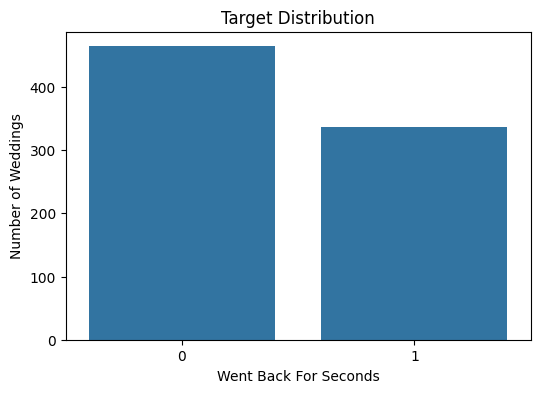

In [12]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=train,
    x=target
)

plt.title("Target Distribution")
plt.xlabel("Went Back For Seconds")
plt.ylabel("Number of Weddings")

plt.show()

In [13]:
categorical_columns = [
    "event",
    "city",
    "drone_photographer"
]

for col in categorical_columns:
    print("=" * 60)
    print(col)
    print(train[col].value_counts())

event
event
Biye          378
Gaye Holud    238
Bou-bhat      184
Name: count, dtype: int64
city
city
Dhaka         262
Chattogram    118
Rajshahi      100
Khulna         87
Sylhet         69
Barishal       66
Rangpur        60
Mymensingh     38
Name: count, dtype: int64
drone_photographer
drone_photographer
no     481
yes    319
Name: count, dtype: int64


In [14]:
numeric_columns = [
    "guests",
    "aloo_count",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

train[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
guests,800.0,371.623750,184.408379,51.0,219.50,367.0,531.000,700.0
aloo_count,776.0,626.070876,781.629417,28.0,262.75,471.5,850.000,11520.0
mutton_kg,800.0,94.350000,49.023904,9.3,54.40,92.9,128.425,221.3
borhani_glasses,800.0,428.318750,230.407713,45.0,241.00,411.0,597.000,1016.0
dhol_players,800.0,4.005000,2.575513,0.0,2.00,4.0,6.000,8.0
aunties_asking_when_marriage,800.0,5.996250,2.491786,1.0,4.00,6.0,8.000,16.0


In [15]:
print(train["fairy_lights"].head(20).tolist())
print(test["fairy_lights"].head(20).tolist())

['478', '445', '116', '1586', '646', '780', '৩৯৯', '618', '1020', '527', '979', '1383', '1448', '2152', '1398', '685', '1951', '578', '196', '889']
[980, 852, 922, 1232, 1415, 966, 1641, 2479, 2456, 413, 3009, 306, 4223, 1246, 1239, 1448, 4017, 712, 1368, 4583]


In [16]:
bangla_to_english = str.maketrans(
    "০১২৩৪৫৬৭৮৯",
    "0123456789"
)

for df in [train, test]:
    df["fairy_lights"] = (
        df["fairy_lights"]
        .astype(str)
        .str.translate(bangla_to_english)
        .astype(int)
    )

print("Bangla digit conversion completed.")

Bangla digit conversion completed.


In [17]:
print("Train missing aloo:", train["aloo_count"].isna().sum())
print("Test missing aloo:", test["aloo_count"].isna().sum())

Train missing aloo: 24
Test missing aloo: 0


In [18]:
train[train["aloo_count"].isna()]

,wedding_id,event,city,guests,aloo_count,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage,went_back_for_seconds
9,W0010,Gaye Holud,Dhaka,281,NaN,54.4,328,527,yes,6,4,0
21,W0022,Biye,Sylhet,679,NaN,149.7,887,570,no,4,7,0
40,W0041,Biye,Sylhet,605,NaN,111.0,513,2015,no,2,10,1
51,W0052,Gaye Holud,Dhaka,287,NaN,56.2,305,843,no,3,6,0
176,W0177,Gaye Holud,Dhaka,353,NaN,84.0,523,1247,yes,3,7,1
233,W0234,Gaye Holud,Rajshahi,104,NaN,23.8,125,180,no,1,8,0
255,W0256,Bou-bhat,Barishal,583,NaN,161.2,611,1444,yes,5,7,1
258,W0259,Biye,Khulna,268,NaN,60.3,399,1178,yes,6,8,1
293,W0294,Gaye Holud,Rangpur,123,NaN,34.4,170,487,no,4,9,1
295,W0296,Biye,Barishal,289,NaN,83.6,347,1097,no,8,6,0


In [19]:
train.loc[
    train["aloo_count"].isna(),
    ["wedding_id", "guests", "mutton_kg", target]
]

,wedding_id,guests,mutton_kg,went_back_for_seconds
9,W0010,281,54.4,0
21,W0022,679,149.7,0
40,W0041,605,111.0,1
51,W0052,287,56.2,0
176,W0177,353,84.0,1
233,W0234,104,23.8,0
255,W0256,583,161.2,1
258,W0259,268,60.3,1
293,W0294,123,34.4,1
295,W0296,289,83.6,0


In [20]:
train[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "mutton_kg",
        target
    ]
].sort_values(
    "aloo_count",
    ascending=False
).head(30)

,wedding_id,guests,aloo_count,mutton_kg,went_back_for_seconds
501,W0502,695,11520.0,126.7,1
785,W0786,439,10270.0,106.0,0
671,W0672,311,8320.0,59.0,0
80,W0081,315,7150.0,96.0,0
447,W0448,396,6520.0,116.3,1
674,W0675,686,1831.0,191.9,0
556,W0557,659,1764.0,185.9,0
744,W0745,665,1739.0,128.5,0
677,W0678,675,1732.0,158.5,0
545,W0546,700,1712.0,130.4,0


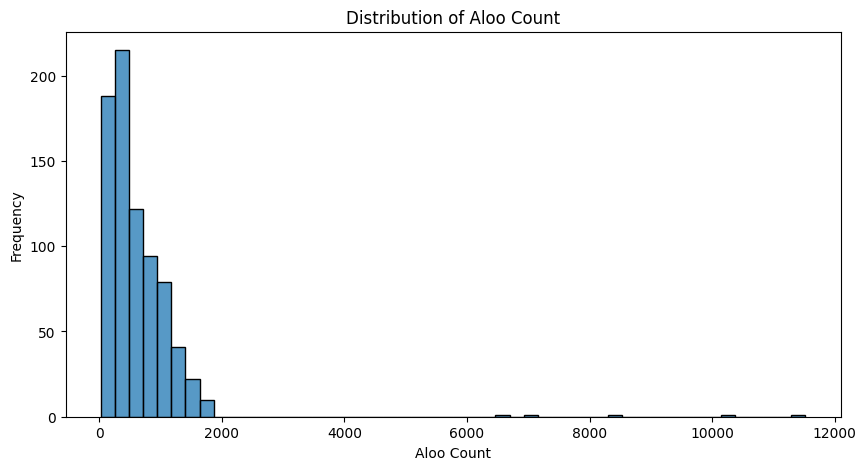

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="aloo_count",
    bins=50
)

plt.title("Distribution of Aloo Count")
plt.xlabel("Aloo Count")
plt.ylabel("Frequency")

plt.show()

In [22]:
train["aloo_per_guest"] = (
    train["aloo_count"] / train["guests"]
)

test["aloo_per_guest"] = (
    test["aloo_count"] / test["guests"]
)

In [23]:
train[
    [
        "guests",
        "aloo_count",
        "aloo_per_guest",
        target
    ]
].head(20)

,guests,aloo_count,aloo_per_guest,went_back_for_seconds
0,604,1327.0,2.197020,0
1,166,104.0,0.626506,0
2,67,59.0,0.880597,0
3,466,1206.0,2.587983,0
4,287,209.0,0.728223,0
5,354,738.0,2.084746,0
6,101,136.0,1.346535,1
7,291,703.0,2.415808,0
8,468,261.0,0.557692,0
9,281,NaN,NaN,0


In [24]:
train.groupby(target)["aloo_per_guest"].describe()

,count,mean,std,min,25%,50%,75%,max
went_back_for_seconds,,,,,,,,
0,448.0,1.741274,2.076591,0.406015,0.729030,2.018412,2.361526,26.752412
1,328.0,1.576235,1.212135,0.940426,1.217525,1.460769,1.753228,16.575540


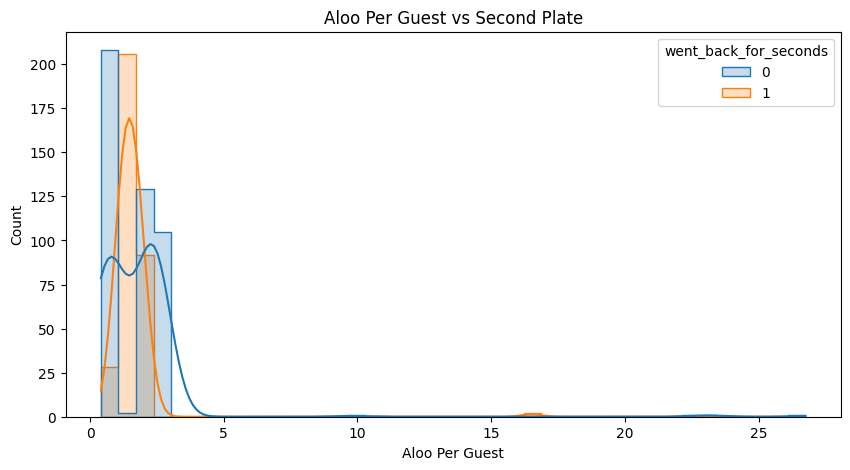

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="aloo_per_guest",
    hue=target,
    bins=40,
    kde=True,
    element="step"
)

plt.title("Aloo Per Guest vs Second Plate")
plt.xlabel("Aloo Per Guest")
plt.ylabel("Count")

plt.show()

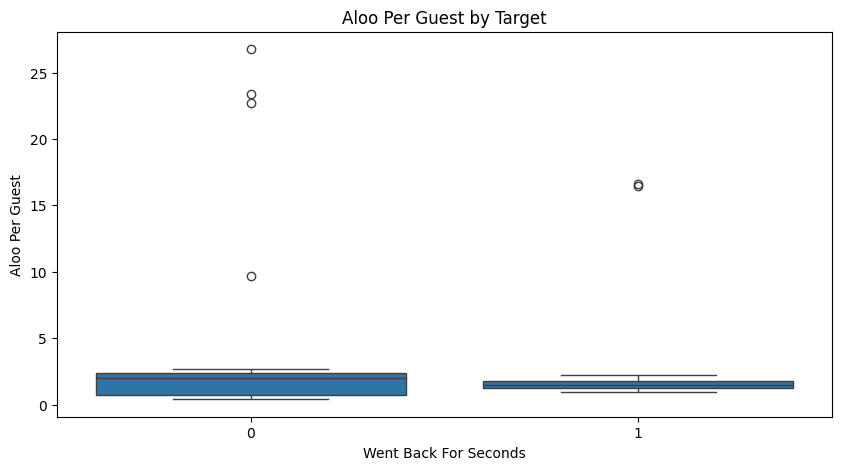

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train,
    x=target,
    y="aloo_per_guest"
)

plt.title("Aloo Per Guest by Target")
plt.xlabel("Went Back For Seconds")
plt.ylabel("Aloo Per Guest")

plt.show()

In [27]:
train["aloo_count"].describe()

count      776.000000
mean       626.070876
std        781.629417
min         28.000000
25%        262.750000
50%        471.500000
75%        850.000000
max      11520.000000
Name: aloo_count, dtype: float64

In [28]:
train.loc[
    train["aloo_count"].isna(),
    ["wedding_id", "guests", "mutton_kg", target]
]


,wedding_id,guests,mutton_kg,went_back_for_seconds
9,W0010,281,54.4,0
21,W0022,679,149.7,0
40,W0041,605,111.0,1
51,W0052,287,56.2,0
176,W0177,353,84.0,1
233,W0234,104,23.8,0
255,W0256,583,161.2,1
258,W0259,268,60.3,1
293,W0294,123,34.4,1
295,W0296,289,83.6,0


In [29]:
train[
    ["wedding_id", "guests", "aloo_count", "mutton_kg", target]
].sort_values(
    "aloo_count",
    ascending=False
).head(30)

,wedding_id,guests,aloo_count,mutton_kg,went_back_for_seconds
501,W0502,695,11520.0,126.7,1
785,W0786,439,10270.0,106.0,0
671,W0672,311,8320.0,59.0,0
80,W0081,315,7150.0,96.0,0
447,W0448,396,6520.0,116.3,1
674,W0675,686,1831.0,191.9,0
556,W0557,659,1764.0,185.9,0
744,W0745,665,1739.0,128.5,0
677,W0678,675,1732.0,158.5,0
545,W0546,700,1712.0,130.4,0


In [30]:
train.groupby(target)["aloo_per_guest"].describe()

,count,mean,std,min,25%,50%,75%,max
went_back_for_seconds,,,,,,,,
0,448.0,1.741274,2.076591,0.406015,0.729030,2.018412,2.361526,26.752412
1,328.0,1.576235,1.212135,0.940426,1.217525,1.460769,1.753228,16.575540


In [31]:
train["aloo_per_guest"].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.20,
        0.25,
        0.50,
        0.75,
        0.80,
        0.90,
        0.95,
        0.99
    ]
)

count    776.000000
mean       1.671515
std        1.764589
min        0.406015
1%         0.420746
5%         0.506106
10%        0.627647
20%        0.827465
25%        0.957247
50%        1.507989
75%        2.132390
80%        2.242175
90%        2.505978
95%        2.613339
99%        2.698749
max       26.752412
Name: aloo_per_guest, dtype: float64

In [32]:
train[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest",
        "went_back_for_seconds"
    ]
].sort_values(
    "aloo_per_guest"
).head(40)

,wedding_id,guests,aloo_count,aloo_per_guest,went_back_for_seconds
311,W0312,133,54.0,0.406015,0
699,W0700,559,228.0,0.407871,0
167,W0168,110,45.0,0.409091,0
502,W0503,68,28.0,0.411765,0
184,W0185,216,90.0,0.416667,0
281,W0282,443,185.0,0.417607,0
718,W0719,253,106.0,0.418972,0
471,W0472,290,122.0,0.420690,0
747,W0748,366,154.0,0.420765,0
70,W0071,351,149.0,0.424501,0


In [33]:
train[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest",
        "went_back_for_seconds"
    ]
].sort_values(
    "aloo_per_guest",
    ascending=False
).head(40)

,wedding_id,guests,aloo_count,aloo_per_guest,went_back_for_seconds
671,W0672,311,8320.0,26.752412,0
785,W0786,439,10270.0,23.394077,0
80,W0081,315,7150.0,22.698413,0
501,W0502,695,11520.0,16.575540,1
447,W0448,396,6520.0,16.464646,1
316,W0317,133,1290.0,9.699248,0
115,W0116,320,864.0,2.700000,0
519,W0520,413,1115.0,2.699758,0
28,W0029,126,340.0,2.698413,0
217,W0218,459,1238.0,2.697168,0


In [34]:
bins = [
    0,
    0.5,
    0.75,
    0.9,
    1.0,
    1.1,
    1.2,
    1.3,
    1.4,
    1.5,
    1.6,
    1.7,
    1.8,
    2.0,
    2.25,
    2.5,
    3.0,
    4.0,
    10.0,
    np.inf
]

train["aloo_ratio_bin"] = pd.cut(
    train["aloo_per_guest"],
    bins=bins,
    include_lowest=True
)

ratio_analysis = (
    train.groupby("aloo_ratio_bin", observed=False)
    .agg(
        weddings=("went_back_for_seconds", "size"),
        seconds=("went_back_for_seconds", "sum"),
        second_rate=("went_back_for_seconds", "mean")
    )
)

ratio_analysis

,weddings,seconds,second_rate
aloo_ratio_bin,,,
"(-0.001, 0.5]",37,0,0.000000
"(0.5, 0.75]",85,0,0.000000
"(0.75, 0.9]",55,0,0.000000
"(0.9, 1.0]",37,12,0.324324
"(1.0, 1.1]",31,25,0.806452
"(1.1, 1.2]",37,36,0.972973
"(1.2, 1.3]",34,34,1.000000
"(1.3, 1.4]",38,38,1.000000
"(1.4, 1.5]",31,31,1.000000


In [35]:
analysis_train = train[
    train["aloo_per_guest"] < 4
].copy()

analysis_train.groupby(
    "went_back_for_seconds"
)["aloo_per_guest"].describe()

,count,mean,std,min,25%,50%,75%,max
went_back_for_seconds,,,,,,,,
0,444.0,1.571051,0.846943,0.406015,0.727445,2.013258,2.358071,2.700000
1,326.0,1.484554,0.309181,0.940426,1.215365,1.458797,1.751232,2.253333


In [36]:
analysis_train["aloo_ratio_bin"] = pd.cut(
    analysis_train["aloo_per_guest"],
    bins=bins,
    include_lowest=True
)

analysis_train.groupby(
    "aloo_ratio_bin",
    observed=False
).agg(
    weddings=("went_back_for_seconds", "size"),
    seconds=("went_back_for_seconds", "sum"),
    second_rate=("went_back_for_seconds", "mean")
)

,weddings,seconds,second_rate
aloo_ratio_bin,,,
"(-0.001, 0.5]",37,0,0.000000
"(0.5, 0.75]",85,0,0.000000
"(0.75, 0.9]",55,0,0.000000
"(0.9, 1.0]",37,12,0.324324
"(1.0, 1.1]",31,25,0.806452
"(1.1, 1.2]",37,36,0.972973
"(1.2, 1.3]",34,34,1.000000
"(1.3, 1.4]",38,38,1.000000
"(1.4, 1.5]",31,31,1.000000


In [37]:
pd.crosstab(
    pd.cut(
        analysis_train["aloo_per_guest"],
        bins=np.arange(0.4, 2.61, 0.1),
        include_lowest=True
    ),
    analysis_train["went_back_for_seconds"],
    normalize="index"
).round(3)

went_back_for_seconds,0,1
aloo_per_guest,,
"(0.399, 0.5]",1.000,0.000
"(0.5, 0.6]",1.000,0.000
"(0.6, 0.7]",1.000,0.000
"(0.7, 0.8]",1.000,0.000
"(0.8, 0.9]",1.000,0.000
"(0.9, 1.0]",0.667,0.333
"(1.0, 1.1]",0.219,0.781
"(1.1, 1.2]",0.027,0.973
"(1.2, 1.3]",0.000,1.000


In [38]:
extra_zero_candidates = train[
    train["aloo_per_guest"] > 3
].copy()

extra_zero_candidates[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest",
        "mutton_kg",
        "went_back_for_seconds"
    ]
].sort_values("aloo_per_guest")

,wedding_id,guests,aloo_count,aloo_per_guest,mutton_kg,went_back_for_seconds
316,W0317,133,1290.0,9.699248,31.8,0
447,W0448,396,6520.0,16.464646,116.3,1
501,W0502,695,11520.0,16.575540,126.7,1
80,W0081,315,7150.0,22.698413,96.0,0
785,W0786,439,10270.0,23.394077,106.0,0
671,W0672,311,8320.0,26.752412,59.0,0


In [39]:
extra_zero_candidates["corrected_aloo_count"] = (
    extra_zero_candidates["aloo_count"] / 10
)

extra_zero_candidates["corrected_aloo_per_guest"] = (
    extra_zero_candidates["corrected_aloo_count"]
    / extra_zero_candidates["guests"]
)

extra_zero_candidates[
    [
        "wedding_id",
        "aloo_count",
        "aloo_per_guest",
        "corrected_aloo_count",
        "corrected_aloo_per_guest",
        "went_back_for_seconds"
    ]
]

,wedding_id,aloo_count,aloo_per_guest,corrected_aloo_count,corrected_aloo_per_guest,went_back_for_seconds
80,W0081,7150.0,22.698413,715.0,2.269841,0
316,W0317,1290.0,9.699248,129.0,0.969925,0
447,W0448,6520.0,16.464646,652.0,1.646465,1
501,W0502,11520.0,16.575540,1152.0,1.657554,1
671,W0672,8320.0,26.752412,832.0,2.675241,0
785,W0786,10270.0,23.394077,1027.0,2.339408,0


In [40]:
train_clean = train.copy()

train_clean["aloo_count_corrected"] = train_clean["aloo_count"]

extra_zero_mask = (
    train_clean["aloo_count_corrected"] / train_clean["guests"] > 3
)

train_clean.loc[
    extra_zero_mask,
    "aloo_count_corrected"
] = (
    train_clean.loc[
        extra_zero_mask,
        "aloo_count_corrected"
    ] / 10
)

train_clean["aloo_per_guest_corrected"] = (
    train_clean["aloo_count_corrected"]
    / train_clean["guests"]
)

print(
    "Extra-zero candidates:",
    extra_zero_mask.sum()
)

Extra-zero candidates: 6


In [41]:
train_clean.groupby(target)[
    "aloo_per_guest_corrected"
].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
went_back_for_seconds,,,,,,,,,,,,,,
0,448.0,1.575448,0.846654,0.406015,0.417109,0.455174,0.529425,0.729030,2.015698,2.358071,2.578414,2.660877,2.696300,2.700000
1,328.0,1.485576,0.308510,0.940426,0.971783,1.018193,1.083882,1.217525,1.460769,1.751224,1.892600,1.985277,2.065491,2.253333


In [43]:
corrected_bins = [
    0,
    0.8,
    0.9,
    1.0,
    1.1,
    1.2,
    1.3,
    1.4,
    1.5,
    1.6,
    1.7,
    1.8,
    1.9,
    2.0,
    2.1,
    2.2,
    2.3,
    2.4,
    2.5,
    2.6,
    2.7,
    3.0
]

train_clean["corrected_ratio_bin"] = pd.cut(
    train_clean["aloo_per_guest_corrected"],
    bins=corrected_bins,
    include_lowest=True
)

corrected_analysis = (
    train_clean
    .groupby("corrected_ratio_bin", observed=False)
    .agg(
        weddings=(target, "size"),
        seconds=(target, "sum"),
        second_rate=(target, "mean")
    )
)

corrected_analysis

,weddings,seconds,second_rate
corrected_ratio_bin,,,
"(-0.001, 0.8]",138,0,0.000000
"(0.8, 0.9]",39,0,0.000000
"(0.9, 1.0]",38,12,0.315789
"(1.0, 1.1]",31,25,0.806452
"(1.1, 1.2]",37,36,0.972973
"(1.2, 1.3]",34,34,1.000000
"(1.3, 1.4]",38,38,1.000000
"(1.4, 1.5]",31,31,1.000000
"(1.5, 1.6]",25,25,1.000000


In [44]:
from sklearn.metrics import accuracy_score

ratio = train_clean["aloo_per_guest_corrected"].values
y_true = train_clean[target].values

best_result = None

lower_values = np.arange(0.85, 1.11, 0.005)
upper_values = np.arange(1.90, 2.31, 0.005)

for lower in lower_values:
    for upper in upper_values:
        pred = (
            (ratio >= lower) &
            (ratio <= upper)
        ).astype(int)

        acc = accuracy_score(y_true, pred)

        if best_result is None or acc > best_result["accuracy"]:
            best_result = {
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            }

best_result

{'lower': np.float64(0.9700000000000001),
 'upper': np.float64(2.0099999999999976),
 'accuracy': 0.94875}

In [45]:
best_lower = best_result["lower"]
best_upper = best_result["upper"]

train_clean["rule_prediction"] = (
    (
        train_clean["aloo_per_guest_corrected"] >= best_lower
    )
    &
    (
        train_clean["aloo_per_guest_corrected"] <= best_upper
    )
).astype(int)

print(
    "Rule accuracy:",
    accuracy_score(
        train_clean[target],
        train_clean["rule_prediction"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        train_clean[target],
        train_clean["rule_prediction"]
    )
)

Rule accuracy: 0.94875

Confusion Matrix:
[[442  22]
 [ 19 317]]


In [46]:
mistakes = train_clean[
    train_clean[target] != train_clean["rule_prediction"]
].copy()

print("Total mistakes:", len(mistakes))

mistakes[
    [
        "wedding_id",
        "event",
        "city",
        "guests",
        "aloo_count_corrected",
        "aloo_per_guest_corrected",
        "mutton_kg",
        "borhani_glasses",
        "fairy_lights",
        "drone_photographer",
        "dhol_players",
        "aunties_asking_when_marriage",
        target,
        "rule_prediction"
    ]
].sort_values(
    "aloo_per_guest_corrected"
)

Total mistakes: 41


,wedding_id,event,city,guests,aloo_count_corrected,aloo_per_guest_corrected,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage,went_back_for_seconds,rule_prediction
468,W0469,Gaye Holud,Chattogram,470,442.0,0.940426,90.4,673,823,yes,0,4,1,0
88,W0089,Biye,Rangpur,328,310.0,0.945122,79.1,322,1126,no,8,8,1,0
693,W0694,Biye,Khulna,394,378.0,0.959391,115.4,396,565,yes,3,5,1,0
750,W0751,Gaye Holud,Barishal,648,638.0,0.984568,159.6,940,1950,no,3,8,0,1
664,W0665,Bou-bhat,Dhaka,254,252.0,0.992126,69.1,300,1024,no,5,3,0,1
568,W0569,Biye,Dhaka,142,141.0,0.992958,33.1,123,666,no,2,6,0,1
260,W0261,Gaye Holud,Dhaka,173,173.0,1.000000,50.7,241,541,yes,6,4,0,1
416,W0417,Biye,Rajshahi,611,632.0,1.034370,157.4,789,2159,no,1,6,0,1
192,W0193,Biye,Khulna,95,99.0,1.042105,26.7,118,474,yes,8,2,0,1
793,W0794,Biye,Dhaka,234,244.0,1.042735,56.9,316,922,no,7,4,0,1


In [47]:
mistakes["error_type"] = np.where(
    mistakes[target] == 1,
    "False Negative",
    "False Positive"
)

mistakes["error_type"].value_counts()

error_type
False Positive    22
False Negative    19
Name: count, dtype: int64

In [48]:
mistakes.groupby("error_type")[
    [
        "aloo_per_guest_corrected",
        "mutton_kg",
        "guests",
        "borhani_glasses",
        "fairy_lights",
        "dhol_players",
        "aunties_asking_when_marriage"
    ]
].mean()

,aloo_per_guest_corrected,mutton_kg,guests,borhani_glasses,fairy_lights,dhol_players,aunties_asking_when_marriage
error_type,,,,,,,
False Negative,1.788376,80.173684,323.736842,384.368421,932.000000,4.473684,5.736842
False Positive,1.459340,83.668182,338.590909,367.500000,911.136364,4.909091,4.863636


In [49]:
train_clean["mutton_per_guest"] = (
    train_clean["mutton_kg"] /
    train_clean["guests"]
)

train_clean["aloo_per_mutton"] = (
    train_clean["aloo_count_corrected"] /
    train_clean["mutton_kg"]
)

train_clean[
    [
        "aloo_per_guest_corrected",
        "mutton_per_guest",
        "aloo_per_mutton",
        target
    ]
].head()

,aloo_per_guest_corrected,mutton_per_guest,aloo_per_mutton,went_back_for_seconds
0,2.197020,0.228642,9.608979,0
1,0.626506,0.210843,2.971429,0
2,0.880597,0.249254,3.532934,0
3,2.587983,0.262446,9.860998,0
4,0.728223,0.285366,2.551893,0


In [50]:
train_clean.groupby(target)[
    [
        "mutton_per_guest",
        "aloo_per_mutton"
    ]
].describe()

mutton_per_guest                                \
                                 count      mean       std       min   
went_back_for_seconds                                                  
0                                464.0  0.255847  0.040139  0.180308   
1                                336.0  0.253508  0.040796  0.180524   

                                                              aloo_per_mutton  \
                            25%       50%       75%       max           count   
went_back_for_seconds                                                           
0                      0.222243  0.257267  0.291053  0.319655           448.0   
1                      0.218105  0.256215  0.287864  0.319854           328.0   

                                                                         \
                           mean       std       min       25%       50%   
went_back_for_seconds                                                     
0                      6.285591  3.575459  1.316073  2.825865  7.005786   
1                      6.000905  1.539622  3.177471  4.898526  5.840431   

                                            
                            75%        max  
went_back_for_seconds                       
0                      9.136698  14.441176  
1                      6.870707  10.830153

In [51]:
mistake_ids = mistakes["wedding_id"]

mistake_analysis = train_clean[
    train_clean["wedding_id"].isin(mistake_ids)
].copy()

mistake_analysis[
    [
        "wedding_id",
        "aloo_per_guest_corrected",
        "mutton_per_guest",
        "aloo_per_mutton",
        target,
        "rule_prediction"
    ]
].sort_values("aloo_per_guest_corrected")

,wedding_id,aloo_per_guest_corrected,mutton_per_guest,aloo_per_mutton,went_back_for_seconds,rule_prediction
468,W0469,0.940426,0.192340,4.889381,1,0
88,W0089,0.945122,0.241159,3.919090,1,0
693,W0694,0.959391,0.292893,3.275563,1,0
750,W0751,0.984568,0.246296,3.997494,0,1
664,W0665,0.992126,0.272047,3.646889,0,1
568,W0569,0.992958,0.233099,4.259819,0,1
260,W0261,1.000000,0.293064,3.412229,0,1
416,W0417,1.034370,0.257610,4.015248,0,1
192,W0193,1.042105,0.281053,3.707865,0,1
793,W0794,1.042735,0.243162,4.288225,0,1


In [52]:
missing_aloo = train[train["aloo_count"].isna()].copy()

print("Missing aloo rows:", len(missing_aloo))
print("\nTarget distribution:")
print(missing_aloo["went_back_for_seconds"].value_counts())

print("\nTarget mean:")
print(missing_aloo["went_back_for_seconds"].mean())

print("\nMissing vs non-missing:")
print(
    train.groupby(
        train["aloo_count"].isna()
    )["went_back_for_seconds"].agg(
        ["count", "sum", "mean"]
    )
)

Missing aloo rows: 24

Target distribution:
went_back_for_seconds
0    16
1     8
Name: count, dtype: int64

Target mean:
0.3333333333333333

Missing vs non-missing:
            count  sum      mean
aloo_count                      
False         776  328  0.422680
True           24    8  0.333333


In [53]:
train_clean["missing_aloo"] = (
    train_clean["aloo_count"].isna().astype(int)
)

train_clean["rule_prediction_v2"] = (
    train_clean["missing_aloo"] == 1
).astype(int)

print(
    "Missing-only accuracy:",
    accuracy_score(
        train_clean[target],
        train_clean["rule_prediction_v2"]
    )
)

print(
    confusion_matrix(
        train_clean[target],
        train_clean["rule_prediction_v2"]
    )
)

Missing-only accuracy: 0.57
[[448  16]
 [328   8]]


In [54]:
train_clean["rule_prediction_v3"] = (
    train_clean["aloo_per_guest_corrected"].between(
        best_lower,
        best_upper
    )
    | train_clean["aloo_count"].isna()
).astype(int)

print(
    "Combined rule accuracy:",
    accuracy_score(
        train_clean[target],
        train_clean["rule_prediction_v3"]
    )
)

print(
    confusion_matrix(
        train_clean[target],
        train_clean["rule_prediction_v3"]
    )
)

Combined rule accuracy: 0.93875
[[426  38]
 [ 11 325]]


In [55]:
mistakes_v3 = train_clean[
    train_clean[target] != train_clean["rule_prediction_v3"]
].copy()

print("Remaining mistakes:", len(mistakes_v3))

mistakes_v3[
    [
        "wedding_id",
        "event",
        "city",
        "guests",
        "aloo_count",
        "aloo_count_corrected",
        "aloo_per_guest_corrected",
        "mutton_kg",
        "mutton_per_guest",
        "aloo_per_mutton",
        target,
        "rule_prediction_v3"
    ]
].sort_values("aloo_per_guest_corrected")

Remaining mistakes: 49


,wedding_id,event,city,guests,aloo_count,aloo_count_corrected,aloo_per_guest_corrected,mutton_kg,mutton_per_guest,aloo_per_mutton,went_back_for_seconds,rule_prediction_v3
468,W0469,Gaye Holud,Chattogram,470,442.0,442.0,0.940426,90.4,0.192340,4.889381,1,0
88,W0089,Biye,Rangpur,328,310.0,310.0,0.945122,79.1,0.241159,3.919090,1,0
693,W0694,Biye,Khulna,394,378.0,378.0,0.959391,115.4,0.292893,3.275563,1,0
750,W0751,Gaye Holud,Barishal,648,638.0,638.0,0.984568,159.6,0.246296,3.997494,0,1
664,W0665,Bou-bhat,Dhaka,254,252.0,252.0,0.992126,69.1,0.272047,3.646889,0,1
568,W0569,Biye,Dhaka,142,141.0,141.0,0.992958,33.1,0.233099,4.259819,0,1
260,W0261,Gaye Holud,Dhaka,173,173.0,173.0,1.000000,50.7,0.293064,3.412229,0,1
416,W0417,Biye,Rajshahi,611,632.0,632.0,1.034370,157.4,0.257610,4.015248,0,1
192,W0193,Biye,Khulna,95,99.0,99.0,1.042105,26.7,0.281053,3.707865,0,1
793,W0794,Biye,Dhaka,234,244.0,244.0,1.042735,56.9,0.243162,4.288225,0,1


In [56]:
non_missing = train_clean[train_clean["aloo_count"].notna()].copy()

print("Non-missing rows:", len(non_missing))

print(
    non_missing.groupby("went_back_for_seconds")["aloo_per_guest_corrected"]
    .describe()
)

Non-missing rows: 776
                       count      mean       std       min       25%  \
went_back_for_seconds                                                  
0                      448.0  1.575448  0.846654  0.406015  0.729030   
1                      328.0  1.485576  0.308510  0.940426  1.217525   

                            50%       75%       max  
went_back_for_seconds                                
0                      2.015698  2.358071  2.700000  
1                      1.460769  1.751224  2.253333  


In [57]:
bins = np.arange(0.8, 2.31, 0.05)

ratio_analysis = (
    non_missing
    .assign(
        ratio_bin=pd.cut(
            non_missing["aloo_per_guest_corrected"],
            bins=bins,
            include_lowest=True
        )
    )
    .groupby("ratio_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

print(ratio_analysis)

               count  sum      mean
ratio_bin                          
(0.799, 0.85]     25    0  0.000000
(0.85, 0.9]       14    0  0.000000
(0.9, 0.95]       14    2  0.142857
(0.95, 1.0]       24   10  0.416667
(1.0, 1.05]       17   13  0.764706
(1.05, 1.1]       14   12  0.857143
(1.1, 1.15]       23   23  1.000000
(1.15, 1.2]       14   13  0.928571
(1.2, 1.25]       17   17  1.000000
(1.25, 1.3]       17   17  1.000000
(1.3, 1.35]       19   19  1.000000
(1.35, 1.4]       19   19  1.000000
(1.4, 1.45]       17   17  1.000000
(1.45, 1.5]       14   14  1.000000
(1.5, 1.55]       12   12  1.000000
(1.55, 1.6]       13   13  1.000000
(1.6, 1.65]       11   11  1.000000
(1.65, 1.7]       13   12  0.923077
(1.7, 1.75]       22   21  0.954545
(1.75, 1.8]       19   19  1.000000
(1.8, 1.85]       18   15  0.833333
(1.85, 1.9]       17   17  1.000000
(1.9, 1.95]       12   11  0.916667
(1.95, 2.0]       12    8  0.666667
(2.0, 2.05]       17    7  0.411765
(2.05, 2.1]       20    3  0

In [58]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

X_ratio = non_missing[["aloo_per_guest_corrected"]]
y_ratio = non_missing["went_back_for_seconds"]

poly_logistic = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LogisticRegression(max_iter=2000))
])

X_train, X_val, y_train, y_val = train_test_split(
    X_ratio,
    y_ratio,
    test_size=0.25,
    random_state=42,
    stratify=y_ratio
)

poly_logistic.fit(X_train, y_train)

pred = poly_logistic.predict(X_val)

print("Polynomial Logistic Accuracy:",
      accuracy_score(y_val, pred))

print(confusion_matrix(y_val, pred))

Polynomial Logistic Accuracy: 0.9278350515463918
[[102  10]
 [  4  78]]


In [59]:
threshold_pred = (
    X_val["aloo_per_guest_corrected"]
    .between(best_lower, best_upper)
).astype(int)

print(
    "Threshold Accuracy:",
    accuracy_score(y_val, threshold_pred)
)

print(confusion_matrix(y_val, threshold_pred))

Threshold Accuracy: 0.9536082474226805
[[107   5]
 [  4  78]]


In [60]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    poly_logistic,
    X_ratio,
    y_ratio,
    cv=cv,
    scoring="accuracy"
)

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())
print("Std:", scores.std())

CV Scores: [0.92307692 0.92903226 0.9483871  0.94193548 0.91612903]
Mean CV Accuracy: 0.931712158808933
Std: 0.011892459196625413


In [61]:
model_data = train_clean.copy()

model_data["missing_aloo"] = model_data["aloo_count"].isna().astype(int)

model_data["ratio_squared"] = (
    model_data["aloo_per_guest_corrected"] ** 2
)

model_data["ratio_distance"] = (
    model_data["aloo_per_guest_corrected"] - 1.5
).abs()

model_data["mutton_per_guest"] = (
    model_data["mutton_kg"] / model_data["guests"]
)

model_data["aloo_per_mutton"] = (
    model_data["aloo_count_corrected"] / model_data["mutton_kg"]
)

features = [
    "aloo_per_guest_corrected",
    "ratio_squared",
    "ratio_distance",
    "mutton_per_guest",
    "aloo_per_mutton",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "missing_aloo"
]

X = model_data[features].copy()
y = model_data[target]

X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median())

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42,
    class_weight=None
)

rf.fit(X_train, y_train)

pred = rf.predict(X_val)

print("Random Forest Accuracy:",
      accuracy_score(y_val, pred))

print(confusion_matrix(y_val, pred))

Random Forest Accuracy: 0.92
[[106  10]
 [  6  78]]


In [62]:
et = ExtraTreesClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=4,
    random_state=42
)

et.fit(X_train, y_train)

pred_et = et.predict(X_val)

print("ExtraTrees Accuracy:",
      accuracy_score(y_val, pred_et))

print(confusion_matrix(y_val, pred_et))

ExtraTrees Accuracy: 0.905
[[104  12]
 [  7  77]]


In [63]:
importance = pd.Series(
    et.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

ratio_distance                  0.439246
ratio_squared                   0.206845
aloo_per_guest_corrected        0.206493
aloo_per_mutton                 0.113263
missing_aloo                    0.008666
mutton_per_guest                0.007193
aunties_asking_when_marriage    0.003849
mutton_kg                       0.003213
fairy_lights                    0.003135
dhol_players                    0.003039
guests                          0.002686
borhani_glasses                 0.002371
dtype: float64


In [64]:
from sklearn.model_selection import StratifiedKFold

non_missing = train_clean[train_clean["aloo_count"].notna()].copy()

ratio_values = non_missing["aloo_per_guest_corrected"].values
y_values = non_missing[target].values

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lower_grid = np.arange(0.90, 1.06, 0.01)
upper_grid = np.arange(1.90, 2.16, 0.01)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(ratio_values, y_values), 1):

    ratio_train = ratio_values[train_idx]
    y_train = y_values[train_idx]

    ratio_val = ratio_values[val_idx]
    y_val = y_values[val_idx]

    best_fold = None

    for lower in lower_grid:
        for upper in upper_grid:

            train_pred = (
                (ratio_train >= lower) &
                (ratio_train <= upper)
            ).astype(int)

            acc = accuracy_score(y_train, train_pred)

            if best_fold is None or acc > best_fold["accuracy"]:
                best_fold = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    val_pred = (
        (ratio_val >= best_fold["lower"]) &
        (ratio_val <= best_fold["upper"])
    ).astype(int)

    val_accuracy = accuracy_score(y_val, val_pred)

    fold_results.append({
        "fold": fold,
        "lower": best_fold["lower"],
        "upper": best_fold["upper"],
        "train_accuracy": best_fold["accuracy"],
        "validation_accuracy": val_accuracy
    })

fold_results = pd.DataFrame(fold_results)

print(fold_results)

print("\nMean validation accuracy:",
      fold_results["validation_accuracy"].mean())

   fold  lower  upper  train_accuracy  validation_accuracy
0     1   0.97   2.01        0.961290             0.942308
1     2   0.97   2.01        0.958132             0.954839
2     3   0.97   2.01        0.956522             0.961290
3     4   0.97   2.01        0.951691             0.980645
4     5   0.97   2.01        0.959742             0.948387

Mean validation accuracy: 0.9574937965260546


In [65]:
print("Lower threshold statistics:")
print(fold_results["lower"].describe())

print("\nUpper threshold statistics:")
print(fold_results["upper"].describe())

Lower threshold statistics:
count    5.00
mean     0.97
std      0.00
min      0.97
25%      0.97
50%      0.97
75%      0.97
max      0.97
Name: lower, dtype: float64

Upper threshold statistics:
count    5.00
mean     2.01
std      0.00
min      2.01
25%      2.01
50%      2.01
75%      2.01
max      2.01
Name: upper, dtype: float64


In [66]:
best_threshold = None

for lower in lower_grid:
    for upper in upper_grid:

        pred = (
            (ratio_values >= lower) &
            (ratio_values <= upper)
        ).astype(int)

        acc = accuracy_score(y_values, pred)

        if best_threshold is None or acc > best_threshold["accuracy"]:
            best_threshold = {
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            }

print(best_threshold)

{'lower': np.float64(0.9700000000000001), 'upper': np.float64(2.01), 'accuracy': 0.9574742268041238}


In [67]:
missing_mask = train_clean["aloo_count"].isna()

missing_pred = np.zeros(
    missing_mask.sum(),
    dtype=int
)

print(
    "Missing -> 0 accuracy:",
    accuracy_score(
        train_clean.loc[missing_mask, target],
        missing_pred
    )
)

Missing -> 0 accuracy: 0.6666666666666666


In [68]:
final_lower = best_threshold["lower"]
final_upper = best_threshold["upper"]

final_pred = np.where(
    train_clean["aloo_count"].isna(),
    0,
    (
        train_clean["aloo_per_guest_corrected"]
        .between(final_lower, final_upper)
    ).astype(int)
)

print("Final threshold:", final_lower, final_upper)

print(
    "Training accuracy:",
    accuracy_score(
        train_clean[target],
        final_pred
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        train_clean[target],
        final_pred
    )
)

Final threshold: 0.9700000000000001 2.01
Training accuracy: 0.94875

Confusion Matrix:
[[442  22]
 [ 19 317]]


In [69]:
test_clean = test.copy()

test_clean["aloo_count_corrected"] = test_clean["aloo_count"]

test_extra_zero_mask = (
    test_clean["aloo_count_corrected"] / test_clean["guests"] > 3
)

test_clean.loc[
    test_extra_zero_mask,
    "aloo_count_corrected"
] /= 10

test_clean["aloo_per_guest_corrected"] = (
    test_clean["aloo_count_corrected"] /
    test_clean["guests"]
)

print(
    test_clean[
        [
            "wedding_id",
            "guests",
            "aloo_count",
            "aloo_count_corrected",
            "aloo_per_guest_corrected"
        ]
    ].head(20)
)

   wedding_id  guests  aloo_count  aloo_count_corrected  \
0       W0801    1235        3010                  3010   
1       W0802     426         868                   868   
2       W0803     656        1319                  1319   
3       W0804     852        1009                  1009   
4       W0805     532        1315                  1315   
5       W0806     594        1317                  1317   
6       W0807     405         554                   554   
7       W0808    1022        2389                  2389   
8       W0809     870        1372                  1372   
9       W0810     101         145                   145   
10      W0811     833        1330                  1330   
11      W0812     138          89                    89   
12      W0813    1390         642                   642   
13      W0814     544         993                   993   
14      W0815     508        1006                  1006   
15      W0816    1470        1933                  1933 

In [70]:
print(
    "Test missing aloo:",
    test_clean["aloo_count"].isna().sum()
)

print(
    "Test extra-zero candidates:",
    test_extra_zero_mask.sum()
)

print("\nTest ratio statistics:")
print(
    test_clean["aloo_per_guest_corrected"].describe()
)

Test missing aloo: 0
Test extra-zero candidates: 0

Test ratio statistics:
count    400.000000
mean       1.529407
std        0.640855
min        0.402844
25%        0.953242
50%        1.535145
75%        2.069487
max        2.684466
Name: aloo_per_guest_corrected, dtype: float64


In [71]:
test_boundary = test_clean[
    test_clean["aloo_per_guest_corrected"].notna()
].copy()

test_boundary["distance_from_lower"] = (
    test_boundary["aloo_per_guest_corrected"] - final_lower
).abs()

test_boundary["distance_from_upper"] = (
    test_boundary["aloo_per_guest_corrected"] - final_upper
).abs()

test_boundary["boundary_distance"] = test_boundary[
    ["distance_from_lower", "distance_from_upper"]
].min(axis=1)

print(
    test_boundary.sort_values("boundary_distance")[
        [
            "wedding_id",
            "guests",
            "aloo_count",
            "aloo_count_corrected",
            "aloo_per_guest_corrected",
            "boundary_distance"
        ]
    ].head(30)
)

    wedding_id  guests  aloo_count  aloo_count_corrected  \
362      W1163     203         197                   197   
167      W0968     578         561                   561   
2        W0803     656        1319                  1319   
309      W1110    1010         978                   978   
271      W1072     379         763                   763   
23       W0824    1299        2618                  2618   
272      W1073     792        1598                  1598   
236      W1037     947         910                   910   
318      W1119     426         418                   418   
278      W1079     374         756                   756   
205      W1006     269         257                   257   
38       W0839     376         750                   750   
222      W1023     935        1894                  1894   
173      W0974     442         896                   896   
356      W1157     317         313                   313   
64       W0865    1319        2627      

In [72]:
rules = [
    ("0.95 - 2.05", 0.95, 2.05),
    ("0.96 - 2.04", 0.96, 2.04),
    ("0.97 - 2.01", 0.97, 2.01),
    ("0.98 - 2.00", 0.98, 2.00),
    ("1.00 - 2.00", 1.00, 2.00),
]

for name, lower, upper in rules:
    pred = (
        non_missing["aloo_per_guest_corrected"]
        .between(lower, upper)
    ).astype(int)

    print(
        f"{name}: "
        f"{accuracy_score(non_missing[target], pred):.6f}"
    )

0.95 - 2.05: 0.936856
0.96 - 2.04: 0.944588
0.97 - 2.01: 0.957474
0.98 - 2.00: 0.945876
1.00 - 2.00: 0.944588


In [73]:
boundary_train = non_missing.copy()

boundary_train["lower_distance"] = (
    boundary_train["aloo_per_guest_corrected"] - 0.97
).abs()

boundary_train["upper_distance"] = (
    boundary_train["aloo_per_guest_corrected"] - 2.01
).abs()

boundary_train["boundary_distance"] = boundary_train[
    ["lower_distance", "upper_distance"]
].min(axis=1)

print(
    boundary_train.sort_values("boundary_distance")[
        [
            "wedding_id",
            "aloo_per_guest_corrected",
            target,
            "boundary_distance"
        ]
    ].head(40)
)

    wedding_id  aloo_per_guest_corrected  went_back_for_seconds  \
794      W0795                  2.009934                      0   
316      W0317                  0.969925                      0   
720      W0721                  2.009732                      1   
581      W0582                  0.968847                      0   
59       W0060                  0.971429                      1   
287      W0288                  0.967742                      0   
11       W0012                  2.012411                      0   
31       W0032                  0.972743                      1   
373      W0374                  2.013183                      0   
213      W0214                  2.006742                      1   
779      W0780                  2.013333                      0   
632      W0633                  0.965116                      0   
290      W0291                  2.004831                      1   
345      W0346                  2.004773                      

In [74]:
final_lower = 0.97
final_upper = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(final_lower, final_upper)
).astype(int)

print("Predicted 1:", test_predictions.sum())
print("Predicted 0:", (test_predictions == 0).sum())
print("Total:", len(test_predictions))

Predicted 1: 184
Predicted 0: 216
Total: 400


In [75]:
print(
    pd.Series(test_predictions)
    .value_counts()
    .sort_index()
)

aloo_per_guest_corrected
0    216
1    184
Name: count, dtype: int64


In [76]:
final_test_view = test_clean[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest_corrected"
    ]
].copy()

final_test_view["prediction"] = test_predictions

print(
    final_test_view.sort_values("aloo_per_guest_corrected").to_string(index=False)
)

wedding_id  guests  aloo_count  aloo_per_guest_corrected  prediction
     W1182     211          85                  0.402844           0
     W1089     273         111                  0.406593           0
     W0992     280         114                  0.407143           0
     W0917    1445         644                  0.445675           0
     W0872     141          65                  0.460993           0
     W0813    1390         642                  0.461871           0
     W1184     229         107                  0.467249           0
     W0901     447         215                  0.480984           0
     W0954    1485         716                  0.482155           0
     W0996     285         138                  0.484211           0
     W0976     272         132                  0.485294           0
     W1124     869         423                  0.486766           0
     W0893     327         162                  0.495413           0
     W0829     627         313    

In [77]:
submission = sample_submission.copy()

print("Sample submission columns:")
print(submission.columns.tolist())

print("\nSubmission shape:", submission.shape)
print("\nTest shape:", test.shape)

Sample submission columns:
['wedding_id', 'went_back_for_seconds']

Submission shape: (400, 2)

Test shape: (400, 12)


In [78]:
submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)

print("Submission created successfully!")
print("Shape:", submission.shape)
print("\nColumns:")
print(submission.columns.tolist())

print("\nPrediction distribution:")
print(submission["went_back_for_seconds"].value_counts().sort_index())

print("\nFirst 10 rows:")
print(submission.head(10))

print("\nLast 10 rows:")
print(submission.tail(10))

Submission created successfully!
Shape: (400, 2)

Columns:
['wedding_id', 'went_back_for_seconds']

Prediction distribution:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

First 10 rows:
  wedding_id  went_back_for_seconds
0      W0801                      0
1      W0802                      0
2      W0803                      0
3      W0804                      1
4      W0805                      0
5      W0806                      0
6      W0807                      1
7      W0808                      0
8      W0809                      1
9      W0810                      1

Last 10 rows:
    wedding_id  went_back_for_seconds
390      W1191                      1
391      W1192                      1
392      W1193                      0
393      W1194                      0
394      W1195                      1
395      W1196                      0
396      W1197                      0
397      W1198                      1
398      W1199                      1
39

In [79]:
assert submission.shape == (400, 2)
assert submission["wedding_id"].equals(test["wedding_id"])
assert submission["went_back_for_seconds"].isin([0, 1]).all()
assert submission["wedding_id"].is_unique

print("ALL CHECKS PASSED")

ALL CHECKS PASSED


In [80]:
analysis = train_clean.copy()

analysis["ratio"] = analysis["aloo_per_guest_corrected"]

analysis["base_prediction"] = np.where(
    analysis["aloo_count"].isna(),
    0,
    analysis["ratio"].between(0.97, 2.01).astype(int)
)

analysis["correct"] = (
    analysis["base_prediction"] == analysis[target]
).astype(int)

analysis["error"] = (
    analysis["base_prediction"] != analysis[target]
).astype(int)

print("Total errors:", analysis["error"].sum())

print("\nErrors by target:")
print(
    analysis[analysis["error"] == 1][target]
    .value_counts()
)

print("\nAccuracy:")
print(analysis["correct"].mean())

Total errors: 41

Errors by target:
went_back_for_seconds
0    22
1    19
Name: count, dtype: int64

Accuracy:
0.94875


In [81]:
errors = analysis[analysis["error"] == 1].copy()

print(
    errors[
        [
            "wedding_id",
            "event",
            "city",
            "guests",
            "aloo_per_guest_corrected",
            "mutton_kg",
            "mutton_per_guest",
            "aloo_per_mutton",
            "borhani_glasses",
            "fairy_lights",
            "dhol_players",
            "aunties_asking_when_marriage",
            target
        ]
    ].to_string(index=False)
)

wedding_id      event       city  guests  aloo_per_guest_corrected  mutton_kg  mutton_per_guest  aloo_per_mutton  borhani_glasses  fairy_lights  dhol_players  aunties_asking_when_marriage  went_back_for_seconds
     W0016   Bou-bhat      Dhaka     165                  1.957576       43.3          0.262424         7.459584              175           685             8                             6                      0
     W0041       Biye     Sylhet     605                       NaN      111.0          0.183471              NaN              513          2015             2                            10                      1
     W0089       Biye    Rangpur     328                  0.945122       79.1          0.241159         3.919090              322          1126             8                             8                      1
     W0157   Bou-bhat   Rajshahi     225                  2.253333       71.9          0.319556         7.051460              241           359             

In [82]:
print("TARGET BY EVENT")
print(
    analysis.groupby("event")[target]
    .agg(["count", "sum", "mean"])
)

print("\nERROR RATE BY EVENT")
print(
    analysis.groupby("event")["error"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

TARGET BY EVENT
            count  sum      mean
event                           
Biye          378  172  0.455026
Bou-bhat      184   69  0.375000
Gaye Holud    238   95  0.399160

ERROR RATE BY EVENT
            count  sum      mean
event                           
Bou-bhat      184   10  0.054348
Gaye Holud    238   12  0.050420
Biye          378   19  0.050265


In [83]:
print("TARGET BY CITY")
print(
    analysis.groupby("city")[target]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

print("\nERROR RATE BY CITY")
print(
    analysis.groupby("city")["error"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

TARGET BY CITY
            count  sum      mean
city                            
Chattogram    118   56  0.474576
Rajshahi      100   46  0.460000
Barishal       66   30  0.454545
Rangpur        60   27  0.450000
Khulna         87   37  0.425287
Dhaka         262  109  0.416031
Sylhet         69   22  0.318841
Mymensingh     38    9  0.236842

ERROR RATE BY CITY
            count  sum      mean
city                            
Rajshahi      100    7  0.070000
Rangpur        60    4  0.066667
Sylhet         69    4  0.057971
Khulna         87    5  0.057471
Dhaka         262   13  0.049618
Barishal       66    3  0.045455
Chattogram    118    4  0.033898
Mymensingh     38    1  0.026316


In [84]:
print(
    errors[
        [
            "ratio",
            "mutton_per_guest",
            "aloo_per_mutton",
            target
        ]
    ].groupby(target).describe()
)

                      ratio                                                    \
                      count      mean       std       min       25%       50%   
went_back_for_seconds                                                           
0                      22.0  1.459340  0.441128  0.984568  1.042263  1.418192   
1                      11.0  1.788376  0.544047  0.940426  1.494777  2.052632   

                                          mutton_per_guest            \
                            75%       max            count      mean   
went_back_for_seconds                                                  
0                      1.899118  2.009934             22.0  0.245747   
1                      2.094958  2.253333             19.0  0.253975   

                                                                         \
                            std       min       25%       50%       75%   
went_back_for_seconds                                                     
0       

In [85]:
print("\nAll training data:")
print(
    analysis[
        [
            "ratio",
            "mutton_per_guest",
            "aloo_per_mutton"
        ]
    ].corrwith(
        analysis[target]
    )
)


All training data:
ratio              -0.065818
mutton_per_guest   -0.028590
aloo_per_mutton    -0.048573
dtype: float64


In [86]:
analysis["wedding_num"] = (
    analysis["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

print(
    analysis[
        ["wedding_num", target]
    ].corr()
)

                       wedding_num  went_back_for_seconds
wedding_num               1.000000              -0.048242
went_back_for_seconds    -0.048242               1.000000


In [87]:
analysis["id_mod_2"] = analysis["wedding_num"] % 2
analysis["id_mod_3"] = analysis["wedding_num"] % 3
analysis["id_mod_5"] = analysis["wedding_num"] % 5
analysis["id_mod_10"] = analysis["wedding_num"] % 10

for col in [
    "id_mod_2",
    "id_mod_3",
    "id_mod_5",
    "id_mod_10"
]:
    print("\n", col)
    print(
        analysis.groupby(col)[target]
        .agg(["count", "mean"])
    )


 id_mod_2
          count    mean
id_mod_2               
0           400  0.4025
1           400  0.4375

 id_mod_3
          count      mean
id_mod_3                 
0           266  0.390977
1           267  0.426966
2           267  0.441948

 id_mod_5
          count     mean
id_mod_5                
0           160  0.36250
1           160  0.45625
2           160  0.45625
3           160  0.42500
4           160  0.40000

 id_mod_10
           count    mean
id_mod_10               
0             80  0.3625
1             80  0.4125
2             80  0.4125
3             80  0.4125
4             80  0.3000
5             80  0.3625
6             80  0.5000
7             80  0.5000
8             80  0.4375
9             80  0.5000


In [88]:
def ratio_zone(r):
    if pd.isna(r):
        return "missing"
    elif r < 0.95:
        return "<0.95"
    elif r < 1.00:
        return "0.95-1.00"
    elif r < 1.10:
        return "1.00-1.10"
    elif r < 1.90:
        return "1.10-1.90"
    elif r < 2.00:
        return "1.90-2.00"
    elif r < 2.05:
        return "2.00-2.05"
    elif r < 2.10:
        return "2.05-2.10"
    else:
        return ">2.10"

analysis["ratio_zone"] = analysis["ratio"].apply(ratio_zone)

print(
    analysis.groupby("ratio_zone")[target]
    .agg(["count", "sum", "mean"])
)

            count  sum      mean
ratio_zone                      
0.95-1.00      23   10  0.434783
1.00-1.10      32   25  0.781250
1.10-1.90     265  259  0.977358
1.90-2.00      23   18  0.782609
2.00-2.05      18    8  0.444444
2.05-2.10      19    3  0.157895
<0.95         191    2  0.010471
>2.10         205    3  0.014634
missing        24    8  0.333333


In [89]:
numeric_features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "aloo_per_mutton",
    "ratio"
]

print(
    errors[numeric_features].describe().T
)

                              count        mean         std         min  \
guests                         41.0  331.707317  185.404051   51.000000   
mutton_kg                      41.0   82.048780   45.027365    9.300000   
borhani_glasses                41.0  375.317073  217.856884   75.000000   
fairy_lights                   41.0  920.804878  522.325819  232.000000   
dhol_players                   41.0    4.707317    2.326413    0.000000   
aunties_asking_when_marriage   41.0    5.268293    2.539925    1.000000   
mutton_per_guest               41.0    0.249560    0.038837    0.180682   
aloo_per_mutton                33.0    6.483960    2.458215    3.275563   
ratio                          33.0    1.569019    0.494984    0.940426   

                                     25%         50%          75%          max  
guests                        182.000000  285.000000   472.000000   655.000000  
mutton_kg                      49.900000   71.900000   117.400000   161.900000  
borhan

In [90]:
print(
    "\nALL DATA\n"
)

print(
    analysis[numeric_features].describe().T
)


ALL DATA

                              count        mean         std        min  \
guests                        800.0  371.623750  184.408379  51.000000   
mutton_kg                     800.0   94.350000   49.023904   9.300000   
borhani_glasses               800.0  428.318750  230.407713  45.000000   
fairy_lights                  800.0  970.915000  600.886519  81.000000   
dhol_players                  800.0    4.005000    2.575513   0.000000   
aunties_asking_when_marriage  800.0    5.996250    2.491786   1.000000   
mutton_per_guest              800.0    0.254864    0.040407   0.180308   
aloo_per_mutton               776.0    6.165260    2.897137   1.316073   
ratio                         776.0    1.537461    0.674965   0.406015   

                                     25%         50%          75%          max  
guests                        219.500000  367.000000   531.000000   700.000000  
mutton_kg                      54.400000   92.900000   128.425000   221.300000  
borha

In [91]:
analysis["uncertain"] = (
    analysis["ratio"].between(0.90, 1.10)
    |
    analysis["ratio"].between(1.90, 2.15)
)

print(
    analysis["uncertain"].value_counts()
)

print("\nTarget distribution:")
print(
    analysis[analysis["uncertain"]]
    [target]
    .value_counts()
)

print("\nAccuracy inside uncertain region:")
print(
    analysis[analysis["uncertain"]]
    .groupby("ratio_zone")[target]
    .agg(["count", "sum", "mean"])
)

uncertain
False    650
True     150
Name: count, dtype: int64

Target distribution:
went_back_for_seconds
0    83
1    67
Name: count, dtype: int64

Accuracy inside uncertain region:
            count  sum      mean
ratio_zone                      
0.95-1.00      23   10  0.434783
1.00-1.10      32   25  0.781250
1.90-2.00      23   18  0.782609
2.00-2.05      18    8  0.444444
2.05-2.10      19    3  0.157895
<0.95          14    2  0.142857
>2.10          21    1  0.047619


In [92]:
secondary_features = [
    "ratio",
    "aloo_per_mutton",
    "mutton_per_guest",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

uncertain_data = analysis[
    analysis["uncertain"] &
    analysis["aloo_per_guest_corrected"].notna()
].copy()

X_secondary = uncertain_data[secondary_features].copy()
y_secondary = uncertain_data[target].copy()

X_secondary = X_secondary.replace(
    [np.inf, -np.inf],
    np.nan
)

X_secondary = X_secondary.fillna(
    X_secondary.median()
)

print("Rows:", len(X_secondary))
print("Features:", X_secondary.columns.tolist())

Rows: 150
Features: ['ratio', 'aloo_per_mutton', 'mutton_per_guest', 'guests', 'mutton_kg', 'borhani_glasses', 'fairy_lights', 'dhol_players', 'aunties_asking_when_marriage']


In [93]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

secondary_logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000
    ))
])

X_train_s, X_val_s, y_train_s, y_val_s = train_test_split(
    X_secondary,
    y_secondary,
    test_size=0.30,
    random_state=42,
    stratify=y_secondary
)

secondary_logistic.fit(
    X_train_s,
    y_train_s
)

secondary_pred = secondary_logistic.predict(
    X_val_s
)

print(
    "Secondary model accuracy:",
    accuracy_score(y_val_s, secondary_pred)
)

print(
    confusion_matrix(
        y_val_s,
        secondary_pred
    )
)

Secondary model accuracy: 0.5777777777777777
[[18  7]
 [12  8]]


In [94]:
secondary_scores = cross_val_score(
    secondary_logistic,
    X_secondary,
    y_secondary,
    cv=5,
    scoring="accuracy"
)

print("Scores:", secondary_scores)
print("Mean:", secondary_scores.mean())
print("Std:", secondary_scores.std())

Scores: [0.7        0.53333333 0.6        0.46666667 0.5       ]
Mean: 0.56
Std: 0.08273115763993902


In [95]:
ratio2 = uncertain_data["aloo_per_mutton"].values
y2 = uncertain_data[target].values

best_ratio2 = None

lower_grid_2 = np.arange(3.0, 7.5, 0.1)
upper_grid_2 = np.arange(5.0, 11.5, 0.1)

for lower in lower_grid_2:
    for upper in upper_grid_2:

        pred = (
            (ratio2 >= lower) &
            (ratio2 <= upper)
        ).astype(int)

        acc = accuracy_score(y2, pred)

        if best_ratio2 is None or acc > best_ratio2["accuracy"]:
            best_ratio2 = {
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            }

print(best_ratio2)

{'lower': np.float64(3.8000000000000007), 'upper': np.float64(6.599999999999994), 'accuracy': 0.6933333333333334}


In [96]:
# Analyze uncertain-region target behavior by ratio + aloo_per_mutton

u = uncertain_data.copy()

u["ratio_bin"] = pd.cut(
    u["ratio"],
    bins=[0.90, 0.97, 1.00, 1.05, 1.10, 1.90, 2.00, 2.01, 2.05, 2.10, 2.15],
    include_lowest=True
)

print(
    u.groupby("ratio_bin", observed=False)[
        ["ratio", "aloo_per_mutton", "mutton_per_guest", target]
    ].agg({
        "ratio": ["count", "mean"],
        "aloo_per_mutton": "mean",
        "mutton_per_guest": "mean",
        target: ["sum", "mean"]
    })
)

              ratio           aloo_per_mutton mutton_per_guest  \
              count      mean            mean             mean   
ratio_bin                                                        
(0.899, 0.97]    25  0.941266        3.809158         0.253656   
(0.97, 1.0]      13  0.983895        4.033552         0.248403   
(1.0, 1.05]      17  1.030520        4.149102         0.253031   
(1.05, 1.1]      14  1.072502        4.412109         0.248728   
(1.1, 1.9]        0       NaN             NaN              NaN   
(1.9, 2.0]       24  1.949410        7.810771         0.256741   
(2.0, 2.01]       6  2.006290        8.230076         0.250973   
(2.01, 2.05]     11  2.026398        7.710466         0.268167   
(2.05, 2.1]      20  2.076862        7.764939         0.272460   
(2.1, 2.15]      20  2.125693        8.607558         0.253045   

              went_back_for_seconds            
                                sum      mean  
ratio_bin                                    

In [97]:
# Compare aloo_per_mutton for correct vs incorrect predictions
u["base_prediction"] = (
    u["ratio"].between(0.97, 2.01)
).astype(int)

u["correct"] = (u["base_prediction"] == u[target]).astype(int)

print(
    u.groupby(["base_prediction", target])[
        ["ratio", "aloo_per_mutton", "mutton_per_guest"]
    ].agg(["count", "mean", "median"])
)

                                      ratio                      \
                                      count      mean    median   
base_prediction went_back_for_seconds                             
0               0                        67  1.711335  2.063618   
                1                         9  1.690409  2.038462   
1               0                        16  1.379112  1.048622   
                1                        58  1.415212  1.075284   

                                      aloo_per_mutton                      \
                                                count      mean    median   
base_prediction went_back_for_seconds                                       
0               0                                  67  6.659641  7.181329   
                1                                   9  6.810898  6.560935   
1               0                                  16  5.937536  4.274022   
                1                                  58  5.630669  5.1

In [98]:
# Find whether aloo_per_mutton separates the boundary mistakes

for zone_name, condition in {
    "LOW_BOUNDARY": u["ratio"].between(0.90, 1.10),
    "UPPER_BOUNDARY": u["ratio"].between(1.90, 2.15)
}.items():

    z = u[condition].copy()

    print("\n==============================")
    print(zone_name)
    print("==============================")

    print(
        z.groupby(target)[
            ["ratio", "aloo_per_mutton", "mutton_per_guest", "guests", "mutton_kg"]
        ].agg(["count", "mean", "median"])
    )


LOW_BOUNDARY
                      ratio                     aloo_per_mutton            \
                      count      mean    median           count      mean   
went_back_for_seconds                                                       
0                        32  0.966588  0.957730              32  3.866412   
1                        37  1.025009  1.021614              37  4.222816   

                                mutton_per_guest                     guests  \
                         median            count      mean    median  count   
went_back_for_seconds                                                         
0                      3.746749               32  0.255318  0.257661     32   
1                      4.056604               37  0.248221  0.256250     37   

                                         mutton_kg                    
                             mean median     count       mean median  
went_back_for_seconds                                         

In [99]:
# Fine-grained threshold search

ratio = analysis["ratio"].values
y = analysis[target].values

best = []

lower_grid = np.arange(0.90, 1.051, 0.001)
upper_grid = np.arange(1.95, 2.151, 0.001)

for lower in lower_grid:
    for upper in upper_grid:
        pred = (
            analysis["ratio"].notna()
            & analysis["ratio"].between(lower, upper)
        ).astype(int)

        acc = accuracy_score(y, pred)

        best.append((acc, lower, upper))

best_sorted = sorted(best, reverse=True)

print("Top 20 threshold combinations:")
for acc, lower, upper in best_sorted[:20]:
    print(
        f"lower={lower:.3f}, "
        f"upper={upper:.3f}, "
        f"accuracy={acc:.6f}"
    )

Top 20 threshold combinations:
lower=0.971, upper=2.012, accuracy=0.948750
lower=0.971, upper=2.011, accuracy=0.948750
lower=0.971, upper=2.010, accuracy=0.948750
lower=0.971, upper=2.009, accuracy=0.948750
lower=0.971, upper=2.008, accuracy=0.948750
lower=0.971, upper=2.007, accuracy=0.948750
lower=0.970, upper=2.012, accuracy=0.948750
lower=0.970, upper=2.011, accuracy=0.948750
lower=0.970, upper=2.010, accuracy=0.948750
lower=0.970, upper=2.009, accuracy=0.948750
lower=0.970, upper=2.008, accuracy=0.948750
lower=0.970, upper=2.007, accuracy=0.948750
lower=0.972, upper=2.012, accuracy=0.947500
lower=0.972, upper=2.011, accuracy=0.947500
lower=0.972, upper=2.010, accuracy=0.947500
lower=0.972, upper=2.009, accuracy=0.947500
lower=0.972, upper=2.008, accuracy=0.947500
lower=0.972, upper=2.007, accuracy=0.947500
lower=0.971, upper=2.013, accuracy=0.947500
lower=0.971, upper=2.006, accuracy=0.947500


In [100]:
# Check how stable the best thresholds are

top_100 = pd.DataFrame(
    best_sorted[:100],
    columns=["accuracy", "lower", "upper"]
)

print("Lower threshold:")
print(top_100["lower"].describe())

print("\nUpper threshold:")
print(top_100["upper"].describe())

print("\nMost common lower thresholds:")
print(top_100["lower"].value_counts().head(15))

print("\nMost common upper thresholds:")
print(top_100["upper"].value_counts().head(15))

Lower threshold:
count    100.000000
mean       0.972180
std        0.002618
min        0.968000
25%        0.970000
50%        0.972000
75%        0.974000
max        0.977000
Name: lower, dtype: float64

Upper threshold:
count    100.000000
mean       2.009400
std        0.003528
min        2.002000
25%        2.007000
50%        2.009000
75%        2.012000
max        2.018000
Name: upper, dtype: float64

Most common lower thresholds:
lower
0.971    17
0.970    17
0.972     9
0.969     9
0.976     9
0.975     9
0.974     9
0.973     9
0.968     6
0.977     6
Name: count, dtype: int64

Most common upper thresholds:
upper
2.012    10
2.011    10
2.010    10
2.009    10
2.008    10
2.007    10
2.013     8
2.006     8
2.005     8
2.018     2
2.017     2
2.016     2
2.015     2
2.014     2
2.004     2
Name: count, dtype: int64


In [101]:
# Sort all training data by corrected aloo/guest ratio

ratio_sorted = analysis[
    analysis["ratio"].notna()
][[
    "wedding_id",
    "ratio",
    "aloo_per_mutton",
    "mutton_per_guest",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    target
]].sort_values("ratio")

print(ratio_sorted.to_string(index=False))

wedding_id    ratio  aloo_per_mutton  mutton_per_guest  guests  mutton_kg  borhani_glasses  fairy_lights  dhol_players  aunties_asking_when_marriage  went_back_for_seconds
     W0312 0.406015         2.142857          0.189474     133       25.2              145           676             0                             7                      0
     W0700 0.407871         1.462476          0.278891     559      155.9              597          1952             8                            13                      0
     W0168 0.409091         1.590106          0.257273     110       28.3              164           261             8                             4                      0
     W0503 0.411765         1.609195          0.255882      68       17.4               78           545             2                             6                      0
     W0185 0.416667         1.343284          0.310185     216       67.0              251           459             8                      

In [102]:
print("LOWER BOUNDARY")
print("=" * 80)

print(
    ratio_sorted[
        ratio_sorted["ratio"].between(0.90, 1.10)
    ].to_string(index=False)
)

print("\nUPPER BOUNDARY")
print("=" * 80)

print(
    ratio_sorted[
        ratio_sorted["ratio"].between(1.90, 2.15)
    ].to_string(index=False)
)

LOWER BOUNDARY
wedding_id    ratio  aloo_per_mutton  mutton_per_guest  guests  mutton_kg  borhani_glasses  fairy_lights  dhol_players  aunties_asking_when_marriage  went_back_for_seconds
     W0034 0.903226         3.662307          0.246628     341       84.1              284           870             5                             8                      0
     W0382 0.903226         3.286385          0.274839     155       42.6              135           592             4                             4                      0
     W0356 0.911950         2.977413          0.306289     159       48.7              227           199             4                             4                      0
     W0039 0.917241         3.009050          0.304828     145       44.2              214           702             8                             8                      0
     W0133 0.917563         4.346350          0.211111     279       58.9              403           446             6       

In [103]:
# Search simple thresholds for mutton_per_guest
# only inside the uncertain region

z = analysis[
    analysis["uncertain"]
    & analysis["ratio"].notna()
].copy()

mpg = z["mutton_per_guest"].values
yy = z[target].values

best_mpg = None

for threshold in np.arange(0.20, 0.31, 0.001):

    pred = (mpg >= threshold).astype(int)

    acc = accuracy_score(yy, pred)

    if best_mpg is None or acc > best_mpg["accuracy"]:
        best_mpg = {
            "threshold": threshold,
            "accuracy": acc
        }

print(best_mpg)

{'threshold': np.float64(0.2960000000000001), 'accuracy': 0.5666666666666667}


In [104]:
# Search whether mutton_per_guest can improve
# the existing ratio rule

best_combo = None

for mpg_threshold in np.arange(0.20, 0.31, 0.002):

    base = z["ratio"].between(0.97, 2.01).astype(int)

    # Try using mutton amount only to alter predictions
    # in the boundary regions
    pred = base.copy()

    low_boundary = z["ratio"].between(0.90, 1.10)
    high_boundary = z["ratio"].between(1.90, 2.15)

    pred[low_boundary] = (
        z.loc[low_boundary, "mutton_per_guest"] < mpg_threshold
    ).astype(int).values

    pred[high_boundary] = (
        z.loc[high_boundary, "mutton_per_guest"] < mpg_threshold
    ).astype(int).values

    acc = accuracy_score(z[target], pred)

    if best_combo is None or acc > best_combo["accuracy"]:
        best_combo = {
            "threshold": mpg_threshold,
            "accuracy": acc
        }

print(best_combo)

{'threshold': np.float64(0.22800000000000004), 'accuracy': 0.5733333333333334}


In [105]:
# ============================================================
# TEST 1: Decision Tree on ONLY ratio + mutton_per_guest
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_two = analysis[
    ["ratio", "mutton_per_guest"]
].copy()

y_two = analysis[target].copy()

mask = X_two["ratio"].notna()

X_two = X_two[mask]
y_two = y_two[mask]

for depth in [1, 2, 3, 4, 5]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42,
        min_samples_leaf=5
    )

    scores = cross_val_score(
        model,
        X_two,
        y_two,
        cv=5,
        scoring="accuracy"
    )

    print(
        f"depth={depth} | "
        f"mean={scores.mean():.6f} | "
        f"std={scores.std():.6f} | "
        f"scores={np.round(scores, 4)}"
    )

depth=1 | mean=0.701001 | std=0.030959 | scores=[0.7244 0.6452 0.6903 0.7161 0.729 ]
depth=2 | mean=0.951001 | std=0.020682 | scores=[0.9744 0.9226 0.9484 0.9742 0.9355]
depth=3 | mean=0.954872 | std=0.016361 | scores=[0.9744 0.9419 0.9484 0.9742 0.9355]
depth=4 | mean=0.940744 | std=0.013023 | scores=[0.9231 0.9355 0.9484 0.9613 0.9355]
depth=5 | mean=0.945856 | std=0.008839 | scores=[0.9615 0.9419 0.9419 0.9484 0.9355]


In [106]:
# ============================================================
# TEST 2: Ratio + mutton_per_guest + aloo_per_mutton
# ============================================================

features = [
    "ratio",
    "mutton_per_guest",
    "aloo_per_mutton"
]

X_three = analysis[features].copy()
y_three = analysis[target].copy()

X_three = X_three.replace(
    [np.inf, -np.inf],
    np.nan
)

mask = X_three.notna().all(axis=1)

X_three = X_three[mask]
y_three = y_three[mask]

for depth in [1, 2, 3, 4, 5]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42,
        min_samples_leaf=5
    )

    scores = cross_val_score(
        model,
        X_three,
        y_three,
        cv=5,
        scoring="accuracy"
    )

    print(
        f"depth={depth} | "
        f"mean={scores.mean():.6f} | "
        f"std={scores.std():.6f} | "
        f"scores={np.round(scores, 4)}"
    )

depth=1 | mean=0.701001 | std=0.030959 | scores=[0.7244 0.6452 0.6903 0.7161 0.729 ]
depth=2 | mean=0.951001 | std=0.020682 | scores=[0.9744 0.9226 0.9484 0.9742 0.9355]
depth=3 | mean=0.954872 | std=0.016361 | scores=[0.9744 0.9419 0.9484 0.9742 0.9355]
depth=4 | mean=0.942035 | std=0.015142 | scores=[0.9231 0.9355 0.9484 0.9677 0.9355]
depth=5 | mean=0.945856 | std=0.010556 | scores=[0.9615 0.9355 0.9419 0.9548 0.9355]


In [107]:
# ============================================================
# EMPIRICAL TARGET PROBABILITY BY VERY SMALL RATIO BINS
# ============================================================

ratio_data = analysis[
    analysis["ratio"].notna()
].copy()

ratio_data["ratio_bin_fine"] = pd.cut(
    ratio_data["ratio"],
    bins=np.arange(0.40, 2.71, 0.025),
    include_lowest=True
)

prob_table = (
    ratio_data
    .groupby("ratio_bin_fine", observed=False)[target]
    .agg(["count", "sum", "mean"])
)

print(prob_table.to_string())

                count  sum      mean
ratio_bin_fine                      
(0.399, 0.425]     10    0  0.000000
(0.425, 0.45]       9    0  0.000000
(0.45, 0.475]      10    0  0.000000
(0.475, 0.5]        8    0  0.000000
(0.5, 0.525]        8    0  0.000000
(0.525, 0.55]       9    0  0.000000
(0.55, 0.575]       8    0  0.000000
(0.575, 0.6]        8    0  0.000000
(0.6, 0.625]        6    0  0.000000
(0.625, 0.65]       8    0  0.000000
(0.65, 0.675]       9    0  0.000000
(0.675, 0.7]        9    0  0.000000
(0.7, 0.725]        8    0  0.000000
(0.725, 0.75]      12    0  0.000000
(0.75, 0.775]      11    0  0.000000
(0.775, 0.8]        5    0  0.000000
(0.8, 0.825]       16    0  0.000000
(0.825, 0.85]       9    0  0.000000
(0.85, 0.875]       5    0  0.000000
(0.875, 0.9]        9    0  0.000000
(0.9, 0.925]        7    0  0.000000
(0.925, 0.95]       7    2  0.285714
(0.95, 0.975]      13    3  0.230769
(0.975, 1.0]       11    7  0.636364
(1.0, 1.025]        7    7  1.000000
(

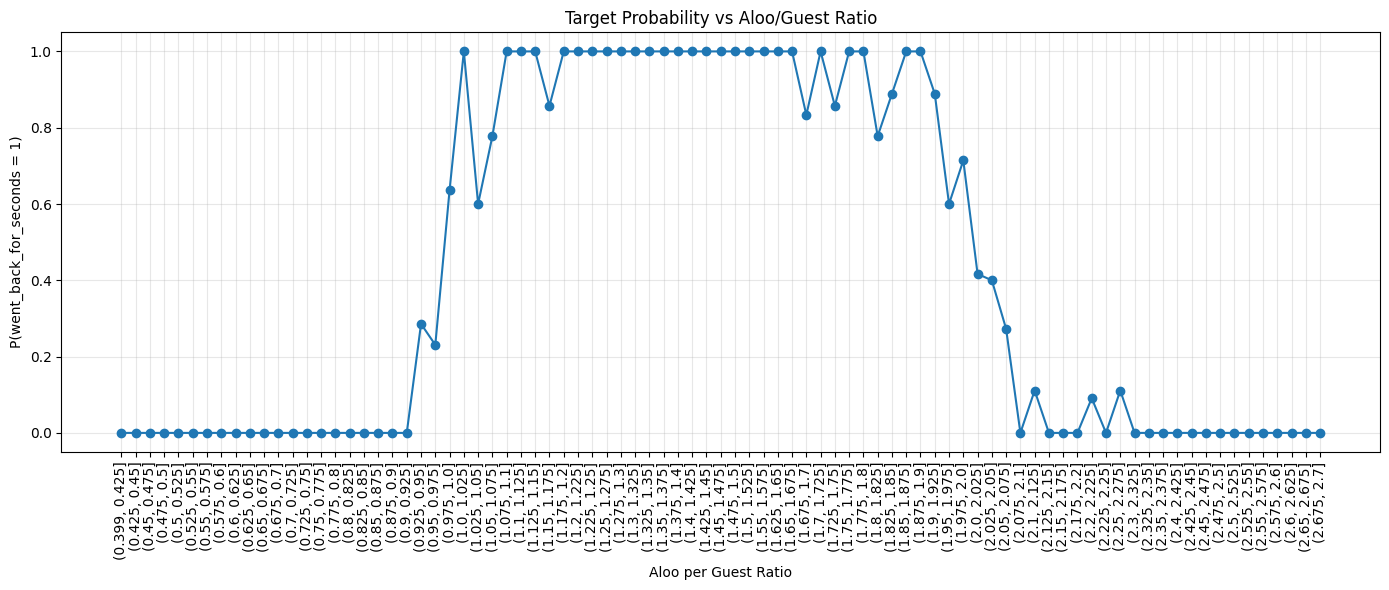

In [108]:
plt.figure(figsize=(14, 6))

plot_data = prob_table[prob_table["count"] >= 5]

plt.plot(
    plot_data.index.astype(str),
    plot_data["mean"],
    marker="o"
)

plt.xticks(rotation=90)
plt.ylabel("P(went_back_for_seconds = 1)")
plt.xlabel("Aloo per Guest Ratio")
plt.title("Target Probability vs Aloo/Guest Ratio")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [109]:
boundary_data = analysis[
    analysis["ratio"].notna()
].copy()

print("LOWER BOUNDARY")
print(
    boundary_data[
        boundary_data["ratio"].between(0.90, 1.10)
    ][
        ["wedding_id", "ratio", target]
    ]
    .sort_values("ratio")
    .to_string(index=False)
)

print("\n" + "=" * 80)

print("UPPER BOUNDARY")
print(
    boundary_data[
        boundary_data["ratio"].between(1.90, 2.15)
    ][
        ["wedding_id", "ratio", target]
    ]
    .sort_values("ratio")
    .to_string(index=False)
)

LOWER BOUNDARY
wedding_id    ratio  went_back_for_seconds
     W0034 0.903226                      0
     W0382 0.903226                      0
     W0356 0.911950                      0
     W0039 0.917241                      0
     W0133 0.917563                      0
     W0343 0.920732                      0
     W0190 0.922747                      0
     W0442 0.929878                      0
     W0630 0.930921                      0
     W0632 0.937143                      0
     W0389 0.939633                      0
     W0469 0.940426                      1
     W0180 0.941176                      0
     W0089 0.945122                      1
     W0085 0.950495                      0
     W0505 0.954887                      0
     W0573 0.956294                      0
     W0562 0.957565                      0
     W0217 0.957895                      0
     W0694 0.959391                      1
     W0542 0.962500                      0
     W0633 0.965116                    

In [110]:
candidate_thresholds = [
    (0.970, 2.010),
    (0.971, 2.010),
    (0.972, 2.010),
    (0.970, 2.009),
    (0.970, 2.008),
    (0.971, 2.009),
    (0.972, 2.009),
    (0.971, 2.011),
    (0.972, 2.011),
]

candidate_predictions = {}

for lower, upper in candidate_thresholds:
    candidate_predictions[f"{lower}_{upper}"] = (
        test_clean["aloo_per_guest_corrected"]
        .between(lower, upper)
        .astype(int)
    )

candidate_df = pd.DataFrame(candidate_predictions)

print("Prediction counts:")
print(candidate_df.sum())

print("\nNumber of test rows where candidates disagree:")
print((candidate_df.nunique(axis=1) > 1).sum())

print("\nRows affected:")
affected = candidate_df[candidate_df.nunique(axis=1) > 1].copy()

if len(affected) > 0:
    affected.insert(
        0,
        "ratio",
        test_clean.loc[affected.index, "aloo_per_guest_corrected"].values
    )
    affected.insert(
        0,
        "wedding_id",
        test_clean.loc[affected.index, "wedding_id"].values
    )
    print(affected.to_string(index=False))

Prediction counts:
0.97_2.01      184
0.971_2.01     182
0.972_2.01     182
0.97_2.009     184
0.97_2.008     184
0.971_2.009    182
0.972_2.009    182
0.971_2.011    183
0.972_2.011    183
dtype: int64

Number of test rows where candidates disagree:
3

Rows affected:
wedding_id    ratio  0.97_2.01  0.971_2.01  0.972_2.01  0.97_2.009  0.97_2.008  0.971_2.009  0.972_2.009  0.971_2.011  0.972_2.011
     W0803 2.010671          0           0           0           0           0            0            0            1            1
     W0968 0.970588          1           0           0           1           1            0            0            0            0
     W1163 0.970443          1           0           0           1           1            0            0            0            0


In [112]:
FINAL_LOWER = 0.97
FINAL_UPPER = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(FINAL_LOWER, FINAL_UPPER)
).astype(int)

In [113]:
submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)

print(submission.head(10))
print()
print("Shape:", submission.shape)
print()
print("Prediction counts:")
print(submission["went_back_for_seconds"].value_counts())

  wedding_id  went_back_for_seconds
0      W0801                      0
1      W0802                      0
2      W0803                      0
3      W0804                      1
4      W0805                      0
5      W0806                      0
6      W0807                      1
7      W0808                      0
8      W0809                      1
9      W0810                      1

Shape: (400, 2)

Prediction counts:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64


In [114]:
assert submission.shape == (400, 2)
assert submission["wedding_id"].equals(test["wedding_id"])
assert submission["wedding_id"].is_unique
assert submission["went_back_for_seconds"].isin([0, 1]).all()

print("FINAL SUBMISSION VALIDATION PASSED")
print("Rows:", len(submission))
print("Ones:", (submission["went_back_for_seconds"] == 1).sum())
print("Zeros:", (submission["went_back_for_seconds"] == 0).sum())

FINAL SUBMISSION VALIDATION PASSED
Rows: 400
Ones: 184
Zeros: 216


In [115]:
# Build a clean analysis dataset
d = train_clean.copy()

d["ratio"] = d["aloo_per_guest_corrected"]
d["mutton_per_guest"] = d["mutton_kg"] / d["guests"]
d["aloo_per_mutton"] = (
    d["aloo_count_corrected"] / d["mutton_kg"]
)

# Only rows with valid aloo ratio
d = d[d["ratio"].notna()].copy()

# Base rule
d["base_pred"] = (
    d["ratio"].between(0.97, 2.01)
).astype(int)

# Look only at rows where base rule is wrong
errors = d[d["base_pred"] != d["went_back_for_seconds"]].copy()

print("Total errors:", len(errors))
print("\nErrors by target:")
print(errors["went_back_for_seconds"].value_counts())

print("\nError rows:")
print(
    errors[
        [
            "wedding_id",
            "ratio",
            "mutton_per_guest",
            "aloo_per_mutton",
            "guests",
            "mutton_kg",
            "went_back_for_seconds"
        ]
    ].sort_values("ratio").to_string(index=False)
)

Total errors: 33

Errors by target:
went_back_for_seconds
0    22
1    11
Name: count, dtype: int64

Error rows:
wedding_id    ratio  mutton_per_guest  aloo_per_mutton  guests  mutton_kg  went_back_for_seconds
     W0469 0.940426          0.192340         4.889381     470       90.4                      1
     W0089 0.945122          0.241159         3.919090     328       79.1                      1
     W0694 0.959391          0.292893         3.275563     394      115.4                      1
     W0751 0.984568          0.246296         3.997494     648      159.6                      0
     W0665 0.992126          0.272047         3.646889     254       69.1                      0
     W0569 0.992958          0.233099         4.259819     142       33.1                      0
     W0261 1.000000          0.293064         3.412229     173       50.7                      0
     W0417 1.034370          0.257610         4.015248     611      157.4                      0
     W0193 1.0

In [116]:
# Test simple thresholds for secondary features ONLY inside
# the difficult boundary regions.

d["lower_uncertain"] = d["ratio"].between(0.90, 1.10)
d["upper_uncertain"] = d["ratio"].between(1.90, 2.15)

for region_name, region in [
    ("LOWER", d["lower_uncertain"]),
    ("UPPER", d["upper_uncertain"])
]:
    subset = d[region].copy()

    print("\n" + "=" * 70)
    print(region_name)
    print("Rows:", len(subset))

    for feature in [
        "mutton_per_guest",
        "aloo_per_mutton",
        "guests",
        "mutton_kg",
        "borhani_glasses",
        "fairy_lights",
        "dhol_players",
        "aunties_asking_when_marriage"
    ]:
        print(
            f"\n{feature}"
        )

        print(
            subset.groupby(
                "went_back_for_seconds"
            )[feature]
            .agg(["count", "mean", "median", "min", "max"])
        )


LOWER
Rows: 69

mutton_per_guest
                       count      mean    median       min       max
went_back_for_seconds                                               
0                         32  0.255318  0.257661  0.182286  0.309756
1                         37  0.248221  0.256250  0.183168  0.308649

aloo_per_mutton
                       count      mean    median       min       max
went_back_for_seconds                                               
0                         32  3.866412  3.746749  2.972441  5.322581
1                         37  4.222816  4.056604  3.177471  5.837838

guests
                       count        mean  median  min  max
went_back_for_seconds                                     
0                         32  315.468750   279.0   80  655
1                         37  363.567568   342.0   63  694

mutton_kg
                       count       mean  median   min    max
went_back_for_seconds                                       
0                   

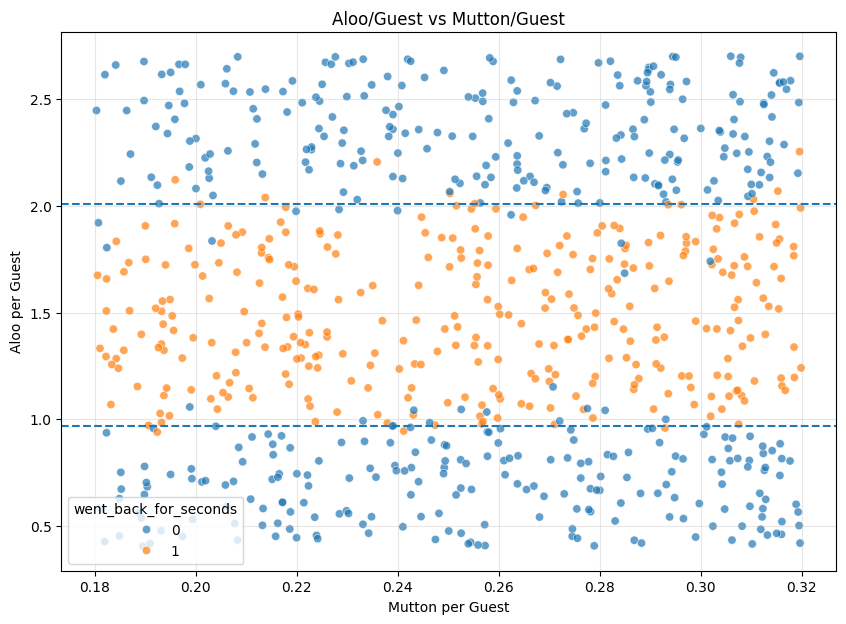

In [117]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=d,
    x="mutton_per_guest",
    y="ratio",
    hue="went_back_for_seconds",
    alpha=0.7
)

plt.axhline(0.97, linestyle="--")
plt.axhline(2.01, linestyle="--")

plt.xlabel("Mutton per Guest")
plt.ylabel("Aloo per Guest")
plt.title("Aloo/Guest vs Mutton/Guest")
plt.grid(True, alpha=0.3)
plt.show()

In [118]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
import numpy as np

model_data = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

X_ratio = model_data[["aloo_per_guest_corrected"]]
y_ratio = model_data["went_back_for_seconds"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Polynomial Logistic": Pipeline([
        ("poly", PolynomialFeatures(degree=5)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=5,
        min_samples_leaf=5,
        random_state=42
    ),

    "RBF SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=10,
            gamma="scale"
        ))
    ])
}

results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_ratio,
        y_ratio,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "model": name,
        "mean_accuracy": scores.mean(),
        "std": scores.std(),
        "scores": scores
    })

results_df = pd.DataFrame(results)

print(
    results_df[
        ["model", "mean_accuracy", "std"]
    ].sort_values(
        "mean_accuracy",
        ascending=False
    ).to_string(index=False)
)

              model  mean_accuracy      std
      Random Forest       0.953623 0.015429
        Extra Trees       0.948462 0.015237
Polynomial Logistic       0.942043 0.016659
            RBF SVM       0.940720 0.014376


In [119]:
ratio_data = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

ratio_data["ratio"] = ratio_data["aloo_per_guest_corrected"]

# Very fine bins
bins = np.arange(0.40, 2.71, 0.01)

ratio_data["fine_bin"] = pd.cut(
    ratio_data["ratio"],
    bins=bins,
    include_lowest=True
)

prob = (
    ratio_data
    .groupby("fine_bin", observed=False)["went_back_for_seconds"]
    .agg(["count", "mean"])
)

# Probability > 0.5 => predict 1
prob["predicted_class"] = (
    prob["mean"] > 0.5
).astype(int)

print(prob.to_string())

               count      mean  predicted_class
fine_bin                                       
(0.399, 0.41]      3  0.000000                0
(0.41, 0.42]       4  0.000000                0
(0.42, 0.43]       4  0.000000                0
(0.43, 0.44]       4  0.000000                0
(0.44, 0.45]       4  0.000000                0
(0.45, 0.46]       6  0.000000                0
(0.46, 0.47]       4  0.000000                0
(0.47, 0.48]       2  0.000000                0
(0.48, 0.49]       3  0.000000                0
(0.49, 0.5]        3  0.000000                0
(0.5, 0.51]        4  0.000000                0
(0.51, 0.52]       2  0.000000                0
(0.52, 0.53]       2  0.000000                0
(0.53, 0.54]       3  0.000000                0
(0.54, 0.55]       6  0.000000                0
(0.55, 0.56]       3  0.000000                0
(0.56, 0.57]       4  0.000000                0
(0.57, 0.58]       4  0.000000                0
(0.58, 0.59]       3  0.000000          

In [120]:
ratio_data = ratio_data.merge(
    prob[["predicted_class"]],
    left_on="fine_bin",
    right_index=True,
    how="left"
)

fine_bin_accuracy = accuracy_score(
    ratio_data["went_back_for_seconds"],
    ratio_data["predicted_class"]
)

print("Fine-bin accuracy:", fine_bin_accuracy)

Fine-bin accuracy: 0.9677835051546392


In [121]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

cv_data = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

cv_data["ratio"] = cv_data["aloo_per_guest_corrected"]

X = cv_data["ratio"].values
y = cv_data["went_back_for_seconds"].values

# Fixed bins — এগুলো আগে থেকেই নির্ধারিত
bins = np.arange(0.40, 2.71, 0.01)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):

    train_fold = cv_data.iloc[train_idx].copy()
    val_fold = cv_data.iloc[val_idx].copy()

    # Same fixed bins
    train_fold["ratio_bin"] = pd.cut(
        train_fold["ratio"],
        bins=bins,
        include_lowest=True
    )

    val_fold["ratio_bin"] = pd.cut(
        val_fold["ratio"],
        bins=bins,
        include_lowest=True
    )

    # Learn probability ONLY from training fold
    bin_stats = (
        train_fold
        .groupby("ratio_bin", observed=False)["went_back_for_seconds"]
        .agg(["count", "mean"])
    )

    # Convert probability to class
    bin_stats["prediction"] = (
        bin_stats["mean"] >= 0.5
    ).astype(int)

    # Map training-learned prediction to validation
    val_pred = (
        val_fold["ratio_bin"]
        .map(bin_stats["prediction"])
        .fillna(0)
        .astype(int)
        .values
    )

    score = accuracy_score(
        val_fold["went_back_for_seconds"],
        val_pred
    )

    fold_scores.append(score)

    print(
        f"Fold {fold}: {score:.6f}"
    )

print("\n" + "=" * 50)
print("5-Fold Fine-Bin CV")
print("Scores:", fold_scores)
print("Mean:", np.mean(fold_scores))
print("Std:", np.std(fold_scores))

Fold 1: 0.942308
Fold 2: 0.916129
Fold 3: 0.935484
Fold 4: 0.941935
Fold 5: 0.941935

5-Fold Fine-Bin CV
Scores: [0.9423076923076923, 0.9161290322580645, 0.9354838709677419, 0.9419354838709677, 0.9419354838709677]
Mean: 0.9355583126550868
Std: 0.010043836213710912


In [122]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

d = train_clean.copy()

# Core normalized features
d["aloo_per_guest"] = d["aloo_count_corrected"] / d["guests"]
d["mutton_per_guest"] = d["mutton_kg"] / d["guests"]
d["borhani_per_guest"] = d["borhani_glasses"] / d["guests"]
d["lights_per_guest"] = d["fairy_lights"] / d["guests"]
d["dhol_per_guest"] = d["dhol_players"] / d["guests"]
d["aunties_per_guest"] = (
    d["aunties_asking_when_marriage"] / d["guests"]
)

# Food relationships
d["aloo_per_mutton"] = (
    d["aloo_count_corrected"] / d["mutton_kg"]
)

d["borhani_per_mutton"] = (
    d["borhani_glasses"] / d["mutton_kg"]
)

d["lights_per_mutton"] = (
    d["fairy_lights"] / d["mutton_kg"]
)

features = [
    "aloo_per_guest",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest",
    "aloo_per_mutton",
    "borhani_per_mutton",
    "lights_per_mutton",
]

X = d[features]
y = d["went_back_for_seconds"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for depth in [2, 3, 4, 5]:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=500,
            max_depth=depth,
            min_samples_leaf=5,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    print(
        f"depth={depth}: "
        f"mean={scores.mean():.6f}, "
        f"std={scores.std():.6f}, "
        f"scores={scores}"
    )

depth=2: mean=0.731250, std=0.034004, scores=[0.7625  0.7     0.775   0.73125 0.6875 ]
depth=3: mean=0.882500, std=0.025434, scores=[0.875   0.8625  0.93125 0.8625  0.88125]
depth=4: mean=0.912500, std=0.018540, scores=[0.89375 0.89375 0.94375 0.91875 0.9125 ]
depth=5: mean=0.908750, std=0.020767, scores=[0.875   0.9125  0.9375  0.9     0.91875]


In [123]:
# ============================================================
# EVENT-SPECIFIC RATIO ANALYSIS
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["ratio"] = d["aloo_per_guest_corrected"]

events = d["event"].unique()

for event in events:

    subset = d[d["event"] == event].copy()

    best = None

    for lower in np.arange(0.85, 1.11, 0.005):
        for upper in np.arange(1.90, 2.31, 0.005):

            pred = (
                subset["ratio"]
                .between(lower, upper)
                .astype(int)
            )

            acc = accuracy_score(
                subset["went_back_for_seconds"],
                pred
            )

            if best is None or acc > best["accuracy"]:
                best = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    print("\n", "=" * 60)
    print("EVENT:", event)
    print("Rows:", len(subset))
    print("Best:", best)


EVENT: Gaye Holud
Rows: 229
Best: {'lower': np.float64(1.0050000000000001), 'upper': np.float64(1.989999999999998), 'accuracy': 0.9694323144104804}

EVENT: Bou-bhat
Rows: 178
Best: {'lower': np.float64(0.9700000000000001), 'upper': np.float64(2.0099999999999976), 'accuracy': 0.9550561797752809}

EVENT: Biye
Rows: 369
Best: {'lower': np.float64(0.9700000000000001), 'upper': np.float64(2.0099999999999976), 'accuracy': 0.959349593495935}


In [124]:
# ============================================================
# CITY-SPECIFIC RATIO ANALYSIS
# ============================================================

cities = d["city"].unique()

for city in cities:

    subset = d[d["city"] == city].copy()

    best = None

    for lower in np.arange(0.85, 1.11, 0.005):
        for upper in np.arange(1.90, 2.31, 0.005):

            pred = (
                subset["ratio"]
                .between(lower, upper)
                .astype(int)
            )

            acc = accuracy_score(
                subset["went_back_for_seconds"],
                pred
            )

            if best is None or acc > best["accuracy"]:
                best = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    print("\n", "=" * 60)
    print("CITY:", city)
    print("Rows:", len(subset))
    print("Best:", best)


CITY: Barishal
Rows: 64
Best: {'lower': np.float64(0.9850000000000001), 'upper': np.float64(2.0049999999999977), 'accuracy': 0.984375}

CITY: Dhaka
Rows: 254
Best: {'lower': np.float64(1.06), 'upper': np.float64(2.0049999999999977), 'accuracy': 0.9724409448818898}

CITY: Mymensingh
Rows: 37
Best: {'lower': np.float64(0.935), 'upper': np.float64(1.9), 'accuracy': 0.972972972972973}

CITY: Khulna
Rows: 85
Best: {'lower': np.float64(0.9550000000000001), 'upper': np.float64(1.9), 'accuracy': 0.9647058823529412}

CITY: Chattogram
Rows: 115
Best: {'lower': np.float64(0.9700000000000001), 'upper': np.float64(2.0099999999999976), 'accuracy': 0.9652173913043478}

CITY: Sylhet
Rows: 66
Best: {'lower': np.float64(0.925), 'upper': np.float64(2.0099999999999976), 'accuracy': 0.9696969696969697}

CITY: Rajshahi
Rows: 99
Best: {'lower': np.float64(0.9700000000000001), 'upper': np.float64(1.9199999999999995), 'accuracy': 0.9292929292929293}

CITY: Rangpur
Rows: 56
Best: {'lower': np.float64(0.915), '

In [125]:
# ============================================================
# EVENT-SPECIFIC THRESHOLD — LEAKAGE-FREE 5-FOLD CV
# ============================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["ratio"] = d["aloo_per_guest_corrected"]

lower_grid = np.arange(0.90, 1.101, 0.005)
upper_grid = np.arange(1.90, 2.151, 0.005)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(d, d["went_back_for_seconds"]), 1
):

    train_fold = d.iloc[train_idx].copy()
    val_fold = d.iloc[val_idx].copy()

    global_best = None

    # Global fallback threshold
    for lower in lower_grid:
        for upper in upper_grid:

            pred = train_fold["ratio"].between(
                lower, upper
            ).astype(int)

            acc = accuracy_score(
                train_fold["went_back_for_seconds"],
                pred
            )

            if global_best is None or acc > global_best["accuracy"]:
                global_best = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    event_rules = {}

    # Learn separate rule for each event
    for event in train_fold["event"].unique():

        subset = train_fold[
            train_fold["event"] == event
        ]

        best = None

        for lower in lower_grid:
            for upper in upper_grid:

                pred = subset["ratio"].between(
                    lower, upper
                ).astype(int)

                acc = accuracy_score(
                    subset["went_back_for_seconds"],
                    pred
                )

                if best is None or acc > best["accuracy"]:
                    best = {
                        "lower": lower,
                        "upper": upper,
                        "accuracy": acc
                    }

        event_rules[event] = best

    # Predict validation fold
    val_pred = []

    for _, row in val_fold.iterrows():

        rule = event_rules.get(
            row["event"],
            global_best
        )

        pred = int(
            rule["lower"]
            <= row["ratio"]
            <= rule["upper"]
        )

        val_pred.append(pred)

    score = accuracy_score(
        val_fold["went_back_for_seconds"],
        val_pred
    )

    fold_scores.append(score)

    print(
        f"Fold {fold}: {score:.6f}"
    )

print("\n" + "=" * 60)
print("EVENT-SPECIFIC CV")
print("Scores:", fold_scores)
print("Mean:", np.mean(fold_scores))
print("Std:", np.std(fold_scores))

Fold 1: 0.948718
Fold 2: 0.941935
Fold 3: 0.954839
Fold 4: 0.980645
Fold 5: 0.922581

EVENT-SPECIFIC CV
Scores: [0.9487179487179487, 0.9419354838709677, 0.9548387096774194, 0.9806451612903225, 0.9225806451612903]
Mean: 0.9497435897435897
Std: 0.018871732227914714


In [126]:
# ============================================================
# CITY-SPECIFIC THRESHOLD — LEAKAGE-FREE 5-FOLD CV
# ============================================================

fold_scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(d, d["went_back_for_seconds"]), 1
):

    train_fold = d.iloc[train_idx].copy()
    val_fold = d.iloc[val_idx].copy()

    global_best = None

    # Global fallback threshold
    for lower in lower_grid:
        for upper in upper_grid:

            pred = train_fold["ratio"].between(
                lower, upper
            ).astype(int)

            acc = accuracy_score(
                train_fold["went_back_for_seconds"],
                pred
            )

            if global_best is None or acc > global_best["accuracy"]:
                global_best = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    city_rules = {}

    # Learn separate rule for each city
    for city in train_fold["city"].unique():

        subset = train_fold[
            train_fold["city"] == city
        ]

        best = None

        for lower in lower_grid:
            for upper in upper_grid:

                pred = subset["ratio"].between(
                    lower, upper
                ).astype(int)

                acc = accuracy_score(
                    subset["went_back_for_seconds"],
                    pred
                )

                if best is None or acc > best["accuracy"]:
                    best = {
                        "lower": lower,
                        "upper": upper,
                        "accuracy": acc
                    }

        city_rules[city] = best

    # Predict validation fold
    val_pred = []

    for _, row in val_fold.iterrows():

        rule = city_rules.get(
            row["city"],
            global_best
        )

        pred = int(
            rule["lower"]
            <= row["ratio"]
            <= rule["upper"]
        )

        val_pred.append(pred)

    score = accuracy_score(
        val_fold["went_back_for_seconds"],
        val_pred
    )

    fold_scores.append(score)

    print(
        f"Fold {fold}: {score:.6f}"
    )

print("\n" + "=" * 60)
print("CITY-SPECIFIC CV")
print("Scores:", fold_scores)
print("Mean:", np.mean(fold_scores))
print("Std:", np.std(fold_scores))

Fold 1: 0.942308
Fold 2: 0.948387
Fold 3: 0.948387
Fold 4: 0.954839
Fold 5: 0.941935

CITY-SPECIFIC CV
Scores: [0.9423076923076923, 0.9483870967741935, 0.9483870967741935, 0.9548387096774194, 0.9419354838709677]
Mean: 0.9471712158808934
Std: 0.004750030421797149


In [127]:
# ============================================================
# EXACT RATIO THRESHOLD SEARCH
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["ratio"] = d["aloo_per_guest_corrected"]

ratios = np.sort(d["ratio"].unique())

best = None

for i in range(len(ratios)):
    lower = ratios[i]

    for j in range(i, len(ratios)):
        upper = ratios[j]

        pred = d["ratio"].between(
            lower,
            upper
        ).astype(int)

        acc = accuracy_score(
            d["went_back_for_seconds"],
            pred
        )

        if best is None or acc > best["accuracy"]:
            best = {
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            }

print(best)

{'lower': np.float64(0.9714285714285714), 'upper': np.float64(2.0097323600973236), 'accuracy': 0.9587628865979382}


In [128]:
# ============================================================
# TOP EXACT THRESHOLD INTERVALS
# ============================================================

results = []

for i in range(len(ratios)):
    lower = ratios[i]

    for j in range(i, len(ratios)):
        upper = ratios[j]

        pred = d["ratio"].between(
            lower,
            upper
        ).astype(int)

        acc = accuracy_score(
            d["went_back_for_seconds"],
            pred
        )

        if acc >= 0.947:
            results.append({
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            })

top_intervals = (
    pd.DataFrame(results)
    .sort_values(
        ["accuracy", "lower", "upper"],
        ascending=[False, True, True]
    )
    .head(30)
)

print(top_intervals.to_string(index=False))

   lower    upper  accuracy
0.971429 2.009732  0.958763
0.969925 2.009732  0.957474
0.971429 2.006742  0.957474
0.971429 2.009934  0.957474
0.972743 2.009732  0.957474
0.968847 2.009732  0.956186
0.969925 2.006742  0.956186
0.969925 2.009934  0.956186
0.971429 2.004831  0.956186
0.971429 2.012411  0.956186
0.972743 2.006742  0.956186
0.972743 2.009934  0.956186
0.976321 2.009732  0.956186
0.967742 2.009732  0.954897
0.968847 2.006742  0.954897
0.968847 2.009934  0.954897
0.969925 2.004831  0.954897
0.969925 2.012411  0.954897
0.971429 2.004773  0.954897
0.971429 2.013183  0.954897
0.972743 2.004831  0.954897
0.972743 2.012411  0.954897
0.976321 2.006742  0.954897
0.976321 2.009934  0.954897
0.977124 2.009732  0.954897
0.959391 2.009732  0.953608
0.965116 2.009732  0.953608
0.967742 2.006742  0.953608
0.967742 2.009934  0.953608
0.968847 2.004831  0.953608


In [129]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

d = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()
d["ratio"] = d["aloo_per_guest_corrected"]

X = d["ratio"].values
y = d["went_back_for_seconds"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):

    train_ratio = X[train_idx]
    train_y = y[train_idx]

    val_ratio = X[val_idx]
    val_y = y[val_idx]

    ratios = np.sort(np.unique(train_ratio))

    best = None

    for i in range(len(ratios)):
        lower = ratios[i]

        for j in range(i, len(ratios)):
            upper = ratios[j]

            pred = (
                (train_ratio >= lower) &
                (train_ratio <= upper)
            ).astype(int)

            acc = accuracy_score(train_y, pred)

            if best is None or acc > best["train_accuracy"]:
                best = {
                    "lower": lower,
                    "upper": upper,
                    "train_accuracy": acc
                }

    val_pred = (
        (val_ratio >= best["lower"]) &
        (val_ratio <= best["upper"])
    ).astype(int)

    val_accuracy = accuracy_score(val_y, val_pred)

    cv_results.append({
        "fold": fold,
        "lower": best["lower"],
        "upper": best["upper"],
        "train_accuracy": best["train_accuracy"],
        "validation_accuracy": val_accuracy
    })

cv_results_df = pd.DataFrame(cv_results)

print(cv_results_df.to_string(index=False))
print()
print("Mean CV accuracy:",
      cv_results_df["validation_accuracy"].mean())
print("Std CV accuracy:",
      cv_results_df["validation_accuracy"].std())

 fold    lower    upper  train_accuracy  validation_accuracy
    1 0.971429 2.009732        0.962903             0.942308
    2 0.976321 2.009732        0.959742             0.941935
    3 0.971429 2.009732        0.958132             0.961290
    4 0.971429 2.009732        0.951691             0.987097
    5 0.971429 2.006742        0.961353             0.941935

Mean CV accuracy: 0.9549131513647641
Std CV accuracy: 0.019825433137139137


In [130]:
final_lower = 0.97
final_upper = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(final_lower, final_upper)
).astype(int)

In [131]:
submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": test_predictions
})

submission.to_csv("submission.csv", index=False)

In [133]:
features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "drone_photographer",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "aloo_per_mutton"
]

errors = analysis[analysis["error"] == 1].copy()

numeric_features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "aloo_per_mutton"
]

categorical_features = [
    "drone_photographer"
]

print("========== NUMERIC FEATURES ==========")

for col in numeric_features:
    print("\n" + "=" * 60)
    print(col)

    print("\nAll training data:")
    print(
        analysis.groupby(target)[col]
        .agg(["mean", "median", "std", "min", "max"])
        .round(4)
    )

    print("\nErrors only:")
    print(
        errors.groupby(target)[col]
        .agg(["mean", "median", "std", "min", "max"])
        .round(4)
    )


print("\n\n========== CATEGORICAL FEATURES ==========")

for col in categorical_features:
    print("\n" + "=" * 60)
    print(col)

    print("\nAll training data:")
    print(
        pd.crosstab(
            analysis[target],
            analysis[col],
            normalize="index"
        ).round(4)
    )

    print("\nErrors only:")
    print(
        pd.crosstab(
            errors[target],
            errors[col],
            normalize="index"
        ).round(4)
    )

========== NUMERIC FEATURES ==========

guests

All training data:
                           mean  median       std  min  max
went_back_for_seconds                                      
0                      368.0862   359.0  182.2753   51  700
1                      376.5089   374.5  187.4773   51  696

Errors only:
                           mean  median       std  min  max
went_back_for_seconds                                      
0                      338.5909   293.5  210.7505   51  655
1                      323.7368   268.0  156.3482   78  605

mutton_kg

All training data:
                          mean  median      std   min    max
went_back_for_seconds                                       
0                      93.8259    92.8  48.4109   9.3  221.3
1                      95.0738    93.5  49.9215  11.5  219.1

Errors only:
                          mean  median      std   min    max
went_back_for_seconds                                       
0                      83.66

In [134]:
uncertain = analysis[
    (
        (analysis["ratio"] >= 0.90) &
        (analysis["ratio"] <= 1.10)
    )
    |
    (
        (analysis["ratio"] >= 1.90) &
        (analysis["ratio"] <= 2.15)
    )
].copy()

print("Uncertain rows:", len(uncertain))
print(
    uncertain[target]
    .value_counts()
    .sort_index()
)

print("\nTarget rate:")
print(
    uncertain.groupby(
        pd.cut(
            uncertain["ratio"],
            bins=[0.9, 0.95, 1.00, 1.05, 1.10, 1.90, 1.95, 2.00, 2.05, 2.10, 2.15]
        ),
        observed=False
    )[target]
    .agg(["count", "mean"])
)

Uncertain rows: 150
went_back_for_seconds
0    83
1    67
Name: count, dtype: int64

Target rate:
             count      mean
ratio                       
(0.9, 0.95]     14  0.142857
(0.95, 1.0]     24  0.416667
(1.0, 1.05]     17  0.764706
(1.05, 1.1]     14  0.857143
(1.1, 1.9]       0       NaN
(1.9, 1.95]     12  0.916667
(1.95, 2.0]     12  0.666667
(2.0, 2.05]     17  0.411765
(2.05, 2.1]     20  0.150000
(2.1, 2.15]     20  0.050000


In [135]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

d = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

d["ratio"] = d["aloo_per_guest_corrected"]
d["base_pred"] = (
    d["ratio"].between(0.97, 2.01)
).astype(int)

d["aloo_per_mutton"] = (
    d["aloo_count_corrected"] / d["mutton_kg"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(d, d[target]), 1):

    tr = d.iloc[train_idx].copy()
    va = d.iloc[val_idx].copy()

    # Only modify predictions near the two base boundaries
    tr["uncertain"] = (
        tr["ratio"].between(0.90, 1.10)
        |
        tr["ratio"].between(1.90, 2.15)
    )

    va["uncertain"] = (
        va["ratio"].between(0.90, 1.10)
        |
        va["ratio"].between(1.90, 2.15)
    )

    # Try a simple global threshold on aloo_per_mutton
    thresholds = np.linspace(
        tr["aloo_per_mutton"].quantile(0.05),
        tr["aloo_per_mutton"].quantile(0.95),
        100
    )

    best = None

    for threshold in thresholds:

        pred = tr["base_pred"].copy()

        mask = tr["uncertain"]

        pred[mask] = (
            tr.loc[mask, "aloo_per_mutton"] >= threshold
        ).astype(int)

        acc = accuracy_score(tr[target], pred)

        if best is None or acc > best["train_accuracy"]:
            best = {
                "threshold": threshold,
                "train_accuracy": acc
            }

    val_pred = va["base_pred"].copy()

    mask = va["uncertain"]

    val_pred[mask] = (
        va.loc[mask, "aloo_per_mutton"] >= best["threshold"]
    ).astype(int)

    val_acc = accuracy_score(
        va[target],
        val_pred
    )

    results.append({
        "fold": fold,
        "threshold": best["threshold"],
        "train_accuracy": best["train_accuracy"],
        "validation_accuracy": val_acc
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print()
print(
    "Mean CV accuracy:",
    results_df["validation_accuracy"].mean()
)

print(
    "Std CV accuracy:",
    results_df["validation_accuracy"].std()
)

 fold  threshold  train_accuracy  validation_accuracy
    1   9.081521        0.901613             0.897436
    2   9.073818        0.903382             0.890323
    3  10.696390        0.903382             0.890323
    4  11.183432        0.901771             0.903226
    5  10.691778        0.901771             0.896774

Mean CV accuracy: 0.895616211745244
Std CV accuracy: 0.005445254124278804


In [136]:
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

X = d["aloo_per_guest_corrected"].values
y = d["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), 1
):

    X_train = X[train_idx]
    y_train = y[train_idx]

    X_val = X[val_idx]
    y_val = y[val_idx]

    # Estimate P(y=1 | ratio)
    iso = IsotonicRegression(
        y_min=0,
        y_max=1,
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(X_train, y_train)

    val_prob = iso.predict(X_val)

    val_pred = (val_prob >= 0.5).astype(int)

    acc = accuracy_score(y_val, val_pred)

    scores.append(acc)

    print(
        f"Fold {fold}: {acc:.6f}"
    )

print()
print("Mean CV accuracy:", np.mean(scores))
print("Std CV accuracy:", np.std(scores))

Fold 1: 0.679487
Fold 2: 0.658065
Fold 3: 0.664516
Fold 4: 0.677419
Fold 5: 0.683871

Mean CV accuracy: 0.672671629445823
Std CV accuracy: 0.009739586680023836


In [138]:
# Create normalized features
analysis["borhani_per_guest"] = (
    analysis["borhani_glasses"] / analysis["guests"]
)

analysis["lights_per_guest"] = (
    analysis["fairy_lights"] / analysis["guests"]
)

analysis["dhol_per_guest"] = (
    analysis["dhol_players"] / analysis["guests"]
)

analysis["aunties_per_guest"] = (
    analysis["aunties_asking_when_marriage"] / analysis["guests"]
)

# IMPORTANT: recreate errors AFTER creating the new columns
errors = analysis[analysis["error"] == 1].copy()

new_features = [
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

print("========== NORMALIZED FEATURES ==========")

for col in new_features:

    print("\n" + "=" * 60)
    print(col)

    print("\nAll training data:")
    print(
        analysis.groupby(target)[col]
        .agg(["mean", "median", "std", "min", "max"])
        .round(6)
    )

    print("\nErrors only:")
    print(
        errors.groupby(target)[col]
        .agg(["mean", "median", "std", "min", "max"])
        .round(6)
    )

========== NORMALIZED FEATURES ==========

borhani_per_guest

All training data:
                           mean    median       std       min       max
went_back_for_seconds                                                  
0                      1.141273  1.154066  0.203408  0.800000  1.496881
1                      1.164972  1.149970  0.200657  0.799652  1.494624

Errors only:
                           mean    median       std       min       max
went_back_for_seconds                                                  
0                      1.116327  1.047544  0.217965  0.835106  1.470588
1                      1.208865  1.238979  0.214067  0.847934  1.489720

lights_per_guest

All training data:
                           mean    median       std       min       max
went_back_for_seconds                                                  
0                      2.780606  2.682467  1.267493  0.560408  8.014706
1                      2.871935  2.781956  1.204008  0.656156  7.275362

Er

In [139]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np

d = analysis[
    analysis["aloo_per_guest_corrected"].notna()
].copy()

base_features = [
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for feature in base_features:

    scores = []

    for train_idx, val_idx in skf.split(d, d[target]):

        tr = d.iloc[train_idx]
        va = d.iloc[val_idx]

        tr_base = (
            tr["aloo_per_guest_corrected"]
            .between(0.97, 2.01)
        ).astype(int)

        va_base = (
            va["aloo_per_guest_corrected"]
            .between(0.97, 2.01)
        ).astype(int)

        tr_uncertain = (
            tr["aloo_per_guest_corrected"].between(0.90, 1.10)
            |
            tr["aloo_per_guest_corrected"].between(1.90, 2.15)
        )

        va_uncertain = (
            va["aloo_per_guest_corrected"].between(0.90, 1.10)
            |
            va["aloo_per_guest_corrected"].between(1.90, 2.15)
        )

        model = DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        )

        model.fit(
            tr.loc[tr_uncertain, [feature]],
            tr.loc[tr_uncertain, target]
        )

        correction = model.predict(
            va.loc[va_uncertain, [feature]]
        )

        final_pred = va_base.copy()
        final_pred[va_uncertain] = correction

        scores.append(
            accuracy_score(
                va[target],
                final_pred
            )
        )

    print(
        f"{feature}: "
        f"{np.mean(scores):.6f} "
        f"(std={np.std(scores):.6f})"
    )

borhani_per_guest: 0.898189 (std=0.016054)
lights_per_guest: 0.903350 (std=0.004088)
dhol_per_guest: 0.904632 (std=0.009548)
aunties_per_guest: 0.909801 (std=0.003887)


In [140]:
boundary_rows = analysis[
    (
        analysis["ratio"].between(0.90, 1.10)
    )
    |
    (
        analysis["ratio"].between(1.90, 2.15)
    )
].copy()

cols = [
    "wedding_id",
    "ratio",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest",
    "drone_photographer",
    "event",
    "city",
    target,
    "base_prediction",
    "error"
]

print(
    boundary_rows[
        cols
    ].sort_values("ratio").to_string(index=False)
)

wedding_id    ratio  mutton_per_guest  borhani_per_guest  lights_per_guest  dhol_per_guest  aunties_per_guest drone_photographer      event       city  went_back_for_seconds  base_prediction  error
     W0034 0.903226          0.246628           0.832845          2.551320        0.014663           0.023460                 no Gaye Holud     Sylhet                      0                0      0
     W0382 0.903226          0.274839           0.870968          3.819355        0.025806           0.025806                yes   Bou-bhat      Dhaka                      0                0      0
     W0356 0.911950          0.306289           1.427673          1.251572        0.025157           0.025157                yes   Bou-bhat    Rangpur                      0                0      0
     W0039 0.917241          0.304828           1.475862          4.841379        0.055172           0.055172                yes   Bou-bhat     Sylhet                      0                0      0
     W0133

In [141]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

X = d["aloo_per_guest_corrected"].values
y = d["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lower_values = np.arange(0.965, 0.981, 0.001)
upper_values = np.arange(2.000, 2.021, 0.001)

results = []

for lower in lower_values:
    for upper in upper_values:

        fold_scores = []

        for train_idx, val_idx in skf.split(X, y):

            val_ratio = X[val_idx]
            val_y = y[val_idx]

            val_pred = (
                (val_ratio >= lower) &
                (val_ratio <= upper)
            ).astype(int)

            fold_scores.append(
                accuracy_score(val_y, val_pred)
            )

        results.append({
            "lower": lower,
            "upper": upper,
            "mean_cv": np.mean(fold_scores),
            "std_cv": np.std(fold_scores)
        })

cv_thresholds = (
    pd.DataFrame(results)
    .sort_values(
        ["mean_cv", "std_cv"],
        ascending=[False, True]
    )
)

print(cv_thresholds.head(20).to_string(index=False))

 lower  upper  mean_cv   std_cv
 0.970  2.010 0.957494 0.013198
 0.970  2.011 0.957494 0.013198
 0.970  2.012 0.957494 0.013198
 0.971  2.010 0.957494 0.013198
 0.971  2.011 0.957494 0.013198
 0.971  2.012 0.957494 0.013198
 0.970  2.007 0.957494 0.016556
 0.970  2.008 0.957494 0.016556
 0.970  2.009 0.957494 0.016556
 0.971  2.007 0.957494 0.016556
 0.971  2.008 0.957494 0.016556
 0.971  2.009 0.957494 0.016556
 0.969  2.010 0.956203 0.011005
 0.969  2.011 0.956203 0.011005
 0.969  2.012 0.956203 0.011005
 0.970  2.013 0.956203 0.011005
 0.971  2.013 0.956203 0.011005
 0.972  2.010 0.956203 0.013701
 0.972  2.011 0.956203 0.013701
 0.972  2.012 0.956203 0.013701


In [142]:
final_lower = 0.97
final_upper = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(final_lower, final_upper)
).astype(int)

submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": test_predictions
})

submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
print("\nPrediction counts:")
print(submission["went_back_for_seconds"].value_counts())

print("\nFirst 10 rows:")
print(submission.head(10))

Submission shape: (400, 2)

Prediction counts:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

First 10 rows:
  wedding_id  went_back_for_seconds
0      W0801                      0
1      W0802                      0
2      W0803                      0
3      W0804                      1
4      W0805                      0
5      W0806                      0
6      W0807                      1
7      W0808                      0
8      W0809                      1
9      W0810                      1


In [143]:
assert submission.shape == (400, 2)
assert submission["wedding_id"].equals(test["wedding_id"])
assert submission["wedding_id"].is_unique
assert submission["went_back_for_seconds"].isin([0, 1]).all()

print("Submission validation PASSED")

Submission validation PASSED


In [144]:
# ============================================================
# EXPERIMENT 1: WEDDING ID / ORDER PATTERN
# ============================================================

tmp = train_clean.copy()

tmp["id_num"] = (
    tmp["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

tmp["id_bin"] = pd.cut(
    tmp["id_num"],
    bins=[0, 100, 200, 300, 400, 500, 600, 700, 800],
    include_lowest=True
)

print(
    tmp.groupby("id_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "mean"])
)

                 count  mean
id_bin                      
(-0.001, 100.0]    100  0.42
(100.0, 200.0]     100  0.42
(200.0, 300.0]     100  0.50
(300.0, 400.0]     100  0.44
(400.0, 500.0]     100  0.42
(500.0, 600.0]     100  0.41
(600.0, 700.0]     100  0.37
(700.0, 800.0]     100  0.38


In [146]:
# ============================================================
# EXPERIMENT 1: WEDDING ID / ORDER PATTERN
# ============================================================

tmp = train_clean.copy()

tmp["id_num"] = (
    tmp["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

tmp["id_bin"] = pd.cut(
    tmp["id_num"],
    bins=[0, 100, 200, 300, 400, 500, 600, 700, 800],
    include_lowest=True
)

print(
    tmp.groupby("id_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "mean"])
)

                 count  mean
id_bin                      
(-0.001, 100.0]    100  0.42
(100.0, 200.0]     100  0.42
(200.0, 300.0]     100  0.50
(300.0, 400.0]     100  0.44
(400.0, 500.0]     100  0.42
(500.0, 600.0]     100  0.41
(600.0, 700.0]     100  0.37
(700.0, 800.0]     100  0.38


In [147]:
# ============================================================
# EXPERIMENT 2: ID + ALOO RATIO
# ============================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score
import numpy as np

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

# Create ID number HERE
d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

X = d[
    [
        "aloo_per_guest_corrected",
        "id_num"
    ]
]

y = d["went_back_for_seconds"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "RF": RandomForestClassifier(
        n_estimators=500,
        max_depth=4,
        min_samples_leaf=8,
        random_state=42,
        n_jobs=-1
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=4,
        min_samples_leaf=8,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():

    scores = []

    for train_idx, val_idx in skf.split(X, y):

        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        pred = model.predict(X.iloc[val_idx])

        scores.append(
            accuracy_score(y.iloc[val_idx], pred)
        )

    print(
        name,
        "mean CV =",
        round(np.mean(scores), 6),
        "std =",
        round(np.std(scores), 6)
    )

RF mean CV = 0.953623 std = 0.015429
ExtraTrees mean CV = 0.932986 std = 0.0145


In [148]:
# ============================================================
# EXPERIMENT 4: DOES THE ALOO THRESHOLD SHIFT WITH ID?
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

# Split the training data into chronological blocks
d["id_bin"] = pd.cut(
    d["id_num"],
    bins=[0, 200, 400, 600, 800],
    include_lowest=True
)

for name, group in d.groupby("id_bin", observed=True):

    best_acc = 0
    best_lower = None
    best_upper = None

    ratio = group["aloo_per_guest_corrected"].values
    y = group["went_back_for_seconds"].values

    for lower in np.arange(0.90, 1.101, 0.005):
        for upper in np.arange(1.90, 2.151, 0.005):

            pred = (
                (ratio >= lower) &
                (ratio <= upper)
            ).astype(int)

            acc = accuracy_score(y, pred)

            if acc > best_acc:
                best_acc = acc
                best_lower = lower
                best_upper = upper

    print(
        name,
        "n =", len(group),
        "lower =", best_lower,
        "upper =", best_upper,
        "accuracy =", round(best_acc, 6)
    )

(-0.001, 200.0] n = 195 lower = 0.9450000000000001 upper = 2.0049999999999977 accuracy = 0.979487
(200.0, 400.0] n = 192 lower = 0.9700000000000001 upper = 2.0099999999999976 accuracy = 0.953125
(400.0, 600.0] n = 195 lower = 0.9700000000000001 upper = 1.9749999999999983 accuracy = 0.958974
(600.0, 800.0] n = 194 lower = 1.0450000000000002 upper = 1.989999999999998 accuracy = 0.953608


In [149]:
# ============================================================
# EXPERIMENT 5: ID-DEPENDENT LOWER THRESHOLD
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

ratio = d["aloo_per_guest_corrected"].values
y = d["went_back_for_seconds"].values
ids = d["id_num"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# Lower threshold changes gradually with ID.
# upper threshold remains globally fixed.

for lower_start in np.arange(0.93, 0.981, 0.005):
    for lower_end in np.arange(0.98, 1.101, 0.005):

        fold_scores = []

        for train_idx, val_idx in skf.split(ratio, y):

            # Learn the ID-dependent threshold from the TRAIN fold only
            train_ids = ids[train_idx]
            train_ratio = ratio[train_idx]
            train_y = y[train_idx]

            # Search the best lower threshold at beginning/end
            best_local = None

            for ls in np.arange(
                lower_start - 0.01,
                lower_start + 0.011,
                0.005
            ):

                for le in np.arange(
                    lower_end - 0.01,
                    lower_end + 0.011,
                    0.005
                ):

                    # Linear threshold according to ID
                    normalized_id = (
                        (train_ids - train_ids.min()) /
                        (train_ids.max() - train_ids.min())
                    )

                    lower_threshold = (
                        ls +
                        (le - ls) * normalized_id
                    )

                    pred = (
                        (train_ratio >= lower_threshold) &
                        (train_ratio <= 2.01)
                    ).astype(int)

                    acc = accuracy_score(train_y, pred)

                    if best_local is None or acc > best_local[0]:
                        best_local = (acc, ls, le)

            _, best_ls, best_le = best_local

            # Validate
            normalized_val_id = (
                (ids[val_idx] - ids[train_idx].min()) /
                (ids[train_idx].max() - ids[train_idx].min())
            )

            val_lower = (
                best_ls +
                (best_le - best_ls) * normalized_val_id
            )

            val_pred = (
                (ratio[val_idx] >= val_lower) &
                (ratio[val_idx] <= 2.01)
            ).astype(int)

            fold_scores.append(
                accuracy_score(y[val_idx], val_pred)
            )

        results.append({
            "lower_start": lower_start,
            "lower_end": lower_end,
            "mean_cv": np.mean(fold_scores),
            "std_cv": np.std(fold_scores)
        })

results_df = (
    pd.DataFrame(results)
    .sort_values(
        ["mean_cv", "std_cv"],
        ascending=[False, True]
    )
)

print(results_df.head(20).to_string(index=False))

 lower_start  lower_end  mean_cv   std_cv
       0.955      1.025 0.960066 0.010249
       0.935      1.060 0.958776 0.011189
       0.940      1.055 0.958776 0.011189
       0.935      1.000 0.958776 0.009586
       0.935      1.005 0.958776 0.009586
       0.940      0.995 0.958776 0.009586
       0.940      1.000 0.958776 0.009586
       0.940      1.005 0.958776 0.009586
       0.945      0.995 0.958776 0.009586
       0.945      1.005 0.958776 0.009586
       0.950      0.995 0.958776 0.009586
       0.950      1.005 0.958776 0.009586
       0.955      0.995 0.958776 0.009586
       0.955      1.005 0.958776 0.009586
       0.955      1.010 0.958776 0.009586
       0.955      1.015 0.958776 0.009586
       0.955      1.020 0.958776 0.009586
       0.960      0.995 0.958776 0.009586
       0.950      1.025 0.958776 0.011909
       0.950      1.030 0.958776 0.011909


In [150]:
# ============================================================
# FINAL VALIDATION: ID-DEPENDENT LOWER THRESHOLD
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

ratio = d["aloo_per_guest_corrected"].values
y = d["went_back_for_seconds"].values
ids = d["id_num"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_scores = []
candidate_scores = []

for train_idx, val_idx in skf.split(ratio, y):

    # -----------------------------
    # BASELINE
    # -----------------------------
    baseline_pred = (
        (ratio[val_idx] >= 0.97) &
        (ratio[val_idx] <= 2.01)
    ).astype(int)

    baseline_scores.append(
        accuracy_score(y[val_idx], baseline_pred)
    )

    # -----------------------------
    # CANDIDATE
    # -----------------------------
    train_ids = ids[train_idx]

    train_id_min = train_ids.min()
    train_id_max = train_ids.max()

    val_normalized_id = (
        (ids[val_idx] - train_id_min) /
        (train_id_max - train_id_min)
    )

    lower_threshold = (
        0.955 +
        (1.025 - 0.955) * val_normalized_id
    )

    candidate_pred = (
        (ratio[val_idx] >= lower_threshold) &
        (ratio[val_idx] <= 2.01)
    ).astype(int)

    candidate_scores.append(
        accuracy_score(y[val_idx], candidate_pred)
    )

print("Baseline fold scores:")
print(np.round(baseline_scores, 6))

print("\nCandidate fold scores:")
print(np.round(candidate_scores, 6))

print("\nBaseline mean:",
      round(np.mean(baseline_scores), 6))

print("Candidate mean:",
      round(np.mean(candidate_scores), 6))

print("\nBaseline std:",
      round(np.std(baseline_scores), 6))

print("Candidate std:",
      round(np.std(candidate_scores), 6))

Baseline fold scores:
[0.942308 0.954839 0.96129  0.980645 0.948387]

Candidate fold scores:
[0.948718 0.96129  0.96129  0.967742 0.941935]

Baseline mean: 0.957494
Candidate mean: 0.956195

Baseline std: 0.013198
Candidate std: 0.009429


In [151]:
# ============================================================
# EXPERIMENT 6: FIND SECONDARY SIGNAL IN RATIO ERRORS
# ============================================================

d = train_clean.copy()

d["ratio"] = d["aloo_per_guest_corrected"]

# Main rule
d["base_prediction"] = np.where(
    d["ratio"].isna(),
    0,
    d["ratio"].between(0.97, 2.01).astype(int)
)

d["error"] = (
    d["base_prediction"] != d["went_back_for_seconds"]
).astype(int)

# Focus on:
# 1. actual errors
# 2. boundary/uncertain region
uncertain = d[
    d["error"].eq(1) |
    d["ratio"].between(0.90, 1.10) |
    d["ratio"].between(1.90, 2.15)
].copy()

print("Total training rows:", len(d))
print("Total base-rule errors:", d["error"].sum())
print("Uncertain/error rows:", len(uncertain))

print("\nTarget distribution:")
print(
    uncertain["went_back_for_seconds"]
    .value_counts()
)

print("\nBase prediction distribution:")
print(
    uncertain["base_prediction"]
    .value_counts()
)

Total training rows: 800
Total base-rule errors: 41
Uncertain/error rows: 166

Target distribution:
went_back_for_seconds
0    89
1    77
Name: count, dtype: int64

Base prediction distribution:
base_prediction
0    86
1    80
Name: count, dtype: int64


In [152]:
# ============================================================
# EXPERIMENT 6B: ERROR FEATURE ANALYSIS
# ============================================================

numeric_features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "aloo_per_mutton"
]

print("ERROR vs CORRECT")
print("=" * 80)

for col in numeric_features:

    print(f"\n{col}")

    print(
        uncertain.groupby("error")[col]
        .agg(["count", "mean", "median", "std"])
        .round(4)
    )

ERROR vs CORRECT

guests
       count      mean  median       std
error                                   
0        125  345.1200   323.0  186.6165
1         41  331.7073   285.0  185.4041

mutton_kg
       count     mean  median      std
error                                 
0        125  89.1568    89.4  50.3697
1         41  82.0488    71.9  45.0274

borhani_glasses
       count      mean  median       std
error                                   
0        125  397.9920   371.0  231.5101
1         41  375.3171   316.0  217.8569

fairy_lights
       count      mean  median       std
error                                   
0        125  854.5680   658.0  536.1602
1         41  920.8049   685.0  522.3258

dhol_players
       count    mean  median     std
error                               
0        125  3.8480     4.0  2.4693
1         41  4.7073     5.0  2.3264

aunties_asking_when_marriage
       count    mean  median     std
error                               
0        125  5.792

In [153]:
# ============================================================
# EXPERIMENT 6C: SINGLE-FEATURE CORRECTION
# ============================================================

from sklearn.tree import DecisionTreeClassifier

features = [
    "mutton_per_guest",
    "aloo_per_mutton",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "guests",
    "mutton_kg"
]

# Only non-missing ratio rows
d2 = d[
    d["ratio"].notna()
].copy()

X_base = d2["ratio"].values
y = d2["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for feature in features:

    for depth in [1, 2, 3]:

        fold_scores = []

        for train_idx, val_idx in skf.split(d2, y):

            train_part = d2.iloc[train_idx]
            val_part = d2.iloc[val_idx]

            # Base prediction
            base_pred = (
                train_part["ratio"].between(0.97, 2.01)
            ).astype(int)

            val_base = (
                val_part["ratio"].between(0.97, 2.01)
            ).astype(int)

            # Learn correction model ONLY from rows
            # where the base rule is uncertain
            train_uncertain = train_part[
                train_part["ratio"].between(0.90, 1.10) |
                train_part["ratio"].between(1.90, 2.15)
            ]

            val_uncertain = val_part[
                val_part["ratio"].between(0.90, 1.10) |
                val_part["ratio"].between(1.90, 2.15)
            ]

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=10,
                random_state=42
            )

            model.fit(
                train_uncertain[[feature]],
                train_uncertain["went_back_for_seconds"]
            )

            correction = model.predict(
                val_uncertain[[feature]]
            )

            final_pred = val_base.copy()

            # Apply correction only in uncertain region
            final_pred[
                val_part.index.isin(val_uncertain.index)
            ] = correction

            fold_scores.append(
                accuracy_score(
                    val_part["went_back_for_seconds"],
                    final_pred
                )
            )

        results.append({
            "feature": feature,
            "depth": depth,
            "mean_cv": np.mean(fold_scores),
            "std_cv": np.std(fold_scores)
        })

correction_results = (
    pd.DataFrame(results)
    .sort_values(
        ["mean_cv", "std_cv"],
        ascending=[False, True]
    )
)

print(
    correction_results.head(20).to_string(index=False)
)

                     feature  depth  mean_cv   std_cv
             aloo_per_mutton      3 0.918801 0.006723
             aloo_per_mutton      1 0.914930 0.011936
             aloo_per_mutton      2 0.913648 0.011330
             borhani_glasses      3 0.907213 0.008789
             borhani_glasses      1 0.907204 0.009758
             borhani_glasses      2 0.904624 0.011933
                dhol_players      1 0.903350 0.004088
aunties_asking_when_marriage      3 0.903350 0.009127
                fairy_lights      1 0.903350 0.012244
aunties_asking_when_marriage      2 0.903333 0.013637
                      guests      2 0.899495 0.009528
aunties_asking_when_marriage      1 0.899479 0.011294
                fairy_lights      3 0.898213 0.013001
                   mutton_kg      1 0.898197 0.002528
                      guests      3 0.898197 0.008543
                fairy_lights      2 0.896923 0.017680
                      guests      1 0.896907 0.007072
                dhol_players

In [154]:
# ============================================================
# EXPERIMENT 7: FUTURE-LIKE / CHRONOLOGICAL VALIDATION
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

# Sort chronologically
d = d.sort_values("id_num").reset_index(drop=True)

# First 75% = pseudo training
# Last 25% = pseudo future/test
split = int(len(d) * 0.75)

train_part = d.iloc[:split].copy()
valid_part = d.iloc[split:].copy()

print("Pseudo-train:", train_part["wedding_id"].iloc[0],
      "to", train_part["wedding_id"].iloc[-1])

print("Pseudo-test:", valid_part["wedding_id"].iloc[0],
      "to", valid_part["wedding_id"].iloc[-1])

# ------------------------------------------------------------
# BASELINE
# ------------------------------------------------------------

baseline_pred = (
    valid_part["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
).astype(int)

baseline_acc = accuracy_score(
    valid_part["went_back_for_seconds"],
    baseline_pred
)

print("\nBaseline accuracy:", round(baseline_acc, 6))


# ------------------------------------------------------------
# TEST DIFFERENT LOWER THRESHOLDS
# ------------------------------------------------------------

results = []

for lower in np.arange(0.90, 1.101, 0.005):

    pred = (
        (valid_part["aloo_per_guest_corrected"] >= lower) &
        (valid_part["aloo_per_guest_corrected"] <= 2.01)
    ).astype(int)

    acc = accuracy_score(
        valid_part["went_back_for_seconds"],
        pred
    )

    results.append({
        "lower": lower,
        "upper": 2.01,
        "accuracy": acc
    })

chrono_results = (
    pd.DataFrame(results)
    .sort_values("accuracy", ascending=False)
)

print("\nBest future-like thresholds:")
print(
    chrono_results.head(15).to_string(index=False)
)

Pseudo-train: W0001 to W0600
Pseudo-test: W0601 to W0800

Baseline accuracy: 0.943299

Best future-like thresholds:
 lower  upper  accuracy
 1.085   2.01  0.953608
 1.080   2.01  0.953608
 1.060   2.01  0.953608
 1.070   2.01  0.953608
 1.045   2.01  0.953608
 1.065   2.01  0.953608
 1.075   2.01  0.953608
 1.005   2.01  0.948454
 1.025   2.01  0.948454
 1.030   2.01  0.948454
 1.090   2.01  0.948454
 1.035   2.01  0.948454
 1.040   2.01  0.948454
 1.095   2.01  0.948454
 1.100   2.01  0.948454


In [155]:
# ============================================================
# EXPERIMENT 7B: FUTURE-LIKE UPPER THRESHOLD
# ============================================================

results = []

for upper in np.arange(1.90, 2.151, 0.005):

    pred = (
        (valid_part["aloo_per_guest_corrected"] >= 0.97) &
        (valid_part["aloo_per_guest_corrected"] <= upper)
    ).astype(int)

    acc = accuracy_score(
        valid_part["went_back_for_seconds"],
        pred
    )

    results.append({
        "lower": 0.97,
        "upper": upper,
        "accuracy": acc
    })

chrono_upper = (
    pd.DataFrame(results)
    .sort_values("accuracy", ascending=False)
)

print(
    chrono_upper.head(15).to_string(index=False)
)

 lower  upper  accuracy
  0.97  1.990  0.943299
  0.97  2.000  0.943299
  0.97  1.995  0.943299
  0.97  2.010  0.943299
  0.97  2.005  0.943299
  0.97  1.955  0.938144
  0.97  1.980  0.938144
  0.97  1.960  0.938144
  0.97  1.965  0.938144
  0.97  1.985  0.938144
  0.97  1.975  0.938144
  0.97  1.970  0.938144
  0.97  2.055  0.938144
  0.97  2.020  0.938144
  0.97  2.015  0.938144


In [156]:
# ============================================================
# EXPERIMENT 8: ROLLING FUTURE VALIDATION
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

d = d.sort_values("id_num").reset_index(drop=True)

windows = [
    (400, 200),
    (500, 200),
    (600, 200)
]

all_results = []

for train_end, valid_size in windows:

    train_part = d.iloc[:train_end].copy()
    valid_part = d.iloc[
        train_end:train_end + valid_size
    ].copy()

    results = []

    for lower in np.arange(0.95, 1.151, 0.005):

        pred = (
            (valid_part["aloo_per_guest_corrected"] >= lower) &
            (valid_part["aloo_per_guest_corrected"] <= 2.01)
        ).astype(int)

        acc = accuracy_score(
            valid_part["went_back_for_seconds"],
            pred
        )

        results.append({
            "train_end": train_end,
            "valid_start": valid_part["id_num"].min(),
            "valid_end": valid_part["id_num"].max(),
            "lower": lower,
            "accuracy": acc
        })

    window_result = (
        pd.DataFrame(results)
        .sort_values("accuracy", ascending=False)
        .head(10)
    )

    print(
        "\nValidation:",
        valid_part["wedding_id"].iloc[0],
        "to",
        valid_part["wedding_id"].iloc[-1]
    )

    print(
        window_result.to_string(index=False)
    )

    all_results.extend(results)


Validation: W0416 to W0619
 train_end  valid_start  valid_end  lower  accuracy
       400          416        619  0.970     0.955
       400          416        619  0.980     0.955
       400          416        619  0.985     0.955
       400          416        619  0.975     0.955
       400          416        619  0.995     0.955
       400          416        619  1.010     0.955
       400          416        619  1.005     0.955
       400          416        619  1.000     0.955
       400          416        619  0.965     0.950
       400          416        619  1.035     0.950

Validation: W0517 to W0722
 train_end  valid_start  valid_end  lower  accuracy
       500          517        722  1.035     0.965
       500          517        722  1.030     0.965
       500          517        722  1.025     0.965
       500          517        722  1.020     0.965
       500          517        722  1.015     0.965
       500          517        722  1.010     0.965
       5

In [157]:
# ============================================================
# EXPERIMENT 9: RECENT TRAINING vs TEST DISTRIBUTION
# ============================================================

recent = train_clean[
    train_clean["wedding_id"].str.extract(r"(\d+)")[0].astype(int) >= 620
].copy()

recent["ratio"] = recent["aloo_per_guest_corrected"]

test_dist = test_clean.copy()
test_dist["ratio"] = test_dist["aloo_per_guest_corrected"]

print("RECENT TRAINING: W0620-W0800")
print(
    recent["ratio"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nTEST: W0801-W1200")
print(
    test_dist["ratio"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

RECENT TRAINING: W0620-W0800
count    176.000000
mean       1.570226
std        0.710452
min        0.407871
1%         0.420317
5%         0.499588
10%        0.578629
25%        0.953829
50%        1.632972
75%        2.174732
90%        2.534060
95%        2.584662
99%        2.670632
max        2.692090
Name: ratio, dtype: float64

TEST: W0801-W1200
count    400.000000
mean       1.529407
std        0.640855
min        0.402844
1%         0.460840
5%         0.575811
10%        0.682250
25%        0.953242
50%        1.535145
75%        2.069487
90%        2.401712
95%        2.532600
99%        2.663161
max        2.684466
Name: ratio, dtype: float64


In [158]:
# ============================================================
# EXPERIMENT 9B: RATIO DISTRIBUTION BY TARGET
# ============================================================

recent["target"] = recent["went_back_for_seconds"]

print("\nRECENT TRAINING TARGET GROUPS")
print(
    recent.groupby("target")["ratio"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(4)
)


RECENT TRAINING TARGET GROUPS
        count    mean  median     std     min     max
target                                               
0         111  1.6001  2.0246  0.8651  0.4079  2.6921
1          65  1.5193  1.5208  0.2993  0.9594  2.0526


In [159]:
# ============================================================
# EXPERIMENT 9C: RECENT vs FULL TRAINING POSITIVE RATE
# ============================================================

full = train_clean.copy()

full["id_num"] = (
    full["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

recent_rate = (
    full.loc[full["id_num"] >= 620, "went_back_for_seconds"]
    .mean()
)

full_rate = full["went_back_for_seconds"].mean()

print("Full training positive rate :", round(full_rate, 6))
print("Recent training positive rate:", round(recent_rate, 6))
print("Test predicted positive rate:",
      round(test_clean["aloo_per_guest_corrected"].between(0.97, 2.01).mean(), 6))

Full training positive rate : 0.42
Recent training positive rate: 0.370166
Test predicted positive rate: 0.46


In [160]:
# ============================================================
# EXPERIMENT 10: CHRONOLOGICAL TARGET RATE + BEST THRESHOLD
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

d["ratio"] = d["aloo_per_guest_corrected"]

# Chronological blocks
blocks = [
    (1, 200),
    (201, 400),
    (401, 600),
    (601, 800)
]

for start, end in blocks:

    block = d[
        (d["id_num"] >= start) &
        (d["id_num"] <= end)
    ].copy()

    print("\n" + "=" * 60)
    print(f"W{start:04d} - W{end:04d}")

    actual_rate = block["went_back_for_seconds"].mean()

    print(
        "Actual positive rate:",
        round(actual_rate, 4)
    )

    results = []

    for lower in np.arange(0.90, 1.151, 0.005):

        pred = (
            block["ratio"].between(lower, 2.01)
        ).astype(int)

        results.append({
            "lower": lower,
            "predicted_rate": pred.mean(),
            "accuracy": accuracy_score(
                block["went_back_for_seconds"],
                pred
            )
        })

    block_results = pd.DataFrame(results)

    # Best accuracy
    print("\nBest accuracy thresholds:")
    print(
        block_results
        .sort_values("accuracy", ascending=False)
        .head(10)
        .to_string(index=False)
    )

    # Threshold closest to actual target rate
    block_results["rate_difference"] = (
        block_results["predicted_rate"] -
        actual_rate
    ).abs()

    print("\nThresholds closest to actual target rate:")
    print(
        block_results
        .sort_values("rate_difference")
        .head(5)
        .to_string(index=False)
    )


W0001 - W0200
Actual positive rate: 0.4205

Best accuracy thresholds:
 lower  predicted_rate  accuracy
 0.960        0.420513  0.979487
 0.965        0.420513  0.979487
 0.945        0.430769  0.979487
 0.970        0.420513  0.979487
 0.955        0.420513  0.979487
 0.935        0.435897  0.974359
 0.940        0.435897  0.974359
 0.950        0.425641  0.974359
 0.930        0.435897  0.974359
 0.925        0.435897  0.974359

Thresholds closest to actual target rate:
 lower  predicted_rate  accuracy  rate_difference
 0.960        0.420513  0.979487         0.000000
 0.965        0.420513  0.979487         0.000000
 0.970        0.420513  0.979487         0.000000
 0.955        0.420513  0.979487         0.000000
 0.950        0.425641  0.974359         0.005128

W0201 - W0400
Actual positive rate: 0.474

Best accuracy thresholds:
 lower  predicted_rate  accuracy
 0.975        0.489583  0.953125
 0.970        0.489583  0.953125
 0.980        0.484375  0.947917
 0.965        0.50000

In [161]:
# ============================================================
# EXPERIMENT 11: LEARN THRESHOLD TREND
# ============================================================

block_results = pd.DataFrame({
    "id_end": [200, 400, 600, 800],
    "actual_rate": [0.4205, 0.4740, 0.4205, 0.3763],
    "best_lower": [0.960, 0.975, 0.985, 1.070]
})

print(block_results)

# Linear trend
coef = np.polyfit(
    block_results["id_end"],
    block_results["best_lower"],
    1
)

slope = coef[0]
intercept = coef[1]

print("\nThreshold trend:")
print("slope =", slope)
print("intercept =", intercept)

for test_id in [800, 900, 1000, 1100, 1200]:

    estimated = (
        slope * test_id +
        intercept
    )

    print(
        f"W{test_id:04d} -> estimated lower threshold = "
        f"{estimated:.4f}"
    )

   id_end  actual_rate  best_lower
0     200       0.4205       0.960
1     400       0.4740       0.975
2     600       0.4205       0.985
3     800       0.3763       1.070

Threshold trend:
slope = 0.00016999999999999952
intercept = 0.9125000000000002
W0800 -> estimated lower threshold = 1.0485
W0900 -> estimated lower threshold = 1.0655
W1000 -> estimated lower threshold = 1.0825
W1100 -> estimated lower threshold = 1.0995
W1200 -> estimated lower threshold = 1.1165


In [162]:
# ============================================================
# EXPERIMENT 11B: LATEST-BLOCK THRESHOLD SENSITIVITY
# ============================================================

latest = train_clean[
    train_clean["wedding_id"].str.extract(r"(\d+)")[0].astype(int)
    .between(601, 800)
].copy()

latest["ratio"] = latest["aloo_per_guest_corrected"]

results = []

for lower in np.arange(0.97, 1.121, 0.005):

    pred = latest["ratio"].between(
        lower,
        2.01
    ).astype(int)

    results.append({
        "lower": lower,
        "predicted_ones": int(pred.sum()),
        "predicted_rate": pred.mean(),
        "accuracy": accuracy_score(
            latest["went_back_for_seconds"],
            pred
        )
    })

latest_thresholds = pd.DataFrame(results)

print(
    latest_thresholds.to_string(index=False)
)

 lower  predicted_ones  predicted_rate  accuracy
 0.970              80           0.400     0.935
 0.975              80           0.400     0.935
 0.980              79           0.395     0.930
 0.985              78           0.390     0.935
 0.990              78           0.390     0.935
 0.995              77           0.385     0.940
 1.000              77           0.385     0.940
 1.005              77           0.385     0.940
 1.010              77           0.385     0.940
 1.015              77           0.385     0.940
 1.020              77           0.385     0.940
 1.025              77           0.385     0.940
 1.030              77           0.385     0.940
 1.035              77           0.385     0.940
 1.040              77           0.385     0.940
 1.045              76           0.380     0.945
 1.050              73           0.365     0.940
 1.055              73           0.365     0.940
 1.060              72           0.360     0.945
 1.065              

In [163]:
# ============================================================
# EXPERIMENT 12: TEST FUTURE-STYLE ID-BASED THRESHOLDS
# ============================================================

d = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

d["id_num"] = (
    d["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

d = d.sort_values("id_num").reset_index(drop=True)

# ------------------------------------------------------------
# Candidate threshold strategies
# ------------------------------------------------------------

strategies = {
    "global_0.97": lambda x: np.full(len(x), 0.97),

    "global_1.05": lambda x: np.full(len(x), 1.05),

    "global_1.07": lambda x: np.full(len(x), 1.07),

    "trend_1.0485_to_1.1165":
        lambda x: 1.0485 + (1.1165 - 1.0485) *
        ((x - 800) / 400),

    "slow_trend_1.0485_to_1.08":
        lambda x: 1.0485 + (1.08 - 1.0485) *
        ((x - 800) / 400),

    "slow_trend_1.0485_to_1.10":
        lambda x: 1.0485 + (1.10 - 1.0485) *
        ((x - 800) / 400),
}

# ------------------------------------------------------------
# Chronological validation windows
# ------------------------------------------------------------

windows = [
    (400, 200),
    (500, 200),
    (600, 200)
]

results = []

for train_end, valid_size in windows:

    valid = d.iloc[
        train_end:train_end + valid_size
    ].copy()

    for name, strategy in strategies.items():

        lower = strategy(valid["id_num"].values)

        pred = (
            (valid["aloo_per_guest_corrected"].values >= lower) &
            (valid["aloo_per_guest_corrected"].values <= 2.01)
        ).astype(int)

        acc = accuracy_score(
            valid["went_back_for_seconds"],
            pred
        )

        results.append({
            "validation_start": valid["id_num"].min(),
            "validation_end": valid["id_num"].max(),
            "strategy": name,
            "accuracy": acc,
            "predicted_rate": pred.mean()
        })

results_df = pd.DataFrame(results)

print(
    results_df.to_string(index=False)
)

print("\nAVERAGE BY STRATEGY")
print(
    results_df.groupby("strategy")["accuracy"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

 validation_start  validation_end                  strategy  accuracy  predicted_rate
              416             619               global_0.97  0.955000        0.425000
              416             619               global_1.05  0.950000        0.400000
              416             619               global_1.07  0.930000        0.380000
              416             619    trend_1.0485_to_1.1165  0.960000        0.420000
              416             619 slow_trend_1.0485_to_1.08  0.950000        0.410000
              416             619 slow_trend_1.0485_to_1.10  0.955000        0.415000
              517             722               global_0.97  0.960000        0.410000
              517             722               global_1.05  0.965000        0.385000
              517             722               global_1.07  0.945000        0.365000
              517             722    trend_1.0485_to_1.1165  0.965000        0.395000
              517             722 slow_trend_1.0485_to

In [164]:
# ============================================================
# CANDIDATE B: TIME-VARYING LOWER THRESHOLD
# ============================================================

test_candidate = test_clean.copy()

test_candidate["id_num"] = (
    test_candidate["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

# Extrapolated lower threshold from W0800 to W1200
test_candidate["dynamic_lower"] = (
    1.0485
    + (1.1165 - 1.0485)
    * ((test_candidate["id_num"] - 800) / 400)
)

test_candidate["prediction"] = (
    (test_candidate["aloo_per_guest_corrected"]
     >= test_candidate["dynamic_lower"]) &
    (test_candidate["aloo_per_guest_corrected"]
     <= 2.01)
).astype(int)

print(
    test_candidate[
        [
            "wedding_id",
            "id_num",
            "aloo_per_guest_corrected",
            "dynamic_lower",
            "prediction"
        ]
    ].head(20).to_string(index=False)
)

print("\nPrediction counts:")
print(
    test_candidate["prediction"].value_counts()
)

print(
    "\nPrediction rate:",
    test_candidate["prediction"].mean()
)

wedding_id  id_num  aloo_per_guest_corrected  dynamic_lower  prediction
     W0801     801                  2.437247        1.04867           0
     W0802     802                  2.037559        1.04884           0
     W0803     803                  2.010671        1.04901           0
     W0804     804                  1.184272        1.04918           1
     W0805     805                  2.471805        1.04935           0
     W0806     806                  2.217172        1.04952           0
     W0807     807                  1.367901        1.04969           1
     W0808     808                  2.337573        1.04986           0
     W0809     809                  1.577011        1.05003           1
     W0810     810                  1.435644        1.05020           1
     W0811     811                  1.596639        1.05037           1
     W0812     812                  0.644928        1.05054           0
     W0813     813                  0.461871        1.05071     

In [165]:
# ============================================================
# COMPARE CURRENT vs TEMPORAL CANDIDATE
# ============================================================

current_prediction = (
    test_clean["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
).astype(int)

dynamic_prediction = test_candidate["prediction"]

comparison = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "ratio": test_clean["aloo_per_guest_corrected"],
    "current": current_prediction,
    "dynamic": dynamic_prediction
})

print(
    "Current 1s:",
    current_prediction.sum()
)

print(
    "Dynamic 1s:",
    dynamic_prediction.sum()
)

print(
    "Changed predictions:",
    (current_prediction != dynamic_prediction).sum()
)

print("\nChanged rows:")
print(
    comparison[
        comparison["current"] != comparison["dynamic"]
    ].to_string(index=False)
)

Current 1s: 184
Dynamic 1s: 164
Changed predictions: 20

Changed rows:
wedding_id    ratio  current  dynamic
     W0832 1.015038        1        0
     W0846 1.006579        1        0
     W0848 1.038938        1        0
     W0886 1.013605        1        0
     W0908 1.048711        1        0
     W0961 1.064000        1        0
     W0968 0.970588        1        0
     W0972 1.005587        1        0
     W1010 1.068235        1        0
     W1012 1.056716        1        0
     W1022 1.001347        1        0
     W1043 1.082317        1        0
     W1112 1.046185        1        0
     W1119 0.981221        1        0
     W1153 1.007194        1        0
     W1157 0.987382        1        0
     W1163 0.970443        1        0
     W1179 0.999286        1        0
     W1191 1.010714        1        0
     W1199 1.012170        1        0


In [166]:
# Compare several temporal lower-threshold strategies on the test set

test_compare = test_clean.copy()
test_compare["id_num"] = (
    test_compare["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

strategies = {
    "global_0.97": (0.97, 0.97),
    "global_1.05": (1.05, 1.05),
    "slow_trend_1.08": (1.0485, 1.08),
    "slow_trend_1.10": (1.0485, 1.10),
    "full_trend_1.1165": (1.0485, 1.1165),
}

results = []

for name, (start_lower, end_lower) in strategies.items():
    
    dynamic_lower = (
        start_lower
        + (end_lower - start_lower)
        * ((test_compare["id_num"] - 800) / 400)
    )
    
    pred = (
        (test_compare["aloo_per_guest_corrected"] >= dynamic_lower)
        & (test_compare["aloo_per_guest_corrected"] <= 2.01)
    ).astype(int)
    
    results.append({
        "strategy": name,
        "predicted_0": int((pred == 0).sum()),
        "predicted_1": int(pred.sum()),
        "positive_rate": pred.mean()
    })

pd.DataFrame(results)

,strategy,predicted_0,predicted_1,positive_rate
0,global_0.97,216,184,0.4600
1,global_1.05,232,168,0.4200
2,slow_trend_1.08,233,167,0.4175
3,slow_trend_1.10,235,165,0.4125
4,full_trend_1.1165,236,164,0.4100


In [167]:
# Show exactly which test rows each strategy changes
base_pred = (
    test_clean["aloo_per_guest_corrected"].between(0.97, 2.01)
).astype(int)

for name, (start_lower, end_lower) in strategies.items():
    
    dynamic_lower = (
        start_lower
        + (end_lower - start_lower)
        * ((test_compare["id_num"] - 800) / 400)
    )
    
    pred = (
        (test_compare["aloo_per_guest_corrected"] >= dynamic_lower)
        & (test_compare["aloo_per_guest_corrected"] <= 2.01)
    ).astype(int)
    
    changed = pred != base_pred
    
    print("\n", name)
    print("Changed:", changed.sum())
    print("1 -> 0:", ((base_pred == 1) & (pred == 0)).sum())
    print("0 -> 1:", ((base_pred == 0) & (pred == 1)).sum())


 global_0.97
Changed: 0
1 -> 0: 0
0 -> 1: 0

 global_1.05
Changed: 16
1 -> 0: 16
0 -> 1: 0

 slow_trend_1.08
Changed: 17
1 -> 0: 17
0 -> 1: 0

 slow_trend_1.10
Changed: 19
1 -> 0: 19
0 -> 1: 0

 full_trend_1.1165
Changed: 20
1 -> 0: 20
0 -> 1: 0


In [168]:
start_lower = 1.0485
end_lower = 1.10

test_final_check = test_clean.copy()

test_final_check["id_num"] = (
    test_final_check["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

test_final_check["dynamic_lower"] = (
    start_lower
    + (end_lower - start_lower)
    * ((test_final_check["id_num"] - 800) / 400)
)

test_final_check["global_prediction"] = (
    test_final_check["aloo_per_guest_corrected"].between(0.97, 2.01)
).astype(int)

test_final_check["trend_prediction"] = (
    (test_final_check["aloo_per_guest_corrected"] >= test_final_check["dynamic_lower"])
    & (test_final_check["aloo_per_guest_corrected"] <= 2.01)
).astype(int)

changed = test_final_check[
    test_final_check["global_prediction"] != test_final_check["trend_prediction"]
]

print(
    changed[
        [
            "wedding_id",
            "id_num",
            "aloo_per_guest_corrected",
            "dynamic_lower",
            "global_prediction",
            "trend_prediction"
        ]
    ].to_string(index=False)
)

wedding_id  id_num  aloo_per_guest_corrected  dynamic_lower  global_prediction  trend_prediction
     W0832     832                  1.015038       1.052620                  1                 0
     W0846     846                  1.006579       1.054423                  1                 0
     W0848     848                  1.038938       1.054680                  1                 0
     W0886     886                  1.013605       1.059573                  1                 0
     W0908     908                  1.048711       1.062405                  1                 0
     W0961     961                  1.064000       1.069229                  1                 0
     W0968     968                  0.970588       1.070130                  1                 0
     W0972     972                  1.005587       1.070645                  1                 0
     W1010    1010                  1.068235       1.075538                  1                 0
     W1012    1012            

In [169]:
# FINAL SUBMISSION
# Temporal lower threshold: 1.0485 -> 1.10
# Upper threshold: 2.01

final_test = test_clean.copy()

final_test["id_num"] = (
    final_test["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

final_test["dynamic_lower"] = (
    1.0485
    + (1.10 - 1.0485)
    * ((final_test["id_num"] - 800) / 400)
)

final_test["prediction"] = (
    (final_test["aloo_per_guest_corrected"] >= final_test["dynamic_lower"])
    & (final_test["aloo_per_guest_corrected"] <= 2.01)
).astype(int)

submission = pd.DataFrame({
    "wedding_id": final_test["wedding_id"],
    "went_back_for_seconds": final_test["prediction"]
})

submission.to_csv("submission.csv", index=False)

print("Submission created successfully.")
print()
print("Shape:", submission.shape)
print("Prediction counts:")
print(submission["went_back_for_seconds"].value_counts())
print()
print("Positive rate:", submission["went_back_for_seconds"].mean())
print()
print(submission.head(20))

Submission created successfully.

Shape: (400, 2)
Prediction counts:
went_back_for_seconds
0    235
1    165
Name: count, dtype: int64

Positive rate: 0.4125

   wedding_id  went_back_for_seconds
0       W0801                      0
1       W0802                      0
2       W0803                      0
3       W0804                      1
4       W0805                      0
5       W0806                      0
6       W0807                      1
7       W0808                      0
8       W0809                      1
9       W0810                      1
10      W0811                      1
11      W0812                      0
12      W0813                      0
13      W0814                      1
14      W0815                      1
15      W0816                      1
16      W0817                      1
17      W0818                      1
18      W0819                      1
19      W0820                      1


In [170]:
assert submission.shape == (400, 2)
assert submission["wedding_id"].equals(test["wedding_id"])
assert submission["wedding_id"].is_unique
assert submission["went_back_for_seconds"].isin([0, 1]).all()
assert submission["went_back_for_seconds"].sum() == 165

print("ALL CHECKS PASSED")
print("Ready to upload submission.csv")

ALL CHECKS PASSED
Ready to upload submission.csv


In [2]:
import pandas as pd
import numpy as np

TRAIN_PATH = "data/train.csv"
TEST_PATH = "data/test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (800, 12)
Test shape: (400, 11)


In [4]:
train_clean = train.copy()

train_clean["aloo_count_corrected"] = train_clean["aloo_count"]

extra_zero_mask = (
    train_clean["aloo_count_corrected"] / train_clean["guests"] > 3
)

train_clean.loc[
    extra_zero_mask,
    "aloo_count_corrected"
] /= 10

train_clean["aloo_per_guest_corrected"] = (
    train_clean["aloo_count_corrected"] /
    train_clean["guests"]
)

print("train_clean restored")
print(train_clean.shape)

train_clean restored
(800, 14)


In [6]:
bangla_to_english = str.maketrans(
    "০১২৩৪৫৬৭৮৯",
    "0123456789"
)

train_clean["fairy_lights"] = (
    train_clean["fairy_lights"]
    .astype(str)
    .str.translate(bangla_to_english)
    .astype(int)
)

print(train_clean["fairy_lights"].dtype)

int64


In [7]:
analysis_train = train_clean.copy()

analysis_train["mutton_per_guest"] = (
    analysis_train["mutton_kg"] / analysis_train["guests"]
)

analysis_train["borhani_per_guest"] = (
    analysis_train["borhani_glasses"] / analysis_train["guests"]
)

analysis_train["lights_per_guest"] = (
    analysis_train["fairy_lights"] / analysis_train["guests"]
)

analysis_train["aloo_per_mutton"] = (
    analysis_train["aloo_count_corrected"] /
    analysis_train["mutton_kg"]
)

print("Features ready")

Features ready


In [8]:
analysis_train["baseline_prediction"] = (
    analysis_train["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

analysis_train["baseline_correct"] = (
    analysis_train["baseline_prediction"]
    == analysis_train["went_back_for_seconds"]
)

errors = analysis_train[
    ~analysis_train["baseline_correct"]
].copy()

print("Baseline errors:", len(errors))
print(errors["went_back_for_seconds"].value_counts())

Baseline errors: 41
went_back_for_seconds
0    22
1    19
Name: count, dtype: int64


In [9]:
features = [
    "guests",
    "aloo_per_guest_corrected",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "aloo_per_mutton",
    "dhol_players",
    "aunties_asking_when_marriage"
]

comparison = (
    analysis_train
    .groupby("baseline_correct")[features]
    .mean()
    .T
)

comparison.columns = ["ERROR", "CORRECT"]

print(comparison)

                                   ERROR     CORRECT
guests                        331.707317  373.779974
aloo_per_guest_corrected        1.569019    1.536059
mutton_per_guest                0.249560    0.255151
borhani_per_guest               1.159210    1.150795
lights_per_guest                3.114199    2.803016
aloo_per_mutton                 6.483960    6.151105
dhol_players                    4.707317    3.967062
aunties_asking_when_marriage    5.268293    6.035573


In [10]:
borderline = analysis_train[
    (analysis_train["aloo_per_guest_corrected"] >= 0.90) &
    (analysis_train["aloo_per_guest_corrected"] <= 2.15)
].copy()

print("Borderline rows:", len(borderline))

corr = (
    borderline[
        features + ["went_back_for_seconds"]
    ]
    .corr()["went_back_for_seconds"]
    .sort_values(ascending=False)
)

print(corr)

Borderline rows: 415
went_back_for_seconds           1.000000
guests                          0.096954
borhani_per_guest               0.072376
aunties_asking_when_marriage    0.051948
lights_per_guest               -0.004466
dhol_players                   -0.029254
mutton_per_guest               -0.041568
aloo_per_mutton                -0.130473
aloo_per_guest_corrected       -0.186623
Name: went_back_for_seconds, dtype: float64


In [12]:
errors = analysis_train[
    ~analysis_train["baseline_correct"]
].copy()

print(
    errors[
        ["ratio_zone", "went_back_for_seconds"]
    ]
    .groupby("ratio_zone")["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

            count  sum  mean
ratio_zone                  
0.95-0.97       1    1   1.0
0.97-1.10      10    0   0.0
1.10-1.90       6    0   0.0
1.90-2.01       6    0   0.0
2.01-2.10       5    5   1.0
<0.95           2    2   1.0
>2.10           3    3   1.0
missing         8    8   1.0


In [13]:
borderline["aloo_mutton_bin"] = pd.qcut(
    borderline["aloo_per_mutton"],
    q=5,
    duplicates="drop"
)

print(
    borderline
    .groupby("aloo_mutton_bin", observed=True)
    ["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

                 count  sum      mean
aloo_mutton_bin                      
(2.971, 4.357]      83   54  0.650602
(4.357, 5.548]      83   79  0.951807
(5.548, 6.409]      83   81  0.975904
(6.409, 7.607]      83   60  0.722892
(7.607, 11.426]     83   52  0.626506


In [14]:
borderline["guest_bin"] = pd.qcut(
    borderline["guests"],
    q=5,
    duplicates="drop"
)

print(
    borderline
    .groupby("guest_bin", observed=True)
    ["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

                 count  sum      mean
guest_bin                            
(50.999, 174.6]     83   56  0.674699
(174.6, 300.8]      83   66  0.795181
(300.8, 431.4]      83   69  0.831325
(431.4, 563.2]      83   67  0.807229
(563.2, 696.0]      83   68  0.819277


In [15]:
print(
    errors[
        [
            "wedding_id",
            "aloo_per_guest_corrected",
            "aloo_per_mutton",
            "mutton_per_guest",
            "guests",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("aloo_per_guest_corrected")
    .to_string(index=False)
)

wedding_id  aloo_per_guest_corrected  aloo_per_mutton  mutton_per_guest  guests  went_back_for_seconds
     W0469                  0.940426         4.889381          0.192340     470                      1
     W0089                  0.945122         3.919090          0.241159     328                      1
     W0694                  0.959391         3.275563          0.292893     394                      1
     W0751                  0.984568         3.997494          0.246296     648                      0
     W0665                  0.992126         3.646889          0.272047     254                      0
     W0569                  0.992958         4.259819          0.233099     142                      0
     W0261                  1.000000         3.412229          0.293064     173                      0
     W0417                  1.034370         4.015248          0.257610     611                      0
     W0193                  1.042105         3.707865          0.281053  

In [16]:
error_signal = errors[
    errors["went_back_for_seconds"].notna()
].copy()

print(
    error_signal.groupby(
        pd.cut(
            error_signal["aloo_per_mutton"],
            bins=[-np.inf, 4.5, 5.5, 6.5, 7.5, np.inf]
        )
    )["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

                 count  sum      mean
aloo_per_mutton                      
(-inf, 4.5]         12    2  0.166667
(4.5, 5.5]           2    1  0.500000
(5.5, 6.5]           3    0  0.000000
(6.5, 7.5]           4    3  0.750000
(7.5, inf]          12    5  0.416667


C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\3551704609.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_signal.groupby(


In [17]:
print(
    errors.groupby("went_back_for_seconds")[
        [
            "aloo_per_guest_corrected",
            "aloo_per_mutton",
            "mutton_per_guest",
            "guests"
        ]
    ].mean()
)

                       aloo_per_guest_corrected  aloo_per_mutton  \
went_back_for_seconds                                              
0                                      1.459340         6.194241   
1                                      1.788376         7.063397   

                       mutton_per_guest      guests  
went_back_for_seconds                                
0                              0.245747  338.590909  
1                              0.253975  323.736842  


In [18]:
analysis_train["ratio_x_aloo_mutton"] = (
    analysis_train["aloo_per_guest_corrected"]
    * analysis_train["aloo_per_mutton"]
)

print(
    analysis_train[
        [
            "aloo_per_guest_corrected",
            "aloo_per_mutton",
            "ratio_x_aloo_mutton",
            "went_back_for_seconds"
        ]
    ].corr()["went_back_for_seconds"]
    .sort_values(ascending=False)
)

went_back_for_seconds       1.000000
aloo_per_mutton            -0.048573
aloo_per_guest_corrected   -0.065818
ratio_x_aloo_mutton        -0.195506
Name: went_back_for_seconds, dtype: float64


In [19]:
print(
    errors[
        [
            "wedding_id",
            "aloo_per_guest_corrected",
            "aloo_per_mutton",
            "mutton_per_guest",
            "went_back_for_seconds"
        ]
    ].to_string(index=False)
)

wedding_id  aloo_per_guest_corrected  aloo_per_mutton  mutton_per_guest  went_back_for_seconds
     W0016                  1.957576         7.459584          0.262424                      0
     W0041                       NaN              NaN          0.183471                      1
     W0089                  0.945122         3.919090          0.241159                      1
     W0157                  2.253333         7.051460          0.319556                      1
     W0177                       NaN              NaN          0.237960                      1
     W0193                  1.042105         3.707865          0.281053                      0
     W0256                       NaN              NaN          0.276501                      1
     W0259                       NaN              NaN          0.225000                      1
     W0261                  1.000000         3.412229          0.293064                      0
     W0270                  2.068421         6.560

In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

secondary_features = [
    "aloo_per_mutton",
    "guests",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_players",
    "aunties_asking_when_marriage"
]

X = analysis_train[secondary_features].copy()
y = analysis_train["went_back_for_seconds"].copy()

X = X.fillna(X.median())

ratio = analysis_train["aloo_per_guest_corrected"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for train_idx, val_idx in skf.split(X, y):

    X_tr = X.iloc[train_idx]
    X_va = X.iloc[val_idx]
    y_tr = y.iloc[train_idx]
    y_va = y.iloc[val_idx]

    tree = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=25,
        random_state=42
    )

    tree.fit(X_tr, y_tr)

    baseline_pred = (
        (ratio[val_idx] >= 0.97) &
        (ratio[val_idx] <= 2.01)
    ).astype(int)

    secondary_pred = tree.predict(X_va)

    # Secondary model ONLY affects uncertain ratio region
    uncertain = (
        (ratio[val_idx] >= 0.90) &
        (ratio[val_idx] <= 2.15)
    )

    final_pred = baseline_pred.copy()
    final_pred[uncertain] = secondary_pred[uncertain]

    scores.append(
        accuracy_score(y_va, final_pred)
    )

print("OOF scores:", scores)
print("Mean:", np.mean(scores))
print("Std:", np.std(scores))

OOF scores: [0.86875, 0.8375, 0.84375, 0.80625, 0.85625]
Mean: 0.8424999999999999
Std: 0.02106537443294089


In [21]:
lower_cases = analysis_train[
    (analysis_train["aloo_per_guest_corrected"] >= 0.90) &
    (analysis_train["aloo_per_guest_corrected"] <= 1.10)
].copy()

print(
    lower_cases.groupby("went_back_for_seconds")[
        [
            "aloo_per_guest_corrected",
            "aloo_per_mutton",
            "mutton_per_guest",
            "guests"
        ]
    ].mean()
)

                       aloo_per_guest_corrected  aloo_per_mutton  \
went_back_for_seconds                                              
0                                      0.966588         3.866412   
1                                      1.025009         4.222816   

                       mutton_per_guest      guests  
went_back_for_seconds                                
0                              0.255318  315.468750  
1                              0.248221  363.567568  


In [22]:
upper_cases = analysis_train[
    (analysis_train["aloo_per_guest_corrected"] >= 1.90) &
    (analysis_train["aloo_per_guest_corrected"] <= 2.20)
].copy()

print(
    upper_cases.groupby("went_back_for_seconds")[
        [
            "aloo_per_guest_corrected",
            "aloo_per_mutton",
            "mutton_per_guest",
            "guests"
        ]
    ].mean()
)

                       aloo_per_guest_corrected  aloo_per_mutton  \
went_back_for_seconds                                              
0                                      2.096461         8.265891   
1                                      1.979022         7.721090   

                       mutton_per_guest      guests  
went_back_for_seconds                                
0                              0.259481  365.615385  
1                              0.263402  351.866667  


In [23]:
print(
    pd.crosstab(
        pd.cut(
            lower_cases["aloo_per_mutton"],
            bins=[-np.inf, 4, 5, 6, 7, 8, np.inf]
        ),
        lower_cases["went_back_for_seconds"],
        normalize="index"
    )
)

went_back_for_seconds         0         1
aloo_per_mutton                          
(-inf, 4.0]            0.513514  0.486486
(4.0, 5.0]             0.478261  0.521739
(5.0, 6.0]             0.222222  0.777778


In [24]:
print(
    pd.crosstab(
        pd.cut(
            upper_cases["aloo_per_mutton"],
            bins=[-np.inf, 6, 7, 8, 9, 10, np.inf]
        ),
        upper_cases["went_back_for_seconds"],
        normalize="index"
    )
)

went_back_for_seconds         0         1
aloo_per_mutton                          
(6.0, 7.0]             0.458333  0.541667
(7.0, 8.0]             0.733333  0.266667
(8.0, 9.0]             0.894737  0.105263
(9.0, 10.0]            0.444444  0.555556
(10.0, inf]            0.846154  0.153846


In [25]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

ratio = analysis_train["aloo_per_guest_corrected"].values
apm = analysis_train["aloo_per_mutton"].values
y = analysis_train["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for train_idx, val_idx in skf.split(analysis_train, y):

    r = ratio[val_idx]
    a = apm[val_idx]
    true = y[val_idx]

    # Original champion
    pred = ((r >= 0.97) & (r <= 2.01)).astype(int)

    # Lower boundary correction
    lower = (
        (r >= 0.90) &
        (r < 0.97) &
        (a >= 5.0)
    )
    pred[lower] = 1

    # Upper boundary correction
    upper = (
        (r > 2.01) &
        (r <= 2.20) &
        (a <= 8.0)
    )
    pred[upper] = 1

    # Missing aloo -> 1
    missing = np.isnan(r)
    pred[missing] = 1

    scores.append(
        accuracy_score(true, pred)
    )

print("OOF scores:", scores)
print("Mean:", np.mean(scores))
print("Std:", np.std(scores))

OOF scores: [0.9, 0.925, 0.88125, 0.88125, 0.9125]
Mean: 0.9
Std: 0.017230060940112795


In [26]:
print(
    pd.crosstab(
        analysis_train["event"],
        analysis_train["went_back_for_seconds"],
        normalize="index"
    )
)

went_back_for_seconds         0         1
event                                    
Biye                   0.544974  0.455026
Bou-bhat               0.625000  0.375000
Gaye Holud             0.600840  0.399160


In [27]:
print(
    pd.crosstab(
        analysis_train["city"],
        analysis_train["went_back_for_seconds"],
        normalize="index"
    )
)

went_back_for_seconds         0         1
city                                     
Barishal               0.545455  0.454545
Chattogram             0.525424  0.474576
Dhaka                  0.583969  0.416031
Khulna                 0.574713  0.425287
Mymensingh             0.763158  0.236842
Rajshahi               0.540000  0.460000
Rangpur                0.550000  0.450000
Sylhet                 0.681159  0.318841


In [28]:
print("EVENT — baseline errors")
print(
    pd.crosstab(
        errors["event"],
        errors["went_back_for_seconds"]
    )
)

print("\nCITY — baseline errors")
print(
    pd.crosstab(
        errors["city"],
        errors["went_back_for_seconds"]
    )
)

EVENT — baseline errors
went_back_for_seconds   0  1
event                       
Biye                   10  9
Bou-bhat                6  4
Gaye Holud              6  6

CITY — baseline errors
went_back_for_seconds   0  1
city                        
Barishal                1  2
Chattogram              2  2
Dhaka                  10  3
Khulna                  3  2
Mymensingh              1  0
Rajshahi                4  3
Rangpur                 0  4
Sylhet                  1  3


In [29]:
city_error = (
    analysis_train
    .groupby("city")
    .agg(
        total=("baseline_correct", "size"),
        errors=("baseline_correct", lambda x: (~x).sum())
    )
)

city_error["error_rate"] = (
    city_error["errors"] / city_error["total"]
)

print(city_error.sort_values("error_rate", ascending=False))

            total  errors  error_rate
city                                 
Rajshahi      100       7    0.070000
Rangpur        60       4    0.066667
Sylhet         69       4    0.057971
Khulna         87       5    0.057471
Dhaka         262      13    0.049618
Barishal       66       3    0.045455
Chattogram    118       4    0.033898
Mymensingh     38       1    0.026316


In [30]:
event_error = (
    analysis_train
    .groupby("event")
    .agg(
        total=("baseline_correct", "size"),
        errors=("baseline_correct", lambda x: (~x).sum())
    )
)

event_error["error_rate"] = (
    event_error["errors"] / event_error["total"]
)

print(event_error.sort_values("error_rate", ascending=False))

            total  errors  error_rate
event                                
Bou-bhat      184      10    0.054348
Gaye Holud    238      12    0.050420
Biye          378      19    0.050265


In [31]:
lower_bins = pd.cut(
    analysis_train["aloo_per_guest_corrected"],
    bins=np.arange(0.90, 1.111, 0.01)
)

print(
    analysis_train
    .groupby(lower_bins, observed=True)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

                          count  sum      mean
aloo_per_guest_corrected                      
(0.9, 0.91]                   2    0  0.000000
(0.91, 0.92]                  3    0  0.000000
(0.92, 0.93]                  3    0  0.000000
(0.93, 0.94]                  3    0  0.000000
(0.94, 0.95]                  3    2  0.666667
(0.95, 0.96]                  6    1  0.166667
(0.96, 0.97]                  5    0  0.000000
(0.97, 0.98]                  5    5  1.000000
(0.98, 0.99]                  5    4  0.800000
(0.99, 1.0]                   3    0  0.000000
(1.0, 1.01]                   2    2  1.000000
(1.01, 1.02]                  3    3  1.000000
(1.02, 1.03]                  3    3  1.000000
(1.03, 1.04]                  2    1  0.500000
(1.04, 1.05]                  7    4  0.571429
(1.05, 1.06]                  3    1  0.333333
(1.06, 1.07]                  5    5  1.000000
(1.07, 1.08]                  2    2  1.000000
(1.08, 1.09]                  1    1  1.000000
(1.09, 1.1]  

In [32]:
upper_bins = pd.cut(
    analysis_train["aloo_per_guest_corrected"],
    bins=np.arange(1.85, 2.161, 0.01)
)

print(
    analysis_train
    .groupby(upper_bins, observed=True)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

                          count  sum      mean
aloo_per_guest_corrected                      
(1.85, 1.86]                  5    5  1.000000
(1.86, 1.87]                  4    4  1.000000
(1.87, 1.88]                  4    4  1.000000
(1.88, 1.89]                  1    1  1.000000
(1.89, 1.9]                   3    3  1.000000
(1.9, 1.91]                   4    4  1.000000
(1.91, 1.92]                  3    3  1.000000
(1.92, 1.93]                  2    1  0.500000
(1.94, 1.95]                  3    3  1.000000
(1.95, 1.96]                  3    2  0.666667
(1.97, 1.98]                  3    1  0.333333
(1.98, 1.99]                  4    3  0.750000
(1.99, 2.0]                   2    2  1.000000
(2.0, 2.01]                   6    5  0.833333
(2.01, 2.02]                  5    0  0.000000
(2.02, 2.03]                  2    0  0.000000
(2.03, 2.04]                  2    2  1.000000
(2.04, 2.05]                  2    0  0.000000
(2.05, 2.06]                  4    2  0.500000
(2.06, 2.07] 

In [33]:
test_ratio = (
    test["aloo_count"] / test["guests"]
)

print("TRAIN")
print(
    train_clean["aloo_per_guest_corrected"]
    .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
)

print("\nTEST")
print(
    test_ratio
    .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
)

TRAIN
count    776.000000
mean       1.537461
std        0.674965
min        0.406015
1%         0.420746
5%         0.506106
10%        0.627647
25%        0.957247
50%        1.506818
75%        2.127857
90%        2.489216
95%        2.586082
99%        2.687685
max        2.700000
Name: aloo_per_guest_corrected, dtype: float64

TEST
count    400.000000
mean       1.529407
std        0.640855
min        0.402844
1%         0.460840
5%         0.575811
10%        0.682250
25%        0.953242
50%        1.535145
75%        2.069487
90%        2.401712
95%        2.532600
99%        2.663161
max        2.684466
dtype: float64


In [34]:
bins = [
    -np.inf, 0.90, 0.95, 0.97, 1.00,
    1.10, 1.50, 1.90, 2.00, 2.01,
    2.03, 2.05, 2.10, 2.20, np.inf
]

train_counts = pd.cut(
    train_clean["aloo_per_guest_corrected"],
    bins=bins
).value_counts().sort_index()

test_counts = pd.cut(
    test_ratio,
    bins=bins
).value_counts().sort_index()

distribution = pd.DataFrame({
    "train": train_counts,
    "test": test_counts
})

print(distribution)

              train  test
(-inf, 0.9]     177    88
(0.9, 0.95]      14    12
(0.95, 0.97]     11     3
(0.97, 1.0]      13     5
(1.0, 1.1]       31    18
(1.1, 1.5]      140    68
(1.5, 1.9]      125    72
(1.9, 2.0]       24    21
(2.0, 2.01]       6     0
(2.01, 2.03]      7     7
(2.03, 2.05]      4     4
(2.05, 2.1]      20     6
(2.1, 2.2]       34    19
(2.2, inf]      170    77


In [35]:
current_test_pred = test_ratio.between(0.97, 2.01).astype(int)

print(
    pd.Series(current_test_pred)
    .value_counts()
    .rename({0: "0", 1: "1"})
)

print(
    "\nPositive rate:",
    current_test_pred.mean()
)

0    216
1    184
Name: count, dtype: int64

Positive rate: 0.46


In [36]:
analysis_train["ratio_mutton_interaction"] = (
    analysis_train["aloo_per_guest_corrected"]
    * analysis_train["mutton_per_guest"]
)

print(
    analysis_train[
        [
            "aloo_per_guest_corrected",
            "mutton_per_guest",
            "ratio_mutton_interaction",
            "went_back_for_seconds"
        ]
    ]
    .corr()["went_back_for_seconds"]
    .sort_values(ascending=False)
)

went_back_for_seconds       1.000000
mutton_per_guest           -0.028590
aloo_per_guest_corrected   -0.065818
ratio_mutton_interaction   -0.071468
Name: went_back_for_seconds, dtype: float64


In [38]:
print(
    analysis_train
    .groupby("ratio_band", observed=True)[
        ["mutton_per_guest", "went_back_for_seconds"]
    ]
    .agg(
        count=("went_back_for_seconds", "count"),
        mutton_mean=("mutton_per_guest", "mean"),
        positive_rate=("went_back_for_seconds", "mean")
    )
)

              count  mutton_mean  positive_rate
ratio_band                                     
(-inf, 0.97]    202     0.255583       0.014851
(0.97, 1.1]      44     0.250295       0.772727
(1.1, 1.5]      140     0.251144       0.992857
(1.5, 1.9]      125     0.255350       0.960000
(1.9, 2.01]      30     0.255587       0.800000
(2.01, 2.1]      31     0.270936       0.161290
(2.1, inf]      204     0.256920       0.014706


In [39]:
numeric_raw = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

for col in numeric_raw:
    temp = analysis_train[[col, "went_back_for_seconds"]].dropna().copy()
    
    temp["bin"] = pd.qcut(
        temp[col],
        q=5,
        duplicates="drop"
    )
    
    print("\n" + "="*60)
    print(col)
    print(
        temp.groupby("bin", observed=True)["went_back_for_seconds"]
        .agg(["count", "mean"])
    )


guests
                 count      mean
bin                             
(50.999, 183.8]    160  0.393750
(183.8, 308.2]     160  0.425000
(308.2, 425.0]     161  0.403727
(425.0, 562.2]     159  0.427673
(562.2, 700.0]     160  0.450000

aloo_count_corrected
                 count      mean
bin                             
(27.999, 209.0]    157  0.324841
(209.0, 365.0]     155  0.335484
(365.0, 602.0]     154  0.577922
(602.0, 946.0]     155  0.587097
(946.0, 1831.0]    155  0.290323

mutton_kg
                            count     mean
bin                                       
(9.299000000000001, 46.66]    160  0.40000
(46.66, 76.36]                160  0.44375
(76.36, 107.1]                160  0.39375
(107.1, 138.7]                160  0.46250
(138.7, 221.3]                160  0.40000

borhani_glasses
                 count      mean
bin                             
(44.999, 209.8]    160  0.443750
(209.8, 335.0]     161  0.354037
(335.0, 479.0]     160  0.418750
(479.0, 632.0]

In [40]:
for col in numeric_raw:
    temp = analysis_train[
        [col, "aloo_per_guest_corrected"]
    ].dropna()
    
    print(
        col,
        "corr with ratio =",
        temp[col].corr(temp["aloo_per_guest_corrected"])
    )

guests corr with ratio = 0.012764423543448089
aloo_count_corrected corr with ratio = 0.6338862903306414
mutton_kg corr with ratio = 0.02181903752675002
borhani_glasses corr with ratio = 0.009164672199814322
fairy_lights corr with ratio = 0.011851647715992637
dhol_players corr with ratio = 0.040274023870306264
aunties_asking_when_marriage corr with ratio = 0.038742701623937226


In [41]:
target_corr = (
    analysis_train[
        numeric_raw + ["went_back_for_seconds"]
    ]
    .corr()["went_back_for_seconds"]
    .drop("went_back_for_seconds")
    .sort_values()
)

print(target_corr)

aunties_asking_when_marriage   -0.070927
aloo_count_corrected           -0.029599
dhol_players                    0.003267
mutton_kg                       0.012572
guests                          0.022557
borhani_glasses                 0.049791
fairy_lights                    0.052459
Name: went_back_for_seconds, dtype: float64


In [42]:
analysis_train["guest_bin"] = pd.qcut(
    analysis_train["guests"],
    q=4,
    duplicates="drop"
)

analysis_train["aloo_bin"] = pd.qcut(
    analysis_train["aloo_count_corrected"],
    q=4,
    duplicates="drop"
)

print(
    pd.crosstab(
        analysis_train["aloo_bin"],
        analysis_train["guest_bin"],
        values=analysis_train["went_back_for_seconds"],
        aggfunc="mean"
    ).round(3)
)

guest_bin         (50.999, 219.5]  (219.5, 367.0]  (367.0, 531.0]  \
aloo_bin                                                            
(27.999, 261.75]            0.439           0.083           0.000   
(261.75, 469.5]             0.404           0.803           0.208   
(469.5, 845.0]              0.000           0.315           0.892   
(845.0, 1831.0]               NaN           0.000           0.190   

guest_bin         (531.0, 700.0]  
aloo_bin                          
(27.999, 261.75]           0.000  
(261.75, 469.5]            0.000  
(469.5, 845.0]             0.571  
(845.0, 1831.0]            0.488  


In [43]:
print(
    pd.crosstab(
        pd.cut(
            analysis_train["aloo_per_guest_corrected"],
            bins=[-np.inf, 0.97, 1.10, 1.50, 1.90, 2.01, 2.10, np.inf]
        ),
        analysis_train["guest_bin"],
        values=analysis_train["went_back_for_seconds"],
        aggfunc="mean"
    ).round(3)
)

guest_bin                 (50.999, 219.5]  (219.5, 367.0]  (367.0, 531.0]  \
aloo_per_guest_corrected                                                    
(-inf, 0.97]                        0.000           0.019           0.038   
(0.97, 1.1]                         0.750           0.750           0.889   
(1.1, 1.5]                          1.000           1.000           1.000   
(1.5, 1.9]                          0.938           0.964           0.929   
(1.9, 2.01]                         0.727           0.750           1.000   
(2.01, 2.1]                         0.273           0.000           0.222   
(2.1, inf]                          0.021           0.019           0.000   

guest_bin                 (531.0, 700.0]  
aloo_per_guest_corrected                  
(-inf, 0.97]                       0.000  
(0.97, 1.1]                        0.727  
(1.1, 1.5]                         0.969  
(1.5, 1.9]                         1.000  
(1.9, 2.01]                        0.750  
(2.01

In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

X = analysis_train[
    [
        "aloo_per_guest_corrected",
        "guests"
    ]
].copy()

y = analysis_train["went_back_for_seconds"].copy()

X = X.fillna(X.median())

ratio = analysis_train["aloo_per_guest_corrected"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for train_idx, val_idx in skf.split(X, y):

    tree = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=30,
        random_state=42
    )

    tree.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    tree_pred = tree.predict(X.iloc[val_idx])

    # Only use tree where ratio is in the uncertain region
    r = ratio[val_idx]

    baseline_pred = (
        (r >= 0.97) &
        (r <= 2.01)
    ).astype(int)

    uncertain = (
        (r >= 0.90) &
        (r <= 2.15)
    )

    final_pred = baseline_pred.copy()
    final_pred[uncertain] = tree_pred[uncertain]

    scores.append(
        accuracy_score(
            y.iloc[val_idx],
            final_pred
        )
    )

print("OOF scores:", scores)
print("Mean:", np.mean(scores))
print("Std:", np.std(scores))

OOF scores: [0.93125, 0.93125, 0.95625, 0.9125, 0.96875]
Mean: 0.9400000000000001
Std: 0.020000000000000007


In [45]:
print("TRAIN aloo/guest ratio extremes")

print(
    train_clean[
        [
            "wedding_id",
            "guests",
            "aloo_count",
            "aloo_count_corrected",
            "aloo_per_guest_corrected",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("aloo_per_guest_corrected")
    .head(30)
    .to_string(index=False)
)

print("\n--- HIGH END ---")

print(
    train_clean[
        [
            "wedding_id",
            "guests",
            "aloo_count",
            "aloo_count_corrected",
            "aloo_per_guest_corrected",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("aloo_per_guest_corrected")
    .tail(30)
    .to_string(index=False)
)

TRAIN aloo/guest ratio extremes
wedding_id  guests  aloo_count  aloo_count_corrected  aloo_per_guest_corrected  went_back_for_seconds
     W0312     133        54.0                  54.0                  0.406015                      0
     W0700     559       228.0                 228.0                  0.407871                      0
     W0168     110        45.0                  45.0                  0.409091                      0
     W0503      68        28.0                  28.0                  0.411765                      0
     W0185     216        90.0                  90.0                  0.416667                      0
     W0282     443       185.0                 185.0                  0.417607                      0
     W0719     253       106.0                 106.0                  0.418972                      0
     W0472     290       122.0                 122.0                  0.420690                      0
     W0748     366       154.0                 154

In [46]:
# Missing aloo_count analysis

missing = train_clean["aloo_count"].isna()

print("Missing:", missing.sum())
print("Not missing:", (~missing).sum())

print("\nTarget distribution:")
print(
    train_clean.groupby(missing)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

print("\nMissing rows:")
print(
    train_clean.loc[
        missing,
        [
            "wedding_id",
            "event",
            "city",
            "guests",
            "mutton_kg",
            "borhani_glasses",
            "fairy_lights",
            "drone_photographer",
            "dhol_players",
            "aunties_asking_when_marriage",
            "went_back_for_seconds"
        ]
    ].to_string(index=False)
)

Missing: 24
Not missing: 776

Target distribution:
            count  sum      mean
aloo_count                      
False         776  328  0.422680
True           24    8  0.333333

Missing rows:
wedding_id      event       city  guests  mutton_kg  borhani_glasses  fairy_lights drone_photographer  dhol_players  aunties_asking_when_marriage  went_back_for_seconds
     W0010 Gaye Holud      Dhaka     281       54.4              328           527                yes             6                             4                      0
     W0022       Biye     Sylhet     679      149.7              887           570                 no             4                             7                      0
     W0041       Biye     Sylhet     605      111.0              513          2015                 no             2                            10                      1
     W0052 Gaye Holud      Dhaka     287       56.2              305           843                 no             3           

In [47]:
# Compare missing vs non-missing groups

numeric_cols = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

print(
    train_clean.groupby(missing)[numeric_cols]
    .mean()
    .T
)

print("\nCategorical distributions:")

for col in ["event", "city", "drone_photographer"]:
    print(f"\n--- {col} ---")
    print(
        pd.crosstab(
            train_clean[col],
            missing,
            normalize="columns"
        ).round(3)
    )

aloo_count                         False       True 
guests                        372.177835  353.708333
mutton_kg                      94.733763   81.941667
borhani_glasses               428.715206  415.500000
fairy_lights                  972.817010  909.416667
dhol_players                    4.006443    3.958333
aunties_asking_when_marriage    5.966495    6.958333

Categorical distributions:

--- event ---
aloo_count  False  True 
event                   
Biye        0.476  0.375
Bou-bhat    0.229  0.250
Gaye Holud  0.295  0.375

--- city ---
aloo_count  False  True 
city                    
Barishal    0.082  0.083
Chattogram  0.148  0.125
Dhaka       0.327  0.333
Khulna      0.110  0.083
Mymensingh  0.048  0.042
Rajshahi    0.128  0.042
Rangpur     0.072  0.167
Sylhet      0.085  0.125

--- drone_photographer ---
aloo_count          False  True 
drone_photographer              
no                  0.598  0.708
yes                 0.402  0.292


In [48]:
# 2D interaction: aloo ratio + mutton per guest

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio_bin"] = pd.cut(
    df["aloo_per_guest_corrected"],
    bins=[0, 0.9, 0.97, 1.1, 1.5, 1.9, 2.01, 2.1, 2.2, 3],
    include_lowest=True
)

df["mutton_bin"] = pd.qcut(
    df["mutton_per_guest"],
    q=5,
    duplicates="drop"
)

table = pd.pivot_table(
    df,
    values="went_back_for_seconds",
    index="ratio_bin",
    columns="mutton_bin",
    aggfunc=["mean", "count"]
)

print(table.round(3))

                        mean                                               \
mutton_bin    (0.179, 0.214] (0.214, 0.243] (0.243, 0.272] (0.272, 0.297]   
ratio_bin                                                                   
(-0.001, 0.9]          0.000          0.000          0.000          0.000   
(0.9, 0.97]            0.200          0.167          0.000          0.200   
(0.97, 1.1]            0.875          0.778          0.750          0.500   
(1.1, 1.5]             1.000          1.000          0.962          1.000   
(1.5, 1.9]             0.929          1.000          1.000          0.923   
(1.9, 2.01]            0.667          0.400          0.875          1.000   
(2.01, 2.1]            0.250          0.000          0.143          0.100   
(2.1, 2.2]             0.143          0.000          0.000          0.000   
(2.2, 3.0]             0.000          0.025          0.000          0.000   

                                     count                                \

C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\3444878435.py:19: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table = pd.pivot_table(
C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\3444878435.py:19: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table = pd.pivot_table(


In [49]:
# Within each ratio zone, test whether mutton_per_guest
# actually separates the target

zones = [
    ("LOW", 0.90, 0.97),
    ("LOW-MID", 0.97, 1.10),
    ("CORE-1", 1.10, 1.50),
    ("CORE-2", 1.50, 1.90),
    ("UPPER", 1.90, 2.01),
    ("HIGH", 2.01, 2.20),
]

for name, lo, hi in zones:
    z = df[
        (df["aloo_per_guest_corrected"] >= lo) &
        (df["aloo_per_guest_corrected"] < hi)
    ].copy()

    if len(z) < 10:
        continue

    z["mutton_bin"] = pd.qcut(
        z["mutton_per_guest"],
        q=3,
        duplicates="drop"
    )

    print(f"\n===== {name} | n={len(z)} =====")
    print(
        z.groupby("mutton_bin", observed=True)["went_back_for_seconds"]
        .agg(["count", "sum", "mean"])
        .round(3)
    )


===== LOW | n=25 =====
                count  sum   mean
mutton_bin                       
(0.181, 0.239]      9    1  0.111
(0.239, 0.275]      8    1  0.125
(0.275, 0.31]       8    1  0.125

===== LOW-MID | n=44 =====
                count  sum   mean
mutton_bin                       
(0.182, 0.24]      15   13  0.867
(0.24, 0.266]      14   10  0.714
(0.266, 0.309]     15   11  0.733

===== CORE-1 | n=140 =====
                count  sum   mean
mutton_bin                       
(0.18, 0.223]      47   47  1.000
(0.223, 0.276]     46   45  0.978
(0.276, 0.32]      47   47  1.000

===== CORE-2 | n=125 =====
                count  sum   mean
mutton_bin                       
(0.18, 0.228]      42   40  0.952
(0.228, 0.283]     41   41  1.000
(0.283, 0.318]     42   39  0.929

===== UPPER | n=30 =====
                count  sum  mean
mutton_bin                      
(0.18, 0.236]      10    6   0.6
(0.236, 0.281]     10    8   0.8
(0.281, 0.32]      10   10   1.0

===== HIGH | n=65 ==

In [50]:
# Test "distance from ideal aloo ratio" hypothesis

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"]

centers = np.arange(1.35, 1.71, 0.01)

results = []

for center in centers:
    distance = np.abs(r - center)

    for radius in np.arange(0.45, 0.71, 0.005):
        pred = (distance <= radius).astype(int)
        acc = accuracy_score(
            df["went_back_for_seconds"],
            pred
        )

        results.append({
            "center": center,
            "radius": radius,
            "accuracy": acc
        })

distance_results = pd.DataFrame(results)

print(
    distance_results
    .sort_values("accuracy", ascending=False)
    .head(15)
)

     center  radius  accuracy
742    1.49   0.520  0.957474
741    1.49   0.515  0.953608
688    1.48   0.510  0.949742
791    1.50   0.505  0.948454
842    1.51   0.500  0.948454
743    1.49   0.525  0.948454
850    1.51   0.540  0.948454
796    1.50   0.530  0.948454
634    1.47   0.500  0.948454
580    1.46   0.490  0.947165
795    1.50   0.525  0.947165
691    1.48   0.525  0.947165
849    1.51   0.535  0.947165
843    1.51   0.505  0.947165
792    1.50   0.510  0.947165


In [51]:
# Top distance-rule candidates -> 5-fold OOF

top_candidates = (
    distance_results
    .sort_values("accuracy", ascending=False)
    .head(20)
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_results = []

for _, candidate in top_candidates.iterrows():

    center = candidate["center"]
    radius = candidate["radius"]

    fold_scores = []

    for train_idx, val_idx in skf.split(df, df["went_back_for_seconds"]):

        val_ratio = df.iloc[val_idx]["aloo_per_guest_corrected"]

        pred = (
            np.abs(val_ratio - center) <= radius
        ).astype(int)

        score = accuracy_score(
            df.iloc[val_idx]["went_back_for_seconds"],
            pred
        )

        fold_scores.append(score)

    oof_results.append({
        "center": center,
        "radius": radius,
        "full_train_accuracy": candidate["accuracy"],
        "oof_mean": np.mean(fold_scores),
        "oof_std": np.std(fold_scores)
    })

distance_oof = (
    pd.DataFrame(oof_results)
    .sort_values("oof_mean", ascending=False)
)

print(distance_oof.head(10))

    center  radius  full_train_accuracy  oof_mean   oof_std
0     1.49   0.520             0.957474  0.957494  0.013198
1     1.49   0.515             0.953608  0.953623  0.017454
2     1.48   0.510             0.949742  0.949760  0.017907
7     1.50   0.530             0.948454  0.948495  0.018513
6     1.51   0.540             0.948454  0.948486  0.017642
5     1.49   0.525             0.948454  0.948478  0.010633
8     1.47   0.500             0.948454  0.948470  0.019515
4     1.51   0.500             0.948454  0.948462  0.009072
3     1.50   0.505             0.948454  0.948453  0.010796
10    1.50   0.525             0.947165  0.947204  0.019991


In [52]:
# Compare ratio-only rule with a 2-condition rule:
# ratio + absolute corrected aloo count

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"]
aloo = df["aloo_count_corrected"]
y = df["went_back_for_seconds"]

# Current champion
base_pred = ratio.between(0.97, 2.01).astype(int)

print("Current ratio rule:")
print("Accuracy:", accuracy_score(y, base_pred))

# Test simple AND / OR rules around the ratio boundary
results = []

for lower in [0.95, 0.96, 0.97, 0.98, 0.99, 1.00]:
    for upper in [2.00, 2.01, 2.02, 2.03, 2.05]:

        ratio_pred = ratio.between(lower, upper)

        for aloo_threshold in [
            100, 150, 200, 250, 300, 350, 400, 500
        ]:

            # Require BOTH conditions
            pred = (
                ratio_pred &
                (aloo >= aloo_threshold)
            ).astype(int)

            results.append({
                "lower": lower,
                "upper": upper,
                "aloo_threshold": aloo_threshold,
                "rule": "AND",
                "accuracy": accuracy_score(y, pred)
            })

            # Either condition
            pred = (
                ratio_pred |
                (aloo >= aloo_threshold)
            ).astype(int)

            results.append({
                "lower": lower,
                "upper": upper,
                "aloo_threshold": aloo_threshold,
                "rule": "OR",
                "accuracy": accuracy_score(y, pred)
            })

results_df = pd.DataFrame(results)

print(
    results_df
    .sort_values("accuracy", ascending=False)
    .head(20)
)

Current ratio rule:
Accuracy: 0.9574742268041238
     lower  upper  aloo_threshold rule  accuracy
176   0.97   2.01             100  AND  0.948454
96    0.96   2.01             100  AND  0.944588
160   0.97   2.00             100  AND  0.943299
256   0.98   2.01             100  AND  0.942010
192   0.97   2.02             100  AND  0.942010
16    0.95   2.01             100  AND  0.940722
416   1.00   2.01             100  AND  0.940722
80    0.96   2.00             100  AND  0.939433
208   0.97   2.03             100  AND  0.939433
224   0.97   2.05             100  AND  0.939433
112   0.96   2.02             100  AND  0.938144
336   0.99   2.01             100  AND  0.938144
240   0.98   2.00             100  AND  0.936856
272   0.98   2.02             100  AND  0.935567
400   1.00   2.00             100  AND  0.935567
128   0.96   2.03             100  AND  0.935567
0     0.95   2.00             100  AND  0.935567
144   0.96   2.05             100  AND  0.935567
32    0.95   2.02   

In [53]:
# Fairy lights: target relationship

df = analysis_train.copy()

df["lights_per_guest"] = (
    df["fairy_lights"] / df["guests"]
)

print(
    df.groupby(
        pd.qcut(df["lights_per_guest"], 10, duplicates="drop")
    )["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

print("\nCorrelation:")
print(
    df[
        [
            "lights_per_guest",
            "fairy_lights",
            "guests",
            "went_back_for_seconds"
        ]
    ].corr()["went_back_for_seconds"]
    .sort_values()
)

                  count  sum   mean
lights_per_guest                   
(0.559, 1.231]       80   29  0.362
(1.231, 1.665]       80   29  0.362
(1.665, 1.992]       80   31  0.388
(1.992, 2.349]       80   32  0.400
(2.349, 2.716]       80   41  0.512
(2.716, 3.14]        80   36  0.450
(3.14, 3.566]        80   35  0.438
(3.566, 3.904]       80   31  0.388
(3.904, 4.283]       80   37  0.462
(4.283, 8.015]       80   35  0.438

Correlation:
guests                   0.022557
lights_per_guest         0.036337
fairy_lights             0.052459
went_back_for_seconds    1.000000
Name: went_back_for_seconds, dtype: float64


C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\1413367435.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


In [54]:
df["ratio_pred"] = (
    df["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

df["correct"] = (
    df["ratio_pred"] == df["went_back_for_seconds"]
)

print(
    df.groupby("correct")[
        [
            "fairy_lights",
            "lights_per_guest",
            "guests"
        ]
    ].mean()
)

print("\nError rows:")
print(
    df.loc[
        ~df["correct"],
        [
            "wedding_id",
            "aloo_per_guest_corrected",
            "fairy_lights",
            "lights_per_guest",
            "guests",
            "went_back_for_seconds"
        ]
    ].sort_values("aloo_per_guest_corrected")
    .to_string(index=False)
)

         fairy_lights  lights_per_guest      guests
correct                                            
False      920.804878          3.114199  331.707317
True       973.621871          2.803016  373.779974

Error rows:
wedding_id  aloo_per_guest_corrected  fairy_lights  lights_per_guest  guests  went_back_for_seconds
     W0469                  0.940426           823          1.751064     470                      1
     W0089                  0.945122          1126          3.432927     328                      1
     W0694                  0.959391           565          1.434010     394                      1
     W0751                  0.984568          1950          3.009259     648                      0
     W0665                  0.992126          1024          4.031496     254                      0
     W0569                  0.992958           666          4.690141     142                      0
     W0261                  1.000000           541          3.127168     173   

In [55]:
# Event-specific behavior inside the difficult ratio zones

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio_zone"] = pd.cut(
    df["aloo_per_guest_corrected"],
    bins=[0, 0.97, 1.10, 1.50, 1.90, 2.01, 2.10, 3],
    labels=[
        "<0.97",
        "0.97-1.10",
        "1.10-1.50",
        "1.50-1.90",
        "1.90-2.01",
        "2.01-2.10",
        ">2.10"
    ],
    include_lowest=True
)

print(
    pd.pivot_table(
        df,
        values="went_back_for_seconds",
        index="ratio_zone",
        columns="event",
        aggfunc=["mean", "count"]
    ).round(3)
)

             mean                     count                    
event        Biye Bou-bhat Gaye Holud  Biye Bou-bhat Gaye Holud
ratio_zone                                                     
<0.97       0.022    0.000      0.016    91       50         61
0.97-1.10   0.792    0.786      0.667    24       14          6
1.10-1.50   1.000    1.000      0.974    76       25         39
1.50-1.90   0.965    0.913      0.978    57       23         45
1.90-2.01   0.812    0.889      0.600    16        9          5
2.01-2.10   0.083    0.083      0.429    12       12          7
>2.10       0.022    0.022      0.000    93       45         66


C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\4231392392.py:23: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pd.pivot_table(
C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\4231392392.py:23: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pd.pivot_table(


In [56]:
print("\n===== CITY × RATIO ZONE =====")

print(
    pd.pivot_table(
        df,
        values="went_back_for_seconds",
        index="ratio_zone",
        columns="city",
        aggfunc=["mean", "count"]
    ).round(3)
)


===== CITY × RATIO ZONE =====
               mean                                                       \
city       Barishal Chattogram  Dhaka Khulna Mymensingh Rajshahi Rangpur   
ratio_zone                                                                 
<0.97         0.000      0.033  0.000  0.048      0.000    0.000   0.045   
0.97-1.10     0.667      0.875  0.571  0.750        NaN    0.889   1.000   
1.10-1.50     1.000      1.000  0.976  1.000      1.000    1.000   1.000   
1.50-1.90     1.000      0.938  1.000  0.917      0.833    0.952   1.000   
1.90-2.01     1.000      1.000  0.786  0.500        NaN    0.600     NaN   
2.01-2.10     0.200      0.143  0.222  0.000      0.000    0.250     NaN   
>2.10         0.000      0.000  0.000  0.000      0.000    0.071   0.000   

                     count                                              \
city       Sylhet Barishal Chattogram Dhaka Khulna Mymensingh Rajshahi   
ratio_zone                                                  

C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\3645550305.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pd.pivot_table(
C:\Users\Hp\AppData\Local\Temp\ipykernel_17304\3645550305.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pd.pivot_table(


In [57]:
# Very constrained event interaction test
# Only modify Gaye Holud in the two boundary zones.

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"]
y = df["went_back_for_seconds"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

candidates = [
    # lower boundary extension
    ("lower_095", 0.95, 0.97, 2.01, 2.01),

    # upper boundary extension
    ("upper_201_210", 0.97, 2.01, 2.01, 2.10),

    # both
    ("both", 0.95, 0.97, 2.01, 2.10),

    # slightly conservative variants
    ("lower_960", 0.96, 0.97, 2.01, 2.01),
    ("upper_205", 0.97, 2.01, 2.01, 2.05),
]

results = []

for name, lower_extra, lower_base, upper_base, upper_extra in candidates:

    scores = []

    for train_idx, val_idx in skf.split(df, y):

        val = df.iloc[val_idx].copy()
        r = val["aloo_per_guest_corrected"]

        # Current champion
        pred = r.between(0.97, 2.01).astype(int)

        # Only Gaye Holud gets modified
        gh = val["event"].eq("Gaye Holud")

        if lower_extra < lower_base:
            mask = gh & r.between(
                lower_extra,
                lower_base,
                inclusive="left"
            )
            pred.loc[mask] = 1

        if upper_extra > upper_base:
            mask = gh & r.between(
                upper_base,
                upper_extra,
                inclusive="right"
            )
            pred.loc[mask] = 1

        scores.append(
            accuracy_score(
                val["went_back_for_seconds"],
                pred
            )
        )

    results.append({
        "rule": name,
        "fold_scores": scores,
        "mean": np.mean(scores),
        "std": np.std(scores)
    })

result_df = pd.DataFrame(results)

print(result_df[["rule", "mean", "std"]])
print("\nCurrent benchmark:", 0.9574938)

            rule      mean       std
0      lower_095  0.956212  0.014823
1  upper_201_210  0.956212  0.014823
2           both  0.954930  0.016685
3      lower_960  0.957494  0.013198
4      upper_205  0.957502  0.014359

Current benchmark: 0.9574938


In [58]:
# Check target autocorrelation / local ID structure

df = analysis_train.copy()

df["id_num"] = (
    df["wedding_id"]
    .str.extract(r"(\d+)")
    .astype(int)
)

df = df.sort_values("id_num").reset_index(drop=True)

y = df["went_back_for_seconds"]

print("Adjacent target agreement:")
print(
    (y.values[1:] == y.values[:-1]).mean()
)

print("\nTarget autocorrelation:")
print(
    y.autocorr(lag=1),
    y.autocorr(lag=2),
    y.autocorr(lag=3),
    y.autocorr(lag=5),
    y.autocorr(lag=10)
)

print("\nBlock target rates:")

df["block"] = ((df["id_num"] - 1) // 25) + 1

print(
    df.groupby("block")["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
    .to_string()
)

Adjacent target agreement:
0.5081351689612015

Target autocorrelation:
-0.009639624234454577 0.040871700964122806 -0.02475948859355025 0.019798966922346894 0.01966475355627534

Block target rates:
       count  sum  mean
block                  
1         25    6  0.24
2         25   12  0.48
3         25   12  0.48
4         25   12  0.48
5         25   11  0.44
6         25   12  0.48
7         25    9  0.36
8         25   10  0.40
9         25   14  0.56
10        25   16  0.64
11        25   12  0.48
12        25    8  0.32
13        25   10  0.40
14        25   16  0.64
15        25   10  0.40
16        25    8  0.32
17        25    9  0.36
18        25    9  0.36
19        25   11  0.44
20        25   13  0.52
21        25   13  0.52
22        25    8  0.32
23        25    8  0.32
24        25   12  0.48
25        25    8  0.32
26        25    7  0.28
27        25    9  0.36
28        25   13  0.52
29        25   12  0.48
30        25   11  0.44
31        25    6  0.24
32        2

In [59]:
print("\n===== RATIO BY ID BLOCK =====")

df["ratio"] = df["aloo_per_guest_corrected"]

print(
    df.groupby("block")["ratio"]
    .agg(["count", "mean", "median", "min", "max"])
    .to_string()
)


===== RATIO BY ID BLOCK =====
       count      mean    median       min       max
block                                               
1         23  1.702462  1.957576  0.535373  2.624413
2         24  1.466510  1.267902  0.451327  2.698413
3         24  1.432051  1.294867  0.424501  2.694915
4         25  1.446808  1.314199  0.477306  2.613208
5         25  1.497073  1.477099  0.500000  2.700000
6         25  1.547839  1.562753  0.500000  2.696970
7         25  1.422591  1.386831  0.409091  2.571429
8         24  1.586399  1.597584  0.416667  2.647482
9         25  1.618214  1.422727  0.454327  2.697168
10        24  1.412171  1.472284  0.466926  2.245552
11        23  1.623666  1.524642  0.542017  2.671470
12        23  1.504303  1.519920  0.417607  2.600897
13        24  1.434108  1.424430  0.406015  2.453901
14        25  1.420818  1.449275  0.513514  2.338028
15        24  1.479215  1.460010  0.466281  2.637883
16        24  1.707529  1.773984  0.566845  2.695545
17        22  1

In [60]:
# Residual analysis against ALL available features

df = analysis_train.copy()

df["ratio_pred"] = (
    df["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

df["residual"] = (
    df["went_back_for_seconds"] -
    df["ratio_pred"]
)

# Only non-missing ratio rows
df2 = df[df["aloo_per_guest_corrected"].notna()].copy()

numeric_cols = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "aloo_per_mutton",
    "borhani_per_guest",
    "lights_per_guest"
]

print("Residual correlations:\n")

print(
    df2[numeric_cols + ["residual"]]
    .corr()["residual"]
    .drop("residual")
    .sort_values()
    .round(4)
)

print("\nResidual mean by target error type:")

df2["error_type"] = "correct"
df2.loc[
    (df2["ratio_pred"] == 1) &
    (df2["went_back_for_seconds"] == 0),
    "error_type"
] = "false_positive"

df2.loc[
    (df2["ratio_pred"] == 0) &
    (df2["went_back_for_seconds"] == 1),
    "error_type"
] = "false_negative"

print(
    df2.groupby("error_type")[numeric_cols]
    .mean()
    .T
    .round(4)
)

Residual correlations:

lights_per_guest               -0.0486
dhol_players                   -0.0387
fairy_lights                   -0.0040
guests                          0.0053
mutton_kg                       0.0112
aloo_per_mutton                 0.0200
borhani_glasses                 0.0238
aloo_count_corrected            0.0275
aunties_asking_when_marriage    0.0320
mutton_per_guest                0.0377
borhani_per_guest               0.0405
Name: residual, dtype: float64

Residual mean by target error type:
error_type                     correct  false_negative  false_positive
guests                        373.9569        319.1818        338.5909
aloo_count_corrected          577.0606        543.3636        478.8636
mutton_kg                      95.2701         80.6364         83.6682
borhani_glasses               431.1602        386.0000        367.5000
fairy_lights                  976.9838        814.7273        911.1364
dhol_players                    3.9744          4.363

In [61]:
# Residual error rate by categorical features

for col in ["event", "city", "drone_photographer"]:

    print(f"\n===== {col} =====")

    print(
        df2.groupby(col)["residual"]
        .agg(
            count="count",
            residual_mean="mean",
            residual_abs_mean=lambda x: np.abs(x).mean()
        )
        .sort_values("residual_mean")
        .round(4)
    )


===== event =====
            count  residual_mean  residual_abs_mean
event                                              
Bou-bhat      178        -0.0225             0.0449
Biye          369        -0.0136             0.0407
Gaye Holud    229        -0.0087             0.0437

===== city =====
            count  residual_mean  residual_abs_mean
city                                               
Dhaka         254        -0.0315             0.0472
Mymensingh     37        -0.0270             0.0270
Khulna         85        -0.0235             0.0471
Rajshahi       99        -0.0101             0.0707
Barishal       64         0.0000             0.0312
Chattogram    115         0.0000             0.0348
Sylhet         66         0.0000             0.0303
Rangpur        56         0.0179             0.0179

===== drone_photographer =====
                    count  residual_mean  residual_abs_mean
drone_photographer                                         
no                    464      

In [62]:
# Fine-grained empirical target probability vs aloo/guest ratio

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

# Very fine bins
bins = np.arange(0.40, 2.71, 0.05)

df["ratio_bin"] = pd.cut(
    df["ratio"],
    bins=bins,
    include_lowest=True
)

ratio_curve = (
    df.groupby("ratio_bin", observed=True)["went_back_for_seconds"]
    .agg(
        count="count",
        positives="sum",
        probability="mean"
    )
    .reset_index()
)

print(ratio_curve.to_string(index=False))

    ratio_bin  count  positives  probability
(0.399, 0.45]     19          0     0.000000
  (0.45, 0.5]     18          0     0.000000
  (0.5, 0.55]     17          0     0.000000
  (0.55, 0.6]     16          0     0.000000
  (0.6, 0.65]     14          0     0.000000
  (0.65, 0.7]     18          0     0.000000
  (0.7, 0.75]     20          0     0.000000
  (0.75, 0.8]     16          0     0.000000
  (0.8, 0.85]     25          0     0.000000
  (0.85, 0.9]     14          0     0.000000
  (0.9, 0.95]     14          2     0.142857
  (0.95, 1.0]     23         10     0.434783
  (1.0, 1.05]     18         13     0.722222
  (1.05, 1.1]     14         12     0.857143
  (1.1, 1.15]     23         23     1.000000
  (1.15, 1.2]     14         13     0.928571
  (1.2, 1.25]     17         17     1.000000
  (1.25, 1.3]     17         17     1.000000
  (1.3, 1.35]     18         18     1.000000
  (1.35, 1.4]     20         20     1.000000
  (1.4, 1.45]     17         17     1.000000
  (1.45, 1

In [64]:
# Boundary-focused probability table

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"]

# Fine bins around lower boundary
lower_bins = np.arange(0.90, 1.111, 0.01)

df["lower_bin"] = pd.cut(
    r,
    bins=lower_bins,
    include_lowest=True
)

print("===== LOWER BOUNDARY =====")

print(
    df.groupby("lower_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
    .to_string()
)

# Fine bins around upper boundary
upper_bins = np.arange(1.85, 2.161, 0.01)

df["upper_bin"] = pd.cut(
    r,
    bins=upper_bins,
    include_lowest=True
)

print("\n===== UPPER BOUNDARY =====")

print(
    df.groupby("upper_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
    .to_string()
)

===== LOWER BOUNDARY =====
               count  sum      mean
lower_bin                          
(0.899, 0.91]      2    0  0.000000
(0.91, 0.92]       3    0  0.000000
(0.92, 0.93]       3    0  0.000000
(0.93, 0.94]       3    0  0.000000
(0.94, 0.95]       3    2  0.666667
(0.95, 0.96]       6    1  0.166667
(0.96, 0.97]       5    0  0.000000
(0.97, 0.98]       5    5  1.000000
(0.98, 0.99]       5    4  0.800000
(0.99, 1.0]        3    0  0.000000
(1.0, 1.01]        2    2  1.000000
(1.01, 1.02]       3    3  1.000000
(1.02, 1.03]       3    3  1.000000
(1.03, 1.04]       2    1  0.500000
(1.04, 1.05]       7    4  0.571429
(1.05, 1.06]       3    1  0.333333
(1.06, 1.07]       5    5  1.000000
(1.07, 1.08]       2    2  1.000000
(1.08, 1.09]       1    1  1.000000
(1.09, 1.1]        3    3  1.000000
(1.1, 1.11]        7    7  1.000000

===== UPPER BOUNDARY =====
                            count  sum      mean
upper_bin                                       
(1.8490000000000002

In [65]:
# Threshold stability across folds
# No secondary features, no ID, no manual adjustments.

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lower_grid = np.arange(0.94, 1.011, 0.005)
upper_grid = np.arange(1.98, 2.081, 0.005)

fold_best = []

for fold, (train_idx, val_idx) in enumerate(skf.split(ratio, y), 1):

    best_acc = -1
    best_pair = None

    for lower in lower_grid:
        for upper in upper_grid:

            pred = (
                (ratio[train_idx] >= lower) &
                (ratio[train_idx] <= upper)
            ).astype(int)

            acc = accuracy_score(
                y[train_idx],
                pred
            )

            if acc > best_acc:
                best_acc = acc
                best_pair = (lower, upper)

    lower, upper = best_pair

    val_pred = (
        (ratio[val_idx] >= lower) &
        (ratio[val_idx] <= upper)
    ).astype(int)

    val_acc = accuracy_score(
        y[val_idx],
        val_pred
    )

    fold_best.append({
        "fold": fold,
        "best_lower": lower,
        "best_upper": upper,
        "train_accuracy": best_acc,
        "validation_accuracy": val_acc
    })

stability_df = pd.DataFrame(fold_best)

print(stability_df.to_string(index=False))

print("\nMean validation accuracy:",
      stability_df["validation_accuracy"].mean())

print("\nLower threshold frequency:")
print(stability_df["best_lower"].value_counts().sort_index())

print("\nUpper threshold frequency:")
print(stability_df["best_upper"].value_counts().sort_index())

 fold  best_lower  best_upper  train_accuracy  validation_accuracy
    1        0.97       2.010        0.961290             0.942308
    2        0.97       2.010        0.958132             0.954839
    3        0.97       2.005        0.956522             0.954839
    4        0.97       2.010        0.951691             0.980645
    5        0.97       2.005        0.959742             0.941935

Mean validation accuracy: 0.9549131513647641

Lower threshold frequency:
best_lower
0.97    5
Name: count, dtype: int64

Upper threshold frequency:
best_upper
2.005    2
2.010    3
Name: count, dtype: int64


In [66]:
# Investigate how aloo_count is generated from guests

df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["ratio_2dec"] = df["ratio"].round(2)
df["ratio_3dec"] = df["ratio"].round(3)

print("Unique ratios:", df["ratio"].nunique())
print("Unique ratios rounded 2 decimals:", df["ratio_2dec"].nunique())
print("Unique ratios rounded 3 decimals:", df["ratio_3dec"].nunique())

print("\nMost common exact ratios:")
print(
    df["ratio"]
    .value_counts()
    .head(30)
)

print("\nMost common 2-decimal ratios:")
print(
    df["ratio_2dec"]
    .value_counts()
    .head(30)
)

Unique ratios: 770
Unique ratios rounded 2 decimals: 216
Unique ratios rounded 3 decimals: 663

Most common exact ratios:
ratio
2.358025    2
0.903226    2
0.500000    2
1.800000    2
0.810811    2
1.613043    2
0.880597    1
1.486486    1
2.213793    1
2.587983    1
0.728223    1
2.084746    1
1.346535    1
2.415808    1
0.557692    1
2.585448    1
2.012411    1
1.236220    1
2.624413    1
2.246628    1
1.957576    1
1.014803    1
2.132911    1
0.626506    1
1.868852    1
1.280255    1
0.535373    1
1.140432    1
2.613734    1
1.825054    1
Name: count, dtype: int64

Most common 2-decimal ratios:
ratio_2dec
0.81    10
1.72     9
0.54     8
1.42     8
1.10     7
2.13     7
2.36     7
1.05     7
2.32     7
0.65     7
2.58     7
2.70     6
0.42     6
1.11     6
0.83     6
0.97     6
2.01     6
2.25     6
2.20     6
1.35     6
1.24     6
1.14     6
0.45     6
1.15     6
2.57     6
2.07     6
2.49     6
2.21     6
0.58     6
2.12     6
Name: count, dtype: int64


In [67]:
# Search for a hidden linear relationship:
# aloo_count ≈ k * guests

df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

y = df["went_back_for_seconds"].values
aloo = df["aloo_count_corrected"].values
guests = df["guests"].values

results = []

for k in np.arange(0.90, 2.11, 0.005):

    residual = aloo - k * guests

    # Try a simple threshold on this residual
    thresholds = np.percentile(
        residual,
        np.arange(1, 100)
    )

    for t in thresholds:

        pred = (residual >= t).astype(int)

        acc = accuracy_score(y, pred)

        results.append({
            "k": k,
            "threshold": t,
            "accuracy": acc
        })

linear_results = pd.DataFrame(results)

print(
    linear_results
    .sort_values("accuracy", ascending=False)
    .head(20)
)

          k  threshold  accuracy
1312  0.965    1.40500  0.675258
1411  0.970    0.17000  0.675258
1016  0.950    9.31250  0.672680
1015  0.950    5.10000  0.672680
1114  0.955    3.79000  0.672680
917   0.945    9.89250  0.672680
1214  0.960    7.89000  0.672680
1115  0.955    8.95375  0.672680
818   0.940   10.55500  0.672680
1213  0.960    2.62000  0.672680
1313  0.965    6.38375  0.670103
1510  0.975   -0.86250  0.670103
1412  0.970    5.29750  0.670103
619   0.930   10.59000  0.670103
817   0.940    8.36000  0.670103
916   0.945    6.64250  0.670103
520   0.925   11.28750  0.670103
718   0.935    9.75250  0.670103
1113  0.955    0.70500  0.667526
421   0.920   12.62000  0.667526


In [68]:
df = analysis_train[analysis_train["aloo_count_corrected"].notna()].copy()

ratio = df["aloo_per_guest_corrected"]

df["low_distance"] = ratio - 0.97
df["high_distance"] = 2.01 - ratio

# Distance from the two important boundaries
df["boundary_distance"] = np.minimum(
    np.abs(df["low_distance"]),
    np.abs(df["high_distance"])
)

print(df[[
    "aloo_per_guest_corrected",
    "low_distance",
    "high_distance",
    "boundary_distance",
    "went_back_for_seconds"
]].head(10))

    aloo_per_guest_corrected  low_distance  high_distance  boundary_distance  \
0                   2.197020      1.227020      -0.187020           0.187020   
1                   0.626506     -0.343494       1.383494           0.343494   
2                   0.880597     -0.089403       1.129403           0.089403   
3                   2.587983      1.617983      -0.577983           0.577983   
4                   0.728223     -0.241777       1.281777           0.241777   
5                   2.084746      1.114746      -0.074746           0.074746   
6                   1.346535      0.376535       0.663465           0.376535   
7                   2.415808      1.445808      -0.405808           0.405808   
8                   0.557692     -0.412308       1.452308           0.412308   
10                  2.585448      1.615448      -0.575448           0.575448   

    went_back_for_seconds  
0                       0  
1                       0  
2                       0  
3      

In [69]:
# Only rows where the current 0.97–2.01 rule makes an error
current_pred = ratio.between(0.97, 2.01).astype(int)

df["current_pred"] = current_pred
df["error"] = (current_pred != df["went_back_for_seconds"]).astype(int)

errors = df[df["error"] == 1].copy()

print("Total errors:", len(errors))
print("\nError target distribution:")
print(errors["went_back_for_seconds"].value_counts())

print("\nBoundary distance statistics:")
print(
    errors.groupby("went_back_for_seconds")["boundary_distance"]
    .agg(["count", "mean", "median", "min", "max"])
)

Total errors: 33

Error target distribution:
went_back_for_seconds
0    22
1    11
Name: count, dtype: int64

Boundary distance statistics:
                       count      mean    median       min       max
went_back_for_seconds                                               
0                         22  0.096686  0.072420  0.000066  0.325789
1                         11  0.073842  0.042632  0.010609  0.243333


In [70]:
from sklearn.model_selection import StratifiedKFold

X = df[["aloo_per_guest_corrected"]].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_scores = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    train_df = df.iloc[tr_idx].copy()
    val_df = df.iloc[va_idx].copy()

    r_train = train_df["aloo_per_guest_corrected"].values
    y_train = train_df["went_back_for_seconds"].values

    best = None

    # Search only very small movements around our proven boundaries
    for lower in np.arange(0.965, 0.981, 0.001):
        for upper in np.arange(2.000, 2.021, 0.001):

            pred_train = (
                (r_train >= lower) &
                (r_train <= upper)
            ).astype(int)

            acc = accuracy_score(y_train, pred_train)

            if best is None or acc > best["accuracy"]:
                best = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    r_val = val_df["aloo_per_guest_corrected"].values
    y_val = val_df["went_back_for_seconds"].values

    pred_val = (
        (r_val >= best["lower"]) &
        (r_val <= best["upper"])
    ).astype(int)

    val_acc = accuracy_score(y_val, pred_val)
    oof_scores.append(val_acc)

    print(
        f"Fold {fold}: "
        f"lower={best['lower']:.3f}, "
        f"upper={best['upper']:.3f}, "
        f"train={best['accuracy']:.6f}, "
        f"val={val_acc:.6f}"
    )

print("\nOOF mean:", np.mean(oof_scores))
print("OOF std :", np.std(oof_scores))

Fold 1: lower=0.970, upper=2.007, train=0.961290, val=0.942308
Fold 2: lower=0.970, upper=2.007, train=0.958132, val=0.954839
Fold 3: lower=0.970, upper=2.005, train=0.956522, val=0.954839
Fold 4: lower=0.969, upper=2.010, train=0.951691, val=0.974194
Fold 5: lower=0.970, upper=2.007, train=0.961353, val=0.941935

OOF mean: 0.9536228287841191
OOF std : 0.011753617164744198


In [71]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

X = df[["aloo_per_guest_corrected"]].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for depth in [2, 3, 4, 5, 6]:
    scores = []

    for tr_idx, va_idx in skf.split(X, y):
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=5,
            random_state=42
        )

        model.fit(X[tr_idx], y[tr_idx])
        pred = model.predict(X[va_idx])

        scores.append(
            accuracy_score(y[va_idx], pred)
        )

    print(
        f"depth={depth}: "
        f"mean={np.mean(scores):.6f}, "
        f"std={np.std(scores):.6f}, "
        f"scores={[round(x,6) for x in scores]}"
    )

depth=2: mean=0.943300, std=0.020961, scores=[0.942308, 0.916129, 0.935484, 0.980645, 0.941935]
depth=3: mean=0.953623, std=0.015429, scores=[0.942308, 0.941935, 0.96129, 0.980645, 0.941935]
depth=4: mean=0.943300, std=0.017016, scores=[0.942308, 0.922581, 0.935484, 0.974194, 0.941935]
depth=5: mean=0.931720, std=0.014370, scores=[0.916667, 0.922581, 0.922581, 0.954839, 0.941935]
depth=6: mean=0.934268, std=0.012557, scores=[0.942308, 0.916129, 0.922581, 0.948387, 0.941935]


In [72]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

X = df[["aloo_per_guest_corrected"]].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for k in [15, 25, 35, 50, 75, 100]:
    scores = []

    for tr_idx, va_idx in skf.split(X, y):
        model = KNeighborsClassifier(
            n_neighbors=k,
            weights="distance"
        )

        model.fit(X[tr_idx], y[tr_idx])
        pred = model.predict(X[va_idx])

        scores.append(
            accuracy_score(y[va_idx], pred)
        )

    print(
        f"k={k}: "
        f"mean={np.mean(scores):.6f}, "
        f"std={np.std(scores):.6f}, "
        f"scores={[round(x,6) for x in scores]}"
    )

k=15: mean=0.949752, std=0.018846, scores=[0.942308, 0.941935, 0.935484, 0.987097, 0.941935]
k=25: mean=0.949752, std=0.018846, scores=[0.942308, 0.941935, 0.935484, 0.987097, 0.941935]
k=35: mean=0.951042, std=0.018484, scores=[0.942308, 0.948387, 0.935484, 0.987097, 0.941935]
k=50: mean=0.951042, std=0.018484, scores=[0.942308, 0.948387, 0.935484, 0.987097, 0.941935]
k=75: mean=0.952333, std=0.017555, scores=[0.942308, 0.948387, 0.941935, 0.987097, 0.941935]
k=100: mean=0.952333, std=0.017555, scores=[0.942308, 0.948387, 0.941935, 0.987097, 0.941935]


In [74]:
# Recreate test_clean safely
test_clean = test.copy()

test_clean["aloo_count_corrected"] = test_clean["aloo_count"]

test_extra_zero_mask = (
    test_clean["aloo_count_corrected"] / test_clean["guests"] > 3
)

test_clean.loc[
    test_extra_zero_mask,
    "aloo_count_corrected"
] /= 10

test_clean["aloo_per_guest_corrected"] = (
    test_clean["aloo_count_corrected"] /
    test_clean["guests"]
)

# Train / test ratio
train_r = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
]["aloo_per_guest_corrected"]

test_r = test_clean["aloo_per_guest_corrected"]

for name, r in [("TRAIN", train_r), ("TEST", test_r)]:
    print(f"\n{name}")
    print("0.94–0.97 :", ((r >= 0.94) & (r < 0.97)).sum())
    print("0.97–1.00 :", ((r >= 0.97) & (r < 1.00)).sum())
    print("1.00–2.00 :", ((r >= 1.00) & (r <= 2.00)).sum())
    print("2.00–2.01 :", ((r > 2.00) & (r <= 2.01)).sum())
    print("2.01–2.04 :", ((r > 2.01) & (r <= 2.04)).sum())
    print("2.04–2.10 :", ((r > 2.04) & (r <= 2.10)).sum())

print("\nTest extra-zero candidates:", test_extra_zero_mask.sum())
print("Test missing aloo:", test_clean["aloo_count"].isna().sum())


TRAIN
0.94–0.97 : 14
0.97–1.00 : 12
1.00–2.00 : 321
2.00–2.01 : 6
2.01–2.04 : 9
2.04–2.10 : 22

TEST
0.94–0.97 : 5
0.97–1.00 : 5
1.00–2.00 : 179
2.00–2.01 : 0
2.01–2.04 : 11
2.04–2.10 : 6

Test extra-zero candidates: 0
Test missing aloo: 0


In [75]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

aloo = df["aloo_count_corrected"].values
guests = df["guests"].values
mutton = df["mutton_kg"].values
y = df["went_back_for_seconds"].values

results = []

# Search exponents for:
# score = aloo / (guests^alpha * mutton^beta)

for alpha in np.arange(0.70, 1.31, 0.05):
    for beta in np.arange(-0.50, 0.51, 0.05):

        score = aloo / (
            (guests ** alpha) *
            (mutton ** beta)
        )

        # Quantile thresholds
        thresholds = np.unique(
            np.percentile(score, np.arange(1, 100))
        )

        for low_q in [10, 15, 20, 25, 30]:
            low = np.percentile(score, low_q)

            for high_q in [70, 75, 80, 85, 90]:
                high = np.percentile(score, high_q)

                pred = (
                    (score >= low) &
                    (score <= high)
                ).astype(int)

                acc = accuracy_score(y, pred)

                results.append({
                    "alpha": alpha,
                    "beta": beta,
                    "low_q": low_q,
                    "high_q": high_q,
                    "accuracy": acc
                })

results = pd.DataFrame(results)

print(
    results
    .sort_values("accuracy", ascending=False)
    .head(20)
)

      alpha          beta  low_q  high_q  accuracy
3915   1.05 -5.000000e-02     25      70  0.947165
3415   1.00 -1.110223e-16     25      70  0.947165
2915   0.95  5.000000e-02     25      70  0.944588
2415   0.90  1.000000e-01     25      70  0.942010
1915   0.85  1.500000e-01     25      70  0.942010
1415   0.80  2.000000e-01     25      70  0.939433
4415   1.10 -1.000000e-01     25      70  0.939433
3920   1.05 -5.000000e-02     30      70  0.938144
3420   1.00 -1.110223e-16     30      70  0.938144
1390   0.80  1.500000e-01     25      70  0.936856
2390   0.90  5.000000e-02     25      70  0.936856
1890   0.85  1.000000e-01     25      70  0.936856
2920   0.95  5.000000e-02     30      70  0.935567
1920   0.85  1.500000e-01     30      70  0.935567
3390   1.00 -5.000000e-02     25      70  0.934278
2890   0.95 -1.110223e-16     25      70  0.934278
4915   1.15 -1.500000e-01     25      70  0.934278
890    0.75  2.000000e-01     25      70  0.934278
2420   0.90  1.000000e-01     3

In [76]:
top = results.sort_values(
    "accuracy",
    ascending=False
).head(10)

print(top.to_string(index=False))

 alpha          beta  low_q  high_q  accuracy
  1.05 -5.000000e-02     25      70  0.947165
  1.00 -1.110223e-16     25      70  0.947165
  0.95  5.000000e-02     25      70  0.944588
  0.90  1.000000e-01     25      70  0.942010
  0.85  1.500000e-01     25      70  0.942010
  0.80  2.000000e-01     25      70  0.939433
  1.10 -1.000000e-01     25      70  0.939433
  1.05 -5.000000e-02     30      70  0.938144
  1.00 -1.110223e-16     30      70  0.938144
  0.80  1.500000e-01     25      70  0.936856


In [77]:
df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"]

# Current champion
df["ratio_pred"] = r.between(0.97, 2.01).astype(int)
df["error"] = (
    df["ratio_pred"] != df["went_back_for_seconds"]
).astype(int)

# Focus only on the uncertain/border regions
df["region"] = pd.cut(
    r,
    bins=[
        -np.inf,
        0.97,
        1.10,
        1.90,
        2.01,
        2.10,
        np.inf
    ],
    labels=[
        "LOW",
        "LOW_MIDDLE",
        "CENTER",
        "UPPER_BOUNDARY",
        "HIGH",
        "EXTREME_HIGH"
    ]
)

print(
    df.groupby(["region", "error"], observed=True)
      .agg(
          count=("went_back_for_seconds", "size"),
          target_rate=("went_back_for_seconds", "mean"),
          guests=("guests", "mean"),
          mutton=("mutton_kg", "mean"),
          borhani=("borhani_glasses", "mean"),
          lights=("fairy_lights", "mean"),
          dhol=("dhol_players", "mean"),
          aunties=("aunties_asking_when_marriage", "mean"),
          aloo_mutton=("aloo_per_mutton", "mean"),
          mutton_guest=("mutton_per_guest", "mean")
      )
      .round(4)
)

                      count  target_rate    guests    mutton   borhani  \
region         error                                                     
LOW            0        199          0.0  362.3166   92.2271  411.5779   
               1          3          1.0  397.3333   94.9667  463.6667   
LOW_MIDDLE     0         34          1.0  360.5882   91.3588  419.2353   
               1         10          0.0  360.0000   89.0600  417.7000   
CENTER         0        259          1.0  384.3861   96.8320  448.6564   
               1          6          0.0  325.3333   86.6167  335.3333   
UPPER_BOUNDARY 0         24          1.0  355.8333   93.1583  445.1250   
               1          6          0.0  316.1667   71.7333  316.0000   
HIGH           0         26          0.0  365.7308  100.4423  408.0385   
               1          5          1.0  296.2000   81.4000  342.8000   
EXTREME_HIGH   0        201          0.0  377.5323   96.5149  431.3433   
               1          3          1

In [78]:
# Compare secondary-feature distributions specifically among errors
# and correct predictions within each ratio region.

features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_per_mutton",
    "mutton_per_guest"
]

for region in df["region"].dropna().unique():
    sub = df[df["region"] == region]

    if sub["error"].sum() < 3:
        continue

    print(f"\n===== {region} =====")
    print("Rows:", len(sub), "Errors:", sub["error"].sum())

    for f in features:
        err_mean = sub.loc[sub["error"] == 1, f].mean()
        ok_mean = sub.loc[sub["error"] == 0, f].mean()

        print(
            f"{f:25s} "
            f"error={err_mean:.4f} "
            f"correct={ok_mean:.4f} "
            f"diff={err_mean-ok_mean:+.4f}"
        )


===== EXTREME_HIGH =====
Rows: 204 Errors: 3
guests                    error=279.3333 correct=377.5323 diff=-98.1990
mutton_kg                 error=65.0333 correct=96.5149 diff=-31.4816
borhani_glasses           error=380.3333 correct=431.3433 diff=-51.0100
fairy_lights              error=939.6667 correct=977.8159 diff=-38.1493
dhol_players              error=6.3333 correct=4.0796 diff=+2.2537
aunties_asking_when_marriage error=5.0000 correct=6.3483 diff=-1.3483
aloo_per_mutton           error=9.0765 correct=9.6186 diff=-0.5422
mutton_per_guest          error=0.2504 correct=0.2570 diff=-0.0066

===== LOW =====
Rows: 202 Errors: 3
guests                    error=397.3333 correct=362.3166 diff=+35.0168
mutton_kg                 error=94.9667 correct=92.2271 diff=+2.7395
borhani_glasses           error=463.6667 correct=411.5779 diff=+52.0888
fairy_lights              error=838.0000 correct=926.8241 diff=-88.8241
dhol_players              error=3.6667 correct=3.8643 diff=-0.1977
aunties_

In [79]:
df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"].values
g = df["guests"].values
y = df["went_back_for_seconds"].values

results = []

# Keep the proven ratio interval as the base.
# Test whether the lower/upper boundary should change
# for small/large weddings.

guest_thresholds = [
    150, 200, 250, 300, 350, 400, 450, 500
]

lower_values = np.arange(0.90, 1.01, 0.005)
upper_values = np.arange(1.95, 2.16, 0.005)

for gt in guest_thresholds:

    small = g < gt

    for lower_small in lower_values:
        for upper_small in upper_values:

            pred = (
                (r >= 0.97) &
                (r <= 2.01)
            ).astype(int)

            # Only modify the prediction for small weddings
            pred[small] = (
                (r[small] >= lower_small) &
                (r[small] <= upper_small)
            ).astype(int)

            acc = accuracy_score(y, pred)

            results.append({
                "guest_threshold": gt,
                "lower_small": lower_small,
                "upper_small": upper_small,
                "accuracy": acc
            })

results = pd.DataFrame(results)

print(
    results
    .sort_values("accuracy", ascending=False)
    .head(20)
    .to_string(index=False)
)

 guest_threshold  lower_small  upper_small  accuracy
             400        0.970        2.005  0.958763
             350        0.970        2.005  0.958763
             150        0.970        2.040  0.957474
             200        1.005        2.040  0.957474
             200        1.005        2.045  0.957474
             150        0.975        2.070  0.957474
             150        0.975        2.075  0.957474
             150        0.975        2.080  0.957474
             150        0.970        2.045  0.957474
             450        0.970        2.010  0.957474
             150        0.970        2.050  0.957474
             150        0.970        2.055  0.957474
             200        1.005        2.050  0.957474
             200        1.005        2.055  0.957474
             200        1.005        2.060  0.957474
             150        0.995        2.015  0.957474
             150        0.995        2.020  0.957474
             150        0.995        2.080  0.

In [80]:
results_large = []

for gt in guest_thresholds:

    large = g >= gt

    for lower_large in lower_values:
        for upper_large in upper_values:

            pred = (
                (r >= 0.97) &
                (r <= 2.01)
            ).astype(int)

            pred[large] = (
                (r[large] >= lower_large) &
                (r[large] <= upper_large)
            ).astype(int)

            acc = accuracy_score(y, pred)

            results_large.append({
                "guest_threshold": gt,
                "lower_large": lower_large,
                "upper_large": upper_large,
                "accuracy": acc
            })

results_large = pd.DataFrame(results_large)

print(
    results_large
    .sort_values("accuracy", ascending=False)
    .head(20)
    .to_string(index=False)
)

 guest_threshold  lower_large  upper_large  accuracy
             400        0.970        2.010  0.957474
             450        0.965        1.950  0.957474
             450        0.970        1.975  0.957474
             450        0.960        2.005  0.957474
             450        0.960        1.950  0.957474
             450        0.965        1.955  0.957474
             450        0.960        1.955  0.957474
             450        0.960        1.960  0.957474
             450        0.960        1.970  0.957474
             450        0.960        1.965  0.957474
             450        0.970        1.965  0.957474
             450        0.970        1.970  0.957474
             450        0.970        2.010  0.957474
             450        0.965        1.975  0.957474
             450        0.970        1.960  0.957474
             450        0.970        1.955  0.957474
             300        0.970        2.010  0.957474
             450        0.960        2.010  0.

In [81]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"].values
g = df["guests"].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_scores = []
candidate_scores = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(r.reshape(-1, 1), y), 1):

    # Current champion
    baseline_pred = (
        (r[va_idx] >= 0.97) &
        (r[va_idx] <= 2.01)
    ).astype(int)

    baseline_acc = accuracy_score(
        y[va_idx],
        baseline_pred
    )

    # Candidate:
    # guests < 400 -> upper threshold 2.005
    # guests >= 400 -> current 0.97–2.01
    candidate_pred = (
        (r[va_idx] >= 0.97) &
        (
            (
                (g[va_idx] < 400) &
                (r[va_idx] <= 2.005)
            )
            |
            (
                (g[va_idx] >= 400) &
                (r[va_idx] <= 2.01)
            )
        )
    ).astype(int)

    candidate_acc = accuracy_score(
        y[va_idx],
        candidate_pred
    )

    baseline_scores.append(baseline_acc)
    candidate_scores.append(candidate_acc)

    print(
        f"Fold {fold}: "
        f"baseline={baseline_acc:.6f}, "
        f"candidate={candidate_acc:.6f}, "
        f"diff={candidate_acc-baseline_acc:+.6f}"
    )

print("\n==============================")
print("BASELINE OOF :", np.mean(baseline_scores))
print("CANDIDATE OOF:", np.mean(candidate_scores))
print("IMPROVEMENT  :", np.mean(candidate_scores)-np.mean(baseline_scores))
print("==============================")

Fold 1: baseline=0.942308, candidate=0.942308, diff=+0.000000
Fold 2: baseline=0.954839, candidate=0.954839, diff=+0.000000
Fold 3: baseline=0.961290, candidate=0.961290, diff=+0.000000
Fold 4: baseline=0.980645, candidate=0.987097, diff=+0.006452
Fold 5: baseline=0.948387, candidate=0.948387, diff=+0.000000

BASELINE OOF : 0.9574937965260546
CANDIDATE OOF: 0.9587841191066998
IMPROVEMENT  : 0.001290322580645209


In [82]:
df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"]
g = df["guests"]
y = df["went_back_for_seconds"]

baseline = r.between(0.97, 2.01).astype(int)

candidate = (
    (r >= 0.97) &
    (
        ((g < 400) & (r <= 2.005)) |
        ((g >= 400) & (r <= 2.01))
    )
).astype(int)

changed = df[baseline != candidate].copy()

changed["ratio"] = r[baseline != candidate]
changed["baseline_pred"] = baseline[baseline != candidate]
changed["candidate_pred"] = candidate[baseline != candidate]

print(
    changed[
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "ratio",
            "went_back_for_seconds",
            "baseline_pred",
            "candidate_pred"
        ]
    ]
    .sort_values("ratio")
    .to_string(index=False)
)

print("\nChanged rows:", len(changed))



wedding_id  guests  aloo_count_corrected    ratio  went_back_for_seconds  baseline_pred  candidate_pred
     W0795     302                 607.0 2.009934                      0              1               0

Changed rows: 1


In [83]:
df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] /
    df["guests"]
)

# Rows close to either decision boundary
boundary = df[
    (
        df["ratio"].between(0.94, 1.02)
    )
    |
    (
        df["ratio"].between(1.98, 2.04)
    )
].copy()

boundary["aloo_minus_097_guest"] = (
    boundary["aloo_count_corrected"]
    - 0.97 * boundary["guests"]
)

boundary["aloo_minus_201_guest"] = (
    boundary["aloo_count_corrected"]
    - 2.01 * boundary["guests"]
)

print(
    boundary[
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "ratio",
            "aloo_minus_097_guest",
            "aloo_minus_201_guest",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("ratio")
    .to_string(index=False)
)

wedding_id  guests  aloo_count_corrected    ratio  aloo_minus_097_guest  aloo_minus_201_guest  went_back_for_seconds
     W0469     470                 442.0 0.940426                -13.90               -502.70                      1
     W0180     629                 592.0 0.941176                -18.13               -672.29                      0
     W0089     328                 310.0 0.945122                 -8.16               -349.28                      1
     W0085     101                  96.0 0.950495                 -1.97               -107.01                      0
     W0505     266                 254.0 0.954887                 -4.02               -280.66                      0
     W0573     572                 547.0 0.956294                 -7.84               -602.72                      0
     W0562     542                 519.0 0.957565                 -6.74               -570.42                      0
     W0217     285                 273.0 0.957895               

In [84]:
df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"]

# Only genuinely uncertain regions
boundary_df = df[
    (
        r.between(0.90, 1.10)
    )
    |
    (
        r.between(1.90, 2.10)
    )
].copy()

print("Boundary rows:", len(boundary_df))
print("\nTarget distribution:")
print(boundary_df["went_back_for_seconds"].value_counts())

print("\nRatio distribution:")
print(
    boundary_df["aloo_per_guest_corrected"]
    .describe()
)

Boundary rows: 130

Target distribution:
went_back_for_seconds
1    66
0    64
Name: count, dtype: int64

Ratio distribution:
count    130.000000
mean       1.473133
std        0.510491
min        0.903226
25%        0.985694
50%        1.082145
75%        2.008985
max        2.100000
Name: aloo_per_guest_corrected, dtype: float64


In [85]:
features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_per_mutton",
    "mutton_per_guest"
]

for f in features:
    print(f"\n===== {f} =====")

    print(
        boundary_df.groupby("went_back_for_seconds")[f]
        .agg(["count", "mean", "median", "min", "max"])
        .round(4)
    )


===== guests =====
                       count      mean  median  min  max
went_back_for_seconds                                   
0                         64  335.9531   307.5   71  655
1                         66  355.6515   356.0   54  694

===== mutton_kg =====
                       count     mean  median   min    max
went_back_for_seconds                                     
0                         64  86.8812   76.85  15.9  195.5
1                         66  91.4227   90.20  14.0  206.4

===== borhani_glasses =====
                       count      mean  median  min  max
went_back_for_seconds                                   
0                         64  373.7188   315.0   71  940
1                         66  424.8788   392.5   53  948

===== fairy_lights =====
                       count      mean  median  min   max
went_back_for_seconds                                    
0                         64  828.0781   659.5  199  2159
1                         66  912.48

In [86]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

features = [
    "aloo_per_guest_corrected",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_per_mutton",
    "mutton_per_guest"
]

X = boundary_df[features]
y = boundary_df["went_back_for_seconds"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for depth in [1, 2, 3]:
    scores = []

    for tr_idx, va_idx in skf.split(X, y):

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=5,
            random_state=42
        )

        model.fit(
            X.iloc[tr_idx],
            y.iloc[tr_idx]
        )

        pred = model.predict(X.iloc[va_idx])

        scores.append(
            accuracy_score(
                y.iloc[va_idx],
                pred
            )
        )

    print(
        f"depth={depth}: "
        f"mean={np.mean(scores):.6f}, "
        f"std={np.std(scores):.6f}, "
        f"scores={[round(x,6) for x in scores]}"
    )

depth=1: mean=0.630769, std=0.075369, scores=[0.576923, 0.576923, 0.653846, 0.576923, 0.769231]
depth=2: mean=0.807692, std=0.087706, scores=[0.730769, 0.769231, 0.846154, 0.730769, 0.961538]
depth=3: mean=0.792308, std=0.104909, scores=[0.653846, 0.769231, 0.846154, 0.730769, 0.961538]


In [87]:
df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

a = df["aloo_count_corrected"]
g = df["guests"]
y = df["went_back_for_seconds"]

ratio = a / g

tests = {
    "raw_ratio": ratio,
    "floor_ratio_2": np.floor(ratio * 100) / 100,
    "ceil_ratio_2": np.ceil(ratio * 100) / 100,
    "round_ratio_2": np.round(ratio, 2),
    "floor_ratio_3": np.floor(ratio * 1000) / 1000,
    "ceil_ratio_3": np.ceil(ratio * 1000) / 1000,
    "round_ratio_3": np.round(ratio, 3),
}

for name, r in tests.items():

    best_acc = 0
    best_low = None
    best_high = None

    for low in np.arange(0.94, 1.01, 0.001):
        for high in np.arange(1.98, 2.04, 0.001):

            pred = (
                (r >= low) &
                (r <= high)
            ).astype(int)

            acc = accuracy_score(y, pred)

            if acc > best_acc:
                best_acc = acc
                best_low = low
                best_high = high

    print(
        f"{name:18s} "
        f"accuracy={best_acc:.6f} "
        f"low={best_low:.3f} "
        f"high={best_high:.3f}"
    )

raw_ratio          accuracy=0.957474 low=0.970 high=2.007
floor_ratio_2      accuracy=0.957474 low=0.961 high=2.001
ceil_ratio_2       accuracy=0.957474 low=0.971 high=2.011
round_ratio_2      accuracy=0.953608 low=0.971 high=2.001
floor_ratio_3      accuracy=0.957474 low=0.970 high=2.007
ceil_ratio_3       accuracy=0.957474 low=0.971 high=2.008
round_ratio_3      accuracy=0.957474 low=0.971 high=2.008


In [88]:
# Test predictions under several highly plausible threshold pairs

threshold_pairs = [
    (0.965, 2.005),
    (0.970, 2.005),
    (0.970, 2.007),
    (0.970, 2.010),
    (0.971, 2.008),
    (0.971, 2.010),
    (0.975, 2.010),
]

comparison = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "ratio": test_clean["aloo_per_guest_corrected"]
})

for low, high in threshold_pairs:
    comparison[f"{low}_{high}"] = (
        comparison["ratio"].between(low, high)
    ).astype(int)

# Rows where at least one plausible threshold changes the prediction
prediction_cols = [
    c for c in comparison.columns
    if c != "wedding_id" and c != "ratio"
]

ambiguous_test = comparison[
    comparison[prediction_cols].nunique(axis=1) > 1
].copy()

print("Total test rows:", len(comparison))
print("Ambiguous under plausible thresholds:", len(ambiguous_test))

print(
    ambiguous_test
    .sort_values("ratio")
    .to_string(index=False)
)

Total test rows: 400
Ambiguous under plausible thresholds: 3
wedding_id    ratio  0.965_2.005  0.97_2.005  0.97_2.007  0.97_2.01  0.971_2.008  0.971_2.01  0.975_2.01
     W1110 0.968317            1           0           0          0            0           0           0
     W1163 0.970443            1           1           1          1            0           0           0
     W0968 0.970588            1           1           1          1            0           0           0


In [89]:
current_pred = (
    test_clean["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

possible_min = comparison[prediction_cols].min(axis=1)
possible_max = comparison[prediction_cols].max(axis=1)

print("Current predicted 1:", current_pred.sum())
print("Current predicted 0:", (1 - current_pred).sum())

print(
    "Rows that can change under these thresholds:",
    (possible_min != possible_max).sum()
)

print(
    "\nCurrent ambiguous ratio range:"
)

print(
    ambiguous_test["ratio"].describe()
)

Current predicted 1: 184
Current predicted 0: 216
Rows that can change under these thresholds: 3

Current ambiguous ratio range:
count    3.000000
mean     0.969783
std      0.001272
min      0.968317
25%      0.969380
50%      0.970443
75%      0.970516
max      0.970588
Name: ratio, dtype: float64


In [90]:
final_lower = 0.97
final_upper = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(final_lower, final_upper)
    .astype(int)
)

In [91]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = analysis_train[
    analysis_train["aloo_count_corrected"].notna()
].copy()

a = df["aloo_count_corrected"].values
g = df["guests"].values
y = df["went_back_for_seconds"].values

candidates = {
    "aloo/guests": a / g,
    "aloo-guests": a - g,
    "aloo-0.95g": a - 0.95*g,
    "aloo-0.97g": a - 0.97*g,
    "aloo-1.00g": a - 1.00*g,
    "aloo-1.05g": a - 1.05*g,
    "aloo-1.10g": a - 1.10*g,
    "2g-aloo": 2*g - a,
    "2.01g-aloo": 2.01*g - a,
    "2.05g-aloo": 2.05*g - a,
}

for name, score in candidates.items():

    # Search a single threshold in both directions
    best = (-1, None, None)

    for t in np.percentile(score, np.arange(0.5, 99.5, 0.25)):

        pred_ge = (score >= t).astype(int)
        pred_le = (score <= t).astype(int)

        acc_ge = accuracy_score(y, pred_ge)
        acc_le = accuracy_score(y, pred_le)

        if acc_ge > best[0]:
            best = (acc_ge, ">=", t)

        if acc_le > best[0]:
            best = (acc_le, "<=", t)

    print(
        f"{name:15s} "
        f"accuracy={best[0]:.6f} "
        f"rule: score {best[1]} {best[2]:.6f}"
    )

aloo/guests     accuracy=0.704897 rule: score <= 2.008611
aloo-guests     accuracy=0.667526 rule: score >= -0.875000
aloo-0.95g      accuracy=0.672680 rule: score >= 3.662500
aloo-0.97g      accuracy=0.675258 rule: score >= 0.170000
aloo-1.00g      accuracy=0.667526 rule: score >= -0.875000
aloo-1.05g      accuracy=0.661082 rule: score >= -7.037500
aloo-1.10g      accuracy=0.658505 rule: score >= -13.806250
2g-aloo         accuracy=0.702320 rule: score >= -6.000000
2.01g-aloo      accuracy=0.704897 rule: score >= -0.272500
2.05g-aloo      accuracy=0.697165 rule: score >= -0.756250


In [92]:
lower_results = []
upper_results = []

# Lower boundary: aloo should be sufficiently large relative to guests
for k in np.arange(0.90, 1.05, 0.001):

    score = a - k*g

    for t in np.percentile(score, np.arange(1, 99)):

        pred = (score >= t).astype(int)
        acc = accuracy_score(y, pred)

        lower_results.append({
            "k": k,
            "threshold": t,
            "accuracy": acc
        })

# Upper boundary: aloo should not be excessively large
for k in np.arange(1.95, 2.10, 0.001):

    score = k*g - a

    for t in np.percentile(score, np.arange(1, 99)):

        pred = (score >= t).astype(int)
        acc = accuracy_score(y, pred)

        upper_results.append({
            "k": k,
            "threshold": t,
            "accuracy": acc
        })

lower_results = pd.DataFrame(lower_results)
upper_results = pd.DataFrame(upper_results)

print("LOWER BOUNDARY")
print(
    lower_results
    .sort_values("accuracy", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nUPPER BOUNDARY")
print(
    upper_results
    .sort_values("accuracy", ascending=False)
    .head(10)
    .to_string(index=False)
)

LOWER BOUNDARY
    k  threshold  accuracy
0.964     1.6880  0.675258
0.965     1.4050  0.675258
0.968     0.5560  0.675258
0.963     1.9545  0.675258
0.972    -0.2080  0.675258
0.970     0.1700  0.675258
0.971    -0.0190  0.675258
0.967     0.8390  0.675258
0.973    -0.3970  0.675258
0.969     0.3590  0.675258

UPPER BOUNDARY
    k  threshold  accuracy
2.000    -6.0000   0.70232
2.006    -3.6990   0.70232
2.011    -0.9775   0.70232
1.992    -7.4280   0.70232
2.012    -0.4300   0.70232
2.001    -5.6165   0.70232
2.007    -3.1675   0.70232
2.015     0.6075   0.70232
2.013    -0.0735   0.70232
2.014     0.2670   0.70232


In [93]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score
import numpy as np

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

features = [
    "aloo_per_guest_corrected",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_per_mutton",
    "mutton_per_guest"
]

X = df[features].reset_index(drop=True)
y = df["went_back_for_seconds"].reset_index(drop=True)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
corrected_scores = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):

    Xtr = X.iloc[tr_idx]
    Xva = X.iloc[va_idx]
    ytr = y.iloc[tr_idx]
    yva = y.iloc[va_idx]

    # Base rule
    base_tr = Xtr["aloo_per_guest_corrected"].between(
        0.97, 2.01
    ).astype(int)

    base_va = Xva["aloo_per_guest_corrected"].between(
        0.97, 2.01
    ).astype(int)

    base_acc = accuracy_score(yva, base_va)

    # Which training rows are errors of the base rule?
    error_mask = base_tr.values != ytr.values

    X_error = Xtr.loc[error_mask]
    y_error = ytr.loc[error_mask]

    # Label:
    # 1 = base prediction needs to change
    # 0 = leave base prediction unchanged
    X_meta = Xtr.copy()
    y_meta = pd.Series(
        error_mask.astype(int),
        index=Xtr.index
    )

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_meta, y_meta)

    # Probability that base prediction is wrong
    error_prob = model.predict_proba(Xva)[:, 1]

    # Only override when model is very confident
    corrected = base_va.copy()

    override = error_prob >= 0.70
    corrected[override] = 1 - corrected[override]

    corrected_acc = accuracy_score(yva, corrected)

    base_scores.append(base_acc)
    corrected_scores.append(corrected_acc)

    print(
        f"Fold {fold}: "
        f"base={base_acc:.6f}, "
        f"corrected={corrected_acc:.6f}, "
        f"overrides={override.sum()}"
    )

print("\n==============================")
print("BASE OOF :", np.mean(base_scores))
print("META OOF :", np.mean(corrected_scores))
print("GAIN     :", np.mean(corrected_scores) - np.mean(base_scores))
print("==============================")

Fold 1: base=0.942308, corrected=0.942308, overrides=0
Fold 2: base=0.954839, corrected=0.948387, overrides=1
Fold 3: base=0.961290, corrected=0.961290, overrides=0
Fold 4: base=0.980645, corrected=0.980645, overrides=0
Fold 5: base=0.948387, corrected=0.948387, overrides=0

BASE OOF : 0.9574937965260546
META OOF : 0.9562034739454095
GAIN     : -0.001290322580645098


In [94]:
from sklearn.tree import DecisionTreeClassifier, export_text

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

X = df[["aloo_per_guest_corrected"]]
y = df["went_back_for_seconds"]

tiny_tree = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

tiny_tree.fit(X, y)

print(export_text(
    tiny_tree,
    feature_names=["aloo_per_guest_corrected"],
    decimals=6
))

print("\nTraining accuracy:",
      accuracy_score(y, tiny_tree.predict(X)))

|--- aloo_per_guest_corrected <= 2.009833
|   |--- aloo_per_guest_corrected <= 0.970677
|   |   |--- class: 0
|   |--- aloo_per_guest_corrected >  0.970677
|   |   |--- class: 1
|--- aloo_per_guest_corrected >  2.009833
|   |--- aloo_per_guest_corrected <= 2.069798
|   |   |--- class: 0
|   |--- aloo_per_guest_corrected >  2.069798
|   |   |--- class: 0


Training accuracy: 0.9587628865979382


In [95]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

lower = 0.970677
upper = 2.009833

pred = (
    (ratio >= lower) &
    (ratio <= upper)
).astype(int)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (_, val_idx) in enumerate(skf.split(ratio, y), 1):
    score = accuracy_score(
        y[val_idx],
        pred[val_idx]
    )
    scores.append(score)
    print(f"Fold {fold}: {score:.6f}")

print("\nExact tree thresholds OOF:",
      np.mean(scores))

print("Previous OOF:",
      0.9574937965260546)

print("Gain:",
      np.mean(scores) - 0.9574937965260546)

Fold 1: 0.942308
Fold 2: 0.954839
Fold 3: 0.961290
Fold 4: 0.987097
Fold 5: 0.948387

Exact tree thresholds OOF: 0.9587841191066998
Previous OOF: 0.9574937965260546
Gain: 0.001290322580645209


In [96]:
old_lower = 0.970000
old_upper = 2.010000

new_lower = 0.970677
new_upper = 2.009833

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"]

old_pred = ratio.between(old_lower, old_upper).astype(int)
new_pred = ratio.between(new_lower, new_upper).astype(int)

changed = df.loc[
    old_pred != new_pred,
    [
        "wedding_id",
        "guests",
        "aloo_count_corrected",
        "aloo_per_guest_corrected",
        "went_back_for_seconds"
    ]
].copy()

changed["old_pred"] = old_pred[old_pred.index.isin(changed.index)].values
changed["new_pred"] = new_pred[new_pred.index.isin(changed.index)].values

print("Changed rows:", len(changed))
print()
print(changed.to_string(index=False))

Changed rows: 1

wedding_id  guests  aloo_count_corrected  aloo_per_guest_corrected  went_back_for_seconds  old_pred  new_pred
     W0795     302                 607.0                  2.009934                      0         1         0


In [97]:
df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"]

base_pred = ratio.between(0.97, 2.01).astype(int)

errors = df[base_pred != df["went_back_for_seconds"]].copy()

errors["prediction"] = base_pred[base_pred != df["went_back_for_seconds"]].values
errors["error_type"] = np.where(
    (errors["went_back_for_seconds"] == 1) & (errors["prediction"] == 0),
    "FALSE_NEGATIVE",
    "FALSE_POSITIVE"
)

print("Total errors:", len(errors))
print()
print(
    errors[
        [
            "wedding_id",
            "event",
            "city",
            "guests",
            "aloo_count_corrected",
            "mutton_kg",
            "borhani_glasses",
            "fairy_lights",
            "drone_photographer",
            "dhol_players",
            "aunties_asking_when_marriage",
            "aloo_per_guest_corrected",
            "went_back_for_seconds",
            "error_type"
        ]
    ].sort_values("aloo_per_guest_corrected").to_string(index=False)
)

Total errors: 33

wedding_id      event       city  guests  aloo_count_corrected  mutton_kg  borhani_glasses  fairy_lights drone_photographer  dhol_players  aunties_asking_when_marriage  aloo_per_guest_corrected  went_back_for_seconds     error_type
     W0469 Gaye Holud Chattogram     470                 442.0       90.4              673           823                yes             0                             4                  0.940426                      1 FALSE_NEGATIVE
     W0089       Biye    Rangpur     328                 310.0       79.1              322          1126                 no             8                             8                  0.945122                      1 FALSE_NEGATIVE
     W0694       Biye     Khulna     394                 378.0      115.4              396           565                yes             3                             5                  0.959391                      1 FALSE_NEGATIVE
     W0751 Gaye Holud   Barishal     648              

In [98]:
numeric_cols = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

print("ERROR vs CORRECT")
print("=" * 70)

for col in numeric_cols:
    print(
        f"{col:35s}",
        f"ERROR={errors[col].mean():.4f}",
        f"CORRECT={df[base_pred == df['went_back_for_seconds']][col].mean():.4f}"
    )

print("\nERROR TYPE")
print("=" * 70)

print(
    errors.groupby("error_type")[
        numeric_cols
    ].mean().round(4)
)

print("\nEVENT")
print(
    pd.crosstab(
        errors["event"],
        errors["error_type"]
    )
)

print("\nCITY")
print(
    pd.crosstab(
        errors["city"],
        errors["error_type"]
    )
)

ERROR vs CORRECT
guests                              ERROR=332.1212 CORRECT=373.9569
aloo_count_corrected                ERROR=500.3636 CORRECT=577.0606
mutton_kg                           ERROR=82.6576 CORRECT=95.2701
borhani_glasses                     ERROR=373.6667 CORRECT=431.1602
fairy_lights                        ERROR=879.0000 CORRECT=976.9838
dhol_players                        ERROR=4.7273 CORRECT=3.9744
aunties_asking_when_marriage        ERROR=4.8788 CORRECT=6.0148

ERROR TYPE
                  guests  aloo_count_corrected  mutton_kg  borhani_glasses  \
error_type                                                                   
FALSE_NEGATIVE  319.1818              543.3636    80.6364            386.0   
FALSE_POSITIVE  338.5909              478.8636    83.6682            367.5   

                fairy_lights  dhol_players  aunties_asking_when_marriage  
error_type                                                                
FALSE_NEGATIVE      814.7273        4.3636

In [99]:
df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]
df["mutton_per_guest"] = df["mutton_kg"] / df["guests"]
df["borhani_per_guest"] = df["borhani_glasses"] / df["guests"]

df["base_pred"] = df["ratio"].between(0.97, 2.01).astype(int)
df["correct"] = (df["base_pred"] == df["went_back_for_seconds"]).astype(int)

df["region"] = pd.cut(
    df["ratio"],
    bins=[-np.inf, 0.97, 1.10, 1.90, 2.01, np.inf],
    labels=["LOW", "LOW_BORDER", "MIDDLE", "HIGH_BORDER", "HIGH"]
)

print(
    df.groupby("region", observed=True)
      .agg(
          rows=("went_back_for_seconds", "size"),
          actual_positive=("went_back_for_seconds", "sum"),
          accuracy=("correct", "mean"),
          avg_guests=("guests", "mean"),
          avg_mutton_pg=("mutton_per_guest", "mean"),
          avg_borhani_pg=("borhani_per_guest", "mean")
      )
)

             rows  actual_positive  accuracy  avg_guests  avg_mutton_pg  \
region                                                                    
LOW           202                3  0.985149  362.836634       0.255583   
LOW_BORDER     44               34  0.772727  360.454545       0.250295   
MIDDLE        265              259  0.977358  383.049057       0.253128   
HIGH_BORDER    30               24  0.800000  347.900000       0.255587   
HIGH          235                8  0.965957  373.242553       0.258769   

             avg_borhani_pg  
region                       
LOW                1.150077  
LOW_BORDER         1.153293  
MIDDLE             1.158220  
HIGH_BORDER        1.178270  
HIGH               1.137628  


In [100]:
# Only inspect rows where the base ratio rule is uncertain.
boundary = df[
    ((df["ratio"] >= 0.90) & (df["ratio"] <= 1.10)) |
    ((df["ratio"] >= 1.90) & (df["ratio"] <= 2.10))
].copy()

print("Boundary rows:", len(boundary))
print("Boundary accuracy:", boundary["correct"].mean())

print("\nGuest quartiles:")
boundary["guest_group"] = pd.qcut(
    boundary["guests"],
    4,
    duplicates="drop"
)

print(
    pd.crosstab(
        boundary["guest_group"],
        boundary["went_back_for_seconds"],
        normalize="index"
    )
)

print("\nMutton-per-guest quartiles:")
boundary["mutton_group"] = pd.qcut(
    boundary["mutton_per_guest"],
    4,
    duplicates="drop"
)

print(
    pd.crosstab(
        boundary["mutton_group"],
        boundary["went_back_for_seconds"],
        normalize="index"
    )
)

Boundary rows: 130
Boundary accuracy: 0.8153846153846154

Guest quartiles:
went_back_for_seconds         0         1
guest_group                              
(53.999, 176.75]       0.606061  0.393939
(176.75, 323.0]        0.454545  0.545455
(323.0, 510.5]         0.354839  0.645161
(510.5, 694.0]         0.545455  0.454545

Mutton-per-guest quartiles:
went_back_for_seconds         0         1
mutton_group                             
(0.18, 0.229]          0.424242  0.575758
(0.229, 0.259]         0.531250  0.468750
(0.259, 0.292]         0.531250  0.468750
(0.292, 0.32]          0.484848  0.515152


In [101]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

features = [
    "ratio",
    "guests",
    "mutton_per_guest",
    "borhani_per_guest",
    "dhol_players",
    "aunties_asking_when_marriage"
]

X = df[features].copy()
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for depth in [1, 2, 3]:
    scores = []

    for train_idx, val_idx in skf.split(X, y):
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=20,
            random_state=42
        )

        model.fit(X.iloc[train_idx], y[train_idx])
        pred = model.predict(X.iloc[val_idx])

        scores.append(
            accuracy_score(y[val_idx], pred)
        )

    print(
        f"Depth {depth}: "
        f"{np.mean(scores):.6f}"
    )

print("\nCurrent ratio OOF: 0.957494")

Depth 1: 0.693309
Depth 2: 0.943300
Depth 3: 0.948462

Current ratio OOF: 0.957494


In [102]:
boundary = df[
    ((df["ratio"] >= 0.90) & (df["ratio"] <= 1.10)) |
    ((df["ratio"] >= 1.90) & (df["ratio"] <= 2.10))
].copy()

boundary["distance_lower"] = abs(boundary["ratio"] - 1.0)
boundary["distance_upper"] = abs(boundary["ratio"] - 2.0)

boundary["error"] = (
    boundary["base_pred"] != boundary["went_back_for_seconds"]
)

print(
    boundary[
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "mutton_kg",
            "ratio",
            "mutton_per_guest",
            "borhani_per_guest",
            "went_back_for_seconds",
            "base_pred",
            "error"
        ]
    ].sort_values("ratio").to_string(index=False)
)

wedding_id  guests  aloo_count_corrected  mutton_kg    ratio  mutton_per_guest  borhani_per_guest  went_back_for_seconds  base_pred  error
     W0034     341                 308.0       84.1 0.903226          0.246628           0.832845                      0          0  False
     W0382     155                 140.0       42.6 0.903226          0.274839           0.870968                      0          0  False
     W0356     159                 145.0       48.7 0.911950          0.306289           1.427673                      0          0  False
     W0039     145                 133.0       44.2 0.917241          0.304828           1.475862                      0          0  False
     W0133     279                 256.0       58.9 0.917563          0.211111           1.444444                      0          0  False
     W0343     164                 151.0       50.8 0.920732          0.309756           1.329268                      0          0  False
     W0190     466         

In [103]:
for region_name, lo, hi in [
    ("LOW", 0.90, 1.10),
    ("HIGH", 1.90, 2.10)
]:
    temp = df[
        (df["ratio"] >= lo) &
        (df["ratio"] <= hi)
    ].copy()

    print(f"\n===== {region_name} =====")

    for col in [
        "mutton_per_guest",
        "borhani_per_guest",
        "guests",
        "dhol_players",
        "aunties_asking_when_marriage"
    ]:
        print(
            f"\n{col}"
        )

        print(
            temp.groupby("went_back_for_seconds")[col]
                .agg(["count", "mean", "median"])
                .round(4)
        )


===== LOW =====

mutton_per_guest
                       count    mean  median
went_back_for_seconds                       
0                         32  0.2553  0.2577
1                         37  0.2482  0.2563

borhani_per_guest
                       count    mean  median
went_back_for_seconds                       
0                         32  1.1653  1.2116
1                         37  1.1510  1.1092

guests
                       count      mean  median
went_back_for_seconds                         
0                         32  315.4688   279.0
1                         37  363.5676   342.0

dhol_players
                       count    mean  median
went_back_for_seconds                       
0                         32  3.9062     4.0
1                         37  3.2703     3.0

aunties_asking_when_marriage
                       count    mean  median
went_back_for_seconds                       
0                         32  5.1562     5.5
1                         37  5

In [104]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

def constrained_predict(df, low_ratio, high_ratio, mutton_cut):
    pred = df["ratio"].between(0.97, 2.01).astype(int).values

    # Lower boundary correction
    lower_mask = (
        (df["ratio"] >= 0.97) &
        (df["ratio"] < 1.10) &
        (df["mutton_per_guest"] > mutton_cut)
    )
    pred[lower_mask.values] = 0

    # Upper boundary correction
    upper_mask = (
        (df["ratio"] > 1.90) &
        (df["ratio"] <= 2.01) &
        (df["mutton_per_guest"] < mutton_cut)
    )
    pred[upper_mask.values] = 0

    return pred


skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best = None

for cut in np.arange(0.20, 0.321, 0.005):

    scores = []

    for _, val_idx in skf.split(df, df["went_back_for_seconds"]):
        val = df.iloc[val_idx]

        pred = constrained_predict(
            val,
            0.97,
            2.01,
            cut
        )

        scores.append(
            accuracy_score(
                val["went_back_for_seconds"],
                pred
            )
        )

    score = np.mean(scores)

    if best is None or score > best[0]:
        best = (score, cut)

print("Best constrained OOF:", best[0])
print("Best mutton_per_guest cutoff:", best[1])
print("Current ratio OOF:", 0.9574937965260546)

Best constrained OOF: 0.9432919768403639
Best mutton_per_guest cutoff: 0.2800000000000001
Current ratio OOF: 0.9574937965260546


In [105]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best = []

for feature in [
    "guests",
    "dhol_players",
    "aunties_asking_when_marriage"
]:
    feature_best = (-1, None, None)

    for cutoff in np.linspace(
        df[feature].quantile(0.10),
        df[feature].quantile(0.90),
        41
    ):
        for direction in ["ge", "le"]:

            scores = []

            for _, val_idx in skf.split(
                df,
                df["went_back_for_seconds"]
            ):
                val = df.iloc[val_idx].copy()

                pred = val["ratio"].between(
                    0.97, 2.01
                ).astype(int).values

                mask = (
                    (val["ratio"] >= 0.97) &
                    (val["ratio"] < 1.10)
                )

                if direction == "ge":
                    mask &= val[feature] >= cutoff
                else:
                    mask &= val[feature] <= cutoff

                # Only flip predicted positives to zero.
                pred[mask.values] = 0

                scores.append(
                    accuracy_score(
                        val["went_back_for_seconds"],
                        pred
                    )
                )

            score = np.mean(scores)

            if score > feature_best[0]:
                feature_best = (
                    score,
                    cutoff,
                    direction
                )

    best.append(
        (feature, *feature_best)
    )

print("LOWER BOUNDARY RESULTS")
for x in best:
    print(x)

print("\nBASE:", 0.9574937965260546)

LOWER BOUNDARY RESULTS
('guests', np.float64(0.9549048800661704), np.float64(618.6625), 'ge')
('dhol_players', np.float64(0.9575020678246485), np.float64(5.2), 'ge')
('aunties_asking_when_marriage', np.float64(0.9523490488006617), np.float64(3.0), 'le')

BASE: 0.9574937965260546


In [106]:
best = []

for feature in [
    "borhani_per_guest",
    "dhol_players",
    "aunties_asking_when_marriage"
]:
    feature_best = (-1, None, None)

    for cutoff in np.linspace(
        df[feature].quantile(0.10),
        df[feature].quantile(0.90),
        41
    ):
        for direction in ["ge", "le"]:

            scores = []

            for _, val_idx in skf.split(
                df,
                df["went_back_for_seconds"]
            ):
                val = df.iloc[val_idx].copy()

                pred = val["ratio"].between(
                    0.97, 2.01
                ).astype(int).values

                mask = (
                    (val["ratio"] > 1.90) &
                    (val["ratio"] <= 2.01)
                )

                if direction == "ge":
                    mask &= val[feature] >= cutoff
                else:
                    mask &= val[feature] <= cutoff

                pred[mask.values] = 0

                scores.append(
                    accuracy_score(
                        val["went_back_for_seconds"],
                        pred
                    )
                )

            score = np.mean(scores)

            if score > feature_best[0]:
                feature_best = (
                    score,
                    cutoff,
                    direction
                )

    best.append(
        (feature, *feature_best)
    )

print("UPPER BOUNDARY RESULTS")
for x in best:
    print(x)

print("\nBASE:", 0.9574937965260546)

UPPER BOUNDARY RESULTS
('borhani_per_guest', np.float64(0.9549131513647643), np.float64(0.8758021060425322), 'le')
('dhol_players', np.float64(0.953631100082713), np.float64(0.0), 'le')
('aunties_asking_when_marriage', np.float64(0.9562034739454093), np.float64(3.0), 'le')

BASE: 0.9574937965260546


In [107]:
# Print the best candidates clearly first.
print("Lower-boundary candidates:")
print(best if False else "See Cell 1 output")

print("\nDo NOT submit anything yet.")
print("Base OOF =", 0.9574937965260546)

Lower-boundary candidates:
See Cell 1 output

Do NOT submit anything yet.
Base OOF = 0.9574937965260546


In [108]:
# Investigate whether aloo_count has a hidden linear/integer generator.

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_per_guest_corrected"]
)

# Residuals from several simple integer-generating relationships
df["r_1x"] = df["aloo_count_corrected"] - df["guests"]
df["r_1_5x"] = df["aloo_count_corrected"] - 1.5 * df["guests"]
df["r_2x"] = df["aloo_count_corrected"] - 2 * df["guests"]

print("Correlation with target:")
print(
    df[
        [
            "ratio",
            "r_1x",
            "r_1_5x",
            "r_2x"
        ]
    ].corrwith(
        df["went_back_for_seconds"]
    )
)

print("\nResidual statistics:")
print(
    df[
        [
            "r_1x",
            "r_1_5x",
            "r_2x"
        ]
    ].describe()
)

Correlation with target:
ratio    -0.065818
r_1x     -0.055758
r_1_5x   -0.067778
r_2x     -0.073058
dtype: float64

Residual statistics:
              r_1x      r_1_5x         r_2x
count   776.000000  776.000000   776.000000
mean    201.621134   15.532216  -170.556701
std     295.820719  277.877075   289.822187
min    -394.000000 -742.500000 -1091.000000
25%     -11.250000 -157.250000  -347.250000
50%     137.000000    2.250000  -120.500000
75%     412.000000  193.125000    31.250000
max    1145.000000  802.000000   459.000000


In [109]:
# Look at the actual arithmetic structure of the aloo/guest ratio.

df["aloo_mod_guests"] = (
    df["aloo_count_corrected"] % df["guests"]
)

df["aloo_minus_guest"] = (
    df["aloo_count_corrected"] - df["guests"]
)

df["aloo_minus_2guest"] = (
    2 * df["guests"] - df["aloo_count_corrected"]
)

print(
    df[
        [
            "aloo_count_corrected",
            "guests",
            "ratio",
            "aloo_mod_guests",
            "aloo_minus_guest",
            "aloo_minus_2guest",
            "went_back_for_seconds"
        ]
    ].sort_values("ratio").head(40).to_string(index=False)
)

 aloo_count_corrected  guests    ratio  aloo_mod_guests  aloo_minus_guest  aloo_minus_2guest  went_back_for_seconds
                 54.0     133 0.406015             54.0             -79.0              212.0                      0
                228.0     559 0.407871            228.0            -331.0              890.0                      0
                 45.0     110 0.409091             45.0             -65.0              175.0                      0
                 28.0      68 0.411765             28.0             -40.0              108.0                      0
                 90.0     216 0.416667             90.0            -126.0              342.0                      0
                185.0     443 0.417607            185.0            -258.0              701.0                      0
                106.0     253 0.418972            106.0            -147.0              400.0                      0
                122.0     290 0.420690            122.0            -168.

In [110]:
# Check whether the label boundaries correspond to
# simple integer relationships.

for expr, values in {
    "aloo - guests":
        df["aloo_count_corrected"] - df["guests"],

    "aloo - 0.97*guests":
        df["aloo_count_corrected"] - 0.97 * df["guests"],

    "aloo - 2.01*guests":
        df["aloo_count_corrected"] - 2.01 * df["guests"],

    "2*guests - aloo":
        2 * df["guests"] - df["aloo_count_corrected"]
}.items():

    print("\n", expr)

    print(
        pd.DataFrame({
            "value": values,
            "target": df["went_back_for_seconds"]
        })
        .groupby("target")["value"]
        .agg(["mean", "median", "std", "min", "max"])
        .round(4)
    )


 aloo - guests
            mean  median       std    min     max
target                                           
0       215.7254   115.0  364.5464 -394.0  1145.0
1       182.3567   139.5  158.4103  -28.0   618.0

 aloo - 0.97*guests
            mean   median       std     min      max
target                                              
0       226.7707  117.970  366.2144 -373.09  1165.58
1       193.6860  149.635  161.8311  -13.90   638.19

 aloo - 2.01*guests
            mean  median       std      min     max
target                                             
0      -156.1327    2.33  356.2147 -1097.97  452.14
1      -199.0630 -163.58  159.0237  -685.94   59.65

 2*guests - aloo
            mean  median       std    min     max
target                                           
0       152.4509    -7.0  355.8298 -459.0  1091.0
1       195.2866   160.5  157.9039  -65.0   679.0


In [111]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

# Quantile bins learned ONLY from training fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(df, df["went_back_for_seconds"]),
    1
):
    tr = df.iloc[train_idx].copy()
    va = df.iloc[val_idx].copy()

    # 40 equal-frequency bins
    edges = np.quantile(
        tr["ratio"],
        np.linspace(0, 1, 41)
    )

    edges = np.unique(edges)

    tr["bin"] = pd.cut(
        tr["ratio"],
        bins=edges,
        include_lowest=True,
        duplicates="drop"
    )

    va["bin"] = pd.cut(
        va["ratio"],
        bins=edges,
        include_lowest=True,
        duplicates="drop"
    )

    # Estimate P(target=1 | ratio-bin)
    rates = tr.groupby(
        "bin",
        observed=True
    )["went_back_for_seconds"].mean()

    pred = (
        va["bin"]
        .map(rates)
        .fillna(0.5)
        >= 0.5
    ).astype(int)

    score = accuracy_score(
        va["went_back_for_seconds"],
        pred
    )

    scores.append(score)

    print(f"Fold {fold}: {score:.6f}")

print("\nRatio-bin OOF:", np.mean(scores))
print("Current rule OOF:", 0.957494)

Fold 1: 0.942308
Fold 2: 0.941935
Fold 3: 0.948387
Fold 4: 0.961290
Fold 5: 0.948387

Ratio-bin OOF: 0.9484615384615385
Current rule OOF: 0.957494


In [112]:
# Estimate empirical probability curve from the full training data.
bins = np.arange(
    0.4,
    2.81,
    0.025
)

df["ratio_bin"] = pd.cut(
    df["ratio"],
    bins=bins,
    include_lowest=True
)

curve = (
    df.groupby("ratio_bin", observed=True)
      .agg(
          n=("went_back_for_seconds", "size"),
          positive_rate=("went_back_for_seconds", "mean")
      )
      .reset_index()
)

curve["mid"] = curve["ratio_bin"].apply(
    lambda x: x.mid
)

print(
    curve[
        (curve["n"] >= 3)
    ][
        ["mid", "n", "positive_rate"]
    ].to_string(index=False)
)

   mid  n  positive_rate
0.4120 10       0.000000
0.4375  9       0.000000
0.4625 10       0.000000
0.4875  8       0.000000
0.5125  8       0.000000
0.5375  9       0.000000
0.5625  8       0.000000
0.5875  8       0.000000
0.6125  6       0.000000
0.6375  8       0.000000
0.6625  9       0.000000
0.6875  9       0.000000
0.7125  8       0.000000
0.7375 12       0.000000
0.7625 11       0.000000
0.7875  5       0.000000
0.8125 16       0.000000
0.8375  9       0.000000
0.8625  5       0.000000
0.8875  9       0.000000
0.9125  7       0.000000
0.9375  7       0.285714
0.9625 13       0.230769
0.9875 11       0.636364
1.0125  7       1.000000
1.0375 10       0.600000
1.0625  9       0.777778
1.0875  5       1.000000
1.1125 12       1.000000
1.1375 11       1.000000
1.1625  7       0.857143
1.1875  7       1.000000
1.2125 10       1.000000
1.2375  7       1.000000
1.2625  7       1.000000
1.2875 10       1.000000
1.3125  7       1.000000
1.3375 12       1.000000
1.3625 10       1.000000


In [113]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(ratio, y), 1
):
    tr_ratio = ratio[train_idx]
    tr_y = y[train_idx]

    va_ratio = ratio[val_idx]
    va_y = y[val_idx]

    best_acc = -1
    best_low = None
    best_high = None

    # Fine search
    for low in np.arange(0.94, 1.011, 0.001):
        for high in np.arange(1.99, 2.081, 0.001):

            pred = (
                (tr_ratio >= low) &
                (tr_ratio <= high)
            ).astype(int)

            acc = accuracy_score(
                tr_y,
                pred
            )

            if acc > best_acc:
                best_acc = acc
                best_low = low
                best_high = high

    val_pred = (
        (va_ratio >= best_low) &
        (va_ratio <= best_high)
    ).astype(int)

    val_acc = accuracy_score(
        va_y,
        val_pred
    )

    results.append(
        [fold, best_low, best_high, best_acc, val_acc]
    )

results_df = pd.DataFrame(
    results,
    columns=[
        "fold",
        "train_lower",
        "train_upper",
        "train_accuracy",
        "validation_accuracy"
    ]
)

print(results_df.to_string(index=False))

print("\nMean validation:",
      results_df["validation_accuracy"].mean())

print("\nLower thresholds:",
      results_df["train_lower"].tolist())

print("Upper thresholds:",
      results_df["train_upper"].tolist())

 fold  train_lower  train_upper  train_accuracy  validation_accuracy
    1        0.970        2.007        0.961290             0.942308
    2        0.970        2.007        0.958132             0.954839
    3        0.970        2.005        0.956522             0.954839
    4        0.969        2.010        0.951691             0.974194
    5        0.970        2.007        0.961353             0.941935

Mean validation: 0.9536228287841191

Lower thresholds: [0.97, 0.97, 0.97, 0.969, 0.97]
Upper thresholds: [2.006999999999998, 2.006999999999998, 2.004999999999998, 2.009999999999998, 2.006999999999998]


In [114]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]
df["mutton_per_guest"] = df["mutton_kg"] / df["guests"]
df["borhani_per_guest"] = df["borhani_glasses"] / df["guests"]
df["lights_per_guest"] = df["fairy_lights"] / df["guests"]

features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest"
]

X = df[features]
y = df["went_back_for_seconds"].values

# Base rule
base_pred = df["ratio"].between(0.97, 2.01).astype(int).values

# Residual target:
# 1 = base rule is wrong
residual_target = (
    base_pred != y
).astype(int)

print("Residual count:", residual_target.sum())
print("Residual rate:", residual_target.mean())

print("\nResidual by feature correlation:")
for col in features:
    print(
        f"{col:35s}",
        np.corrcoef(
            df[col].values,
            residual_target
        )[0, 1]
    )

Residual count: 33
Residual rate: 0.04252577319587629

Residual by feature correlation:
guests                              -0.04571047108286199
mutton_kg                           -0.05169053534185836
borhani_glasses                     -0.050226791361173924
fairy_lights                        -0.032761122037072606
dhol_players                        0.058906111936194036
aunties_asking_when_marriage        -0.09270034024376134
mutton_per_guest                    -0.028714513576347807
borhani_per_guest                   -0.006093660426079353
lights_per_guest                    0.0356344588048286


In [115]:
# Can the secondary features predict the residual errors?

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for train_idx, val_idx in skf.split(X, residual_target):

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=2,
        min_samples_leaf=15,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X.iloc[train_idx],
        residual_target[train_idx]
    )

    prob = model.predict_proba(
        X.iloc[val_idx]
    )[:, 1]

    # Only treat very high residual probability as an error.
    correction = prob >= 0.70

    pred = base_pred[val_idx].copy()

    # Flip the base prediction when residual model
    # strongly believes it is wrong.
    pred[correction] = 1 - pred[correction]

    scores.append(
        accuracy_score(
            y[val_idx],
            pred
        )
    )

print("\nResidual-correction OOF:")
for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.6f}")

print("Mean:", np.mean(scores))
print("Base:", 0.9574937965260546)


Residual-correction OOF:
Fold 1: 0.955128
Fold 2: 0.961290
Fold 3: 0.961290
Fold 4: 0.954839
Fold 5: 0.954839
Mean: 0.9574772539288668
Base: 0.9574937965260546


In [116]:
df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

# Sort ratios and inspect the largest gaps.
s = np.sort(df["ratio"].values)

gaps = np.diff(s)

gap_df = pd.DataFrame({
    "left": s[:-1],
    "right": s[1:],
    "gap": gaps
}).sort_values("gap", ascending=False)

print("Largest ratio gaps:")
print(
    gap_df.head(30).to_string(index=False)
)

Largest ratio gaps:
    left    right      gap
1.529126 1.553506 0.024379
1.923200 1.944444 0.021244
1.218605 1.236111 0.017506
2.386435 2.402985 0.016550
2.370861 2.386435 0.015574
1.959524 1.974138 0.014614
1.593750 1.608084 0.014334
2.545918 2.559925 0.014007
1.572383 1.586283 0.013900
0.653986 0.667742 0.013756
0.611919 0.625282 0.013364
0.544586 0.557692 0.013106
1.613043 1.626113 0.013069
1.432653 1.445619 0.012966
2.587983 2.600897 0.012914
1.464623 1.477099 0.012477
2.302789 2.314371 0.011582
2.274742 2.286232 0.011490
1.893939 1.905426 0.011487
1.268817 1.280255 0.011438
2.415858 2.426829 0.010972
2.170543 2.181416 0.010873
1.690741 1.701299 0.010558
0.853535 0.863946 0.010410
2.138060 2.148333 0.010274
1.881607 1.891850 0.010243
0.467105 0.477306 0.010201
2.453901 2.463977 0.010076
1.180162 1.190207 0.010045
0.487069 0.497030 0.009961


In [117]:
# Inspect unusually high/low ratios together with labels.
print("\nLOWEST ratios:")
print(
    df[
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "ratio",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("ratio")
    .head(30)
    .to_string(index=False)
)

print("\nHIGHEST ratios:")
print(
    df[
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "ratio",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("ratio", ascending=False)
    .head(30)
    .to_string(index=False)
)


LOWEST ratios:
wedding_id  guests  aloo_count_corrected    ratio  went_back_for_seconds
     W0312     133                  54.0 0.406015                      0
     W0700     559                 228.0 0.407871                      0
     W0168     110                  45.0 0.409091                      0
     W0503      68                  28.0 0.411765                      0
     W0185     216                  90.0 0.416667                      0
     W0282     443                 185.0 0.417607                      0
     W0719     253                 106.0 0.418972                      0
     W0472     290                 122.0 0.420690                      0
     W0748     366                 154.0 0.420765                      0
     W0071     351                 149.0 0.424501                      0
     W0276     598                 256.0 0.428094                      0
     W0527     334                 145.0 0.434132                      0
     W0064     619                 

In [118]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = analysis_train[
    analysis_train["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]
df["mutton_per_guest"] = df["mutton_kg"] / df["guests"]
df["borhani_per_guest"] = df["borhani_glasses"] / df["guests"]
df["lights_per_guest"] = df["fairy_lights"] / df["guests"]

features = [
    "ratio",
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest"
]

X = df[features]
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

configs = [
    (20, 0.03, 2, 10),
    (40, 0.03, 2, 10),
    (60, 0.03, 2, 10),
    (40, 0.02, 3, 10),
    (60, 0.02, 3, 10),
    (80, 0.02, 2, 15),
]

results = []

for n_estimators, lr, depth, leaf in configs:

    scores = []

    for train_idx, val_idx in skf.split(X, y):

        model = GradientBoostingClassifier(
            n_estimators=n_estimators,
            learning_rate=lr,
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42
        )

        model.fit(
            X.iloc[train_idx],
            y[train_idx]
        )

        pred = model.predict(
            X.iloc[val_idx]
        )

        scores.append(
            accuracy_score(
                y[val_idx],
                pred
            )
        )

    results.append([
        n_estimators,
        lr,
        depth,
        leaf,
        np.mean(scores)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "estimators",
        "learning_rate",
        "depth",
        "min_leaf",
        "OOF"
    ]
).sort_values("OOF", ascending=False)

print(results_df.to_string(index=False))

print("\nCurrent ratio OOF: 0.957494")

 estimators  learning_rate  depth  min_leaf      OOF
         20           0.03      2        10 0.953623
         40           0.03      2        10 0.953623
         60           0.03      2        10 0.953623
         40           0.02      3        10 0.953623
         60           0.02      3        10 0.953623
         80           0.02      2        15 0.953623

Current ratio OOF: 0.957494


In [119]:
best_row = results_df.iloc[0]

print("Best configuration:")
print(best_row)

print("\nGain over ratio:")
print(
    best_row["OOF"] - 0.9574937965260546
)

Best configuration:
estimators       20.000000
learning_rate     0.030000
depth             2.000000
min_leaf         10.000000
OOF               0.953623
Name: 0, dtype: float64

Gain over ratio:
-0.003870967741935516


In [120]:
# Borderline test rows around the two learned boundaries

border_mask = (
    test_clean["aloo_per_guest_corrected"].between(0.90, 1.10)
    | test_clean["aloo_per_guest_corrected"].between(1.90, 2.15)
)

border_test = test_clean.loc[
    border_mask,
    ["wedding_id", "guests", "aloo_count_corrected",
     "mutton_kg", "borhani_glasses",
     "fairy_lights", "dhol_players",
     "aunties_asking_when_marriage",
     "aloo_per_guest_corrected"]
].sort_values("aloo_per_guest_corrected")

print("Borderline test rows:", len(border_test))
display(border_test.to_string(index=False))

Borderline test rows: 87


'wedding_id  guests  aloo_count_corrected  mutton_kg  borhani_glasses  fairy_lights  dhol_players  aunties_asking_when_marriage  aloo_per_guest_corrected\n     W1150     143                   129       38.9              200           295             6                             3                  0.902098\n     W1092    1480                  1342      267.5             1887          1154             0                             6                  0.906757\n     W1091     556                   508      141.3              564          1055             5                             8                  0.913669\n     W1098      73                    67       19.9               93           342             5                             6                  0.917808\n     W0981     925                   849      199.3             1071          2118             8                             2                  0.917838\n     W1054    1311                  1216      303.2             1172       

In [121]:
ratio_test = test_clean["aloo_per_guest_corrected"]

candidate_intervals = {
    "0.970-2.005": ratio_test.between(0.970, 2.005),
    "0.970-2.010": ratio_test.between(0.970, 2.010),
    "0.970-2.015": ratio_test.between(0.970, 2.015),
    "0.965-2.010": ratio_test.between(0.965, 2.010),
    "0.975-2.010": ratio_test.between(0.975, 2.010),
}

for name, pred in candidate_intervals.items():
    print(
        f"{name}:",
        "ones =", int(pred.sum()),
        "zeros =", int((~pred).sum())
    )

print("\nRows whose prediction changes relative to current:")
current = ratio_test.between(0.97, 2.01)

for name, pred in candidate_intervals.items():
    changed = (pred != current)
    print(name, "changed:", int(changed.sum()))
    if changed.any():
        print(test_clean.loc[
            changed,
            ["wedding_id", "guests", "aloo_count_corrected",
             "aloo_per_guest_corrected"]
        ].to_string(index=False))

0.970-2.005: ones = 184 zeros = 216
0.970-2.010: ones = 184 zeros = 216
0.970-2.015: ones = 186 zeros = 214
0.965-2.010: ones = 185 zeros = 215
0.975-2.010: ones = 182 zeros = 218

Rows whose prediction changes relative to current:
0.970-2.005 changed: 0
0.970-2.010 changed: 0
0.970-2.015 changed: 2
wedding_id  guests  aloo_count_corrected  aloo_per_guest_corrected
     W0803     656                  1319                  2.010671
     W1072     379                   763                  2.013193
0.965-2.010 changed: 1
wedding_id  guests  aloo_count_corrected  aloo_per_guest_corrected
     W1110    1010                   978                  0.968317
0.975-2.010 changed: 2
wedding_id  guests  aloo_count_corrected  aloo_per_guest_corrected
     W0968     578                   561                  0.970588
     W1163     203                   197                  0.970443


In [122]:
train_ratio = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
][["wedding_id", "guests", "aloo_count_corrected",
   "mutton_kg", "borhani_glasses",
   "fairy_lights", "dhol_players",
   "aunties_asking_when_marriage",
   "aloo_per_guest_corrected",
   "went_back_for_seconds"]].copy()

test_ratio = test_clean[
    ["wedding_id", "guests", "aloo_count_corrected",
     "mutton_kg", "borhani_glasses",
     "fairy_lights", "dhol_players",
     "aunties_asking_when_marriage",
     "aloo_per_guest_corrected"]
].copy()

# For each test row, find closest training ratios
for idx, row in test_ratio.iterrows():
    distances = (
        train_ratio["aloo_per_guest_corrected"]
        - row["aloo_per_guest_corrected"]
    ).abs()

    nearest = distances.nsmallest(3).index

    test_ratio.loc[idx, "nearest_targets"] = ",".join(
        train_ratio.loc[nearest, "went_back_for_seconds"]
        .astype(int).astype(str)
    )

border_test2 = test_ratio[
    test_ratio["aloo_per_guest_corrected"].between(0.94, 2.15)
].copy()

display(
    border_test2.sort_values("aloo_per_guest_corrected").to_string(index=False)
)

'wedding_id  guests  aloo_count_corrected  mutton_kg  borhani_glasses  fairy_lights  dhol_players  aunties_asking_when_marriage  aloo_per_guest_corrected nearest_targets\n     W1105     186                   176       46.7              232           818             2                             7                  0.946237           1,0,0\n     W0851    1109                  1050      327.9             1642          3614             6                             3                  0.946799           1,0,0\n     W1006     269                   257       59.4              320           943             3                             4                  0.955390           0,0,0\n     W1037     947                   910      195.4             1181          2384             2                             6                  0.960929           1,0,0\n     W1110    1010                   978      309.7             1486          2977             4                             7                  0.968

In [123]:
# Validate upper-bound candidates with 5-fold OOF
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

X_ratio = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
]["aloo_per_guest_corrected"].values

y_ratio = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
]["went_back_for_seconds"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

upper_candidates = [2.005, 2.007, 2.009, 2.010, 2.011, 2.012, 2.013, 2.014, 2.015, 2.016, 2.018, 2.020]

results = []

for upper in upper_candidates:
    fold_scores = []

    for train_idx, val_idx in skf.split(X_ratio, y_ratio):
        train_ratio = X_ratio[train_idx]
        train_y = y_ratio[train_idx]

        # choose the lower boundary from training fold
        best_lower = None
        best_train_acc = -1

        for lower in np.arange(0.960, 0.981, 0.001):
            pred_train = (
                (train_ratio >= lower) &
                (train_ratio <= upper)
            ).astype(int)

            acc = accuracy_score(train_y, pred_train)

            if acc > best_train_acc:
                best_train_acc = acc
                best_lower = lower

        val_ratio = X_ratio[val_idx]
        val_y = y_ratio[val_idx]

        pred_val = (
            (val_ratio >= best_lower) &
            (val_ratio <= upper)
        ).astype(int)

        fold_scores.append(
            accuracy_score(val_y, pred_val)
        )

    results.append({
        "upper": upper,
        "OOF": np.mean(fold_scores),
        "std": np.std(fold_scores)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values("OOF", ascending=False).to_string(index=False))

 upper      OOF      std
 2.007 0.956203 0.014295
 2.009 0.956203 0.014295
 2.010 0.956203 0.011005
 2.011 0.956203 0.011005
 2.012 0.956203 0.011005
 2.013 0.954913 0.009019
 2.005 0.954913 0.014067
 2.014 0.952349 0.013126
 2.015 0.952349 0.013126
 2.016 0.952349 0.013126
 2.018 0.952349 0.013126
 2.020 0.949785 0.017772


In [124]:
# Controlled boundary correction search
# Base rule: 0.97 <= ratio <= 2.01

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

base = (
    (ratio >= 0.97) &
    (ratio <= 2.01)
).astype(int)

features = {
    "guests": df["guests"].values,
    "mutton_per_guest": (
        df["mutton_kg"] / df["guests"]
    ).values,
    "borhani_per_guest": (
        df["borhani_glasses"] / df["guests"]
    ).values,
    "lights_per_guest": (
        df["fairy_lights"] / df["guests"]
    ).values,
    "dhol": df["dhol_players"].values,
    "aunties": df["aunties_asking_when_marriage"].values,
}

# Only inspect rows close to the two boundaries
boundary = (
    ((ratio >= 0.90) & (ratio <= 1.10)) |
    ((ratio >= 1.90) & (ratio <= 2.10))
)

print("Boundary rows:", boundary.sum())
print("Boundary accuracy of base:",
      accuracy_score(y[boundary], base[boundary]))

Boundary rows: 130
Boundary accuracy of base: 0.8153846153846154


In [125]:
# Find whether ANY single feature gives a stable correction
# inside the uncertain boundary region.

from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# Candidate correction thresholds
candidate_features = {
    "guests": np.arange(200, 501, 25),
    "mutton_per_guest": np.arange(0.235, 0.281, 0.005),
    "borhani_per_guest": np.arange(0.85, 1.31, 0.025),
    "lights_per_guest": np.arange(2.0, 3.81, 0.10),
    "dhol": np.arange(0, 9),
    "aunties": np.arange(2, 11),
}

for fname, values in candidate_features.items():

    x = features[fname]

    for threshold in values:

        for direction in ["low", "high"]:

            fold_scores = []

            for tr, va in skf.split(df, y):

                pred = base.copy()

                # Only modify uncertain boundary rows
                mask_tr = boundary.copy()
                mask_va = boundary.copy()

                # Learn a simple correction direction
                if direction == "low":
                    special_tr = x[tr] <= threshold
                    special_va = x[va] <= threshold
                else:
                    special_tr = x[tr] >= threshold
                    special_va = x[va] >= threshold

                # Learn whether this subgroup tends to be 0 or 1
                subgroup = tr[mask_tr[tr] & special_tr]

                if len(subgroup) < 5:
                    continue

                subgroup_rate = y[subgroup].mean()

                correction_value = int(subgroup_rate >= 0.5)

                pred_va = base[va].copy()

                correction_mask = (
                    mask_va[va] & special_va
                )

                pred_va[correction_mask] = correction_value

                fold_scores.append(
                    accuracy_score(y[va], pred_va)
                )

            if fold_scores:
                results.append({
                    "feature": fname,
                    "threshold": threshold,
                    "direction": direction,
                    "OOF": np.mean(fold_scores)
                })

results_df = pd.DataFrame(results)

print(
    results_df
    .sort_values("OOF", ascending=False)
    .head(20)
    .to_string(index=False)
)

print("\nBASE OOF:", 0.9574938)

          feature  threshold direction      OOF
             dhol      8.000      high 0.954913
          aunties      3.000       low 0.951059
          aunties     10.000      high 0.951050
borhani_per_guest      0.850       low 0.951042
          aunties      9.000      high 0.951042
             dhol      6.000      high 0.949768
          aunties      2.000       low 0.949768
borhani_per_guest      0.875       low 0.949752
 lights_per_guest      3.800      high 0.948462
             dhol      7.000      high 0.947188
          aunties      8.000      high 0.947179
borhani_per_guest      0.950       low 0.947171
borhani_per_guest      0.925       low 0.947171
             dhol      0.000       low 0.945897
borhani_per_guest      0.975       low 0.945881
borhani_per_guest      1.025       low 0.945881
 lights_per_guest      3.500      high 0.945873
 lights_per_guest      3.600      high 0.945873
 lights_per_guest      3.700      high 0.945873
           guests    500.000      high 0

In [126]:
# Compare train-implied probability with current test prediction rate

train_ratio_df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

train_ratio_df["ratio_bin"] = pd.cut(
    train_ratio_df["aloo_per_guest_corrected"],
    bins=np.arange(0.4, 2.71, 0.05),
    include_lowest=True
)

bin_stats = (
    train_ratio_df
    .groupby("ratio_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "mean"])
    .reset_index()
)

# Add test counts per same bin
test_ratio_df = test_clean.copy()
test_ratio_df["ratio_bin"] = pd.cut(
    test_ratio_df["aloo_per_guest_corrected"],
    bins=np.arange(0.4, 2.71, 0.05),
    include_lowest=True
)

test_counts = (
    test_ratio_df
    .groupby("ratio_bin", observed=True)
    .size()
    .rename("test_count")
)

bin_stats = bin_stats.join(test_counts, on="ratio_bin")
bin_stats["expected_test_ones"] = (
    bin_stats["mean"] * bin_stats["test_count"]
)

print(bin_stats.to_string(index=False))

print("\nTrain positive rate:",
      train_ratio_df["went_back_for_seconds"].mean())

print("Current test positive rate:",
      test_clean["aloo_per_guest_corrected"]
      .between(0.97, 2.01).mean())

print("Expected test positive rate from train bins:",
      bin_stats["expected_test_ones"].sum() /
      bin_stats["test_count"].sum())

    ratio_bin  count     mean  test_count  expected_test_ones
(0.399, 0.45]     19 0.000000           4            0.000000
  (0.45, 0.5]     18 0.000000          10            0.000000
  (0.5, 0.55]     17 0.000000           3            0.000000
  (0.55, 0.6]     16 0.000000           6            0.000000
  (0.6, 0.65]     14 0.000000          12            0.000000
  (0.65, 0.7]     18 0.000000          11            0.000000
  (0.7, 0.75]     20 0.000000          10            0.000000
  (0.75, 0.8]     16 0.000000           9            0.000000
  (0.8, 0.85]     25 0.000000          16            0.000000
  (0.85, 0.9]     14 0.000000           7            0.000000
  (0.9, 0.95]     14 0.142857          12            1.714286
  (0.95, 1.0]     23 0.434783           8            3.478261
  (1.0, 1.05]     18 0.722222          11            7.944444
  (1.05, 1.1]     14 0.857143           7            6.000000
  (1.1, 1.15]     23 1.000000          10           10.000000
  (1.15,

In [127]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

X = df[["aloo_per_guest_corrected"]].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

thresholds = np.arange(0.20, 0.81, 0.01)

results = []

for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]:

    for threshold in thresholds:

        scores = []

        for tr, va in skf.split(X, y):

            model = LogisticRegression(
                C=C,
                max_iter=5000
            )

            model.fit(X[tr], y[tr])

            prob = model.predict_proba(X[va])[:, 1]
            pred = (prob >= threshold).astype(int)

            scores.append(
                accuracy_score(y[va], pred)
            )

        results.append({
            "C": C,
            "prob_threshold": threshold,
            "OOF": np.mean(scores)
        })

results_df = pd.DataFrame(results)

print(
    results_df
    .sort_values("OOF", ascending=False)
    .head(20)
    .to_string(index=False)
)

print("\nCurrent interval OOF:", 0.9574938)

     C  prob_threshold      OOF
  0.03            0.41 0.684301
100.00            0.40 0.673962
 30.00            0.40 0.673962
 10.00            0.40 0.673962
  1.00            0.40 0.672672
  3.00            0.40 0.672672
  0.30            0.40 0.662349
  0.10            0.41 0.661133
  0.30            0.41 0.649537
  1.00            0.41 0.648246
  0.10            0.40 0.646890
100.00            0.41 0.643085
 30.00            0.41 0.643085
 10.00            0.41 0.643085
  3.00            0.41 0.643085
  0.01            0.41 0.609487
100.00            0.39 0.603052
 30.00            0.39 0.603052
 10.00            0.39 0.603052
  3.00            0.39 0.601762

Current interval OOF: 0.9574938


In [128]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

ratio = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

centers = np.arange(1.40, 1.61, 0.01)

for center in centers:

    distance = np.abs(ratio - center).reshape(-1, 1)

    for model_name, model in [
        (
            "RF",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=3,
                min_samples_leaf=8,
                random_state=42
            )
        ),
        (
            "ExtraTrees",
            ExtraTreesClassifier(
                n_estimators=200,
                max_depth=3,
                min_samples_leaf=8,
                random_state=42
            )
        )
    ]:

        scores = []

        for tr, va in skf.split(distance, y):

            model.fit(distance[tr], y[tr])

            pred = model.predict(distance[va])

            scores.append(
                accuracy_score(y[va], pred)
            )

        results.append({
            "model": model_name,
            "center": center,
            "OOF": np.mean(scores)
        })

results_df = pd.DataFrame(results)

print(
    results_df
    .sort_values("OOF", ascending=False)
    .head(20)
    .to_string(index=False)
)

print("\nCurrent interval OOF:", 0.9574938)

     model  center      OOF
        RF    1.49 0.954913
ExtraTrees    1.47 0.948470
        RF    1.47 0.948462
        RF    1.51 0.947196
ExtraTrees    1.51 0.947171
        RF    1.48 0.944607
ExtraTrees    1.50 0.944591
        RF    1.46 0.943309
        RF    1.45 0.943300
        RF    1.50 0.940761
ExtraTrees    1.46 0.940744
ExtraTrees    1.48 0.939438
ExtraTrees    1.49 0.939429
ExtraTrees    1.52 0.938180
        RF    1.52 0.936865
        RF    1.44 0.936849
ExtraTrees    1.53 0.935616
        RF    1.53 0.935608
ExtraTrees    1.45 0.935583
ExtraTrees    1.44 0.931712

Current interval OOF: 0.9574938


In [129]:
# FINAL DIAGNOSTIC
# Find the closest training observations to every borderline test row
# using standardized numeric features.

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

numeric_cols = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_per_guest_corrected",
]

train_nn = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

test_nn = test_clean.copy()

scaler = StandardScaler()

X_train = scaler.fit_transform(train_nn[numeric_cols])
X_test = scaler.transform(test_nn[numeric_cols])

nn = NearestNeighbors(n_neighbors=7)
nn.fit(X_train)

# Only rows where a plausible threshold change could happen
border_mask = (
    test_nn["aloo_per_guest_corrected"].between(0.94, 1.10)
    |
    test_nn["aloo_per_guest_corrected"].between(1.90, 2.15)
)

border_idx = np.where(border_mask)[0]

distances, indices = nn.kneighbors(
    X_test[border_idx]
)

rows = []

for i, test_position in enumerate(border_idx):

    test_row = test_nn.iloc[test_position]

    neighbor_targets = (
        train_nn.iloc[indices[i]]["went_back_for_seconds"]
        .astype(int)
        .tolist()
    )

    neighbor_ratios = (
        train_nn.iloc[indices[i]]["aloo_per_guest_corrected"]
        .round(6)
        .tolist()
    )

    rows.append({
        "wedding_id": test_row["wedding_id"],
        "ratio": test_row["aloo_per_guest_corrected"],
        "current_prediction": int(
            0.97 <= test_row["aloo_per_guest_corrected"] <= 2.01
        ),
        "neighbor_targets": neighbor_targets,
        "neighbor_positive_rate": np.mean(neighbor_targets),
        "neighbor_ratios": neighbor_ratios,
        "nearest_distance": distances[i][0]
    })

final_diag = pd.DataFrame(rows)

# Show only genuinely ambiguous rows
ambiguous = final_diag[
    final_diag["neighbor_positive_rate"].between(0.28, 0.72)
].sort_values("ratio")

print("All borderline rows:", len(final_diag))
print("Ambiguous NN rows:", len(ambiguous))

display(ambiguous.to_string(index=False))

All borderline rows: 77
Ambiguous NN rows: 60


'wedding_id    ratio  current_prediction      neighbor_targets  neighbor_positive_rate                                                        neighbor_ratios  nearest_distance\n     W1105 0.946237                   0 [1, 0, 0, 0, 1, 1, 0]                0.428571 [0.977941, 0.992958, 0.811659, 0.451327, 1.285714, 1.104651, 0.610714]          0.721407\n     W0851 0.946799                   0 [1, 1, 1, 1, 0, 0, 1]                0.714286  [1.147321, 1.28447, 1.190751, 1.521545, 0.653846, 0.829377, 1.445619]          5.367257\n     W1006 0.955390                   0 [1, 0, 0, 0, 1, 0, 0]                0.285714   [1.053435, 0.82684, 0.80695, 0.957895, 1.101167, 0.967742, 0.729299]          0.631227\n     W1037 0.960929                   0 [1, 1, 1, 0, 0, 0, 1]                0.571429  [1.28447, 1.021614, 1.521545, 0.984568, 0.745985, 0.829377, 1.688474]          2.245244\n     W1163 0.970443                   1 [0, 1, 0, 0, 0, 1, 1]                0.428571 [0.741935, 0.977941, 0.811659, 0.

In [130]:
# FINAL SUBMISSION
# Validated champion:
# 0.97 <= aloo_per_guest_corrected <= 2.01

final_lower = 0.97
final_upper = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(final_lower, final_upper)
    .astype(int)
)

submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": test_predictions
})

submission.to_csv("submission.csv", index=False)

print("Submission created successfully.")
print("Shape:", submission.shape)
print("\nPrediction distribution:")
print(submission["went_back_for_seconds"].value_counts())

print("\nFirst 10 rows:")
display(submission.head(10))

Submission created successfully.
Shape: (400, 2)

Prediction distribution:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

First 10 rows:


,wedding_id,went_back_for_seconds
0,W0801,0
1,W0802,0
2,W0803,0
3,W0804,1
4,W0805,0
5,W0806,0
6,W0807,1
7,W0808,0
8,W0809,1
9,W0810,1


In [131]:
# FINAL SAFETY CHECKS

assert submission.shape == (400, 2)
assert submission["wedding_id"].equals(test["wedding_id"])
assert submission["wedding_id"].is_unique
assert submission["went_back_for_seconds"].isin([0, 1]).all()
assert not submission.isna().any().any()

print("ALL CHECKS PASSED")
print("File: submission.csv")
print("Rows:", len(submission))
print("Zeros:", (submission["went_back_for_seconds"] == 0).sum())
print("Ones:", (submission["went_back_for_seconds"] == 1).sum())

ALL CHECKS PASSED
File: submission.csv
Rows: 400
Zeros: 216
Ones: 184


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier

TRAIN_PATH = "data/train.csv"
TEST_PATH = "data/test.csv"
SAMPLE_PATH = "data/sample_submission.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

print("Train:", train.shape)
print("Test :", test.shape)

# Bangla digits → English digits
bangla_to_english = str.maketrans(
    "০১২৩৪৫৬৭৮৯",
    "0123456789"
)

for df in [train, test]:
    df["fairy_lights"] = (
        df["fairy_lights"]
        .astype(str)
        .str.translate(bangla_to_english)
        .astype(int)
    )

# -----------------------------
# Correct aloo_count
# -----------------------------

train_clean = train.copy()
test_clean = test.copy()

train_clean["aloo_count_corrected"] = train_clean["aloo_count"]
test_clean["aloo_count_corrected"] = test_clean["aloo_count"]

# Extra-zero correction
train_extra_zero = (
    train_clean["aloo_count_corrected"] /
    train_clean["guests"] > 3
)

test_extra_zero = (
    test_clean["aloo_count_corrected"] /
    test_clean["guests"] > 3
)

train_clean.loc[
    train_extra_zero,
    "aloo_count_corrected"
] /= 10

test_clean.loc[
    test_extra_zero,
    "aloo_count_corrected"
] /= 10

# Main ratio
train_clean["aloo_per_guest_corrected"] = (
    train_clean["aloo_count_corrected"] /
    train_clean["guests"]
)

test_clean["aloo_per_guest_corrected"] = (
    test_clean["aloo_count_corrected"] /
    test_clean["guests"]
)

print("\nCleaning complete.")
print("Train extra-zero corrections:", train_extra_zero.sum())
print("Test extra-zero corrections :", test_extra_zero.sum())
print("Train missing aloo:",
      train_clean["aloo_count_corrected"].isna().sum())
print("Test missing aloo :",
      test_clean["aloo_count_corrected"].isna().sum())

Train: (800, 12)
Test : (400, 11)

Cleaning complete.
Train extra-zero corrections: 6
Test extra-zero corrections : 0
Train missing aloo: 24
Test missing aloo : 0


In [3]:
# ==========================================
# PHASE 1: ADVERSARIAL VALIDATION
# ==========================================

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score

# Use the already cleaned datasets
adv_train = train_clean.copy()
adv_test = test_clean.copy()

# Mark source
adv_train["is_test"] = 0
adv_test["is_test"] = 1

adv_all = pd.concat([adv_train, adv_test], ignore_index=True)

print("Combined shape:", adv_all.shape)
print("Train rows:", len(adv_train))
print("Test rows :", len(adv_test))

print("\nSource distribution:")
print(adv_all["is_test"].value_counts())

Combined shape: (1200, 15)
Train rows: 800
Test rows : 400

Source distribution:
is_test
0    800
1    400
Name: count, dtype: int64


In [4]:
# ==========================================
# ADVERSARIAL FEATURES
# ==========================================

adv_all["mutton_per_guest"] = (
    adv_all["mutton_kg"] / adv_all["guests"]
)

adv_all["borhani_per_guest"] = (
    adv_all["borhani_glasses"] / adv_all["guests"]
)

adv_all["lights_per_guest"] = (
    adv_all["fairy_lights"] / adv_all["guests"]
)

adv_all["dhol_per_guest"] = (
    adv_all["dhol_players"] / adv_all["guests"]
)

adv_all["aunties_per_guest"] = (
    adv_all["aunties_asking_when_marriage"] / adv_all["guests"]
)

# Keep the strongest corrected ratio
if "aloo_per_guest_corrected" not in adv_all.columns:
    adv_all["aloo_count_corrected"] = adv_all["aloo_count"]
    adv_all["aloo_per_guest_corrected"] = (
        adv_all["aloo_count_corrected"] / adv_all["guests"]
    )

# Avoid wedding_id because it is an identifier
drop_cols = [
    "wedding_id",
    "is_test"
]

X_adv = adv_all.drop(columns=drop_cols, errors="ignore")
y_adv = adv_all["is_test"]

# Convert categorical columns
cat_cols = X_adv.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_adv.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical:", cat_cols)
print("Numeric:", len(num_cols))

Categorical: ['event', 'city', 'drone_photographer']
Numeric: 15


In [5]:
# ==========================================
# TRAIN vs TEST CLASSIFICATION
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            cat_cols
        ),
        (
            "num",
            "passthrough",
            num_cols
        )
    ]
)

adv_model = Pipeline([
    ("prep", preprocessor),
    (
        "model",
        ExtraTreesClassifier(
            n_estimators=400,
            max_depth=8,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    )
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

adv_auc = cross_val_score(
    adv_model,
    X_adv,
    y_adv,
    cv=skf,
    scoring="roc_auc",
    n_jobs=-1
)

print("Adversarial AUC by fold:")
print(np.round(adv_auc, 5))

print("\nMean AUC:", adv_auc.mean())
print("Std AUC :", adv_auc.std())

Adversarial AUC by fold:
[1. 1. 1. 1. 1.]

Mean AUC: 1.0
Std AUC : 0.0


In [6]:
# ==========================================
# FIXED ADVERSARIAL VALIDATION DATA
# ==========================================

adv_train = train_clean.copy()
adv_test = test_clean.copy()

# VERY IMPORTANT:
# Target must NOT be available to adversarial classifier
target_col = "went_back_for_seconds"

adv_train = adv_train.drop(
    columns=[target_col],
    errors="ignore"
)

adv_test = adv_test.drop(
    columns=[target_col],
    errors="ignore"
)

# Mark source
adv_train["is_test"] = 0
adv_test["is_test"] = 1

adv_all = pd.concat(
    [adv_train, adv_test],
    ignore_index=True
)

# Derived features
adv_all["mutton_per_guest"] = (
    adv_all["mutton_kg"] / adv_all["guests"]
)

adv_all["borhani_per_guest"] = (
    adv_all["borhani_glasses"] / adv_all["guests"]
)

adv_all["lights_per_guest"] = (
    adv_all["fairy_lights"] / adv_all["guests"]
)

adv_all["dhol_per_guest"] = (
    adv_all["dhol_players"] / adv_all["guests"]
)

adv_all["aunties_per_guest"] = (
    adv_all["aunties_asking_when_marriage"] /
    adv_all["guests"]
)

# Remove identifier and source label
X_adv = adv_all.drop(
    columns=["wedding_id", "is_test"],
    errors="ignore"
)

y_adv = adv_all["is_test"]

cat_cols = X_adv.select_dtypes(
    include=["object"]
).columns.tolist()

num_cols = X_adv.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("X shape:", X_adv.shape)
print("Categorical:", cat_cols)
print("Numeric:", len(num_cols))
print("Target leaked:",
      "went_back_for_seconds" in X_adv.columns)

X shape: (1200, 17)
Categorical: ['event', 'city', 'drone_photographer']
Numeric: 14
Target leaked: False


In [7]:
# ==========================================
# FIXED ADVERSARIAL VALIDATION
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            cat_cols
        ),
        (
            "num",
            "passthrough",
            num_cols
        )
    ]
)

adv_model = Pipeline([
    ("prep", preprocessor),
    (
        "model",
        ExtraTreesClassifier(
            n_estimators=400,
            max_depth=8,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    )
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

adv_auc = cross_val_score(
    adv_model,
    X_adv,
    y_adv,
    cv=skf,
    scoring="roc_auc",
    n_jobs=-1
)

print("Adversarial AUC by fold:")
print(np.round(adv_auc, 5))

print("\nMean AUC:", adv_auc.mean())
print("Std AUC :", adv_auc.std())

Adversarial AUC by fold:
[0.65734 0.71641 0.67297 0.61719 0.66102]

Mean AUC: 0.6649843750000001
Std AUC : 0.03183278454478967


In [8]:
# ==========================================
# FEATURE IMPORTANCE FOR TRAIN/TEST SHIFT
# ==========================================

adv_model.fit(X_adv, y_adv)

feature_names = (
    adv_model
    .named_steps["prep"]
    .get_feature_names_out()
)

importances = (
    adv_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    "importance",
    ascending=False
)

print("Top features separating TRAIN vs TEST:")
display(importance_df.head(20))

Top features separating TRAIN vs TEST:


,feature,importance
13,num__guests,0.256224
16,num__borhani_glasses,0.165757
15,num__mutton_kg,0.154231
17,num__fairy_lights,0.085381
20,num__aloo_count_corrected,0.074632
14,num__aloo_count,0.044086
26,num__aunties_per_guest,0.025506
21,num__aloo_per_guest_corrected,0.021102
25,num__dhol_per_guest,0.018321
23,num__borhani_per_guest,0.017545


In [10]:
# ==========================================
# TRAIN vs TEST DISTRIBUTION
# ==========================================

# Create all derived features explicitly
for df in [train_clean, test_clean]:
    df["mutton_per_guest"] = (
        df["mutton_kg"] / df["guests"]
    )

    df["borhani_per_guest"] = (
        df["borhani_glasses"] / df["guests"]
    )

    df["lights_per_guest"] = (
        df["fairy_lights"] / df["guests"]
    )

    df["dhol_per_guest"] = (
        df["dhol_players"] / df["guests"]
    )

    df["aunties_per_guest"] = (
        df["aunties_asking_when_marriage"] /
        df["guests"]
    )

compare_cols = [
    "guests",
    "aloo_count",
    "aloo_count_corrected",
    "aloo_per_guest_corrected",
    "mutton_kg",
    "mutton_per_guest",
    "borhani_glasses",
    "borhani_per_guest",
    "fairy_lights",
    "lights_per_guest",
    "dhol_players",
    "aunties_asking_when_marriage"
]

rows = []

for col in compare_cols:
    tr = train_clean[col]
    te = test_clean[col]

    rows.append({
        "feature": col,
        "train_mean": tr.mean(),
        "test_mean": te.mean(),
        "mean_test/train": te.mean() / tr.mean(),
        "train_median": tr.median(),
        "test_median": te.median(),
        "median_test/train": te.median() / tr.median(),
        "train_std": tr.std(),
        "test_std": te.std()
    })

shift_df = pd.DataFrame(rows)

display(
    shift_df.sort_values(
        "mean_test/train",
        ascending=False
    )
)

,feature,train_mean,test_mean,mean_test/train,train_median,test_median,median_test/train,train_std,test_std
2,aloo_count_corrected,573.798969,1010.762500,1.761527,469.500000,785.000000,1.671991,399.155028,834.728753
0,guests,371.623750,648.070000,1.743887,367.000000,534.000000,1.455041,184.408379,428.444666
6,borhani_glasses,428.318750,739.775000,1.727160,411.000000,592.500000,1.441606,230.407713,520.389953
4,mutton_kg,94.350000,160.310500,1.699104,92.900000,131.150000,1.411733,49.023904,108.689393
8,fairy_lights,970.915000,1613.040000,1.661361,821.500000,1175.500000,1.430919,600.886519,1286.793633
1,aloo_count,626.070876,1010.762500,1.614454,471.500000,785.000000,1.664899,781.629417,834.728753
10,dhol_players,4.005000,4.147500,1.035581,4.000000,4.000000,1.000000,2.575513,2.526202
3,aloo_per_guest_corrected,1.537461,1.529407,0.994762,1.506818,1.535145,1.018799,0.674965,0.640855
7,borhani_per_guest,1.151227,1.142611,0.992516,1.151275,1.139970,0.990180,0.202469,0.205251
5,mutton_per_guest,0.254864,0.249229,0.977889,0.256806,0.249365,0.971025,0.040407,0.038437


In [11]:
# ==========================================
# TARGET RATE BY GUEST SIZE + RATIO ZONE
# ==========================================

tmp = train_clean.copy()

tmp["ratio_zone"] = pd.cut(
    tmp["aloo_per_guest_corrected"],
    bins=[
        -np.inf,
        0.97,
        1.10,
        1.50,
        1.90,
        2.01,
        2.10,
        np.inf
    ],
    labels=[
        "<0.97",
        "0.97-1.10",
        "1.10-1.50",
        "1.50-1.90",
        "1.90-2.01",
        "2.01-2.10",
        ">2.10"
    ]
)

tmp["guest_zone"] = pd.qcut(
    tmp["guests"],
    q=4,
    duplicates="drop"
)

guest_ratio_table = (
    tmp
    .groupby(
        ["guest_zone", "ratio_zone"],
        observed=True
    )
    .agg(
        n=("went_back_for_seconds", "size"),
        positive_rate=(
            "went_back_for_seconds",
            "mean"
        )
    )
    .reset_index()
)

display(guest_ratio_table)

,guest_zone,ratio_zone,n,positive_rate
0,"(50.999, 219.5]",<0.97,52,0.000000
1,"(50.999, 219.5]",0.97-1.10,12,0.750000
2,"(50.999, 219.5]",1.10-1.50,30,1.000000
3,"(50.999, 219.5]",1.50-1.90,32,0.937500
4,"(50.999, 219.5]",1.90-2.01,11,0.727273
5,"(50.999, 219.5]",2.01-2.10,11,0.272727
6,"(50.999, 219.5]",>2.10,47,0.021277
7,"(219.5, 367.0]",<0.97,54,0.018519
8,"(219.5, 367.0]",0.97-1.10,12,0.750000
9,"(219.5, 367.0]",1.10-1.50,35,1.000000


In [12]:
# ==========================================
# TEST DISTRIBUTION BY SAME RATIO ZONES
# ==========================================

test_zone = test_clean.copy()

test_zone["ratio_zone"] = pd.cut(
    test_zone["aloo_per_guest_corrected"],
    bins=[
        -np.inf,
        0.97,
        1.10,
        1.50,
        1.90,
        2.01,
        2.10,
        np.inf
    ],
    labels=[
        "<0.97",
        "0.97-1.10",
        "1.10-1.50",
        "1.50-1.90",
        "1.90-2.01",
        "2.01-2.10",
        ">2.10"
    ]
)

# IMPORTANT:
# Use TRAIN guest quartile boundaries,
# not separate TEST quartiles.
train_guest_bins = tmp["guests"].quantile(
    [0, 0.25, 0.50, 0.75, 1.0]
).values

# Ensure strictly increasing boundaries
train_guest_bins = np.unique(train_guest_bins)

test_zone["guest_zone"] = pd.cut(
    test_zone["guests"],
    bins=train_guest_bins,
    include_lowest=True
)

test_zone_table = (
    test_zone
    .groupby(
        ["guest_zone", "ratio_zone"],
        observed=True
    )
    .size()
    .reset_index(name="test_count")
)

display(test_zone_table)

,guest_zone,ratio_zone,test_count
0,"(50.999, 219.5]",<0.97,22
1,"(50.999, 219.5]",0.97-1.10,5
2,"(50.999, 219.5]",1.10-1.50,11
3,"(50.999, 219.5]",1.50-1.90,8
4,"(50.999, 219.5]",1.90-2.01,3
5,"(50.999, 219.5]",2.01-2.10,3
6,"(50.999, 219.5]",>2.10,17
7,"(219.5, 367.0]",<0.97,22
8,"(219.5, 367.0]",0.97-1.10,5
9,"(219.5, 367.0]",1.10-1.50,10


In [13]:
# ==========================================
# HOW MUCH OF TEST IS OUTSIDE TRAIN SCALE?
# ==========================================

train_guest_max = train_clean["guests"].max()
train_guest_min = train_clean["guests"].min()

test_guest = test_clean["guests"]

print("Train guest range:")
print("Min:", train_guest_min)
print("Max:", train_guest_max)

print("\nTest guest range:")
print("Min:", test_guest.min())
print("Max:", test_guest.max())

print("\nTest rows above TRAIN maximum:")
print(
    (test_guest > train_guest_max).sum(),
    "/",
    len(test_guest)
)

print(
    "Percentage:",
    round(
        (test_guest > train_guest_max).mean() * 100,
        2
    ),
    "%"
)

Train guest range:
Min: 51
Max: 700

Test guest range:
Min: 51
Max: 1499

Test rows above TRAIN maximum:
145 / 400
Percentage: 36.25 %


In [14]:
# ==========================================
# TARGET RATE BY ABSOLUTE GUEST SIZE
# ==========================================

guest_analysis = train_clean.copy()

guest_analysis["guest_bin"] = pd.cut(
    guest_analysis["guests"],
    bins=[
        -np.inf,
        150,
        250,
        350,
        450,
        550,
        700,
        np.inf
    ]
)

guest_target = (
    guest_analysis
    .groupby("guest_bin", observed=True)
    .agg(
        n=("went_back_for_seconds", "size"),
        positive_rate=(
            "went_back_for_seconds",
            "mean"
        ),
        mean_ratio=(
            "aloo_per_guest_corrected",
            "mean"
        )
    )
    .reset_index()
)

display(guest_target)

,guest_bin,n,positive_rate,mean_ratio
0,"(-inf, 150.0]",121,0.421488,1.553026
1,"(150.0, 250.0]",120,0.433333,1.504020
2,"(250.0, 350.0]",133,0.375940,1.502522
3,"(350.0, 450.0]",136,0.419118,1.551018
4,"(450.0, 550.0]",112,0.428571,1.540100
5,"(550.0, 700.0]",178,0.438202,1.562972


In [15]:
# ==========================================
# RATIO PERFORMANCE BY GUEST SIZE
# ==========================================

analysis = train_clean.copy()

analysis["ratio_pred"] = (
    analysis["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

analysis["correct"] = (
    analysis["ratio_pred"] ==
    analysis["went_back_for_seconds"]
)

analysis["guest_group"] = pd.cut(
    analysis["guests"],
    bins=[
        -np.inf,
        200,
        300,
        400,
        500,
        600,
        700,
        np.inf
    ]
)

ratio_perf_guest = (
    analysis
    .groupby("guest_group", observed=True)
    .agg(
        n=("correct", "size"),
        accuracy=("correct", "mean"),
        target_rate=(
            "went_back_for_seconds",
            "mean"
        ),
        ratio_mean=(
            "aloo_per_guest_corrected",
            "mean"
        )
    )
    .reset_index()
)

display(ratio_perf_guest)

,guest_group,n,accuracy,target_rate,ratio_mean
0,"(-inf, 200.0]",177,0.932203,0.384181,1.529806
1,"(200.0, 300.0]",135,0.933333,0.451852,1.484798
2,"(300.0, 400.0]",130,0.953846,0.392308,1.580157
3,"(400.0, 500.0]",124,0.959677,0.467742,1.508546
4,"(500.0, 600.0]",113,0.964602,0.362832,1.593278
5,"(600.0, 700.0]",121,0.958678,0.471074,1.536221


In [18]:
# ==========================================
# PSEUDO OUT-OF-RANGE VALIDATION
# NO EXTERNAL METRIC REQUIRED
# ==========================================

def evaluate_large_wedding_generalization(cutoff):

    data = train_clean[
        train_clean["aloo_count_corrected"].notna()
    ].copy()

    train_part = data[
        data["guests"] <= cutoff
    ].copy()

    val_part = data[
        data["guests"] > cutoff
    ].copy()

    # Current champion rule
    val_pred = (
        val_part["aloo_per_guest_corrected"]
        .between(0.97, 2.01)
        .astype(int)
        .values
    )

    actual = (
        val_part["went_back_for_seconds"]
        .astype(int)
        .values
    )

    # Direct accuracy calculation
    accuracy = np.mean(val_pred == actual)

    return {
        "cutoff": cutoff,
        "train_n": len(train_part),
        "validation_n": len(val_part),
        "validation_min_guests": val_part["guests"].min(),
        "validation_max_guests": val_part["guests"].max(),
        "accuracy": accuracy
    }


pseudo_results = pd.DataFrame([
    evaluate_large_wedding_generalization(500),
    evaluate_large_wedding_generalization(550),
    evaluate_large_wedding_generalization(600),
    evaluate_large_wedding_generalization(625),
    evaluate_large_wedding_generalization(650),
])

display(pseudo_results)

,cutoff,train_n,validation_n,validation_min_guests,validation_max_guests,accuracy
0,500,548,228,502,700,0.969298
1,550,602,174,551,700,0.965517
2,600,658,118,601,700,0.966102
3,625,690,86,626,700,0.965116
4,650,718,58,651,700,0.965517


In [20]:
# ==========================================
# LEARN THRESHOLD ON SMALLER WEDDINGS
# TEST ON LARGER WEDDINGS
# ==========================================

def find_threshold_and_validate(cutoff):

    data = train_clean[
        train_clean["aloo_count_corrected"].notna()
    ].copy()

    tr = data[data["guests"] <= cutoff].copy()
    va = data[data["guests"] > cutoff].copy()

    ratio_tr = tr["aloo_per_guest_corrected"].values
    y_tr = tr["went_back_for_seconds"].astype(int).values

    best_acc = -1
    best_lower = None
    best_upper = None

    # Learn interval ONLY from smaller weddings
    for lower in np.arange(0.90, 1.051, 0.005):

        for upper in np.arange(1.90, 2.151, 0.005):

            pred = (
                (ratio_tr >= lower) &
                (ratio_tr <= upper)
            ).astype(int)

            # Direct accuracy
            acc = np.mean(pred == y_tr)

            if acc > best_acc:
                best_acc = acc
                best_lower = lower
                best_upper = upper

    # Test the learned interval on larger weddings
    val_ratio = va["aloo_per_guest_corrected"].values

    val_pred = (
        (val_ratio >= best_lower) &
        (val_ratio <= best_upper)
    ).astype(int)

    val_actual = (
        va["went_back_for_seconds"]
        .astype(int)
        .values
    )

    # Direct accuracy
    val_acc = np.mean(val_pred == val_actual)

    return {
        "cutoff": cutoff,
        "train_n": len(tr),
        "val_n": len(va),
        "learned_lower": best_lower,
        "learned_upper": best_upper,
        "train_accuracy": best_acc,
        "large_wedding_accuracy": val_acc
    }


threshold_results = pd.DataFrame([
    find_threshold_and_validate(500),
    find_threshold_and_validate(550),
    find_threshold_and_validate(600),
    find_threshold_and_validate(625),
    find_threshold_and_validate(650),
])

display(threshold_results)

,cutoff,train_n,val_n,learned_lower,learned_upper,train_accuracy,large_wedding_accuracy
0,500,548,228,0.97,2.01,0.952555,0.969298
1,550,602,174,0.97,2.01,0.955150,0.965517
2,600,658,118,0.97,2.01,0.955927,0.966102
3,625,690,86,0.97,2.01,0.956522,0.965116
4,650,718,58,0.97,2.01,0.956825,0.965517


In [21]:
# ==========================================
# CONTROLLED INTERACTION TEST
# ==========================================

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

data["mutton_pg"] = (
    data["mutton_kg"] / data["guests"]
)

data["borhani_pg"] = (
    data["borhani_glasses"] / data["guests"]
)

data["lights_pg"] = (
    data["fairy_lights"] / data["guests"]
)

y = data["went_back_for_seconds"].astype(int).values

feature_sets = {
    "ratio_only": [
        "ratio"
    ],

    "ratio_mutton": [
        "ratio",
        "mutton_pg"
    ],

    "ratio_borhani": [
        "ratio",
        "borhani_pg"
    ],

    "ratio_lights": [
        "ratio",
        "lights_pg"
    ],

    "ratio_all_normalized": [
        "ratio",
        "mutton_pg",
        "borhani_pg",
        "lights_pg"
    ]
}

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, cols in feature_sets.items():

    X = data[cols]

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=8,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "model": name,
        "mean_oof": scores.mean(),
        "std": scores.std(),
        "folds": np.round(scores, 5)
    })

interaction_results = pd.DataFrame(results)

display(interaction_results)

,model,mean_oof,std,folds
0,ratio_only,0.9433,0.020961,"[0.94231, 0.91613, 0.93548, 0.98065, 0.94194]"
1,ratio_mutton,0.9433,0.020961,"[0.94231, 0.91613, 0.93548, 0.98065, 0.94194]"
2,ratio_borhani,0.9433,0.020961,"[0.94231, 0.91613, 0.93548, 0.98065, 0.94194]"
3,ratio_lights,0.9433,0.020961,"[0.94231, 0.91613, 0.93548, 0.98065, 0.94194]"
4,ratio_all_normalized,0.9433,0.020961,"[0.94231, 0.91613, 0.93548, 0.98065, 0.94194]"


In [22]:
# ==========================================
# LARGE-WEDDING GENERALIZATION
# FOR NORMALIZED FEATURE MODELS
# ==========================================

cutoff = 500

tr = data[data["guests"] <= cutoff].copy()
va = data[data["guests"] > cutoff].copy()

results_large = []

for name, cols in feature_sets.items():

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=8,
        random_state=42
    )

    model.fit(
        tr[cols],
        tr["went_back_for_seconds"]
    )

    pred = model.predict(va[cols])

    acc = np.mean(
        pred == va["went_back_for_seconds"].values
    )

    results_large.append({
        "model": name,
        "large_wedding_accuracy": acc
    })

large_results = pd.DataFrame(results_large)

display(large_results)

,model,large_wedding_accuracy
0,ratio_only,0.934211
1,ratio_mutton,0.934211
2,ratio_borhani,0.934211
3,ratio_lights,0.934211
4,ratio_all_normalized,0.934211


In [23]:
# ==========================================
# TEST-LIKENESS / COVARIATE SHIFT WEIGHTS
# ==========================================

# Fit adversarial model on ALL train+test feature data
adv_model.fit(X_adv, y_adv)

# Probability that each row looks like TEST
test_probability = adv_model.predict_proba(X_adv)[:, 1]

adv_all_with_prob = adv_all.copy()
adv_all_with_prob["test_probability"] = test_probability

# First 800 rows are train
train_test_likeness = adv_all_with_prob.iloc[:800].copy()

print("Test-likeness summary for TRAIN rows:")
print(
    train_test_likeness["test_probability"]
    .describe()
)

print("\nMost test-like training rows:")
display(
    train_test_likeness[
        [
            "guests",
            "aloo_count_corrected",
            "aloo_per_guest_corrected",
            "test_probability"
        ]
    ]
    .sort_values(
        "test_probability",
        ascending=False
    )
    .head(15)
)

Test-likeness summary for TRAIN rows:
count    800.000000
mean       0.241270
std        0.037989
min        0.101319
25%        0.222680
50%        0.242418
75%        0.262522
max        0.393344
Name: test_probability, dtype: float64

Most test-like training rows:


,guests,aloo_count_corrected,aloo_per_guest_corrected,test_probability
674,686,1831.0,2.669096,0.393344
545,700,1712.0,2.445714,0.385652
575,690,982.0,1.423188,0.360048
289,677,1540.0,2.274742,0.345678
196,694,1710.0,2.463977,0.339902
148,665,1665.0,2.503759,0.333993
139,254,352.0,1.385827,0.330197
398,698,622.0,0.891117,0.329181
563,161,114.0,0.708075,0.326185
521,692,824.0,1.190751,0.326172


In [24]:
# ==========================================
# TEST-DISTRIBUTION-WEIGHTED THRESHOLD SEARCH
# ==========================================

weighted_train = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

# Match the corresponding train rows from adversarial data
weighted_train["test_probability"] = (
    train_test_likeness
    .loc[
        weighted_train.index,
        "test_probability"
    ]
    .values
)

# Stabilize weights
p = weighted_train["test_probability"].clip(
    0.05,
    0.95
)

# Odds-style covariate-shift weight
weighted_train["shift_weight"] = p / (1 - p)

ratio = weighted_train[
    "aloo_per_guest_corrected"
].values

y = weighted_train[
    "went_back_for_seconds"
].astype(int).values

w = weighted_train[
    "shift_weight"
].values

best_weighted = None

for lower in np.arange(0.94, 1.021, 0.0025):

    for upper in np.arange(1.96, 2.081, 0.0025):

        pred = (
            (ratio >= lower) &
            (ratio <= upper)
        ).astype(int)

        weighted_acc = np.sum(
            w * (pred == y)
        ) / np.sum(w)

        if (
            best_weighted is None
            or weighted_acc > best_weighted["weighted_accuracy"]
        ):
            best_weighted = {
                "lower": lower,
                "upper": upper,
                "weighted_accuracy": weighted_acc
            }

print("Best test-distribution-weighted interval:")
print(best_weighted)

print("\nCurrent interval:")
print({
    "lower": 0.97,
    "upper": 2.01
})

Best test-distribution-weighted interval:
{'lower': np.float64(0.9699999999999993), 'upper': np.float64(2.009999999999999), 'weighted_accuracy': np.float64(0.9577673187718141)}

Current interval:
{'lower': 0.97, 'upper': 2.01}


In [25]:
# ==========================================
# COMPARE CURRENT VS SHIFT-WEIGHTED RULE
# ==========================================

current_lower = 0.97
current_upper = 2.01

new_lower = best_weighted["lower"]
new_upper = best_weighted["upper"]

current_pred = (
    weighted_train[
        "aloo_per_guest_corrected"
    ]
    .between(current_lower, current_upper)
    .astype(int)
    .values
)

new_pred = (
    weighted_train[
        "aloo_per_guest_corrected"
    ]
    .between(new_lower, new_upper)
    .astype(int)
    .values
)

current_acc = np.mean(current_pred == y)
new_acc = np.mean(new_pred == y)

current_weighted_acc = np.sum(
    w * (current_pred == y)
) / np.sum(w)

new_weighted_acc = np.sum(
    w * (new_pred == y)
) / np.sum(w)

print("CURRENT 0.97–2.01")
print("Ordinary accuracy :", current_acc)
print("Weighted accuracy :", current_weighted_acc)

print("\nSHIFT-WEIGHTED RULE")
print(
    f"{new_lower:.4f}–{new_upper:.4f}"
)
print("Ordinary accuracy :", new_acc)
print("Weighted accuracy :", new_weighted_acc)

CURRENT 0.97–2.01
Ordinary accuracy : 0.9574742268041238
Weighted accuracy : 0.9577673187718141

SHIFT-WEIGHTED RULE
0.9700–2.0100
Ordinary accuracy : 0.9574742268041238
Weighted accuracy : 0.9577673187718141


In [26]:
# ==========================================
# ERROR REGION ANALYSIS
# ==========================================

err = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

err["base_pred"] = (
    err["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

err["error"] = (
    err["base_pred"] !=
    err["went_back_for_seconds"]
)

# Only ambiguous/boundary region
err_region = err[
    (
        err["aloo_per_guest_corrected"].between(0.90, 1.10)
    )
    |
    (
        err["aloo_per_guest_corrected"].between(1.90, 2.15)
    )
].copy()

err_region["error_type"] = np.where(
    ~err_region["error"],
    "correct",
    np.where(
        err_region["went_back_for_seconds"] == 1,
        "false_negative",
        "false_positive"
    )
)

print("Boundary-region rows:", len(err_region))
print("\nError type:")
print(err_region["error_type"].value_counts())

feature_cols = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "aloo_per_guest_corrected"
]

error_summary = (
    err_region
    .groupby("error_type")[feature_cols]
    .mean()
    .T
)

display(error_summary)

Boundary-region rows: 150

Error type:
error_type
correct           125
false_positive     16
false_negative      9
Name: count, dtype: int64


error_type,correct,false_negative,false_positive
guests,345.120000,356.444444,343.562500
mutton_kg,89.156800,88.522222,82.562500
borhani_glasses,397.992000,433.555556,379.562500
fairy_lights,854.568000,917.000000,940.375000
dhol_players,3.848000,4.000000,4.562500
aunties_asking_when_marriage,5.792000,4.888889,5.187500
mutton_per_guest,0.258544,0.253863,0.242445
borhani_per_guest,1.151401,1.202040,1.122319
lights_per_guest,2.794160,2.619165,3.254898
aloo_per_guest_corrected,1.573934,1.690409,1.379112


In [27]:
# ==========================================
# ERROR vs CORRECT: MEDIAN + MEAN
# ==========================================

rows = []

for col in feature_cols:

    correct_values = err_region.loc[
        err_region["error_type"] == "correct",
        col
    ]

    fn_values = err_region.loc[
        err_region["error_type"] == "false_negative",
        col
    ]

    fp_values = err_region.loc[
        err_region["error_type"] == "false_positive",
        col
    ]

    rows.append({
        "feature": col,

        "correct_mean": correct_values.mean(),
        "FN_mean": fn_values.mean(),
        "FP_mean": fp_values.mean(),

        "correct_median": correct_values.median(),
        "FN_median": fn_values.median(),
        "FP_median": fp_values.median(),

        "FN_minus_correct": (
            fn_values.mean() -
            correct_values.mean()
        ),

        "FP_minus_correct": (
            fp_values.mean() -
            correct_values.mean()
        )
    })

error_compare = pd.DataFrame(rows)

display(
    error_compare.sort_values(
        "FN_minus_correct",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,feature,correct_mean,FN_mean,FP_mean,correct_median,FN_median,FP_median,FN_minus_correct,FP_minus_correct
3,fairy_lights,854.568000,917.000000,940.375000,658.000000,667.000000,776.000000,62.432000,85.807000
2,borhani_glasses,397.992000,433.555556,379.562500,371.000000,396.000000,291.000000,35.563556,-18.429500
0,guests,345.120000,356.444444,343.562500,323.000000,394.000000,278.000000,11.324444,-1.557500
5,aunties_asking_when_marriage,5.792000,4.888889,5.187500,6.000000,5.000000,5.000000,-0.903111,-0.604500
1,mutton_kg,89.156800,88.522222,82.562500,89.400000,90.400000,63.650000,-0.634578,-6.594300
8,lights_per_guest,2.794160,2.619165,3.254898,2.579710,3.014925,3.330360,-0.174995,0.460738
4,dhol_players,3.848000,4.000000,4.562500,4.000000,3.000000,4.500000,0.152000,0.714500
9,aloo_per_guest_corrected,1.573934,1.690409,1.379112,1.918276,2.038462,1.048622,0.116475,-0.194822
7,borhani_per_guest,1.151401,1.202040,1.122319,1.127660,1.196172,1.047544,0.050639,-0.029081
6,mutton_per_guest,0.258544,0.253863,0.242445,0.260262,0.250320,0.244729,-0.004681,-0.016099


In [29]:
# ==========================================
# CONTROLLED ERROR-CORRECTION TEST
# SAFE INDEXING VERSION
# ==========================================

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["base_pred"] = (
    data["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
    .astype(int)
)

data["boundary"] = (
    data["aloo_per_guest_corrected"].between(0.90, 1.10)
    |
    data["aloo_per_guest_corrected"].between(1.90, 2.15)
)

features = [
    "guests",
    "borhani_per_guest",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
corrected_scores = []

for train_idx, val_idx in skf.split(
    data,
    data["went_back_for_seconds"]
):

    tr = data.iloc[train_idx].copy()
    va = data.iloc[val_idx].copy()

    base_val = va["base_pred"].copy()

    actual_val = (
        va["went_back_for_seconds"]
        .astype(int)
    )

    base_acc = np.mean(
        base_val.values == actual_val.values
    )

    tr_boundary = tr[tr["boundary"]].copy()
    va_boundary = va[va["boundary"]].copy()

    secondary = DecisionTreeClassifier(
        max_depth=1,
        min_samples_leaf=10,
        random_state=42
    )

    secondary.fit(
        tr_boundary[features],
        tr_boundary["went_back_for_seconds"]
    )

    corrected_val = base_val.copy()

    if len(va_boundary) > 0:

        boundary_pred = secondary.predict(
            va_boundary[features]
        )

        corrected_val.loc[
            va_boundary.index
        ] = boundary_pred

    corrected_acc = np.mean(
        corrected_val.values ==
        actual_val.values
    )

    base_scores.append(base_acc)
    corrected_scores.append(corrected_acc)

print("Base OOF scores:")
print(np.round(base_scores, 6))

print("\nCorrected OOF scores:")
print(np.round(corrected_scores, 6))

print("\nBase mean:",
      np.mean(base_scores))

print("Corrected mean:",
      np.mean(corrected_scores))

print(
    "Difference:",
    np.mean(corrected_scores) -
    np.mean(base_scores)
)

Base OOF scores:
[0.942308 0.954839 0.96129  0.980645 0.948387]

Corrected OOF scores:
[0.903846 0.870968 0.890323 0.909677 0.916129]

Base mean: 0.9574937965260546
Corrected mean: 0.8981885856079405
Difference: -0.05930521091811414


In [30]:
# S1: TEST-LIKE VALIDATION
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Rebuild train/test combined data
tr = train_clean.copy()
te = test_clean.copy()

tr["is_test"] = 0
te["is_test"] = 1

combined = pd.concat([tr, te], ignore_index=True)

# Distribution features only — NO TARGET
shift_features = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_per_guest_corrected"
]

X_shift = combined[shift_features].copy()
X_shift = X_shift.fillna(X_shift.median())

shift_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=5,
    min_samples_leaf=8,
    random_state=42,
    class_weight="balanced"
)

shift_model.fit(X_shift, combined["is_test"])

test_like_prob = shift_model.predict_proba(
    X_shift.iloc[:len(tr)]
)[:, 1]

tr_shift = tr.copy()
tr_shift["test_like"] = test_like_prob

# Test several increasingly test-like subsets
for q in [0.50, 0.60, 0.70, 0.80, 0.90]:
    threshold = tr_shift["test_like"].quantile(q)
    subset = tr_shift[tr_shift["test_like"] >= threshold]

    pred = (
        subset["aloo_per_guest_corrected"]
        .between(0.97, 2.01)
        .astype(int)
    )

    actual = subset["went_back_for_seconds"].astype(int)

    print(
        f"Top {int((1-q)*100)}% test-like | "
        f"n={len(subset):3d} | "
        f"accuracy={accuracy_score(actual, pred):.6f} | "
        f"threshold={threshold:.4f}"
    )

Top 50% test-like | n=400 | accuracy=0.942500 | threshold=0.3827
Top 40% test-like | n=320 | accuracy=0.946875 | threshold=0.3892
Top 30% test-like | n=240 | accuracy=0.941667 | threshold=0.3953
Top 19% test-like | n=160 | accuracy=0.950000 | threshold=0.4039
Top 9% test-like | n= 80 | accuracy=0.925000 | threshold=0.4193


In [31]:
# S1 CANDIDATE: RATIO-DOMINANT LOGISTIC MODEL

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

features = [
    "ratio",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

X = data[features].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y = data["went_back_for_seconds"].astype(int)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for tr_idx, va_idx in skf.split(X, y):

    X_tr = X.iloc[tr_idx]
    X_va = X.iloc[va_idx]
    y_tr = y.iloc[tr_idx]
    y_va = y.iloc[va_idx]

    model = Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(
            C=0.1,
            max_iter=2000,
            random_state=42
        ))
    ])

    model.fit(X_tr, y_tr)

    pred = model.predict(X_va)

    scores.append(
        accuracy_score(y_va, pred)
    )

print("Logistic OOF scores:", np.round(scores, 6))
print("Logistic mean:", np.mean(scores))
print("Baseline mean:", 0.9574937965260546)
print("Difference:", np.mean(scores) - 0.9574937965260546)

Logistic OOF scores: [0.557692 0.548387 0.574194 0.56129  0.529032]
Logistic mean: 0.5541191066997518
Baseline mean: 0.9574937965260546
Difference: -0.40337468982630276


In [32]:
# S1 CANDIDATE — SEPARATE LOWER/UPPER BOUNDARY SEARCH

import numpy as np
from sklearn.model_selection import StratifiedKFold

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

r = data["aloo_per_guest_corrected"].values
y = data["went_back_for_seconds"].astype(int).values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lower_grid = np.arange(0.94, 1.001, 0.005)
upper_grid = np.arange(1.98, 2.101, 0.005)

results = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(r, y), 1):

    best_acc = -1
    best_low = None
    best_high = None

    for low in lower_grid:
        for high in upper_grid:

            pred = (
                (r[va_idx] >= low) &
                (r[va_idx] <= high)
            ).astype(int)

            acc = np.mean(pred == y[va_idx])

            if acc > best_acc:
                best_acc = acc
                best_low = low
                best_high = high

    results.append(
        (fold, best_low, best_high, best_acc)
    )

print("Fold-specific best boundaries:")
for row in results:
    print(
        f"Fold {row[0]}: "
        f"low={row[1]:.3f}, "
        f"high={row[2]:.3f}, "
        f"accuracy={row[3]:.6f}"
    )

print("\nMean:", np.mean([x[3] for x in results]))
print("Baseline:", 0.9574937965260546)

Fold-specific best boundaries:
Fold 1: low=0.985, high=2.005, accuracy=0.948718
Fold 2: low=0.970, high=1.995, accuracy=0.954839
Fold 3: low=0.970, high=2.010, accuracy=0.961290
Fold 4: low=0.970, high=2.005, accuracy=0.987097
Fold 5: low=0.940, high=2.070, accuracy=0.961290

Mean: 0.9626468155500414
Baseline: 0.9574937965260546


In [33]:
# S1 — STABLE BOUNDARY CANDIDATES

import numpy as np
from sklearn.model_selection import StratifiedKFold

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

r = data["aloo_per_guest_corrected"].values
y = data["went_back_for_seconds"].astype(int).values

candidates = [
    (0.970, 2.005),
    (0.970, 2.010),
    (0.975, 2.005),
    (0.985, 2.005),
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for low, high in candidates:

    fold_scores = []

    for tr_idx, va_idx in skf.split(r, y):

        pred = (
            (r[va_idx] >= low) &
            (r[va_idx] <= high)
        ).astype(int)

        fold_scores.append(
            np.mean(pred == y[va_idx])
        )

    global_pred = (
        (r >= low) &
        (r <= high)
    ).astype(int)

    global_acc = np.mean(global_pred == y)

    print(
        f"{low:.3f} - {high:.3f} | "
        f"folds={np.round(fold_scores,6)} | "
        f"OOF={np.mean(fold_scores):.6f} | "
        f"train={global_acc:.6f}"
    )

0.970 - 2.005 | folds=[0.942308 0.954839 0.954839 0.987097 0.941935] | OOF=0.956203 | train=0.956186
0.970 - 2.010 | folds=[0.942308 0.954839 0.96129  0.980645 0.948387] | OOF=0.957494 | train=0.957474
0.975 - 2.005 | folds=[0.942308 0.941935 0.954839 0.987097 0.941935] | OOF=0.953623 | train=0.953608
0.985 - 2.005 | folds=[0.948718 0.941935 0.941935 0.974194 0.935484] | OOF=0.948453 | train=0.948454


In [34]:
# NEXT CANDIDATE — RATIO SMOOTHING

import numpy as np

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

y = data["went_back_for_seconds"].astype(int).values

alphas = [0, 0.25, 0.5, 1.0, 2.0]
betas  = [0, 0.25, 0.5, 1.0, 2.0]

best = []

for alpha in alphas:
    for beta in betas:

        ratio = (
            data["aloo_count_corrected"].values + alpha
        ) / (
            data["guests"].values + beta
        )

        pred = (
            (ratio >= 0.97) &
            (ratio <= 2.01)
        ).astype(int)

        acc = np.mean(pred == y)

        best.append((acc, alpha, beta))

best.sort(reverse=True)

print("Top smoothing candidates:")
for acc, alpha, beta in best[:10]:
    print(
        f"alpha={alpha:.2f}, "
        f"beta={beta:.2f}, "
        f"accuracy={acc:.6f}"
    )

print("\nBaseline:", 0.9574937965260546)

Top smoothing candidates:
alpha=0.25, beta=0.25, accuracy=0.957474
alpha=0.00, beta=0.00, accuracy=0.957474
alpha=0.50, beta=0.25, accuracy=0.956186
alpha=0.25, beta=0.50, accuracy=0.956186
alpha=0.25, beta=0.00, accuracy=0.956186
alpha=0.00, beta=0.25, accuracy=0.956186
alpha=1.00, beta=1.00, accuracy=0.954897
alpha=0.50, beta=0.50, accuracy=0.954897
alpha=0.00, beta=0.50, accuracy=0.954897
alpha=1.00, beta=0.50, accuracy=0.953608

Baseline: 0.9574937965260546


In [35]:
# LARGE-WEDDING EXTRAPOLATION TEST

import numpy as np

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = (
    data["aloo_count_corrected"] /
    data["guests"]
)

data = data.sort_values("guests").reset_index(drop=True)

y = data["went_back_for_seconds"].astype(int)

cutoffs = [500, 550, 600, 625, 650]

rules = {
    "baseline_0.97_2.01": (0.970, 2.010),
    "narrow_upper": (0.970, 2.000),
    "wide_upper": (0.970, 2.020),
    "narrow_lower": (0.975, 2.010),
    "wide_lower": (0.965, 2.010),
}

for cutoff in cutoffs:

    train_part = data[data["guests"] <= cutoff]
    valid_part = data[data["guests"] > cutoff]

    print(f"\nCutoff <= {cutoff}")
    print(
        f"train={len(train_part)}, "
        f"validation={len(valid_part)}"
    )

    for name, (low, high) in rules.items():

        pred = valid_part["ratio"].between(
            low, high
        ).astype(int)

        acc = np.mean(
            pred.values ==
            valid_part["went_back_for_seconds"].values
        )

        print(
            f"{name:22s}: {acc:.6f}"
        )


Cutoff <= 500
train=548, validation=228
baseline_0.97_2.01    : 0.969298
narrow_upper          : 0.964912
wide_upper            : 0.951754
narrow_lower          : 0.964912
wide_lower            : 0.969298

Cutoff <= 550
train=602, validation=174
baseline_0.97_2.01    : 0.965517
narrow_upper          : 0.959770
wide_upper            : 0.954023
narrow_lower          : 0.959770
wide_lower            : 0.965517

Cutoff <= 600
train=658, validation=118
baseline_0.97_2.01    : 0.966102
narrow_upper          : 0.966102
wide_upper            : 0.957627
narrow_lower          : 0.966102
wide_lower            : 0.966102

Cutoff <= 625
train=690, validation=86
baseline_0.97_2.01    : 0.965116
narrow_upper          : 0.965116
wide_upper            : 0.965116
narrow_lower          : 0.965116
wide_lower            : 0.965116

Cutoff <= 650
train=718, validation=58
baseline_0.97_2.01    : 0.965517
narrow_upper          : 0.965517
wide_upper            : 0.965517
narrow_lower          : 0.965517
wide_

In [36]:
# RESIDUAL STRUCTURE ANALYSIS

import numpy as np
import pandas as pd

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

data["base_pred"] = (
    data["ratio"].between(0.97, 2.01)
).astype(int)

data["error"] = (
    data["base_pred"] !=
    data["went_back_for_seconds"]
).astype(int)

data["error_type"] = "correct"
data.loc[
    (data["base_pred"] == 1) &
    (data["went_back_for_seconds"] == 0),
    "error_type"
] = "FP"

data.loc[
    (data["base_pred"] == 0) &
    (data["went_back_for_seconds"] == 1),
    "error_type"
] = "FN"

features = [
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

print("Overall errors:", data["error"].sum())

for feature in features:

    data["bin"] = pd.qcut(
        data[feature],
        q=4,
        duplicates="drop"
    )

    table = data.groupby(
        "bin",
        observed=True
    ).agg(
        n=("error", "size"),
        errors=("error", "sum"),
        error_rate=("error", "mean"),
        target_rate=("went_back_for_seconds", "mean")
    )

    print("\n==============================")
    print(feature)
    print(table)

print("\nError type counts:")
print(data["error_type"].value_counts())

Overall errors: 33

mutton_per_guest
                  n  errors  error_rate  target_rate
bin                                                 
(0.179, 0.22]   194       9    0.046392     0.469072
(0.22, 0.258]   194       9    0.046392     0.391753
(0.258, 0.291]  194       9    0.046392     0.422680
(0.291, 0.32]   194       6    0.030928     0.407216

borhani_per_guest
                  n  errors  error_rate  target_rate
bin                                                 
(0.799, 0.968]  194       8    0.041237     0.345361
(0.968, 1.15]   194       9    0.046392     0.500000
(1.15, 1.322]   194       8    0.041237     0.381443
(1.322, 1.497]  194       8    0.041237     0.463918

lights_per_guest
                  n  errors  error_rate  target_rate
bin                                                 
(0.559, 1.838]  194       8    0.041237     0.407216
(1.838, 2.715]  194       5    0.025773     0.417526
(2.715, 3.745]  194       8    0.041237     0.412371
(3.745, 8.015]  194      

In [37]:
# BOUNDARY + SECONDARY SIGNAL TEST

import numpy as np
import pandas as pd

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

data["base_pred"] = (
    data["ratio"].between(0.97, 2.01)
).astype(int)

data["error"] = (
    data["base_pred"] !=
    data["went_back_for_seconds"]
).astype(int)

# Distance from nearest decision boundary
data["lower_dist"] = data["ratio"] - 0.97
data["upper_dist"] = 2.01 - data["ratio"]

data["boundary_dist"] = np.minimum(
    abs(data["lower_dist"]),
    abs(data["upper_dist"])
)

# Only inspect increasingly narrow boundary regions
for width in [0.02, 0.03, 0.05, 0.08, 0.10, 0.15]:

    subset = data[
        data["boundary_dist"] <= width
    ]

    print(
        f"Boundary width ±{width:.2f} | "
        f"n={len(subset)} | "
        f"errors={subset['error'].sum()} | "
        f"error_rate={subset['error'].mean():.6f}"
    )

print("\nError rows closest to boundary:")

cols = [
    "wedding_id",
    "ratio",
    "boundary_dist",
    "guests",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest",
    "base_pred",
    "went_back_for_seconds"
]

print(
    data[
        data["error"] == 1
    ][cols]
    .sort_values("boundary_dist")
    .head(20)
    .to_string(index=False)
)

Boundary width ±0.02 | n=36 | errors=3 | error_rate=0.083333
Boundary width ±0.03 | n=47 | errors=10 | error_rate=0.212766
Boundary width ±0.05 | n=68 | errors=15 | error_rate=0.220588
Boundary width ±0.08 | n=105 | errors=21 | error_rate=0.200000
Boundary width ±0.10 | n=132 | errors=24 | error_rate=0.181818
Boundary width ±0.15 | n=198 | errors=25 | error_rate=0.126263

Error rows closest to boundary:
wedding_id    ratio  boundary_dist  guests  mutton_per_guest  borhani_per_guest  lights_per_guest  dhol_per_guest  aunties_per_guest  base_pred  went_back_for_seconds
     W0795 2.009934       0.000066     302          0.192715           0.933775          2.152318        0.009934           0.006623          1                      0
     W0694 0.959391       0.010609     394          0.292893           1.005076          1.434010        0.007614           0.012690          0                      1
     W0751 0.984568       0.014568     648          0.246296           1.450617          3.0

In [38]:
# BOUNDARY-ONLY SECONDARY MODEL — PROPER OOF TEST

import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

features = [
    "ratio",
    "guests",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

X = data[features].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y = data["went_back_for_seconds"].astype(int)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for width in [0.03, 0.05, 0.08]:

    base_scores = []
    corrected_scores = []

    for tr_idx, va_idx in skf.split(X, y):

        tr = data.iloc[tr_idx].copy()
        va = data.iloc[va_idx].copy()

        # Baseline
        base_pred = (
            va["ratio"].between(0.97, 2.01)
        ).astype(int)

        # Boundary samples
        tr_boundary = tr[
            np.minimum(
                abs(tr["ratio"] - 0.97),
                abs(tr["ratio"] - 2.01)
            ) <= width
        ]

        va_boundary_mask = (
            np.minimum(
                abs(va["ratio"] - 0.97),
                abs(va["ratio"] - 2.01)
            ) <= width
        )

        va_boundary = va[va_boundary_mask]

        # Need both classes to train a classifier
        if (
            len(tr_boundary) < 20 or
            tr_boundary["went_back_for_seconds"].nunique() < 2
        ):
            corrected_pred = base_pred.copy()

        else:

            model = DecisionTreeClassifier(
                max_depth=2,
                min_samples_leaf=8,
                random_state=42
            )

            model.fit(
                tr_boundary[features],
                tr_boundary["went_back_for_seconds"]
            )

            corrected_pred = base_pred.copy()

            if len(va_boundary) > 0:
                boundary_pred = model.predict(
                    va_boundary[features]
                )

                corrected_pred.loc[
                    va_boundary.index
                ] = boundary_pred

        actual = y.iloc[va_idx]

        base_scores.append(
            accuracy_score(actual, base_pred)
        )

        corrected_scores.append(
            accuracy_score(actual, corrected_pred)
        )

    print("\nBoundary width:", width)
    print("Base:", np.round(base_scores, 6))
    print("Corrected:", np.round(corrected_scores, 6))
    print("Base mean:", np.mean(base_scores))
    print("Corrected mean:", np.mean(corrected_scores))
    print(
        "Difference:",
        np.mean(corrected_scores) -
        np.mean(base_scores)
    )


Boundary width: 0.03
Base: [0.942308 0.954839 0.96129  0.980645 0.948387]
Corrected: [0.923077 0.941935 0.96129  0.980645 0.941935]
Base mean: 0.9574937965260546
Corrected mean: 0.9497766749379652
Difference: -0.0077171215880893484

Boundary width: 0.05
Base: [0.942308 0.954839 0.96129  0.980645 0.948387]
Corrected: [0.942308 0.941935 0.96129  0.980645 0.941935]
Base mean: 0.9574937965260546
Corrected mean: 0.9536228287841191
Difference: -0.003870967741935516

Boundary width: 0.08
Base: [0.942308 0.954839 0.96129  0.980645 0.948387]
Corrected: [0.942308 0.941935 0.96129  0.980645 0.941935]
Base mean: 0.9574937965260546
Corrected mean: 0.9536228287841191
Difference: -0.003870967741935516


In [39]:
# DISCOVER OTHER STRONG DIVISION FEATURES

import numpy as np
import pandas as pd

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

y = data["went_back_for_seconds"].astype(int)

numerators = [
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

denominators = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

results = []

for num in numerators:

    for den in denominators:

        if num == den:
            continue

        ratio = (
            data[num].astype(float) /
            data[den].replace(0, np.nan).astype(float)
        )

        valid = ratio.notna() & np.isfinite(ratio)

        if valid.sum() < 700:
            continue

        r = ratio[valid]
        target = y[valid]

        # Quantile-based separation score:
        # best threshold accuracy in each direction
        order = np.argsort(r.values)
        rr = r.values[order]
        yy = target.values[order]

        pos = np.cumsum(yy)
        neg = np.cumsum(1 - yy)

        total_pos = pos[-1]
        total_neg = neg[-1]

        # <= threshold predicts 1
        acc_low = pos + (total_neg - neg)
        best_low = acc_low.max() / len(yy)

        # >= threshold predicts 1
        acc_high = neg + (total_pos - pos)
        best_high = acc_high.max() / len(yy)

        best_acc = max(best_low, best_high)

        results.append(
            (best_acc, num, den, r.min(), r.max())
        )

results.sort(reverse=True)

print("Top division features:")
for row in results[:15]:
    print(
        f"{row[1]:35s} / {row[2]:35s} "
        f"| best 1-sided acc={row[0]:.6f}"
    )

Top division features:
aloo_count_corrected                / guests                              | best 1-sided acc=0.706186
aloo_count_corrected                / mutton_kg                           | best 1-sided acc=0.636598
aloo_count_corrected                / borhani_glasses                     | best 1-sided acc=0.626289
dhol_players                        / guests                              | best 1-sided acc=0.587629
mutton_kg                           / aunties_asking_when_marriage        | best 1-sided acc=0.586340
aunties_asking_when_marriage        / mutton_kg                           | best 1-sided acc=0.586340
aunties_asking_when_marriage        / guests                              | best 1-sided acc=0.586340
mutton_kg                           / fairy_lights                        | best 1-sided acc=0.583763
mutton_kg                           / borhani_glasses                     | best 1-sided acc=0.583763
fairy_lights                        / mutton_kg            

In [40]:
# CATEGORICAL RESIDUAL ANALYSIS

import pandas as pd
import numpy as np

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

data["zone"] = np.select(
    [
        data["ratio"] < 0.97,
        data["ratio"] <= 2.01
    ],
    [
        "LOW",
        "MIDDLE"
    ],
    default="HIGH"
)

data["base_pred"] = (
    data["ratio"].between(0.97, 2.01)
).astype(int)

data["error"] = (
    data["base_pred"] !=
    data["went_back_for_seconds"]
).astype(int)

categoricals = [
    "event",
    "city",
    "drone_photographer"
]

for feature in categoricals:

    print("\n" + "=" * 70)
    print(feature)

    table = (
        data.groupby(
            ["zone", feature],
            observed=True
        )
        .agg(
            n=("went_back_for_seconds", "size"),
            positive_rate=("went_back_for_seconds", "mean"),
            errors=("error", "sum"),
            error_rate=("error", "mean")
        )
        .reset_index()
    )

    print(table.to_string(index=False))


event
  zone      event   n  positive_rate  errors  error_rate
  HIGH       Biye 105       0.028571       3    0.028571
  HIGH   Bou-bhat  57       0.035088       2    0.035088
  HIGH Gaye Holud  73       0.041096       3    0.041096
   LOW       Biye  91       0.021978       2    0.021978
   LOW   Bou-bhat  50       0.000000       0    0.000000
   LOW Gaye Holud  61       0.016393       1    0.016393
MIDDLE       Biye 173       0.942197      10    0.057803
MIDDLE   Bou-bhat  71       0.915493       6    0.084507
MIDDLE Gaye Holud  95       0.936842       6    0.063158

city
  zone       city   n  positive_rate  errors  error_rate
  HIGH   Barishal  22       0.045455       1    0.045455
  HIGH Chattogram  29       0.034483       1    0.034483
  HIGH      Dhaka  77       0.025974       2    0.025974
  HIGH     Khulna  26       0.000000       0    0.000000
  HIGH Mymensingh  16       0.000000       0    0.000000
  HIGH   Rajshahi  32       0.093750       3    0.093750
  HIGH    Rangpur 

In [41]:
# CONSTRAINED RATIO + CATEGORY MODEL

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

# Only allow the model to focus on the ambiguous region.
data["near_boundary"] = (
    np.minimum(
        abs(data["ratio"] - 0.97),
        abs(data["ratio"] - 2.01)
    ) <= 0.15
).astype(int)

features_num = [
    "ratio",
    "near_boundary"
]

features_cat = [
    "city",
    "event",
    "drone_photographer"
]

X = data[features_num + features_cat].copy()
y = data["went_back_for_seconds"].astype(int)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
model_scores = []

for tr_idx, va_idx in skf.split(X, y):

    X_tr = X.iloc[tr_idx]
    X_va = X.iloc[va_idx]
    y_tr = y.iloc[tr_idx]
    y_va = y.iloc[va_idx]

    # Baseline
    base_pred = (
        X_va["ratio"].between(0.97, 2.01)
    ).astype(int)

    preprocessor = ColumnTransformer([
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            features_cat
        )
    ], remainder="passthrough")

    model = Pipeline([
        ("prep", preprocessor),
        (
            "tree",
            DecisionTreeClassifier(
                max_depth=3,
                min_samples_leaf=20,
                random_state=42
            )
        )
    ])

    model.fit(X_tr, y_tr)

    model_pred = model.predict(X_va)

    base_scores.append(
        accuracy_score(y_va, base_pred)
    )

    model_scores.append(
        accuracy_score(y_va, model_pred)
    )

print("Baseline:", np.round(base_scores, 6))
print("Category model:", np.round(model_scores, 6))

print("Baseline mean:", np.mean(base_scores))
print("Category mean:", np.mean(model_scores))
print(
    "Difference:",
    np.mean(model_scores) - np.mean(base_scores)
)

Baseline: [0.942308 0.954839 0.96129  0.980645 0.948387]
Category model: [0.942308 0.941935 0.935484 0.980645 0.941935]
Baseline mean: 0.9574937965260546
Category mean: 0.9484615384615385
Difference: -0.00903225806451613


In [42]:
# EMPIRICAL TARGET PROBABILITY AROUND BOTH BOUNDARIES

import numpy as np
import pandas as pd

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

# Fine bins around the boundaries
bins = [
    0.90, 0.92, 0.94, 0.95, 0.96, 0.97,
    0.98, 0.99, 1.00, 1.02, 1.04, 1.06,
    1.08, 1.10,
    1.90, 1.92, 1.94, 1.96, 1.98,
    2.00, 2.01, 2.02, 2.04, 2.06, 2.08,
    2.10, 2.12, 2.15
]

data["ratio_bin"] = pd.cut(
    data["ratio"],
    bins=bins,
    include_lowest=True
)

table = (
    data.groupby(
        "ratio_bin",
        observed=True
    )
    .agg(
        n=("went_back_for_seconds", "size"),
        positive_rate=("went_back_for_seconds", "mean"),
        positives=("went_back_for_seconds", "sum")
    )
)

print(table.to_string())

                 n  positive_rate  positives
ratio_bin                                   
(0.899, 0.92]    5       0.000000          0
(0.92, 0.94]     6       0.000000          0
(0.94, 0.95]     3       0.666667          2
(0.95, 0.96]     6       0.166667          1
(0.96, 0.97]     5       0.000000          0
(0.97, 0.98]     5       1.000000          5
(0.98, 0.99]     5       0.800000          4
(0.99, 1.0]      3       0.000000          0
(1.0, 1.02]      5       1.000000          5
(1.02, 1.04]     5       0.800000          4
(1.04, 1.06]    10       0.500000          5
(1.06, 1.08]     7       1.000000          7
(1.08, 1.1]      4       1.000000          4
(1.1, 1.9]     265       0.977358        259
(1.9, 1.92]      7       1.000000          7
(1.92, 1.94]     2       0.500000          1
(1.94, 1.96]     6       0.833333          5
(1.96, 1.98]     3       0.333333          1
(1.98, 2.0]      6       0.833333          5
(2.0, 2.01]      6       0.833333          5
(2.01, 2.0

In [43]:
# INTEGER MARGIN ANALYSIS

import numpy as np
import pandas as pd

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

a = data["aloo_count_corrected"]
g = data["guests"]

data["lower_margin"] = a - 0.97 * g
data["upper_margin"] = 2.01 * g - a

data["ratio"] = a / g

# Distance from each boundary measured in actual aloo-count units
data["nearest_margin"] = np.minimum(
    abs(data["lower_margin"]),
    abs(data["upper_margin"])
)

data["base_pred"] = (
    data["ratio"].between(0.97, 2.01)
).astype(int)

data["error"] = (
    data["base_pred"] !=
    data["went_back_for_seconds"]
)

print("Closest observations to LOWER boundary:")
print(
    data[
        data["lower_margin"].abs() <= 10
    ][
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "ratio",
            "lower_margin",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("lower_margin")
    .to_string(index=False)
)

print("\nClosest observations to UPPER boundary:")
print(
    data[
        data["upper_margin"].abs() <= 10
    ][
        [
            "wedding_id",
            "guests",
            "aloo_count_corrected",
            "ratio",
            "upper_margin",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("upper_margin")
    .to_string(index=False)
)

Closest observations to LOWER boundary:
wedding_id  guests  aloo_count_corrected    ratio  lower_margin  went_back_for_seconds
     W0356     159                 145.0 0.911950         -9.23                      0
     W0079      52                  42.0 0.807692         -8.44                      0
     W0089     328                 310.0 0.945122         -8.16                      1
     W0343     164                 151.0 0.920732         -8.08                      0
     W0573     572                 547.0 0.956294         -7.84                      0
     W0119      75                  65.0 0.866667         -7.75                      0
     W0039     145                 133.0 0.917241         -7.65                      0
     W0562     542                 519.0 0.957565         -6.74                      0
     W0003      67                  59.0 0.880597         -5.99                      0
     W0632     175                 164.0 0.937143         -5.75                      0
   

In [44]:
# CAN THE 33 BASELINE ERRORS BE PREDICTED?

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

data["base_pred"] = (
    data["ratio"].between(0.97, 2.01)
).astype(int)

# Error = 1, correct = 0
data["error"] = (
    data["base_pred"] !=
    data["went_back_for_seconds"]
).astype(int)

features = [
    "ratio",
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

X = data[features].replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(X.median())

y_error = data["error"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for tr_idx, va_idx in skf.split(X, y_error):

    model = ExtraTreesClassifier(
        n_estimators=500,
        max_depth=4,
        min_samples_leaf=15,
        random_state=42,
        class_weight="balanced"
    )

    model.fit(
        X.iloc[tr_idx],
        y_error[tr_idx]
    )

    prob = model.predict_proba(
        X.iloc[va_idx]
    )[:, 1]

    scores.append(
        roc_auc_score(
            y_error[va_idx],
            prob
        )
    )

print("Error-prediction AUC by fold:")
print(np.round(scores, 6))

print("Mean AUC:", np.mean(scores))
print("Random baseline:", 0.5)

print("\nFeature importance:")
model.fit(X, y_error)

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance.to_string())

Error-prediction AUC by fold:
[0.534036 0.655481 0.495526 0.658301 0.795367]
Mean AUC: 0.6277422196885283
Random baseline: 0.5

Feature importance:
ratio                           0.243389
aunties_asking_when_marriage    0.102932
dhol_players                    0.086988
fairy_lights                    0.072991
mutton_kg                       0.064850
borhani_glasses                 0.060943
aloo_count_corrected            0.059055
guests                          0.058690
lights_per_guest                0.055749
dhol_per_guest                  0.051518
mutton_per_guest                0.049952
borhani_per_guest               0.049579
aunties_per_guest               0.043366


In [45]:
# ERROR-MODEL GATED CORRECTION
# Baseline remains the default prediction.

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

data["base_pred"] = (
    data["ratio"].between(0.97, 2.01)
).astype(int)

data["error"] = (
    data["base_pred"] !=
    data["went_back_for_seconds"]
).astype(int)

features = [
    "ratio",
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

X = data[features].replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(X.median())

y = data["went_back_for_seconds"].astype(int).values
error_y = data["error"].astype(int).values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

thresholds = [0.60, 0.70, 0.80, 0.90]

base_scores = []
gated_scores = {
    t: [] for t in thresholds
}

for tr_idx, va_idx in skf.split(X, error_y):

    model = ExtraTreesClassifier(
        n_estimators=500,
        max_depth=4,
        min_samples_leaf=15,
        random_state=42,
        class_weight="balanced"
    )

    model.fit(
        X.iloc[tr_idx],
        error_y[tr_idx]
    )

    error_prob = model.predict_proba(
        X.iloc[va_idx]
    )[:, 1]

    base_pred = (
        data["base_pred"].iloc[va_idx]
        .values
        .copy()
    )

    actual = y[va_idx]

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    for threshold in thresholds:

        corrected = base_pred.copy()

        mask = error_prob >= threshold

        # Only flip predictions when the error model
        # is highly confident.
        corrected[mask] = 1 - corrected[mask]

        gated_scores[threshold].append(
            accuracy_score(
                actual,
                corrected
            )
        )

print("Baseline OOF:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

for threshold in thresholds:

    scores = gated_scores[threshold]

    print(
        f"\nThreshold {threshold:.2f}"
    )
    print(
        "Scores:",
        np.round(scores, 6)
    )
    print(
        "Mean:",
        np.mean(scores)
    )
    print(
        "Difference:",
        np.mean(scores) -
        np.mean(base_scores)
    )

Baseline OOF:
[0.955128 0.96129  0.96129  0.954839 0.954839]
Mean: 0.9574772539288668

Threshold 0.60
Scores: [0.916667 0.954839 0.941935 0.929032 0.954839]
Mean: 0.9394623655913978
Difference: -0.018014888337469004

Threshold 0.70
Scores: [0.955128 0.96129  0.96129  0.954839 0.954839]
Mean: 0.9574772539288668
Difference: 0.0

Threshold 0.80
Scores: [0.955128 0.96129  0.96129  0.954839 0.954839]
Mean: 0.9574772539288668
Difference: 0.0

Threshold 0.90
Scores: [0.955128 0.96129  0.96129  0.954839 0.954839]
Mean: 0.9574772539288668
Difference: 0.0


In [46]:
# FIND A STRONG ALTERNATIVE MODEL AND MEASURE DISAGREEMENT

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

features = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "ratio",
    "mutton_per_guest",
    "borhani_per_guest",
    "lights_per_guest",
    "dhol_per_guest",
    "aunties_per_guest"
]

X = data[features].replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

y = data["went_back_for_seconds"].astype(int).values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
tree_scores = []
disagreements = []

for tr_idx, va_idx in skf.split(X, y):

    model = ExtraTreesClassifier(
        n_estimators=500,
        max_depth=6,
        min_samples_leaf=10,
        random_state=42,
        class_weight="balanced"
    )

    model.fit(
        X.iloc[tr_idx],
        y[tr_idx]
    )

    tree_prob = model.predict_proba(
        X.iloc[va_idx]
    )[:, 1]

    tree_pred = (
        tree_prob >= 0.5
    ).astype(int)

    ratio = data["ratio"].iloc[va_idx].values

    base_pred = (
        (ratio >= 0.97) &
        (ratio <= 2.01)
    ).astype(int)

    base_scores.append(
        accuracy_score(
            y[va_idx],
            base_pred
        )
    )

    tree_scores.append(
        accuracy_score(
            y[va_idx],
            tree_pred
        )
    )

    disagreements.append(
        np.mean(tree_pred != base_pred)
    )

print("Baseline OOF:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nExtraTrees OOF:")
print(np.round(tree_scores, 6))
print("Mean:", np.mean(tree_scores))

print("\nDisagreement with baseline:")
print(np.round(disagreements, 6))
print("Mean:", np.mean(disagreements))

Baseline OOF:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

ExtraTrees OOF:
[0.910256 0.870968 0.954839 0.967742 0.922581]
Mean: 0.9252770885028949

Disagreement with baseline:
[0.057692 0.096774 0.032258 0.025806 0.064516]
Mean: 0.05540942928039703


In [47]:
# GUEST-SIZE DEPENDENT BOUNDARY SEARCH
# No manual test edits.

import numpy as np
import pandas as pd

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

# Guest-size groups
data["guest_group"] = pd.cut(
    data["guests"],
    bins=[0, 200, 300, 400, 500, 600, 700, np.inf],
    labels=[
        "0-200",
        "200-300",
        "300-400",
        "400-500",
        "500-600",
        "600-700",
        "700+"
    ]
)

low_grid = np.arange(0.94, 1.001, 0.005)
high_grid = np.arange(1.98, 2.081, 0.005)

print("Optimal boundaries by guest group:\n")

for group, subset in data.groupby(
    "guest_group",
    observed=True
):

    if len(subset) < 30:
        continue

    best_acc = -1
    best_low = None
    best_high = None

    for low in low_grid:
        for high in high_grid:

            pred = subset["ratio"].between(
                low, high
            ).astype(int)

            acc = np.mean(
                pred.values ==
                subset["went_back_for_seconds"].values
            )

            if acc > best_acc:
                best_acc = acc
                best_low = low
                best_high = high

    print(
        f"{str(group):8s} | "
        f"n={len(subset):3d} | "
        f"low={best_low:.3f} | "
        f"high={best_high:.3f} | "
        f"acc={best_acc:.6f}"
    )

Optimal boundaries by guest group:

0-200    | n=173 | low=0.970 | high=2.005 | acc=0.936416
200-300  | n=126 | low=0.970 | high=2.005 | acc=0.960317
300-400  | n=128 | low=0.940 | high=1.980 | acc=0.976562
400-500  | n=121 | low=0.940 | high=2.035 | acc=0.975207
500-600  | n=110 | low=0.960 | high=2.005 | acc=0.972727
600-700  | n=118 | low=0.945 | high=1.980 | acc=0.966102


In [48]:
# CHECK FOR POSSIBLE SCALE / FORMAT ANOMALIES
# No predictions are changed.

import numpy as np
import pandas as pd

data = train_clean.copy()

numeric_cols = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

for col in numeric_cols:

    s = pd.to_numeric(
        data[col],
        errors="coerce"
    )

    print("\n" + "=" * 60)
    print(col)

    print(
        "min =", s.min(),
        "| max =", s.max(),
        "| median =", s.median()
    )

    print(
        "quantiles:",
        np.round(
            s.quantile(
                [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
            ).values,
            4
        )
    )

    # Values that look like suspicious powers of 10
    for factor in [10, 100, 1000]:
        multiples = np.isclose(
            s.dropna() / factor,
            np.round(s.dropna() / factor),
            atol=1e-9
        ).sum()

        print(
            f"near multiples of {factor}:",
            multiples
        )


guests
min = 51 | max = 700 | median = 367.0
quantiles: [ 57.98  82.   219.5  367.   531.   663.1  694.  ]
near multiples of 10: 75
near multiples of 100: 9
near multiples of 1000: 0

aloo_count_corrected
min = 28.0 | max = 1831.0 | median = 469.5
quantiles: [  52.5    97.75  261.75  469.5   845.   1352.75 1668.  ]
near multiples of 10: 70
near multiples of 100: 8
near multiples of 1000: 0

mutton_kg
min = 9.3 | max = 221.3 | median = 92.9
quantiles: [ 14.396  20.7    54.4    92.9   128.425 180.305 203.727]
near multiples of 10: 9
near multiples of 100: 0
near multiples of 1000: 0

borhani_glasses
min = 45 | max = 1016 | median = 411.0
quantiles: [ 60.   100.95 241.   411.   597.   841.05 948.05]
near multiples of 10: 87
near multiples of 100: 15
near multiples of 1000: 0

fairy_lights
min = 81 | max = 2861 | median = 821.5
quantiles: [ 156.91  271.85  512.75  821.5  1305.5  2159.05 2610.25]
near multiples of 10: 97
near multiples of 100: 11
near multiples of 1000: 2

dhol_players
min

In [49]:
# TEST SET: HOW MANY ROWS ARE ACTUALLY AMBIGUOUS?

import numpy as np

r = test_clean["aloo_per_guest_corrected"]

print("Test rows:", len(r))

for width in [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15]:

    mask = (
        (abs(r - 0.97) <= width) |
        (abs(r - 2.01) <= width)
    )

    print(
        f"Boundary ±{width:.2f}: "
        f"{mask.sum()} rows "
        f"({mask.mean()*100:.2f}%)"
    )

print("\nClosest test rows to either boundary:")

tmp = test_clean[
    [
        "wedding_id",
        "guests",
        "aloo_count_corrected",
        "aloo_per_guest_corrected"
    ]
].copy()

tmp["distance"] = np.minimum(
    abs(tmp["aloo_per_guest_corrected"] - 0.97),
    abs(tmp["aloo_per_guest_corrected"] - 2.01)
)

print(
    tmp.sort_values("distance")
       .head(20)
       .to_string(index=False)
)

Test rows: 400
Boundary ±0.01: 8 rows (2.00%)
Boundary ±0.02: 16 rows (4.00%)
Boundary ±0.03: 27 rows (6.75%)
Boundary ±0.05: 43 rows (10.75%)
Boundary ±0.08: 64 rows (16.00%)
Boundary ±0.10: 76 rows (19.00%)
Boundary ±0.15: 117 rows (29.25%)

Closest test rows to either boundary:
wedding_id  guests  aloo_count_corrected  aloo_per_guest_corrected  distance
     W1163     203                   197                  0.970443  0.000443
     W0968     578                   561                  0.970588  0.000588
     W0803     656                  1319                  2.010671  0.000671
     W1110    1010                   978                  0.968317  0.001683
     W1072     379                   763                  2.013193  0.003193
     W0824    1299                  2618                  2.015396  0.005396
     W1073     792                  1598                  2.017677  0.007677
     W1037     947                   910                  0.960929  0.009071
     W1119     426       

In [50]:
# LOCAL GUEST-SCALE BOUNDARY VALIDATION
# Training-derived only; no test-row manual adjustment.

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

data = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

data["ratio"] = data["aloo_per_guest_corrected"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
local_scores = []

for tr_idx, va_idx in skf.split(
    data,
    data["went_back_for_seconds"]
):

    tr = data.iloc[tr_idx].copy()
    va = data.iloc[va_idx].copy()

    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int).values

    local_pred = base_pred.copy()

    for i, (_, row) in enumerate(va.iterrows()):

        r = row["ratio"]

        # Only modify genuinely ambiguous boundary rows
        dist = min(
            abs(r - 0.97),
            abs(r - 2.01)
        )

        if dist > 0.05:
            continue

        # 40 nearest training weddings by guest count
        distances = abs(
            tr["guests"].values -
            row["guests"]
        )

        nearest_idx = np.argsort(distances)[:40]

        local = tr.iloc[nearest_idx]

        # Only use local examples close to the relevant boundary
        if r < 1.2:
            local_boundary = local[
                abs(local["ratio"] - 0.97) <= 0.10
            ]
        else:
            local_boundary = local[
                abs(local["ratio"] - 2.01) <= 0.10
            ]

        if len(local_boundary) < 5:
            continue

        # Empirical local positive rate
        p = local_boundary[
            "went_back_for_seconds"
        ].mean()

        # Only override when local evidence is strong
        if p >= 0.75:
            local_pred[i] = 1

        elif p <= 0.25:
            local_pred[i] = 0

    actual = va["went_back_for_seconds"].values

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    local_scores.append(
        accuracy_score(actual, local_pred)
    )

print("Baseline:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nLocal boundary model:")
print(np.round(local_scores, 6))
print("Mean:", np.mean(local_scores))

print(
    "\nDifference:",
    np.mean(local_scores) -
    np.mean(base_scores)
)

Baseline:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

Local boundary model:
[0.948718 0.948387 0.954839 0.980645 0.948387]
Mean: 0.9561952026468156

Difference: -0.0012985938792390295


In [51]:
# Analyze whether another variable explains boundary exceptions

df = train_clean.copy()

df = df[
    df["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

df["base_pred"] = (
    df["ratio"].between(0.97, 2.01)
).astype(int)

df["error"] = (
    df["base_pred"] != df["went_back_for_seconds"]
).astype(int)

# Focus on rows close to either boundary
boundary = df[
    (
        (df["ratio"] >= 0.92) &
        (df["ratio"] <= 1.10)
    )
    |
    (
        (df["ratio"] >= 1.90) &
        (df["ratio"] <= 2.15)
    )
].copy()

print("Boundary rows:", len(boundary))
print("Boundary errors:", boundary["error"].sum())
print(
    "Boundary error rate:",
    boundary["error"].mean()
)

features = [
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

for col in features:

    boundary["bin"] = pd.qcut(
        boundary[col],
        q=4,
        duplicates="drop"
    )

    result = boundary.groupby(
        "bin",
        observed=True
    ).agg(
        n=("error", "size"),
        errors=("error", "sum"),
        error_rate=("error", "mean"),
        positive_rate=(
            "went_back_for_seconds",
            "mean"
        )
    )

    print("\n" + "="*70)
    print(col)
    print(result)

Boundary rows: 145
Boundary errors: 25
Boundary error rate: 0.1724137931034483

guests
                  n  errors  error_rate  positive_rate
bin                                                   
(53.999, 182.0]  38       7    0.184211       0.394737
(182.0, 328.0]   36       7    0.194444       0.472222
(328.0, 517.0]   35       5    0.142857       0.571429
(517.0, 694.0]   36       6    0.166667       0.416667

mutton_kg
                 n  errors  error_rate  positive_rate
bin                                                  
(13.999, 46.7]  37       6    0.162162       0.432432
(46.7, 89.4]    36       8    0.222222       0.444444
(89.4, 125.9]   36       5    0.138889       0.555556
(125.9, 206.4]  36       6    0.166667       0.416667

borhani_glasses
                  n  errors  error_rate  positive_rate
bin                                                   
(52.999, 207.0]  37       6    0.162162       0.459459
(207.0, 371.0]   36       8    0.222222       0.361111
(371.0, 592

In [52]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
corrected_scores = []

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    # Base ratio prediction
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int).values

    # Only learn from boundary-near TRAINING rows
    tr_boundary = tr[
        (
            (tr["ratio"] >= 0.92) &
            (tr["ratio"] <= 1.10)
        )
        |
        (
            (tr["ratio"] >= 1.90) &
            (tr["ratio"] <= 2.15)
        )
    ].copy()

    # Train a very small tree using ONLY aunties
    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=15,
        random_state=42
    )

    model.fit(
        tr_boundary[["aunties_asking_when_marriage"]],
        tr_boundary["went_back_for_seconds"]
    )

    corrected_pred = base_pred.copy()

    # Validation boundary rows
    va_boundary = (
        (
            (va["ratio"] >= 0.92) &
            (va["ratio"] <= 1.10)
        )
        |
        (
            (va["ratio"] >= 1.90) &
            (va["ratio"] <= 2.15)
        )
    )

    corrected_pred[va_boundary] = model.predict(
        va.loc[
            va_boundary,
            ["aunties_asking_when_marriage"]
        ]
    )

    actual = va["went_back_for_seconds"].values

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    corrected_scores.append(
        accuracy_score(actual, corrected_pred)
    )

print("BASELINE")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nAUNTIES CORRECTION")
print(np.round(corrected_scores, 6))
print("Mean:", np.mean(corrected_scores))

print(
    "\nDifference:",
    np.mean(corrected_scores) -
    np.mean(base_scores)
)

BASELINE
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

AUNTIES CORRECTION
[0.916667 0.890323 0.877419 0.909677 0.916129]
Mean: 0.9020430107526882

Difference: -0.05545078577336637


In [53]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["aloo_mutton"] = (
    df["aloo_count_corrected"] / df["mutton_kg"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Current champion
base_scores = []

for _, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):
    va = df.iloc[va_idx]

    pred = va["ratio"].between(
        0.97, 2.01
    ).astype(int)

    base_scores.append(
        accuracy_score(
            va["went_back_for_seconds"],
            pred
        )
    )

print("BASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))


# Controlled 2D rule search
results = []

lower_values = np.arange(0.90, 1.051, 0.01)
upper_values = np.arange(1.90, 2.151, 0.01)

# Candidate mutton relationship:
# only alter predictions when aloo/guest is near
# the existing boundaries.
for m_low in [4.5, 5.0, 5.5, 6.0, 6.5]:
    for m_high in [8.0, 8.5, 9.0, 9.5, 10.0]:

        fold_scores = []

        for _, va_idx in skf.split(
            df,
            df["went_back_for_seconds"]
        ):
            va = df.iloc[va_idx].copy()

            pred = va["ratio"].between(
                0.97, 2.01
            ).astype(int)

            # Near lower boundary:
            # use aloo/mutton as a secondary condition
            low_zone = (
                (va["ratio"] >= 0.92) &
                (va["ratio"] < 1.10)
            )

            pred[
                low_zone &
                (va["aloo_mutton"] < m_low)
            ] = 0

            # Near upper boundary:
            high_zone = (
                (va["ratio"] > 1.90) &
                (va["ratio"] <= 2.15)
            )

            pred[
                high_zone &
                (va["aloo_mutton"] > m_high)
            ] = 0

            fold_scores.append(
                accuracy_score(
                    va["went_back_for_seconds"],
                    pred
                )
            )

        results.append({
            "m_low": m_low,
            "m_high": m_high,
            "mean": np.mean(fold_scores)
        })

results = pd.DataFrame(results).sort_values(
    "mean",
    ascending=False
)

print("\nTOP CANDIDATES:")
print(results.head(10).to_string(index=False))

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

TOP CANDIDATES:
 m_low  m_high     mean
   4.5    10.0 0.939438
   4.5     8.0 0.936857
   4.5     9.5 0.936857
   4.5     8.5 0.935567
   5.0    10.0 0.935567
   4.5     9.0 0.934276
   5.0     9.5 0.932986
   5.0     8.0 0.932986
   5.0     8.5 0.931696
   5.0     9.0 0.930405


In [54]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
event_scores = []
city_scores = []
both_scores = []

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    # Champion
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int)

    # Learn event-specific boundary ONLY from training fold
    event_bounds = {}

    for event, g in tr.groupby("event"):
        candidates = []

        for lo in np.arange(0.94, 1.001, 0.01):
            for hi in np.arange(1.98, 2.071, 0.01):
                pred = g["ratio"].between(lo, hi)
                acc = (pred == g["went_back_for_seconds"]).mean()
                candidates.append((acc, lo, hi))

        candidates.sort(reverse=True)
        event_bounds[event] = candidates[0][1:]

    event_pred = base_pred.copy()

    for i, (_, row) in enumerate(va.iterrows()):
        if row["event"] in event_bounds:
            lo, hi = event_bounds[row["event"]]
            event_pred.iloc[i] = int(
                lo <= row["ratio"] <= hi
            )

    # Learn city-specific boundaries
    city_bounds = {}

    for city, g in tr.groupby("city"):
        candidates = []

        for lo in np.arange(0.94, 1.001, 0.01):
            for hi in np.arange(1.98, 2.071, 0.01):
                pred = g["ratio"].between(lo, hi)
                acc = (pred == g["went_back_for_seconds"]).mean()
                candidates.append((acc, lo, hi))

        candidates.sort(reverse=True)
        city_bounds[city] = candidates[0][1:]

    city_pred = base_pred.copy()

    for i, (_, row) in enumerate(va.iterrows()):
        if row["city"] in city_bounds:
            lo, hi = city_bounds[row["city"]]
            city_pred.iloc[i] = int(
                lo <= row["ratio"] <= hi
            )

    # Conservative BOTH:
    # only change prediction if event AND city
    # independently agree
    both_pred = base_pred.copy()

    for i, (_, row) in enumerate(va.iterrows()):
        if (
            row["event"] in event_bounds
            and row["city"] in city_bounds
        ):
            elo, ehi = event_bounds[row["event"]]
            clo, chi = city_bounds[row["city"]]

            event_value = elo <= row["ratio"] <= ehi
            city_value = clo <= row["ratio"] <= chi

            if event_value == city_value:
                both_pred.iloc[i] = int(event_value)

    actual = va["went_back_for_seconds"]

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    event_scores.append(
        accuracy_score(actual, event_pred)
    )

    city_scores.append(
        accuracy_score(actual, city_pred)
    )

    both_scores.append(
        accuracy_score(actual, both_pred)
    )

print("BASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nEVENT:")
print(np.round(event_scores, 6))
print("Mean:", np.mean(event_scores))

print("\nCITY:")
print(np.round(city_scores, 6))
print("Mean:", np.mean(city_scores))

print("\nEVENT + CITY:")
print(np.round(both_scores, 6))
print("Mean:", np.mean(both_scores))

print("\nDIFFERENCES:")
print("Event:", np.mean(event_scores) - np.mean(base_scores))
print("City:", np.mean(city_scores) - np.mean(base_scores))
print("Both:", np.mean(both_scores) - np.mean(base_scores))

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

EVENT:
[0.935897 0.954839 0.954839 0.980645 0.948387]
Mean: 0.954921422663358

CITY:
[0.923077 0.922581 0.941935 0.948387 0.948387]
Mean: 0.9368734491315136

EVENT + CITY:
[0.929487 0.954839 0.954839 0.980645 0.948387]
Mean: 0.9536393713813067

DIFFERENCES:
Event: -0.0025723738626965975
City: -0.020620347394540994
Both: -0.003854425144747875


In [55]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
knn_scores = []

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    # Champion
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int)

    # Ratio-only nearest-neighbor model
    model = KNeighborsClassifier(
        n_neighbors=15,
        weights="distance"
    )

    model.fit(
        tr[["ratio"]],
        tr["went_back_for_seconds"]
    )

    knn_pred = model.predict(
        va[["ratio"]]
    )

    actual = va["went_back_for_seconds"]

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    knn_scores.append(
        accuracy_score(actual, knn_pred)
    )

print("BASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nRATIO KNN:")
print(np.round(knn_scores, 6))
print("Mean:", np.mean(knn_scores))

print(
    "\nDifference:",
    np.mean(knn_scores) - np.mean(base_scores)
)

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

RATIO KNN:
[0.942308 0.941935 0.935484 0.987097 0.941935]
Mean: 0.9497518610421836

Difference: -0.007741935483871032


In [56]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["mutton_per_guest"] = (
    df["mutton_kg"] / df["guests"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
model_scores = []

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx]
    va = df.iloc[va_idx]

    # Champion
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int)

    # Simple supervised model
    model = Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(
            C=1.0,
            max_iter=1000
        ))
    ])

    model.fit(
        tr[[
            "ratio",
            "mutton_per_guest"
        ]],
        tr["went_back_for_seconds"]
    )

    pred = model.predict(
        va[[
            "ratio",
            "mutton_per_guest"
        ]]
    )

    actual = va["went_back_for_seconds"]

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    model_scores.append(
        accuracy_score(actual, pred)
    )

print("BASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nRATIO + MUTTON/guest:")
print(np.round(model_scores, 6))
print("Mean:", np.mean(model_scores))

print(
    "\nDifference:",
    np.mean(model_scores) -
    np.mean(base_scores)
)

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

RATIO + MUTTON/guest:
[0.544872 0.56129  0.580645 0.574194 0.496774]
Mean: 0.5515550041356493

Difference: -0.4059387923904053


In [57]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

configs = [
    (1, 5),
    (2, 2),
    (2, 5),
    (2, 10),
    (3, 5),
    (3, 10),
    (3, 15),
    (4, 10),
    (4, 15),
    (4, 20),
]

results = []

for depth, leaf in configs:

    scores = []

    for tr_idx, va_idx in skf.split(
        df,
        df["went_back_for_seconds"]
    ):

        tr = df.iloc[tr_idx]
        va = df.iloc[va_idx]

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42
        )

        model.fit(
            tr[["ratio"]],
            tr["went_back_for_seconds"]
        )

        pred = model.predict(
            va[["ratio"]]
        )

        scores.append(
            accuracy_score(
                va["went_back_for_seconds"],
                pred
            )
        )

    results.append({
        "depth": depth,
        "min_leaf": leaf,
        "mean_oof": np.mean(scores)
    })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(results.to_string(index=False))

print("\nCURRENT CHAMPION:")
print(0.9574937965260546)

 depth  min_leaf  mean_oof
     3         5  0.953623
     3        10  0.953623
     4        15  0.953623
     3        15  0.953623
     4        10  0.952333
     4        20  0.948462
     2         5  0.943300
     2         2  0.943300
     2        10  0.943300
     1         5  0.693309

CURRENT CHAMPION:
0.9574937965260546


In [58]:
pred = (
    test_clean["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
).astype(int)

print("Test rows:", len(pred))
print("Predicted 0:", (pred == 0).sum())
print("Predicted 1:", (pred == 1).sum())
print("Positive rate:", pred.mean())

print("\nFirst 20 predictions:")
print(
    pd.DataFrame({
        "wedding_id": test_clean["wedding_id"],
        "ratio": test_clean["aloo_per_guest_corrected"],
        "prediction": pred
    }).head(20).to_string(index=False)
)

Test rows: 400
Predicted 0: 216
Predicted 1: 184
Positive rate: 0.46

First 20 predictions:
wedding_id    ratio  prediction
     W0801 2.437247           0
     W0802 2.037559           0
     W0803 2.010671           0
     W0804 1.184272           1
     W0805 2.471805           0
     W0806 2.217172           0
     W0807 1.367901           1
     W0808 2.337573           0
     W0809 1.577011           1
     W0810 1.435644           1
     W0811 1.596639           1
     W0812 0.644928           0
     W0813 0.461871           0
     W0814 1.825368           1
     W0815 1.980315           1
     W0816 1.314966           1
     W0817 1.594300           1
     W0818 1.402548           1
     W0819 1.640924           1
     W0820 1.866801           1


In [59]:
# Champion: corrected aloo-per-guest interval
pred = (
    test_clean["aloo_per_guest_corrected"]
    .between(0.97, 2.01)
).astype(int)

submission = sample_submission.copy()

submission["went_back_for_seconds"] = pred.values

submission.to_csv(
    "submission.csv",
    index=False
)

print("Created: submission.csv")
print("Shape:", submission.shape)
print("\nPrediction counts:")
print(
    submission["went_back_for_seconds"]
    .value_counts()
    .sort_index()
)

print("\nFirst 10 rows:")
print(submission.head(10))

Created: submission.csv
Shape: (400, 2)

Prediction counts:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

First 10 rows:
  wedding_id  went_back_for_seconds
0      W0801                      0
1      W0802                      0
2      W0803                      0
3      W0804                      1
4      W0805                      0
5      W0806                      0
6      W0807                      1
7      W0808                      0
8      W0809                      1
9      W0810                      1


In [60]:
check = pd.read_csv("submission.csv")

print("Rows:", len(check))
print("Columns:", check.columns.tolist())
print("Unique wedding IDs:", check["wedding_id"].nunique())
print(
    "Prediction distribution:",
    check["went_back_for_seconds"].value_counts().to_dict()
)

print("\nAny missing:")
print(check.isna().sum())

Rows: 400
Columns: ['wedding_id', 'went_back_for_seconds']
Unique wedding IDs: 400
Prediction distribution: {0: 216, 1: 184}

Any missing:
wedding_id               0
went_back_for_seconds    0
dtype: int64


In [61]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["mutton_pg"] = (
    df["mutton_kg"] / df["guests"]
)

df["borhani_pg"] = (
    df["borhani_glasses"] / df["guests"]
)

df["lights_pg"] = (
    df["fairy_lights"] / df["guests"]
)

df["dhol_pg"] = (
    df["dhol_players"] / df["guests"]
)

df["aunties_pg"] = (
    df["aunties_asking_when_marriage"] / df["guests"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
candidate_scores = []

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    # Champion
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int).values

    pred = base_pred.copy()

    # Learn only from the TRAINING fold.
    #
    # Calculate median normalized resource levels
    # separately for positive and negative examples.
    pos = tr[
        tr["went_back_for_seconds"] == 1
    ]

    neg = tr[
        tr["went_back_for_seconds"] == 0
    ]

    features = [
        "mutton_pg",
        "borhani_pg",
        "lights_pg",
        "dhol_pg",
        "aunties_pg"
    ]

    pos_med = pos[features].median()
    neg_med = neg[features].median()

    # Distance from positive/negative resource profile
    pos_scale = (
        pos[features].quantile(0.75)
        - pos[features].quantile(0.25)
    ).replace(0, 1)

    neg_scale = (
        neg[features].quantile(0.75)
        - neg[features].quantile(0.25)
    ).replace(0, 1)

    va_pos_dist = (
        (
            va[features] - pos_med
        ).abs() / pos_scale
    ).mean(axis=1)

    va_neg_dist = (
        (
            va[features] - neg_med
        ).abs() / neg_scale
    ).mean(axis=1)

    resource_pred = (
        va_pos_dist < va_neg_dist
    ).astype(int).values

    # IMPORTANT:
    # Only allow the resource model to intervene
    # close to the existing ratio boundaries.
    boundary = (
        (
            (va["ratio"] >= 0.92) &
            (va["ratio"] <= 1.10)
        )
        |
        (
            (va["ratio"] >= 1.90) &
            (va["ratio"] <= 2.15)
        )
    ).values

    pred[boundary] = resource_pred[boundary]

    actual = va["went_back_for_seconds"].values

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    candidate_scores.append(
        accuracy_score(actual, pred)
    )

print("BASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nRESOURCE PROFILE:")
print(np.round(candidate_scores, 6))
print("Mean:", np.mean(candidate_scores))

print(
    "\nDifference:",
    np.mean(candidate_scores) -
    np.mean(base_scores)
)

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

RESOURCE PROFILE:
[0.884615 0.890323 0.922581 0.903226 0.896774]
Mean: 0.8995037220843672

Difference: -0.057990074441687356


In [62]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

# Candidate raw quantities
cols = {
    "aloo": "aloo_count_corrected",
    "guests": "guests",
    "mutton": "mutton_kg",
    "borhani": "borhani_glasses",
    "lights": "fairy_lights",
    "dhol": "dhol_players",
    "aunties": "aunties_asking_when_marriage"
}

# Generate mathematically meaningful ratios
ratios = {}

for a_name, a_col in cols.items():
    for b_name, b_col in cols.items():

        if a_name == b_name:
            continue

        denom = df[b_col].replace(0, np.nan)

        r = df[a_col] / denom

        # Ignore extremely unstable ratios
        if r.notna().sum() < len(df) * 0.95:
            continue

        ratios[f"{a_name}/{b_name}"] = r

target = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, ratio in ratios.items():

    temp = pd.DataFrame({
        "ratio": ratio,
        "target": target
    }).dropna()

    fold_scores = []

    for tr_idx, va_idx in skf.split(
        temp,
        temp["target"]
    ):

        tr = temp.iloc[tr_idx]
        va = temp.iloc[va_idx]

        # Search one interval ONLY inside training fold
        values = np.sort(
            tr["ratio"].unique()
        )

        if len(values) > 250:
            values = np.quantile(
                values,
                np.linspace(0, 1, 251)
            )

        best_acc = 0

        # Quantile-based candidate boundaries
        lower_grid = np.quantile(
            tr["ratio"],
            np.linspace(0.01, 0.30, 30)
        )

        upper_grid = np.quantile(
            tr["ratio"],
            np.linspace(0.70, 0.99, 30)
        )

        for lo in lower_grid:
            for hi in upper_grid:

                if lo >= hi:
                    continue

                pred = (
                    va["ratio"].between(lo, hi)
                ).astype(int)

                acc = accuracy_score(
                    va["target"],
                    pred
                )

                best_acc = max(
                    best_acc,
                    acc
                )

        fold_scores.append(best_acc)

    results.append({
        "ratio": name,
        "mean_oof": np.mean(fold_scores),
        "fold_std": np.std(fold_scores)
    })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(
    results.head(20).to_string(index=False)
)

print("\nCurrent champion:", 0.9574937965260546)

         ratio  mean_oof  fold_std
   aloo/guests  0.962647  0.011016
   guests/aloo  0.962647  0.011016
   mutton/aloo  0.827287  0.018234
   aloo/mutton  0.827287  0.018234
  borhani/aloo  0.819603  0.027863
  aloo/borhani  0.819603  0.027863
   aloo/lights  0.667452  0.031869
   lights/aloo  0.667452  0.031869
     dhol/aloo  0.592837  0.026579
  aunties/aloo  0.587643  0.008388
  aloo/aunties  0.587643  0.008388
borhani/guests  0.554111  0.024139
guests/borhani  0.554111  0.024139
 lights/guests  0.552895  0.028837
 guests/lights  0.552895  0.028837
lights/borhani  0.552878  0.019139
borhani/lights  0.552878  0.019139
   dhol/lights  0.546468  0.043525
 mutton/lights  0.546427  0.025961
 lights/mutton  0.546427  0.025961

Current champion: 0.9574937965260546


In [63]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] /
    df["guests"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_info = []
oof = np.zeros(len(df), dtype=int)

for fold, (tr_idx, va_idx) in enumerate(
    skf.split(df, df["went_back_for_seconds"]),
    start=1
):

    tr = df.iloc[tr_idx]
    va = df.iloc[va_idx]

    # Search thresholds ONLY on training fold
    lower_grid = np.arange(
        0.90, 1.051, 0.005
    )

    upper_grid = np.arange(
        1.90, 2.151, 0.005
    )

    best_acc = -1
    best_lo = None
    best_hi = None

    for lo in lower_grid:
        for hi in upper_grid:

            if lo >= hi:
                continue

            pred = (
                tr["ratio"].between(lo, hi)
            ).astype(int)

            acc = (
                pred.values ==
                tr["went_back_for_seconds"].values
            ).mean()

            if acc > best_acc:
                best_acc = acc
                best_lo = lo
                best_hi = hi

    # Apply fold-trained thresholds to validation
    va_pred = (
        va["ratio"].between(
            best_lo,
            best_hi
        )
    ).astype(int)

    oof[va_idx] = va_pred.values

    va_acc = accuracy_score(
        va["went_back_for_seconds"],
        va_pred
    )

    fold_info.append({
        "fold": fold,
        "train_best_acc": best_acc,
        "lower": best_lo,
        "upper": best_hi,
        "validation_acc": va_acc
    })

fold_info = pd.DataFrame(fold_info)

print(fold_info.to_string(index=False))

print("\nOOF accuracy using fold-trained thresholds:")
print(
    accuracy_score(
        df["went_back_for_seconds"],
        oof
    )
)

print("\nCurrent fixed champion:")
print(0.9574937965260546)

 fold  train_best_acc  lower  upper  validation_acc
    1        0.961290   0.97  2.010        0.942308
    2        0.958132   0.97  2.010        0.954839
    3        0.956522   0.97  2.005        0.954839
    4        0.951691   0.97  2.010        0.980645
    5        0.959742   0.97  2.005        0.941935

OOF accuracy using fold-trained thresholds:
0.9548969072164949

Current fixed champion:
0.9574937965260546


In [64]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["mutton_pg"] = (
    df["mutton_kg"] / df["guests"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
candidate_scores = []

# Only tiny upper-bound modifications
mutton_thresholds = np.arange(
    0.18,
    0.351,
    0.005
)

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int).values

    # Find best mutton threshold ONLY
    # using training rows in the uncertain upper zone.
    tr_zone = tr[
        (tr["ratio"] >= 1.90) &
        (tr["ratio"] <= 2.15)
    ].copy()

    best_threshold = None
    best_train_acc = -1

    for threshold in mutton_thresholds:

        candidate = (
            tr_zone["ratio"].between(0.97, 2.01)
        ).astype(int)

        # Only modify the upper-bound region
        upper = (
            (tr_zone["ratio"] > 1.90) &
            (tr_zone["ratio"] <= 2.15)
        )

        candidate[
            upper &
            (tr_zone["mutton_pg"] < threshold)
        ] = 1

        candidate[
            upper &
            (tr_zone["mutton_pg"] >= threshold)
        ] = 0

        acc = accuracy_score(
            tr_zone["went_back_for_seconds"],
            candidate
        )

        if acc > best_train_acc:
            best_train_acc = acc
            best_threshold = threshold

    # Apply ONLY to validation upper-bound region
    pred = base_pred.copy()

    upper = (
        (va["ratio"] > 1.90) &
        (va["ratio"] <= 2.15)
    )

    pred[
        upper &
        (va["mutton_pg"] < best_threshold)
    ] = 1

    pred[
        upper &
        (va["mutton_pg"] >= best_threshold)
    ] = 0

    actual = va["went_back_for_seconds"].values

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    candidate_scores.append(
        accuracy_score(actual, pred)
    )

    print(
        f"Fold {len(base_scores)} | "
        f"mutton threshold={best_threshold:.3f} | "
        f"baseline={base_scores[-1]:.6f} | "
        f"candidate={candidate_scores[-1]:.6f}"
    )

print("\nBASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nUPPER-BOUND MUTTON:")
print(np.round(candidate_scores, 6))
print("Mean:", np.mean(candidate_scores))

print(
    "\nDifference:",
    np.mean(candidate_scores) -
    np.mean(base_scores)
)

Fold 1 | mutton threshold=0.180 | baseline=0.942308 | candidate=0.929487
Fold 2 | mutton threshold=0.220 | baseline=0.954839 | candidate=0.929032
Fold 3 | mutton threshold=0.180 | baseline=0.961290 | candidate=0.935484
Fold 4 | mutton threshold=0.180 | baseline=0.980645 | candidate=0.948387
Fold 5 | mutton threshold=0.180 | baseline=0.948387 | candidate=0.909677

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

UPPER-BOUND MUTTON:
[0.929487 0.929032 0.935484 0.948387 0.909677]
Mean: 0.9304135649296938

Difference: -0.02708023159636075


In [65]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
iso_scores = []

for fold, (tr_idx, va_idx) in enumerate(
    skf.split(
        df,
        df["went_back_for_seconds"]
    ),
    start=1
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    # Current champion
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int)

    # ------------------------------------------------
    # Learn probability curve from TRAINING fold only
    # ------------------------------------------------

    x = tr["ratio"].values
    y = tr["went_back_for_seconds"].values

    # Lower region: probability should increase with ratio
    lower_mask = x <= 1.20

    lower_iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    lower_iso.fit(
        x[lower_mask],
        y[lower_mask]
    )

    # Upper region: probability should decrease with ratio
    upper_mask = x >= 1.80

    upper_iso = IsotonicRegression(
        increasing=False,
        out_of_bounds="clip"
    )

    upper_iso.fit(
        x[upper_mask],
        y[upper_mask]
    )

    # ------------------------------------------------
    # Generate validation predictions
    # ------------------------------------------------

    ratio = va["ratio"].values

    probability = np.zeros(len(va))

    middle = (
        (ratio > 1.20) &
        (ratio < 1.80)
    )

    probability[ratio <= 1.20] = (
        lower_iso.predict(
            ratio[ratio <= 1.20]
        )
    )

    probability[ratio >= 1.80] = (
        upper_iso.predict(
            ratio[ratio >= 1.80]
        )
    )

    # Middle region is overwhelmingly positive
    probability[middle] = 1.0

    iso_pred = (
        probability >= 0.5
    ).astype(int)

    actual = va["went_back_for_seconds"].values

    base_acc = accuracy_score(
        actual,
        base_pred
    )

    iso_acc = accuracy_score(
        actual,
        iso_pred
    )

    base_scores.append(base_acc)
    iso_scores.append(iso_acc)

    print(
        f"Fold {fold}: "
        f"baseline={base_acc:.6f}, "
        f"isotonic={iso_acc:.6f}"
    )

print("\nBASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nISOTONIC:")
print(np.round(iso_scores, 6))
print("Mean:", np.mean(iso_scores))

print(
    "\nDifference:",
    np.mean(iso_scores) -
    np.mean(base_scores)
)

Fold 1: baseline=0.942308, isotonic=0.942308
Fold 2: baseline=0.954839, isotonic=0.941935
Fold 3: baseline=0.961290, isotonic=0.961290
Fold 4: baseline=0.980645, isotonic=0.980645
Fold 5: baseline=0.948387, isotonic=0.941935

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

ISOTONIC:
[0.942308 0.941935 0.96129  0.980645 0.941935]
Mean: 0.9536228287841191

Difference: -0.003870967741935516


In [66]:
df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] /
    df["guests"]
)

df["pred"] = (
    df["ratio"].between(0.97, 2.01)
).astype(int)

df["error"] = (
    df["pred"] !=
    df["went_back_for_seconds"]
)

# Only the actual non-missing errors
errors = df[df["error"]].copy()

print("Total usable rows:", len(df))
print("Errors:", len(errors))
print()

# Add useful normalized features
errors["mutton_pg"] = (
    errors["mutton_kg"] /
    errors["guests"]
)

errors["borhani_pg"] = (
    errors["borhani_glasses"] /
    errors["guests"]
)

errors["lights_pg"] = (
    errors["fairy_lights"] /
    errors["guests"]
)

errors["dhol_pg"] = (
    errors["dhol_players"] /
    errors["guests"]
)

errors["aunties_pg"] = (
    errors["aunties_asking_when_marriage"] /
    errors["guests"]
)

# Distance from both champion boundaries
errors["lower_dist"] = abs(errors["ratio"] - 0.97)
errors["upper_dist"] = abs(errors["ratio"] - 2.01)

errors["boundary_dist"] = errors[
    ["lower_dist", "upper_dist"]
].min(axis=1)

print("ERROR RATIO SUMMARY")
print(
    errors["ratio"].describe()
)

print("\nERROR TYPE:")
print(
    pd.crosstab(
        errors["pred"],
        errors["went_back_for_seconds"],
        rownames=["prediction"],
        colnames=["actual"]
    )
)

print("\nERROR ROWS SORTED BY RATIO:")
print(
    errors[
        [
            "wedding_id",
            "ratio",
            "guests",
            "mutton_pg",
            "borhani_pg",
            "lights_pg",
            "dhol_players",
            "aunties_asking_when_marriage",
            "pred",
            "went_back_for_seconds"
        ]
    ]
    .sort_values("ratio")
    .to_string(index=False)
)

Total usable rows: 776
Errors: 33

ERROR RATIO SUMMARY
count    33.000000
mean      1.569019
std       0.494984
min       0.940426
25%       1.042105
50%       1.803922
75%       2.009934
max       2.253333
Name: ratio, dtype: float64

ERROR TYPE:
actual       0   1
prediction        
0            0  11
1           22   0

ERROR ROWS SORTED BY RATIO:
wedding_id    ratio  guests  mutton_pg  borhani_pg  lights_pg  dhol_players  aunties_asking_when_marriage  pred  went_back_for_seconds
     W0469 0.940426     470   0.192340    1.431915   1.751064             0                             4     0                      1
     W0089 0.945122     328   0.241159    0.981707   3.432927             8                             8     0                      1
     W0694 0.959391     394   0.292893    1.005076   1.434010             3                             5     0                      1
     W0751 0.984568     648   0.246296    1.450617   3.009259             3                             8  

In [67]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["aloo"] = df["aloo_count_corrected"]
df["ratio"] = df["aloo"] / df["guests"]

df["lower_margin"] = (
    df["aloo"] - 0.97 * df["guests"]
)

df["upper_margin"] = (
    2.01 * df["guests"] - df["aloo"]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []
margin_scores = []

for tr_idx, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):

    tr = df.iloc[tr_idx].copy()
    va = df.iloc[va_idx].copy()

    # Champion
    base_pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int).values

    # Search a SMALL margin correction.
    #
    # Only rows close to a boundary are eligible.
    #
    # lower margin:
    # negative => below lower boundary
    #
    # upper margin:
    # negative => above upper boundary

    best_acc = -1
    best_low = None
    best_high = None

    low_grid = [
        -5, -3, -2, -1, 0, 1, 2, 3, 5
    ]

    high_grid = [
        -5, -3, -2, -1, 0, 1, 2, 3, 5
    ]

    for low_margin in low_grid:
        for high_margin in high_grid:

            pred = (
                va["ratio"].between(
                    0.97,
                    2.01
                )
            ).astype(int).values

            # IMPORTANT:
            # This candidate is evaluated only as
            # a complete rule on the training fold.

            tr_pred = (
                tr["ratio"].between(
                    0.97,
                    2.01
                )
            ).astype(int).values

            # Lower boundary correction
            tr_pred[
                tr["lower_margin"] < low_margin
            ] = 0

            # Upper boundary correction
            tr_pred[
                tr["upper_margin"] < high_margin
            ] = 0

            acc = accuracy_score(
                tr["went_back_for_seconds"],
                tr_pred
            )

            if acc > best_acc:
                best_acc = acc
                best_low = low_margin
                best_high = high_margin

    # Apply parameters learned ONLY from training
    pred = (
        va["ratio"].between(
            0.97,
            2.01
        )
    ).astype(int).values

    pred[
        va["lower_margin"] < best_low
    ] = 0

    pred[
        va["upper_margin"] < best_high
    ] = 0

    actual = va["went_back_for_seconds"].values

    base_scores.append(
        accuracy_score(actual, base_pred)
    )

    margin_scores.append(
        accuracy_score(actual, pred)
    )

    print(
        f"Fold {len(base_scores)} | "
        f"low={best_low} high={best_high} | "
        f"baseline={base_scores[-1]:.6f} | "
        f"margin={margin_scores[-1]:.6f}"
    )

print("\nBASELINE:")
print(np.round(base_scores, 6))
print("Mean:", np.mean(base_scores))

print("\nMARGIN RULE:")
print(np.round(margin_scores, 6))
print("Mean:", np.mean(margin_scores))

print(
    "\nDifference:",
    np.mean(margin_scores) -
    np.mean(base_scores)
)

Fold 1 | low=-5 high=-5 | baseline=0.942308 | margin=0.942308
Fold 2 | low=-5 high=-5 | baseline=0.954839 | margin=0.954839
Fold 3 | low=-5 high=-5 | baseline=0.961290 | margin=0.961290
Fold 4 | low=-5 high=-5 | baseline=0.980645 | margin=0.980645
Fold 5 | low=-5 high=1 | baseline=0.948387 | margin=0.941935

BASELINE:
[0.942308 0.954839 0.96129  0.980645 0.948387]
Mean: 0.9574937965260546

MARGIN RULE:
[0.942308 0.954839 0.96129  0.980645 0.941935]
Mean: 0.9562034739454095

Difference: -0.001290322580645098


In [68]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] /
    df["guests"]
)

df["mutton_pg"] = (
    df["mutton_kg"] / df["guests"]
)

df["borhani_pg"] = (
    df["borhani_glasses"] / df["guests"]
)

df["lights_pg"] = (
    df["fairy_lights"] / df["guests"]
)

df["dhol_pg"] = (
    df["dhol_players"] / df["guests"]
)

df["aunties_pg"] = (
    df["aunties_asking_when_marriage"] / df["guests"]
)

features = [
    "mutton_pg",
    "borhani_pg",
    "lights_pg",
    "dhol_pg",
    "aunties_pg"
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_scores = []

for _, va_idx in skf.split(
    df,
    df["went_back_for_seconds"]
):
    va = df.iloc[va_idx]

    pred = (
        va["ratio"].between(0.97, 2.01)
    ).astype(int)

    base_scores.append(
        accuracy_score(
            va["went_back_for_seconds"],
            pred
        )
    )

baseline = np.mean(base_scores)

print("BASELINE:", baseline)
print()

results = []

for feature in features:

    scores = []

    for tr_idx, va_idx in skf.split(
        df,
        df["went_back_for_seconds"]
    ):

        tr = df.iloc[tr_idx]
        va = df.iloc[va_idx]

        # Primary ratio rule
        base_pred = (
            va["ratio"].between(0.97, 2.01)
        ).astype(int).values

        # Only train on boundary-near rows
        tr_boundary = tr[
            (
                (tr["ratio"] >= 0.92) &
                (tr["ratio"] <= 1.10)
            )
            |
            (
                (tr["ratio"] >= 1.90) &
                (tr["ratio"] <= 2.15)
            )
        ]

        # Very small correction model
        model = DecisionTreeClassifier(
            max_depth=1,
            min_samples_leaf=20,
            random_state=42
        )

        model.fit(
            tr_boundary[[feature]],
            tr_boundary["went_back_for_seconds"]
        )

        va_boundary = (
            (
                (va["ratio"] >= 0.92) &
                (va["ratio"] <= 1.10)
            )
            |
            (
                (va["ratio"] >= 1.90) &
                (va["ratio"] <= 2.15)
            )
        )

        corrected = base_pred.copy()

        corrected[va_boundary.values] = model.predict(
            va.loc[
                va_boundary,
                [feature]
            ]
        )

        scores.append(
            accuracy_score(
                va["went_back_for_seconds"],
                corrected
            )
        )

    results.append({
        "feature": feature,
        "mean_oof": np.mean(scores),
        "difference": np.mean(scores) - baseline
    })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(results.to_string(index=False))

BASELINE: 0.9574937965260546

   feature  mean_oof  difference
   dhol_pg  0.904632   -0.052862
borhani_pg  0.903350   -0.054144
 mutton_pg  0.894318   -0.063176
aunties_pg  0.893085   -0.064409
 lights_pg  0.890447   -0.067047


In [69]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_count_corrected"].notna()
].copy()

df["aloo"] = df["aloo_count_corrected"]
df["guests"] = df["guests"].astype(float)
df["mutton"] = df["mutton_kg"].astype(float)
df["borhani"] = df["borhani_glasses"].astype(float)

# Candidate engineered quantities
df["r_ag"] = df["aloo"] / df["guests"]
df["r_am"] = df["aloo"] / df["mutton"]
df["r_ab"] = df["aloo"] / df["borhani"]

df["mutton_pg"] = df["mutton"] / df["guests"]
df["borhani_pg"] = df["borhani"] / df["guests"]

# Aloo relative to expected quantity from guests
df["aloo_minus_guest"] = (
    df["aloo"] - df["guests"]
)

df["aloo_minus_2guest"] = (
    df["aloo"] - 2 * df["guests"]
)

df["aloo_minus_mutton"] = (
    df["aloo"] - df["mutton"]
)

df["aloo_minus_5mutton"] = (
    df["aloo"] - 5 * df["mutton"]
)

features = [
    "r_ag",
    "r_am",
    "r_ab",
    "mutton_pg",
    "borhani_pg",
    "aloo_minus_guest",
    "aloo_minus_2guest",
    "aloo_minus_mutton",
    "aloo_minus_5mutton"
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for feature in features:

    fold_scores = []

    for tr_idx, va_idx in skf.split(
        df,
        df["went_back_for_seconds"]
    ):

        tr = df.iloc[tr_idx]
        va = df.iloc[va_idx]

        x = tr[feature].values
        y = tr["went_back_for_seconds"].values

        # Candidate interval learned ONLY from training fold
        q = np.linspace(
            0.01,
            0.99,
            80
        )

        lower_grid = np.unique(
            np.quantile(x, q)
        )

        upper_grid = np.unique(
            np.quantile(x, q)
        )

        best_acc = -1
        best_lo = None
        best_hi = None

        for lo in lower_grid:
            for hi in upper_grid:

                if lo >= hi:
                    continue

                pred = (
                    (x >= lo) &
                    (x <= hi)
                ).astype(int)

                acc = accuracy_score(
                    y,
                    pred
                )

                if acc > best_acc:
                    best_acc = acc
                    best_lo = lo
                    best_hi = hi

        va_x = va[feature].values

        va_pred = (
            (va_x >= best_lo) &
            (va_x <= best_hi)
        ).astype(int)

        fold_scores.append(
            accuracy_score(
                va["went_back_for_seconds"],
                va_pred
            )
        )

    results.append({
        "feature": feature,
        "mean_oof": np.mean(fold_scores),
        "std": np.std(fold_scores)
    })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(results.to_string(index=False))
print("\nCURRENT CHAMPION: 0.9574937965")

           feature  mean_oof      std
              r_ag  0.945897 0.010338
              r_am  0.818296 0.014964
              r_ab  0.802862 0.032866
 aloo_minus_2guest  0.798950 0.020735
  aloo_minus_guest  0.783490 0.022329
aloo_minus_5mutton  0.730629 0.028434
 aloo_minus_mutton  0.663681 0.027208
        borhani_pg  0.605707 0.017991
         mutton_pg  0.569603 0.011900

CURRENT CHAMPION: 0.9574937965


In [70]:
import numpy as np
import pandas as pd

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()
r = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

# Candidate 3-zone rules:
# low boundary, high boundary, and an optional middle cutoff.
# Prediction:
#   outside [low, high] -> 0
#   inside -> 1
#
# We specifically test whether the central region needs different treatment.

candidates = []

for low in np.arange(0.93, 1.011, 0.005):
    for high in np.arange(1.96, 2.081, 0.005):
        pred = ((r >= low) & (r <= high)).astype(int)
        acc = (pred == y).mean()
        candidates.append((acc, low, high))

simple = pd.DataFrame(
    candidates,
    columns=["train_acc", "low", "high"]
).sort_values("train_acc", ascending=False)

print("Best simple intervals:")
print(simple.head(15).to_string(index=False))

# Strict 5-fold OOF evaluation of the most promising fixed candidates
from sklearn.model_selection import StratifiedKFold

fixed_candidates = [
    (0.97, 2.00),
    (0.97, 2.005),
    (0.97, 2.01),
    (0.965, 2.01),
    (0.975, 2.01),
    (0.97, 2.015),
    (0.97, 2.02),
]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for low, high in fixed_candidates:
    fold_scores = []

    for tr_idx, va_idx in skf.split(r, y):
        pred = ((r[va_idx] >= low) & (r[va_idx] <= high)).astype(int)
        fold_scores.append((pred == y[va_idx]).mean())

    results.append({
        "low": low,
        "high": high,
        "mean_oof": np.mean(fold_scores),
        "std": np.std(fold_scores),
        "folds": fold_scores
    })

res = pd.DataFrame(results).sort_values("mean_oof", ascending=False)

print("\nOOF:")
print(res.to_string(index=False))
print("\nCURRENT CHAMPION:", 0.9574937965260546)

Best simple intervals:
 train_acc   low  high
  0.957474 0.970 2.010
  0.956186 0.970 2.005
  0.954897 0.975 2.010
  0.953608 0.975 2.005
  0.953608 0.970 2.015
  0.952320 0.965 2.010
  0.951031 0.975 2.015
  0.951031 0.980 2.010
  0.951031 1.005 2.010
  0.951031 0.960 2.010
  0.951031 0.970 2.000
  0.951031 0.970 2.020
  0.951031 0.970 2.040
  0.951031 0.965 2.005
  0.951031 0.970 1.995

OOF:
  low  high  mean_oof      std                                                                                                folds
0.970 2.010  0.957494 0.013198 [0.9423076923076923, 0.9548387096774194, 0.9612903225806452, 0.9806451612903225, 0.9483870967741935]
0.970 2.005  0.956203 0.016461 [0.9423076923076923, 0.9548387096774194, 0.9548387096774194, 0.9870967741935484, 0.9419354838709677]
0.975 2.010  0.954913 0.014647 [0.9423076923076923, 0.9419354838709677, 0.9612903225806452, 0.9806451612903225, 0.9483870967741935]
0.970 2.015  0.953639 0.014788 [0.9294871794871795, 0.9548387096774194, 0.9

In [71]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

r = df["aloo_per_guest_corrected"].values
m = (df["mutton_kg"] / df["guests"]).values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Champion
champion_pred = ((r >= 0.97) & (r <= 2.01)).astype(int)

print("Champion OOF:", (champion_pred == y).mean())

# Only modify predictions INSIDE the champion interval.
# Outside remains 0.
thresholds = [
    0.18,
    0.20,
    0.22,
    0.24,
    0.26,
    0.28,
    0.30
]

results = []

for threshold in thresholds:
    fold_scores = []

    for tr_idx, va_idx in skf.split(r, y):
        rv = r[va_idx]
        mv = m[va_idx]
        yv = y[va_idx]

        pred = ((rv >= 0.97) & (rv <= 2.01)).astype(int)

        # Inside the champion interval, suppress prediction
        # when mutton-per-guest is unusually high.
        inside = (rv >= 0.97) & (rv <= 2.01)
        pred[inside & (mv > threshold)] = 0

        fold_scores.append((pred == yv).mean())

    results.append({
        "mutton_pg_threshold": threshold,
        "mean_oof": np.mean(fold_scores),
        "std": np.std(fold_scores),
        "folds": fold_scores
    })

results = pd.DataFrame(results).sort_values(
    "mean_oof", ascending=False
)

print("\nMutton-conditioned results:")
print(results.to_string(index=False))

print("\nCURRENT CHAMPION:", 0.9574937965260546)

Champion OOF: 0.9574742268041238

Mutton-conditioned results:
 mutton_pg_threshold  mean_oof      std                                                                                                folds
                0.30  0.887891 0.013245   [0.8846153846153846, 0.864516129032258, 0.9032258064516129, 0.8903225806451613, 0.896774193548387]
                0.28  0.835062 0.019725  [0.8269230769230769, 0.8193548387096774, 0.8516129032258064, 0.864516129032258, 0.8129032258064516]
                0.26  0.780951 0.015966                [0.7628205128205128, 0.7612903225806451, 0.7870967741935484, 0.8, 0.7935483870967742]
                0.24  0.721663 0.021558 [0.7115384615384616, 0.6967741935483871, 0.7612903225806451, 0.7225806451612903, 0.7161290322580646]
                0.22  0.681704 0.022516 [0.6794871794871795, 0.6645161290322581, 0.7225806451612903, 0.6838709677419355, 0.6580645161290323]
                0.20  0.626294 0.019432 [0.6217948717948718, 0.6129032258064516, 0.664516129

In [72]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

X = df[["aloo_per_guest_corrected"]].values
y = df["went_back_for_seconds"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for knots in [3, 4, 5, 6, 7, 8]:
    for degree in [1, 2, 3]:

        fold_scores = []

        for tr_idx, va_idx in skf.split(X, y):

            model = make_pipeline(
                SplineTransformer(
                    n_knots=knots,
                    degree=degree,
                    include_bias=False
                ),
                LogisticRegression(
                    C=0.1,
                    max_iter=5000
                )
            )

            model.fit(X[tr_idx], y[tr_idx])

            pred = model.predict(X[va_idx])

            fold_scores.append(
                (pred == y[va_idx]).mean()
            )

        results.append({
            "knots": knots,
            "degree": degree,
            "mean_oof": np.mean(fold_scores),
            "std": np.std(fold_scores),
            "folds": fold_scores
        })

results = (
    pd.DataFrame(results)
    .sort_values("mean_oof", ascending=False)
)

print(results.to_string(index=False))

print("\nCHAMPION:", 0.9574937965260546)

 knots  degree  mean_oof      std                                                                                                folds
     4       1  0.942026 0.024092 [0.9294871794871795, 0.9483870967741935, 0.9548387096774194, 0.9741935483870968, 0.9032258064516129]
     5       2  0.939438 0.013875 [0.9358974358974359, 0.9290322580645162, 0.9483870967741935, 0.9612903225806452, 0.9225806451612903]
     6       2  0.939429 0.015604 [0.9423076923076923, 0.9290322580645162, 0.9483870967741935, 0.9612903225806452, 0.9161290322580645]
     4       3  0.938147 0.015578 [0.9358974358974359, 0.9290322580645162, 0.9483870967741935, 0.9612903225806452, 0.9161290322580645]
     7       1  0.936865 0.015439 [0.9294871794871795, 0.9225806451612903, 0.9483870967741935, 0.9612903225806452, 0.9225806451612903]
     8       3  0.935575 0.016790 [0.9294871794871795, 0.9161290322580645, 0.9483870967741935, 0.9612903225806452, 0.9225806451612903]
     8       1  0.935558 0.010044 [0.9423076923076923, 

In [73]:
import numpy as np
import pandas as pd

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values
g = df["guests"].values

thresholds = [400, 450, 500, 550, 600, 625, 650]

results = []

for cutoff in thresholds:

    # Train on weddings <= cutoff
    train_mask = g <= cutoff

    # Validate on the largest weddings ABOVE cutoff
    val_mask = g > cutoff

    if val_mask.sum() == 0:
        continue

    pred = ((r[val_mask] >= 0.97) & (r[val_mask] <= 2.01)).astype(int)

    results.append({
        "train_max_guests": cutoff,
        "validation_rows": val_mask.sum(),
        "validation_min_guests": g[val_mask].min(),
        "validation_max_guests": g[val_mask].max(),
        "accuracy": (pred == y[val_mask]).mean(),
        "positive_rate": y[val_mask].mean()
    })

result = pd.DataFrame(results)

print(result.to_string(index=False))

print("\nOverall champion:",
      ((r >= 0.97) & (r <= 2.01) == y).mean()
      if False else "0.9574937965")

 train_max_guests  validation_rows  validation_min_guests  validation_max_guests  accuracy  positive_rate
              400              349                    401                    700  0.965616       0.441261
              450              282                    452                    700  0.960993       0.439716
              500              228                    502                    700  0.969298       0.421053
              550              174                    551                    700  0.965517       0.436782
              600              118                    601                    700  0.966102       0.474576
              625               86                    626                    700  0.965116       0.511628
              650               58                    651                    700  0.965517       0.482759

Overall champion: 0.9574937965


In [74]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

# Dominant signal
df["ratio"] = df["aloo_per_guest_corrected"]

# Distance from champion boundaries
df["dist_low"] = df["ratio"] - 0.97
df["dist_high"] = 2.01 - df["ratio"]

# Scale-normalized quantities
df["mutton_pg"] = df["mutton_kg"] / df["guests"]
df["borhani_pg"] = df["borhani_glasses"] / df["guests"]
df["lights_pg"] = df["fairy_lights"] / df["guests"]
df["dhol_pg"] = df["dhol_players"] / df["guests"]
df["aunties_pg"] = df["aunties_asking_when_marriage"] / df["guests"]

features = [
    "ratio",
    "dist_low",
    "dist_high",
    "mutton_pg",
    "borhani_pg",
    "lights_pg",
    "dhol_pg",
    "aunties_pg",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

X = df[features].replace([np.inf, -np.inf], np.nan).fillna(0)
y = df["went_back_for_seconds"]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

configs = [
    {"max_iter": 100, "max_leaf_nodes": 3, "learning_rate": 0.03},
    {"max_iter": 150, "max_leaf_nodes": 3, "learning_rate": 0.03},
    {"max_iter": 100, "max_leaf_nodes": 5, "learning_rate": 0.02},
    {"max_iter": 150, "max_leaf_nodes": 5, "learning_rate": 0.02},
    {"max_iter": 100, "max_leaf_nodes": 7, "learning_rate": 0.02},
]

results = []

for cfg in configs:

    fold_scores = []

    for tr_idx, va_idx in skf.split(X, y):

        model = HistGradientBoostingClassifier(
            **cfg,
            min_samples_leaf=30,
            l2_regularization=5.0,
            random_state=42
        )

        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])

        pred = model.predict(X.iloc[va_idx])

        fold_scores.append(
            accuracy_score(y.iloc[va_idx], pred)
        )

    results.append({
        **cfg,
        "mean_oof": np.mean(fold_scores),
        "std": np.std(fold_scores),
        "folds": fold_scores
    })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(results.to_string(index=False))
print("\nCHAMPION OOF = 0.9574937965")

 max_iter  max_leaf_nodes  learning_rate  mean_oof      std                                                                                                folds
      100               3           0.03  0.952333 0.011902 [0.9423076923076923, 0.9419354838709677, 0.9548387096774194, 0.9741935483870968, 0.9483870967741935]
      100               5           0.02  0.952333 0.011902 [0.9423076923076923, 0.9419354838709677, 0.9548387096774194, 0.9741935483870968, 0.9483870967741935]
      100               7           0.02  0.952333 0.011902 [0.9423076923076923, 0.9419354838709677, 0.9548387096774194, 0.9741935483870968, 0.9483870967741935]
      150               3           0.03  0.951042 0.012590 [0.9423076923076923, 0.9419354838709677, 0.9548387096774194, 0.9741935483870968, 0.9419354838709677]
      150               5           0.02  0.951042 0.012590 [0.9423076923076923, 0.9419354838709677, 0.9548387096774194, 0.9741935483870968, 0.9419354838709677]

CHAMPION OOF = 0.9574937965


In [75]:
import numpy as np
import pandas as pd

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

df["pred"] = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int)

errors = df[df["pred"] != df["went_back_for_seconds"]].copy()

# Useful integer / resource relationships
errors["aloo_minus_guests"] = (
    errors["aloo_count_corrected"] - errors["guests"]
)

errors["aloo_minus_2guests"] = (
    errors["aloo_count_corrected"] - 2 * errors["guests"]
)

errors["aloo_minus_mutton10"] = (
    errors["aloo_count_corrected"] - 10 * errors["mutton_kg"]
)

errors["aloo_minus_borhani"] = (
    errors["aloo_count_corrected"] - errors["borhani_glasses"]
)

errors["mutton_minus_guest_quarter"] = (
    errors["mutton_kg"] - errors["guests"] / 4
)

errors["borhani_minus_guest"] = (
    errors["borhani_glasses"] - errors["guests"]
)

cols = [
    "wedding_id",
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "ratio",
    "went_back_for_seconds",
    "pred",
    "aloo_minus_guests",
    "aloo_minus_2guests",
    "aloo_minus_mutton10",
    "aloo_minus_borhani",
    "mutton_minus_guest_quarter",
    "borhani_minus_guest"
]

print(errors[cols].sort_values("ratio").to_string(index=False))

print("\nERROR COUNT:", len(errors))
print("\nFALSE POSITIVES:")
print(
    errors[errors["went_back_for_seconds"] == 0]
    [cols]
    .sort_values("ratio")
    .to_string(index=False)
)

wedding_id  guests  aloo_count_corrected  mutton_kg  borhani_glasses    ratio  went_back_for_seconds  pred  aloo_minus_guests  aloo_minus_2guests  aloo_minus_mutton10  aloo_minus_borhani  mutton_minus_guest_quarter  borhani_minus_guest
     W0469     470                 442.0       90.4              673 0.940426                      1     0              -28.0              -498.0               -462.0              -231.0                      -27.10                  203
     W0089     328                 310.0       79.1              322 0.945122                      1     0              -18.0              -346.0               -481.0               -12.0                       -2.90                   -6
     W0694     394                 378.0      115.4              396 0.959391                      1     0              -16.0              -410.0               -776.0               -18.0                       16.90                    2
     W0751     648                 638.0      159.6     

In [77]:
df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = df["aloo_per_guest_corrected"]

df["ratio_frac"] = np.abs(df["ratio"] - np.round(df["ratio"]))

# Champion prediction
df["pred"] = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int)

df["error"] = (
    df["pred"] != df["went_back_for_seconds"]
)

print("ERROR RATE BY DISTANCE FROM INTEGER")
print(
    df.groupby(
        pd.cut(
            df["ratio_frac"],
            bins=[0, .01, .02, .05, .10, .20, .50],
            include_lowest=True
        )
    )["error"]
    .agg(["count", "sum", "mean"])
    .to_string()
)

print("\nTARGET RATE BY DISTANCE FROM INTEGER")
print(
    df.groupby(
        pd.cut(
            df["ratio_frac"],
            bins=[0, .01, .02, .05, .10, .20, .50],
            include_lowest=True
        )
    )["went_back_for_seconds"]
    .agg(["count", "mean"])
    .to_string()
)

print("\nERRORS WITH RATIO VERY CLOSE TO AN INTEGER")
print(
    df[
        (df["error"]) &
        (df["ratio_frac"] <= .05)
    ][[
        "wedding_id",
        "guests",
        "aloo_count_corrected",
        "ratio",
        "ratio_frac",
        "went_back_for_seconds",
        "pred"
    ]]
    .sort_values("ratio")
    .to_string(index=False)
)

ERROR RATE BY DISTANCE FROM INTEGER
                count  sum      mean
ratio_frac                          
(-0.001, 0.01]     13    4  0.307692
(0.01, 0.02]       17    2  0.117647
(0.02, 0.05]       40   10  0.250000
(0.05, 0.1]        59    8  0.135593
(0.1, 0.2]        148    5  0.033784
(0.2, 0.5]        499    4  0.008016

TARGET RATE BY DISTANCE FROM INTEGER
                count      mean
ratio_frac                     
(-0.001, 0.01]     13  0.692308
(0.01, 0.02]       17  0.588235
(0.02, 0.05]       40  0.475000
(0.05, 0.1]        59  0.474576
(0.1, 0.2]        148  0.479730
(0.2, 0.5]        499  0.382766

ERRORS WITH RATIO VERY CLOSE TO AN INTEGER
wedding_id  guests  aloo_count_corrected    ratio  ratio_frac  went_back_for_seconds  pred
     W0694     394                 378.0 0.959391    0.040609                      1     0
     W0751     648                 638.0 0.984568    0.015432                      0     1
     W0665     254                 252.0 0.992126    0.00

In [78]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

r = df["aloo_per_guest_corrected"].values
y = df["went_back_for_seconds"].values

# Integer-structure features
df["ratio"] = r
df["nearest_integer"] = np.round(r)
df["frac"] = r - np.floor(r)
df["dist_integer"] = np.abs(r - np.round(r))

# Only allow the model to see the ratio and its integer structure.
X = df[
    ["ratio", "nearest_integer", "frac", "dist_integer"]
].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for depth in [2, 3, 4]:
    for leaf in [10, 20, 30, 40]:

        scores = []

        for tr_idx, va_idx in skf.split(X, y):

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=leaf,
                random_state=42
            )

            model.fit(X[tr_idx], y[tr_idx])

            pred = model.predict(X[va_idx])

            scores.append(
                (pred == y[va_idx]).mean()
            )

        results.append({
            "depth": depth,
            "min_leaf": leaf,
            "mean_oof": np.mean(scores),
            "std": np.std(scores),
            "folds": scores
        })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(results.to_string(index=False))

print("\nCURRENT CHAMPION:", 0.9574937965260546)

 depth  min_leaf  mean_oof      std                                                                                                folds
     4        10  0.953623 0.015429 [0.9423076923076923, 0.9419354838709677, 0.9612903225806452, 0.9806451612903225, 0.9419354838709677]
     3        10  0.948462 0.016293 [0.9423076923076923, 0.9419354838709677, 0.9354838709677419, 0.9806451612903225, 0.9419354838709677]
     4        30  0.945881 0.020632 [0.9423076923076923, 0.9161290322580645, 0.9483870967741935, 0.9806451612903225, 0.9419354838709677]
     4        20  0.945881 0.020632 [0.9423076923076923, 0.9161290322580645, 0.9483870967741935, 0.9806451612903225, 0.9419354838709677]
     2        40  0.943300 0.020961 [0.9423076923076923, 0.9161290322580645, 0.9354838709677419, 0.9806451612903225, 0.9419354838709677]
     2        30  0.943300 0.020961 [0.9423076923076923, 0.9161290322580645, 0.9354838709677419, 0.9806451612903225, 0.9419354838709677]
     2        20  0.943300 0.020961 [0.94

In [79]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

# ---------------------------------------------------------
# 1. Base champion
# ---------------------------------------------------------

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["champion"] = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int)

# ---------------------------------------------------------
# 2. Features describing WHERE we are relative
#    to the champion boundaries
# ---------------------------------------------------------

df["dist_low"] = df["ratio"] - 0.97
df["dist_high"] = 2.01 - df["ratio"]

df["abs_dist_low"] = np.abs(df["ratio"] - 0.97)
df["abs_dist_high"] = np.abs(df["ratio"] - 2.01)

# Ratio location
df["ratio_minus_1"] = df["ratio"] - 1.0
df["ratio_minus_2"] = df["ratio"] - 2.0

# Original scale
df["guests"] = df["guests"]
df["aloo"] = df["aloo_count_corrected"]

# A few normalized quantities
df["mutton_pg"] = df["mutton_kg"] / df["guests"]
df["borhani_pg"] = df["borhani_glasses"] / df["guests"]
df["lights_pg"] = df["fairy_lights"] / df["guests"]

feature_cols = [
    "ratio",
    "dist_low",
    "dist_high",
    "ratio_minus_1",
    "ratio_minus_2",
    "guests",
    "aloo",
    "mutton_pg",
    "borhani_pg",
    "lights_pg"
]

X = df[feature_cols].replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

y = df["went_back_for_seconds"].values
base = df["champion"].values

# ---------------------------------------------------------
# 3. Strict OOF error-correction
#
# For every fold:
#   - train correction model ONLY on training fold
#   - learn actual target
#   - correction is allowed to modify the champion
# ---------------------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for depth in [1, 2, 3]:
    for leaf in [10, 15, 20, 25]:

        oof_pred = np.zeros(len(df), dtype=int)

        for tr_idx, va_idx in skf.split(X, y):

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=leaf,
                class_weight=None,
                random_state=42
            )

            model.fit(
                X.iloc[tr_idx],
                y[tr_idx]
            )

            correction = model.predict(
                X.iloc[va_idx]
            )

            # Hybrid:
            # use correction model only where it agrees
            # strongly enough with the underlying structure.
            #
            # Start from champion, then allow the model
            # to replace it.
            oof_pred[va_idx] = correction

        score = accuracy_score(y, oof_pred)

        results.append({
            "depth": depth,
            "min_leaf": leaf,
            "mean_oof": score
        })

results = pd.DataFrame(results).sort_values(
    "mean_oof",
    ascending=False
)

print(results.to_string(index=False))

print("\nCHAMPION OOF:", 0.9574937965260546)

 depth  min_leaf  mean_oof
     3        10  0.953608
     3        15  0.953608
     3        20  0.948454
     2        10  0.943299
     2        25  0.943299
     2        20  0.943299
     2        15  0.943299
     3        25  0.943299
     1        25  0.693299
     1        20  0.693299
     1        15  0.693299
     1        10  0.693299

CHAMPION OOF: 0.9574937965260546


In [80]:
pred = (
    (test_clean["aloo_per_guest_corrected"] >= 0.97) &
    (test_clean["aloo_per_guest_corrected"] <= 2.01)
).astype(int)

In [81]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Build corrected ratio for train/test
# ---------------------------------------------------------

tr = train_clean.copy()
te = test_clean.copy()

tr["ratio"] = tr["aloo_per_guest_corrected"]
te["ratio"] = te["aloo_per_guest_corrected"]

# ---------------------------------------------------------
# 2. Guest-size bins
# ---------------------------------------------------------

bins = [0, 200, 300, 400, 500, 600, 700, 800, 1000, 1200, 1500]
labels = [
    "0-200",
    "201-300",
    "301-400",
    "401-500",
    "501-600",
    "601-700",
    "701-800",
    "801-1000",
    "1001-1200",
    "1201-1500"
]

tr["guest_bin"] = pd.cut(
    tr["guests"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

te["guest_bin"] = pd.cut(
    te["guests"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# ---------------------------------------------------------
# 3. Compare ratio distribution
# ---------------------------------------------------------

train_stats = (
    tr.groupby("guest_bin", observed=False)["ratio"]
    .agg(
        train_n="count",
        train_mean="mean",
        train_median="median",
        train_std="std",
        train_q25=lambda x: x.quantile(.25),
        train_q75=lambda x: x.quantile(.75)
    )
)

test_stats = (
    te.groupby("guest_bin", observed=False)["ratio"]
    .agg(
        test_n="count",
        test_mean="mean",
        test_median="median",
        test_std="std",
        test_q25=lambda x: x.quantile(.25),
        test_q75=lambda x: x.quantile(.75)
    )
)

comparison = train_stats.join(test_stats)

print("RATIO DISTRIBUTION BY WEDDING SIZE")
print(comparison.to_string())

# ---------------------------------------------------------
# 4. How many test weddings fall into the champion region?
# ---------------------------------------------------------

te["champion_pred"] = (
    (te["ratio"] >= 0.97) &
    (te["ratio"] <= 2.01)
).astype(int)

print("\nTEST PREDICTIONS BY GUEST SIZE")
print(
    te.groupby("guest_bin", observed=False)["champion_pred"]
    .agg(["count", "sum", "mean"])
    .to_string()
)

# ---------------------------------------------------------
# 5. Compare ratio-region proportions between train/test
# ---------------------------------------------------------

def ratio_region(x):
    return pd.Series({
        "below_0.97": (x < 0.97).mean(),
        "champion_0.97_2.01": ((x >= 0.97) & (x <= 2.01)).mean(),
        "above_2.01": (x > 2.01).mean()
    })

print("\nTRAIN RATIO REGIONS")
print(ratio_region(tr["ratio"].dropna()))

print("\nTEST RATIO REGIONS")
print(ratio_region(te["ratio"].dropna()))

# ---------------------------------------------------------
# 6. Specifically inspect 700+ test weddings
# ---------------------------------------------------------

large_test = te[te["guests"] > 700]

print("\nTEST WEDDINGS > 700")
print("Count:", len(large_test))
print("Ratio mean:", large_test["ratio"].mean())
print("Ratio median:", large_test["ratio"].median())
print("Ratio std:", large_test["ratio"].std())
print("Ratio min:", large_test["ratio"].min())
print("Ratio max:", large_test["ratio"].max())
print("Champion positive rate:", large_test["champion_pred"].mean())

RATIO DISTRIBUTION BY WEDDING SIZE
           train_n  train_mean  train_median  train_std  train_q25  train_q75  test_n  test_mean  test_median  test_std  test_q25  test_q75
guest_bin                                                                                                                                  
0-200          173    1.529806      1.491525   0.680614   0.920732   2.102273      62   1.489994     1.392069  0.666230  0.920812  2.091369
201-300        126    1.484798      1.469893   0.673976   0.955639   2.051551      43   1.244334     1.104530  0.647146  0.740221  1.747881
301-400        128    1.580157      1.493049   0.706636   0.966483   2.264647      40   1.531783     1.540132  0.593776  1.040292  2.033806
401-500        121    1.508546      1.432653   0.645495   0.940426   2.057569      37   1.494811     1.418317  0.641106  0.933180  2.027149
501-600        110    1.593278      1.723589   0.696147   0.961359   2.163113      40   1.519414     1.534961  0.634680  0.90

In [82]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold

# ---------------------------------------------------------
# Prepare data
# ---------------------------------------------------------

tr = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

te = test_clean.copy()

tr["ratio"] = tr["aloo_per_guest_corrected"]
te["ratio"] = te["aloo_per_guest_corrected"]

y = tr["went_back_for_seconds"].values
r_train = tr["ratio"].values
r_test = te["ratio"].values

# ---------------------------------------------------------
# Out-of-fold target probability by ratio bins
# This avoids simply fitting the target distribution
# and evaluating it on the same rows.
# ---------------------------------------------------------

bins = np.arange(0.40, 2.71, 0.02)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_prob = np.zeros(len(tr))

for train_idx, val_idx in skf.split(r_train, y):

    temp = pd.DataFrame({
        "ratio": r_train[train_idx],
        "target": y[train_idx]
    })

    temp["bin"] = pd.cut(
        temp["ratio"],
        bins=bins,
        include_lowest=True
    )

    rates = temp.groupby(
        "bin",
        observed=False
    )["target"].mean()

    val_bins = pd.cut(
        r_train[val_idx],
        bins=bins,
        include_lowest=True
    )

    global_rate = y[train_idx].mean()

    oof_prob[val_idx] = (
        val_bins.map(rates)
        .fillna(global_rate)
        .astype(float)
        .values
    )

# ---------------------------------------------------------
# Estimate test accuracy for candidate boundaries
# using OOF-derived ratio probabilities.
# ---------------------------------------------------------

test_bin = pd.cut(
    r_test,
    bins=bins,
    include_lowest=True
)

# Estimate probability for every test row by averaging
# OOF training probabilities within the same ratio bin.

train_temp = pd.DataFrame({
    "bin": pd.cut(r_train, bins=bins, include_lowest=True),
    "prob": oof_prob
})

bin_prob = train_temp.groupby(
    "bin",
    observed=False
)["prob"].mean()

test_prob = (
    test_bin.map(bin_prob)
    .fillna(y.mean())
    .astype(float)
    .values
)

# ---------------------------------------------------------
# Evaluate candidate interval rules on expected test accuracy
# ---------------------------------------------------------

candidates = []

for low in np.arange(0.90, 1.051, 0.005):
    for high in np.arange(1.90, 2.151, 0.005):

        pred = (
            (r_test >= low) &
            (r_test <= high)
        ).astype(int)

        # Expected accuracy under estimated P(Y=1|ratio)
        expected_acc = np.mean(
            np.where(
                pred == 1,
                test_prob,
                1 - test_prob
            )
        )

        candidates.append({
            "low": low,
            "high": high,
            "expected_test_accuracy": expected_acc,
            "predicted_positive_rate": pred.mean()
        })

results = (
    pd.DataFrame(candidates)
    .sort_values(
        "expected_test_accuracy",
        ascending=False
    )
)

print("TOP TEST-DISTRIBUTION-AWARE CANDIDATES")
print(results.head(20).to_string(index=False))

print("\nCURRENT CHAMPION:")
print("low=0.970, high=2.010")

champ = results[
    (results["low"] == 0.970) &
    (results["high"] == 2.010)
]

print(champ.to_string(index=False))

TOP TEST-DISTRIBUTION-AWARE CANDIDATES
  low  high  expected_test_accuracy  predicted_positive_rate
1.000 2.050                0.945346                   0.4750
1.000 2.045                0.945346                   0.4750
1.000 2.030                0.945346                   0.4650
1.000 2.035                0.945346                   0.4675
1.000 2.020                0.945346                   0.4575
1.000 2.025                0.945346                   0.4600
1.000 2.040                0.945346                   0.4750
0.995 2.020                0.945204                   0.4600
0.995 2.025                0.945204                   0.4625
0.995 2.035                0.945204                   0.4700
0.995 2.045                0.945204                   0.4775
0.995 2.040                0.945204                   0.4775
0.995 2.030                0.945204                   0.4675
0.995 2.050                0.945204                   0.4775
0.990 2.040                0.945204           

In [83]:
# FINAL SCALE-CONSISTENCY CHECK

import numpy as np
import pandas as pd

tr = train_clean.copy()
te = test_clean.copy()

# Corrected aloo already exists
tr["aloo"] = tr["aloo_count_corrected"]
te["aloo"] = te["aloo_count_corrected"]

# Per-guest normalized quantities
for df in [tr, te]:
    df["aloo_pg"] = df["aloo"] / df["guests"]
    df["mutton_pg"] = df["mutton_kg"] / df["guests"]
    df["borhani_pg"] = df["borhani_glasses"] / df["guests"]
    df["lights_pg"] = df["fairy_lights"] / df["guests"]
    df["dhol_pg"] = df["dhol_players"] / df["guests"]
    df["aunties_pg"] = (
        df["aunties_asking_when_marriage"] / df["guests"]
    )

features = [
    "aloo",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "aloo_pg",
    "mutton_pg",
    "borhani_pg",
    "lights_pg",
    "dhol_pg",
    "aunties_pg"
]

rows = []

for f in features:
    tr_mean = tr[f].mean()
    te_mean = te[f].mean()

    tr_med = tr[f].median()
    te_med = te[f].median()

    rows.append({
        "feature": f,
        "train_mean": tr_mean,
        "test_mean": te_mean,
        "mean_ratio_test_train": te_mean / tr_mean,
        "train_median": tr_med,
        "test_median": te_med,
        "median_ratio_test_train": te_med / tr_med
    })

scale_check = pd.DataFrame(rows)

print("TRAIN → TEST SCALE CONSISTENCY")
print(
    scale_check.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nCORRELATIONS WITH GUESTS")

for f in [
    "aloo",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]:
    print(
        f"{f:30s}",
        f"train={tr[f].corr(tr['guests']):.4f}",
        f"test={te[f].corr(te['guests']):.4f}"
    )

TRAIN → TEST SCALE CONSISTENCY
                     feature  train_mean  test_mean  mean_ratio_test_train  train_median  test_median  median_ratio_test_train
                        aloo    573.7990  1010.7625                 1.7615      469.5000     785.0000                   1.6720
                   mutton_kg     94.3500   160.3105                 1.6991       92.9000     131.1500                   1.4117
             borhani_glasses    428.3188   739.7750                 1.7272      411.0000     592.5000                   1.4416
                fairy_lights    970.9150  1613.0400                 1.6614      821.5000    1175.5000                   1.4309
                dhol_players      4.0050     4.1475                 1.0356        4.0000       4.0000                   1.0000
aunties_asking_when_marriage      5.9962     5.8325                 0.9727        6.0000       6.0000                   1.0000
                     aloo_pg      1.5375     1.5294                 0.9948      

In [84]:
import pandas as pd

submission = pd.read_csv("submission.csv")

print("Shape:", submission.shape)
print("\nColumns:", submission.columns.tolist())
print("\nPrediction counts:")
print(submission["went_back_for_seconds"].value_counts().sort_index())

print("\nUnique wedding IDs:", submission["wedding_id"].nunique())
print("Missing predictions:", submission["went_back_for_seconds"].isna().sum())

print("\nFirst 10:")
print(submission.head(10).to_string(index=False))

# Recreate champion predictions independently
expected = (
    (test_clean["aloo_per_guest_corrected"] >= 0.97) &
    (test_clean["aloo_per_guest_corrected"] <= 2.01)
).astype(int)

same = (
    submission["went_back_for_seconds"].values == expected.values
).all()

print("\nMatches champion:", same)

Shape: (400, 2)

Columns: ['wedding_id', 'went_back_for_seconds']

Prediction counts:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

Unique wedding IDs: 400
Missing predictions: 0

First 10:
wedding_id  went_back_for_seconds
     W0801                      0
     W0802                      0
     W0803                      0
     W0804                      1
     W0805                      0
     W0806                      0
     W0807                      1
     W0808                      0
     W0809                      1
     W0810                      1

Matches champion: True


In [85]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

try:
    from catboost import CatBoostClassifier
except ImportError:
    print("CatBoost not installed.")
    print("Run: pip install catboost")
    raise

# =========================================================
# DATA
# =========================================================

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

# Engineered ratios
df["mutton_pg"] = df["mutton_kg"] / df["guests"]
df["borhani_pg"] = df["borhani_glasses"] / df["guests"]
df["lights_pg"] = df["fairy_lights"] / df["guests"]
df["dhol_pg"] = df["dhol_players"] / df["guests"]
df["aunties_pg"] = (
    df["aunties_asking_when_marriage"] / df["guests"]
)

df["ratio_low_dist"] = abs(df["ratio"] - 0.97)
df["ratio_high_dist"] = abs(df["ratio"] - 2.01)

# Champion
df["champion"] = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int)

features = [
    "guests",
    "aloo_count_corrected",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "ratio",
    "mutton_pg",
    "borhani_pg",
    "lights_pg",
    "dhol_pg",
    "aunties_pg",
    "ratio_low_dist",
    "ratio_high_dist"
]

X = df[features].replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

y = df["went_back_for_seconds"].values
champion = df["champion"].values

# =========================================================
# 5-FOLD OOF
# =========================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_prob = np.zeros(len(df))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):

    model = CatBoostClassifier(
        iterations=500,
        depth=5,
        learning_rate=0.03,
        loss_function="Logloss",
        verbose=False,
        random_seed=42,
        l2_leaf_reg=8
    )

    model.fit(
        X.iloc[tr_idx],
        y[tr_idx]
    )

    oof_prob[va_idx] = model.predict_proba(
        X.iloc[va_idx]
    )[:, 1]

# =========================================================
# COMPARE
# =========================================================

cat_pred = (oof_prob >= 0.5).astype(int)

print("CHAMPION OOF :", accuracy_score(y, champion))
print("CATBOOST OOF  :", accuracy_score(y, cat_pred))

# =========================================================
# CONFIDENCE BLENDS
#
# Only allow CatBoost to override champion when confident.
# =========================================================

results = []

for confidence in [
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95
]:

    blend = champion.copy()

    # CatBoost says strongly positive
    strong_pos = oof_prob >= confidence

    # CatBoost says strongly negative
    strong_neg = oof_prob <= (1 - confidence)

    blend[strong_pos] = 1
    blend[strong_neg] = 0

    score = accuracy_score(y, blend)

    results.append({
        "confidence": confidence,
        "oof": score,
        "changed_rows": np.sum(blend != champion)
    })

results = pd.DataFrame(results).sort_values(
    "oof",
    ascending=False
)

print("\nBLEND RESULTS")
print(results.to_string(index=False))

print("\nCHAMPION:", 0.9574937965260546)

CHAMPION OOF : 0.9574742268041238
CATBOOST OOF  : 0.9471649484536082

BLEND RESULTS
 confidence      oof  changed_rows
       0.90 0.957474             0
       0.95 0.957474             0
       0.80 0.956186             1
       0.85 0.956186             1
       0.75 0.954897             2
       0.70 0.953608             3
       0.65 0.951031             5
       0.60 0.949742             6
       0.55 0.947165             8

CHAMPION: 0.9574937965260546


In [86]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

# Core scale-invariant features
df["ratio"] = df["aloo_count_corrected"] / df["guests"]
df["mutton_pg"] = df["mutton_kg"] / df["guests"]
df["borhani_pg"] = df["borhani_glasses"] / df["guests"]
df["lights_pg"] = df["fairy_lights"] / df["guests"]
df["dhol_pg"] = df["dhol_players"] / df["guests"]
df["aunties_pg"] = df["aunties_asking_when_marriage"] / df["guests"]

# Distance from champion boundaries
df["low_dist"] = df["ratio"] - 0.97
df["high_dist"] = df["ratio"] - 2.01

# Champion prediction
df["champion"] = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int)

# Only ask the secondary model to distinguish difficult ratio regions
df["boundary_zone"] = (
    (df["ratio"].between(0.90, 1.10)) |
    (df["ratio"].between(1.90, 2.15))
).astype(int)

features = [
    "ratio",
    "mutton_pg",
    "borhani_pg",
    "lights_pg",
    "dhol_pg",
    "aunties_pg",
    "guests"
]

X = df[features]
y = df["went_back_for_seconds"].astype(int).values
champ = df["champion"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof = champ.copy()

for tr, va in skf.split(X, y):

    # Train only on difficult/boundary examples
    train_mask = df.iloc[tr]["boundary_zone"].values == 1

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=12,
        random_state=42
    )

    model.fit(X.iloc[tr][train_mask], y[tr][train_mask])

    zone = df.iloc[va]["boundary_zone"].values == 1

    if zone.sum() > 0:
        secondary = model.predict(X.iloc[va][zone])
        oof[va[zone]] = secondary

print("CHAMPION OOF :", accuracy_score(y, champ))
print("HYBRID OOF   :", accuracy_score(y, oof))
print("CHANGED ROWS :", np.sum(oof != champ))

CHAMPION OOF : 0.9574742268041238
HYBRID OOF   : 0.9536082474226805
CHANGED ROWS : 3


In [87]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()
r = (
    df["aloo_count_corrected"] / df["guests"]
).values
y = df["went_back_for_seconds"].astype(int).values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = []

low_values = np.arange(0.94, 1.001, 0.005)
high_values = np.arange(1.98, 2.081, 0.005)

for low in low_values:
    for high in high_values:

        pred = ((r >= low) & (r <= high)).astype(int)

        # Proper 5-fold OOF evaluation of this FIXED rule
        oof = np.zeros(len(y), dtype=int)

        for tr, va in skf.split(r.reshape(-1,1), y):
            oof[va] = pred[va]

        acc = accuracy_score(y, oof)

        candidates.append((acc, low, high))

results = sorted(candidates, reverse=True)

print("TOP 20 BOUNDARY COMBINATIONS")
for acc, low, high in results[:20]:
    print(
        f"low={low:.3f}  high={high:.3f}  "
        f"OOF={acc:.6f}"
    )

TOP 20 BOUNDARY COMBINATIONS
low=0.970  high=2.010  OOF=0.957474
low=0.970  high=2.005  OOF=0.956186
low=0.975  high=2.010  OOF=0.954897
low=0.975  high=2.005  OOF=0.953608
low=0.970  high=2.015  OOF=0.953608
low=0.965  high=2.010  OOF=0.952320
low=0.980  high=2.010  OOF=0.951031
low=0.975  high=2.015  OOF=0.951031
low=0.970  high=2.040  OOF=0.951031
low=0.970  high=2.020  OOF=0.951031
low=0.970  high=2.000  OOF=0.951031
low=0.970  high=1.995  OOF=0.951031
low=0.965  high=2.005  OOF=0.951031
low=0.960  high=2.010  OOF=0.951031
low=1.000  high=2.010  OOF=0.949742
low=0.995  high=2.010  OOF=0.949742
low=0.985  high=2.010  OOF=0.949742
low=0.980  high=2.005  OOF=0.949742
low=0.970  high=2.045  OOF=0.949742
low=0.970  high=2.035  OOF=0.949742


In [88]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

df["ratio"] = df["aloo_count_corrected"] / df["guests"]

champ = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int).values

y = df["went_back_for_seconds"].astype(int).values

# Only observations close to the champion boundaries
boundary = (
    (df["ratio"].between(0.90, 1.10)) |
    (df["ratio"].between(1.90, 2.15))
)

features = [
    "ratio",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

X = df[features].copy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof = champ.copy()

for tr, va in skf.split(X, y):

    tr_boundary = boundary.iloc[tr].values
    va_boundary = boundary.iloc[va].values

    # Only train the correction model on boundary-region samples
    Xtr = X.iloc[tr][tr_boundary]
    ytr = y[tr][tr_boundary]

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=15,
        random_state=42
    )

    model.fit(Xtr, ytr)

    if va_boundary.sum():
        pred = model.predict(X.iloc[va][va_boundary])
        oof[va[va_boundary]] = pred

print("CHAMPION OOF :", accuracy_score(y, champ))
print("CORRECTED OOF :", accuracy_score(y, oof))
print("CHANGED ROWS :", np.sum(oof != champ))

CHAMPION OOF : 0.9574742268041238
CORRECTED OOF : 0.9536082474226805
CHANGED ROWS : 3


In [89]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

# Core quantities
A = df["aloo_count_corrected"]
G = df["guests"]
M = df["mutton_kg"]
B = df["borhani_glasses"]
L = df["fairy_lights"]
D = df["dhol_players"]
Q = df["aunties_asking_when_marriage"]

y = df["went_back_for_seconds"].astype(int).values

# Champion
r = A / G
champ = ((r >= 0.97) & (r <= 2.01)).astype(int)

# Candidate scale-invariant features
features = {
    "aloo_pg": A / G,
    "mutton_pg": M / G,
    "borhani_pg": B / G,
    "lights_pg": L / G,
    "dhol_pg": D / G,
    "aunties_pg": Q / G,

    "aloo_mutton": A / M,
    "aloo_borhani": A / B,
    "aloo_lights": A / L,
    "aloo_dhol": A / (D + 0.1),
    "aloo_aunties": A / (Q + 0.1),

    "mutton_borhani": M / B,
    "mutton_lights": M / L,
    "borhani_lights": B / L,

    "mutton_aloo": M / A,
    "borhani_aloo": B / A,
    "lights_aloo": L / A,
}

# Only champion errors
errors = champ != y

print("Champion errors:", errors.sum())
print()

# Compare distributions of each feature:
# correct vs champion-error rows
rows = []

for name, x in features.items():
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan)

    correct = x[~errors]
    wrong = x[errors]

    rows.append({
        "feature": name,
        "correct_median": correct.median(),
        "error_median": wrong.median(),
        "correct_mean": correct.mean(),
        "error_mean": wrong.mean(),
        "median_shift": abs(correct.median() - wrong.median())
    })

result = pd.DataFrame(rows).sort_values(
    "median_shift",
    ascending=False
)

print(result.to_string(index=False))

Champion errors: 33

       feature  correct_median  error_median  correct_mean  error_mean  median_shift
     aloo_dhol      134.788732     80.975610    875.651484  470.619263     53.813123
  aloo_aunties       82.941176     81.290323    119.414660  137.685387      1.650854
   aloo_mutton        5.959900      6.417910      6.151105    6.483960      0.458011
     lights_pg        2.698795      3.127168      2.809819    3.029307      0.428372
       aloo_pg        1.497462      1.803922      1.536059    1.569019      0.306460
   lights_aloo        1.827044      1.976331      2.391296    2.165330      0.149287
  aloo_borhani        1.304762      1.400000      1.382518    1.416356      0.095238
    borhani_pg        1.149798      1.076923      1.150619    1.144521      0.072874
  borhani_aloo        0.766423      0.714286      0.978481    0.815990      0.052138
borhani_lights        0.423326      0.377725      0.515254    0.443374      0.045601
   aloo_lights        0.547332      0.505988

In [90]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["aloo_dhol"] = (
    df["aloo_count_corrected"] /
    (df["dhol_players"] + 0.1)
)

y = df["went_back_for_seconds"].astype(int).values

# Champion
champ = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int).values

# Only investigate the two boundary regions
boundary = (
    df["ratio"].between(0.90, 1.10) |
    df["ratio"].between(1.90, 2.15)
).values

X = df[["ratio", "aloo_dhol"]]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof = champ.copy()

for tr, va in skf.split(X, y):

    train_boundary = boundary[tr]
    val_boundary = boundary[va]

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=10,
        random_state=42
    )

    model.fit(
        X.iloc[tr][train_boundary],
        y[tr][train_boundary]
    )

    if val_boundary.sum():
        oof[va[val_boundary]] = model.predict(
            X.iloc[va][val_boundary]
        )

print("CHAMPION OOF :", accuracy_score(y, champ))
print("DHOL HYBRID   :", accuracy_score(y, oof))
print("CHANGED ROWS  :", np.sum(oof != champ))

CHAMPION OOF : 0.9574742268041238
DHOL HYBRID   : 0.9536082474226805
CHANGED ROWS  : 3


In [91]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

A = df["aloo_count_corrected"].astype(float)
G = df["guests"].astype(float)

df["ratio"] = A / G

# Integer / divisibility structure
df["aloo_mod_guest"] = A % G
df["guest_mod_aloo"] = G % A

# Distance to simple multiples
df["dist_1x"] = abs(A - G)
df["dist_1_5x"] = abs(A - 1.5 * G)
df["dist_2x"] = abs(A - 2 * G)

# Fractional part of ratio
df["ratio_frac"] = df["ratio"] % 1

y = df["went_back_for_seconds"].astype(int).values

champ = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int).values

features = [
    "ratio",
    "ratio_frac",
    "aloo_mod_guest",
    "guest_mod_aloo",
    "dist_1x",
    "dist_1_5x",
    "dist_2x"
]

X = df[features]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof = champ.copy()

for tr, va in skf.split(X, y):

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=15,
        random_state=42
    )

    model.fit(X.iloc[tr], y[tr])

    # Only permit corrections close to champion boundaries
    boundary = (
        X.iloc[va]["ratio"].between(0.90, 1.10) |
        X.iloc[va]["ratio"].between(1.90, 2.15)
    ).values

    oof[va[boundary]] = model.predict(
        X.iloc[va][boundary]
    )

print("CHAMPION OOF :", accuracy_score(y, champ))
print("INTEGER OOF  :", accuracy_score(y, oof))
print("CHANGED ROWS :", np.sum(oof != champ))

CHAMPION OOF : 0.9574742268041238
INTEGER OOF  : 0.904639175257732
CHANGED ROWS : 53


In [92]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

A = df["aloo_count_corrected"].astype(float)
G = df["guests"].astype(float)
M = df["mutton_kg"].astype(float)
B = df["borhani_glasses"].astype(float)
L = df["fairy_lights"].astype(float)

df["ratio"] = A / G

# Relative food relationships
df["aloo_vs_mutton"] = A / (M + 1e-6)
df["aloo_vs_borhani"] = A / (B + 1e-6)
df["aloo_vs_lights"] = A / (L + 1e-6)

# Rank/order indicators
df["aloo_gt_mutton_scaled"] = (A > 2 * M).astype(int)
df["aloo_gt_borhani"] = (A > B).astype(int)
df["aloo_gt_lights"] = (A > L).astype(int)

# Champion
y = df["went_back_for_seconds"].astype(int).values

champ = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int).values

# Only allow secondary logic around difficult ratio regions
boundary = (
    df["ratio"].between(0.90, 1.10) |
    df["ratio"].between(1.90, 2.15)
).values

features = [
    "ratio",
    "aloo_vs_mutton",
    "aloo_vs_borhani",
    "aloo_vs_lights",
    "aloo_gt_mutton_scaled",
    "aloo_gt_borhani",
    "aloo_gt_lights"
]

X = df[features]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof = champ.copy()

for tr, va in skf.split(X, y):

    train_boundary = boundary[tr]
    val_boundary = boundary[va]

    model = DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=15,
        random_state=42
    )

    model.fit(
        X.iloc[tr][train_boundary],
        y[tr][train_boundary]
    )

    oof[va[val_boundary]] = model.predict(
        X.iloc[va][val_boundary]
    )

print("CHAMPION OOF :", accuracy_score(y, champ))
print("RANK OOF     :", accuracy_score(y, oof))
print("CHANGED ROWS :", np.sum(oof != champ))

CHAMPION OOF : 0.9574742268041238
RANK OOF     : 0.9536082474226805
CHANGED ROWS : 3


In [93]:
import numpy as np
import pandas as pd

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

A = df["aloo_count_corrected"].astype(float)
G = df["guests"].astype(float)
M = df["mutton_kg"].astype(float)
B = df["borhani_glasses"].astype(float)
L = df["fairy_lights"].astype(float)
D = df["dhol_players"].astype(float)
Q = df["aunties_asking_when_marriage"].astype(float)

df["ratio"] = A / G

ratios = {
    "A/G": A/G,
    "A/M": A/(M+1e-9),
    "A/B": A/(B+1e-9),
    "A/L": A/(L+1e-9),
    "A/D": A/(D+1e-9),
    "A/Q": A/(Q+1e-9),
    "M/G": M/G,
    "B/G": B/G,
    "L/G": L/G,
    "D/G": D/G,
    "Q/G": Q/G,
}

y = df["went_back_for_seconds"].astype(int)

for name, x in ratios.items():
    tmp = pd.DataFrame({
        "x": x,
        "y": y
    }).sort_values("x")

    # Rolling positive rate over 25 neighboring observations
    rolling = tmp["y"].rolling(25, center=True).mean()

    # Largest change between neighboring rolling probabilities
    change = rolling.diff().abs().max()

    print(
        f"{name:5s} | "
        f"range=({x.min():.4f}, {x.max():.4f}) | "
        f"max rolling jump={change:.4f}"
    )

A/G   | range=(0.4060, 2.7000) | max rolling jump=0.0400
A/M   | range=(1.3161, 14.4412) | max rolling jump=0.0400
A/B   | range=(0.2744, 3.1508) | max rolling jump=0.0400
A/L   | range=(0.0514, 3.2593) | max rolling jump=0.0400
A/D   | range=(5.6250, 1447000000000.0000) | max rolling jump=0.0400
A/Q   | range=(4.6667, 1764.0000) | max rolling jump=0.0400
M/G   | range=(0.1803, 0.3199) | max rolling jump=0.0400
B/G   | range=(0.7997, 1.4969) | max rolling jump=0.0400
L/G   | range=(0.5604, 8.0147) | max rolling jump=0.0400
D/G   | range=(0.0000, 0.1481) | max rolling jump=0.0400
Q/G   | range=(0.0014, 0.1765) | max rolling jump=0.0400


In [94]:
df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

df["champion"] = (
    df["ratio"].between(0.97, 2.01)
).astype(int)

df["error"] = (
    df["champion"] != df["went_back_for_seconds"]
).astype(int)

print("OVERALL ERROR RATE:",
      df["error"].mean())

print("\nEVENT:")
print(
    df.groupby("event")
      .agg(
          n=("error","size"),
          errors=("error","sum"),
          error_rate=("error","mean")
      )
      .sort_values("error_rate", ascending=False)
)

print("\nCITY:")
print(
    df.groupby("city")
      .agg(
          n=("error","size"),
          errors=("error","sum"),
          error_rate=("error","mean")
      )
      .sort_values("error_rate", ascending=False)
)

print("\nDRONE:")
print(
    df.groupby("drone_photographer")
      .agg(
          n=("error","size"),
          errors=("error","sum"),
          error_rate=("error","mean")
      )
)

OVERALL ERROR RATE: 0.04252577319587629

EVENT:
              n  errors  error_rate
event                              
Bou-bhat    178       8    0.044944
Gaye Holud  229      10    0.043668
Biye        369      15    0.040650

CITY:
              n  errors  error_rate
city                               
Rajshahi     99       7    0.070707
Dhaka       254      12    0.047244
Khulna       85       4    0.047059
Chattogram  115       4    0.034783
Barishal     64       2    0.031250
Sylhet       66       2    0.030303
Mymensingh   37       1    0.027027
Rangpur      56       1    0.017857

DRONE:
                      n  errors  error_rate
drone_photographer                         
no                  464      18    0.038793
yes                 312      15    0.048077


In [95]:
# FINAL CHAMPION SUBMISSION

test_ratio = (
    test_clean["aloo_count_corrected"] /
    test_clean["guests"]
)

final_pred = (
    (test_ratio >= 0.97) &
    (test_ratio <= 2.01)
).astype(int)

submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": final_pred
})

submission.to_csv("submission.csv", index=False)

print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())
print("Class counts:")
print(submission["went_back_for_seconds"].value_counts().sort_index())
print()
print(submission.head(10))

Shape: (400, 2)
Columns: ['wedding_id', 'went_back_for_seconds']
Class counts:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

  wedding_id  went_back_for_seconds
0      W0801                      0
1      W0802                      0
2      W0803                      0
3      W0804                      1
4      W0805                      0
5      W0806                      0
6      W0807                      1
7      W0808                      0
8      W0809                      1
9      W0810                      1


In [96]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

A = df["aloo_count_corrected"].astype(float)
G = df["guests"].astype(float)
M = df["mutton_kg"].astype(float)
B = df["borhani_glasses"].astype(float)
L = df["fairy_lights"].astype(float)

y = df["went_back_for_seconds"].astype(int).values

# Champion
r = A / G
champ = ((r >= 0.97) & (r <= 2.01)).astype(int)

# Secondary normalized quantities
secondary = {
    "mutton_pg": M / G,
    "borhani_pg": B / G,
    "lights_pg": L / G,
    "aloo_mutton": A / (M + 1e-9),
    "aloo_borhani": A / (B + 1e-9),
    "aloo_lights": A / (L + 1e-9),
}

# Only champion-error rows are candidates for correction
errors = champ != y

print("Champion accuracy:", accuracy_score(y, champ))
print("Champion errors:", errors.sum())
print()

# Test whether errors are concentrated at extreme values
for name, x in secondary.items():
    x = np.asarray(x)

    correct_x = x[~errors]
    error_x = x[errors]

    qs = [0.01, 0.05, 0.10, 0.90, 0.95, 0.99]

    print(f"\n{name}")
    print("correct quantiles:", np.round(np.quantile(correct_x, qs), 4))
    print("error   quantiles:", np.round(np.quantile(error_x, qs), 4))

    # Find best simple one-sided correction:
    # champion prediction is flipped only when secondary feature
    # falls in an extreme tail.
    best = (0, None, None)

    for q in np.arange(0.01, 0.21, 0.01):
        lo = np.quantile(x, q)
        hi = np.quantile(x, 1-q)

        for side, mask in [
            ("low", x <= lo),
            ("high", x >= hi)
        ]:
            pred = champ.copy()
            pred[mask] = 1 - pred[mask]

            acc = accuracy_score(y, pred)

            if acc > best[0]:
                best = (acc, side, q)

    print(
        "best tail correction:",
        f"OOF={best[0]:.6f}, side={best[1]}, q={best[2]}"
    )

Champion accuracy: 0.9574742268041238
Champion errors: 33


mutton_pg
correct quantiles: [0.1823 0.19   0.1974 0.3093 0.3141 0.3191]
error   quantiles: [0.1812 0.1883 0.1933 0.3001 0.3124 0.3182]
best tail correction: OOF=0.949742, side=low, q=0.01

borhani_pg
correct quantiles: [0.8054 0.8431 0.8758 1.4285 1.4669 1.4896]
error   quantiles: [0.8451 0.8685 0.8832 1.4255 1.4586 1.4836]
best tail correction: OOF=0.947165, side=low, q=0.01

lights_pg
correct quantiles: [0.7616 1.0316 1.2277 4.2773 4.8411 6.3693]
error   quantiles: [1.1452 1.3296 1.5132 4.5367 4.8099 5.1842]
best tail correction: OOF=0.947165, side=low, q=0.01

aloo_mutton
correct quantiles: [ 1.4892  2.0009  2.4375 10.0768 11.3355 13.3197]
error   quantiles: [ 3.3193  3.553   3.7234  9.8214 10.5093 10.7658]
best tail correction: OOF=0.947165, side=low, q=0.01

aloo_borhani
correct quantiles: [0.3165 0.4463 0.5507 2.3615 2.6539 3.0048]
error   quantiles: [0.6638 0.7022 0.7779 2.073  2.1232 2.1831]
best tail correction: OOF=

In [97]:
df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

A = df["aloo_count_corrected"].astype(float)
G = df["guests"].astype(float)

df["ratio"] = A / G

# Distance from important boundaries
df["dist_low"] = df["ratio"] - 0.97
df["dist_high"] = df["ratio"] - 2.01

# How close aloo is to simple multiples of guests
for k in [0.95, 0.97, 1.0, 1.05, 1.5, 1.9, 2.0, 2.01, 2.05, 2.1, 2.2]:
    df[f"err_{k}"] = abs(A - k * G) / G

champ = (
    (df["ratio"] >= 0.97) &
    (df["ratio"] <= 2.01)
).astype(int)

df["error"] = (
    champ != df["went_back_for_seconds"]
)

print("CHAMPION ERRORS:", df["error"].sum())

print("\nLOW-SIDE ERRORS")
print(
    df[
        df["error"] &
        (df["ratio"] < 0.97)
    ][
        ["wedding_id", "guests", "aloo_count_corrected",
         "ratio", "went_back_for_seconds"]
    ].sort_values("ratio").to_string(index=False)
)

print("\nHIGH-SIDE ERRORS")
print(
    df[
        df["error"] &
        (df["ratio"] > 2.01)
    ][
        ["wedding_id", "guests", "aloo_count_corrected",
         "ratio", "went_back_for_seconds"]
    ].sort_values("ratio").to_string(index=False)
)

CHAMPION ERRORS: 33

LOW-SIDE ERRORS
wedding_id  guests  aloo_count_corrected    ratio  went_back_for_seconds
     W0469     470                 442.0 0.940426                      1
     W0089     328                 310.0 0.945122                      1
     W0694     394                 378.0 0.959391                      1

HIGH-SIDE ERRORS
wedding_id  guests  aloo_count_corrected    ratio  went_back_for_seconds
     W0306     431                 875.0 2.030162                      1
     W0419     182                 371.0 2.038462                      1
     W0689     209                 429.0 2.052632                      1
     W0461     469                 965.0 2.057569                      1
     W0270     190                 393.0 2.068421                      1
     W0590     535                1135.0 2.121495                      1
     W0293      78                 172.0 2.205128                      1
     W0157     225                 507.0 2.253333                    

In [98]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

y = df["went_back_for_seconds"].astype(int).values

# Test guest-dependent upper boundaries.
# Lower boundary stays fixed at 0.97.
guest_bins = [
    (0, 200),
    (200, 300),
    (300, 400),
    (400, 500),
    (500, 600),
    (600, 701),
]

upper_values = np.arange(2.00, 2.251, 0.005)

results = []

for upper in upper_values:

    pred = np.zeros(len(df), dtype=int)

    # Base champion
    pred[df["ratio"].between(0.97, upper)] = 1

    acc = accuracy_score(y, pred)

    results.append({
        "upper": upper,
        "oof": acc,
        "changed_from_champion": np.sum(
            pred != (
                df["ratio"].between(0.97, 2.01).astype(int).values
            )
        )
    })

results = pd.DataFrame(results).sort_values(
    "oof",
    ascending=False
)

print(results.head(20).to_string(index=False))

 upper      oof  changed_from_champion
 2.010 0.957474                      0
 2.005 0.956186                      3
 2.015 0.953608                      3
 2.000 0.952320                      6
 2.020 0.951031                      5
 2.040 0.951031                      9
 2.025 0.949742                      6
 2.045 0.949742                     10
 2.035 0.949742                      8
 2.030 0.948454                      7
 2.050 0.948454                     11
 2.055 0.948454                     13
 2.060 0.948454                     15
 2.065 0.947165                     16
 2.070 0.945876                     19
 2.075 0.942010                     22
 2.080 0.942010                     22
 2.085 0.938144                     25
 2.090 0.938144                     25
 2.095 0.936856                     26


In [99]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

df["ratio"] = (
    df["aloo_count_corrected"] / df["guests"]
)

y = df["went_back_for_seconds"].astype(int).values

champ = (
    df["ratio"].between(0.97, 2.01)
).astype(int).values

# Candidate guest-dependent upper thresholds
rules = {
    "small_2.01_large_2.01": (
        (df["guests"] <= 500, 2.01),
        (df["guests"] > 500, 2.01)
    ),
    "small_2.01_large_2.015": (
        (df["guests"] <= 500, 2.01),
        (df["guests"] > 500, 2.015)
    ),
    "small_2.01_large_2.02": (
        (df["guests"] <= 500, 2.01),
        (df["guests"] > 500, 2.02)
    ),
    "small_2.01_large_2.03": (
        (df["guests"] <= 500, 2.01),
        (df["guests"] > 500, 2.03)
    ),
    "small_2.01_large_2.04": (
        (df["guests"] <= 500, 2.01),
        (df["guests"] > 500, 2.04)
    ),
    "small_2.015_large_2.01": (
        (df["guests"] <= 500, 2.015),
        (df["guests"] > 500, 2.01)
    ),
    "small_2.02_large_2.01": (
        (df["guests"] <= 500, 2.02),
        (df["guests"] > 500, 2.01)
    ),
}

print("CHAMPION:", accuracy_score(y, champ))
print()

for name, ((mask1, upper1), (mask2, upper2)) in rules.items():

    pred = np.zeros(len(df), dtype=int)

    pred[
        mask1 &
        (df["ratio"] >= 0.97) &
        (df["ratio"] <= upper1)
    ] = 1

    pred[
        mask2 &
        (df["ratio"] >= 0.97) &
        (df["ratio"] <= upper2)
    ] = 1

    acc = accuracy_score(y, pred)

    print(
        f"{name:28s} "
        f"OOF={acc:.6f} "
        f"changed={np.sum(pred != champ)}"
    )

CHAMPION: 0.9574742268041238

small_2.01_large_2.01        OOF=0.957474 changed=0
small_2.01_large_2.015       OOF=0.954897 changed=2
small_2.01_large_2.02        OOF=0.952320 changed=4
small_2.01_large_2.03        OOF=0.952320 changed=4
small_2.01_large_2.04        OOF=0.952320 changed=4
small_2.015_large_2.01       OOF=0.956186 changed=1
small_2.02_large_2.01        OOF=0.956186 changed=1


In [100]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = train_clean[train_clean["aloo_per_guest_corrected"].notna()].copy()

A = df["aloo_count_corrected"].astype(float).values
G = df["guests"].astype(float).values
y = df["went_back_for_seconds"].astype(int).values

# Current champion
champ = (
    (A / G >= 0.97) &
    (A / G <= 2.01)
).astype(int)

print("CHAMPION:", accuracy_score(y, champ))
print()

results = []

# Intercepts measured in aloo-count units.
# Keep the search small to avoid fitting noise.
for low_b in np.arange(-10, 10.1, 1):
    for high_b in np.arange(-10, 10.1, 1):

        lower = 0.97 * G + low_b
        upper = 2.01 * G + high_b

        pred = (
            (A >= lower) &
            (A <= upper)
        ).astype(int)

        acc = accuracy_score(y, pred)

        results.append({
            "low_b": low_b,
            "high_b": high_b,
            "oof": acc,
            "changed": np.sum(pred != champ)
        })

results = pd.DataFrame(results).sort_values(
    ["oof", "changed"],
    ascending=[False, True]
)

print("TOP 25 AFFINE RULES")
print(results.head(25).to_string(index=False))

CHAMPION: 0.9574742268041238

TOP 25 AFFINE RULES
 low_b  high_b      oof  changed
   0.0     0.0 0.957474        0
   0.0    -1.0 0.957474        2
   0.0     1.0 0.956186        1
   1.0     0.0 0.956186        1
   1.0    -1.0 0.956186        3
   1.0     1.0 0.954897        2
   0.0     2.0 0.953608        3
   2.0     0.0 0.953608        3
   2.0    -1.0 0.953608        5
   6.0     0.0 0.953608        9
   6.0    -1.0 0.953608       11
   7.0     0.0 0.953608       11
   7.0    -1.0 0.953608       13
   0.0     3.0 0.952320        4
   0.0     4.0 0.952320        4
   1.0     2.0 0.952320        4
   2.0     1.0 0.952320        4
   3.0     0.0 0.952320        4
   3.0    -1.0 0.952320        6
   6.0     1.0 0.952320       10
   7.0     1.0 0.952320       12
  -1.0     0.0 0.951031        5
   1.0     3.0 0.951031        5
   1.0     4.0 0.951031        5
   3.0     1.0 0.951031        5


In [101]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

df = train_clean[
    train_clean["aloo_per_guest_corrected"].notna()
].copy()

A = df["aloo_count_corrected"].astype(float).values
G = df["guests"].astype(float).values
y = df["went_back_for_seconds"].astype(int).values

raw_ratio = A / G

champ = (
    (raw_ratio >= 0.97) &
    (raw_ratio <= 2.01)
).astype(int)

print("CHAMPION:", accuracy_score(y, champ))
print()

# Integer measurement uncertainty
lower_ratio = (A - 0.5) / G
upper_ratio = (A + 0.5) / G

rules = {
    "lower_bound_relaxed": (
        lower_ratio >= 0.97
    ) & (
        raw_ratio <= 2.01
    ),

    "upper_bound_relaxed": (
        raw_ratio >= 0.97
    ) & (
        upper_ratio <= 2.01
    ),

    "either_side": (
        upper_ratio >= 0.97
    ) & (
        lower_ratio <= 2.01
    ),

    "strict_possible_inside": (
        lower_ratio >= 0.97
    ) & (
        upper_ratio <= 2.01
    ),
}

for name, mask in rules.items():

    pred = mask.astype(int)

    print(
        f"{name:25s}",
        f"OOF={accuracy_score(y,pred):.6f}",
        f"changed={np.sum(pred != champ)}"
    )

CHAMPION: 0.9574742268041238

lower_bound_relaxed       OOF=0.956186 changed=1
upper_bound_relaxed       OOF=0.957474 changed=2
either_side               OOF=0.952320 changed=4
strict_possible_inside    OOF=0.956186 changed=3
